# Mini-projet Data Mining — Détection automatique des crises d'absence (EEG)

**Pipeline :** Signal EEG → Exploration → Prétraitement → Segmentation → Extraction des features → Jeu de classification → Machine Learning (DT, RF, KNN, SVM) → Évaluation → Meilleur modèle → Détection temporelle → Début / Fin de chaque crise

Le notebook est fait pour **Google Colab** : la première cellule monte Google Drive et copie le dossier `DataMining` en local.

## 0. Installation, téléchargement des données depuis Google Drive

In [1]:
import os, sys, io, re, glob, shutil, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import loadmat
from scipy.io.matlab._mio5 import MatFile5Reader
from scipy.signal import butter, sosfiltfilt, medfilt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    # Cherche le dossier DataMining dans "Mon Drive"
    candidates = [Path("/content/drive/MyDrive/DataMining")] + \
                 [Path(p) for p in glob.glob("/content/drive/MyDrive/*/DataMining")] + \
                 [Path(p) for p in glob.glob("/content/drive/MyDrive/*/*/DataMining")]
    SRC_DIR = next((p for p in candidates if p.is_dir()), None)
    assert SRC_DIR is not None, "Dossier DataMining introuvable : ajuste SRC_DIR à la main."
    # Copie locale (lecture beaucoup plus rapide que depuis le Drive monté)
    DATA_DIR = Path("/content/DataMining")
    if not DATA_DIR.exists():
        shutil.copytree(SRC_DIR, DATA_DIR)
    OUT_DIR = SRC_DIR.parent / "DataMining_resultats"   # résultats sauvegardés sur le Drive, HORS du dossier du prof
else:
    # En local (VS Code) : les .mat et le fichier d'annotations sont dans le dossier data/ du projet.
    # Les sorties vont dans resultats_local/ pour ne pas écraser resultats/ (résultats Colab, lus par l'application web).
    DATA_DIR = Path(os.environ.get("DM_DATA", "data"))
    OUT_DIR = Path(os.environ.get("DM_OUT", "resultats_local"))

OUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_FILES = sorted(DATA_DIR.glob("*_0000d.mat"))
ANNOT_FILE = next(iter(sorted(DATA_DIR.glob("*nnotation*.xlsx"))), None)
print(f"{len(DATA_FILES)} enregistrements trouvés dans {DATA_DIR}")
print("Fichier d'annotations :", ANNOT_FILE)

22 enregistrements trouvés dans data
Fichier d'annotations : data/Annotations MAJ.xlsx


## 1. Chargement des fichiers `.mat`

Les fichiers `_0000d.mat` contiennent un objet MATLAB **timetable** (`output_d`). `scipy.io.loadmat` ne sait pas décoder ce type d'objet directement : les données sont stockées dans la partie cachée du fichier (`__function_workspace__`). La fonction ci-dessous la décode.

Structure obtenue : une ligne de la timetable = **1 seconde**, chaque cellule contient les **N échantillons** de cette seconde pour un canal. On les met bout à bout pour reconstruire un signal continu.

In [2]:
def _read_timetable(path):
    # Décode l'objet timetable MATLAB stocké dans le sous-système du fichier .mat
    m = loadmat(path)
    fw = m["__function_workspace__"].tobytes()
    header = b"MATLAB 5.0 MAT-file".ljust(116, b" ") + b"\x00" * 8 + fw[:4]
    stream = io.BytesIO(header + fw[8:])
    reader = MatFile5Reader(stream, struct_as_record=False, squeeze_me=True)
    reader.initialize_read()
    stream.seek(128)
    hdr, _ = reader.read_var_header()
    subsystem = reader.read_var_array(hdr, process=True)
    opaque = np.atleast_1d(subsystem.MCOS)[0]
    # Le tableau des objets est le DERNIER champ de l'objet opaque :
    # 'arr' (anciennes versions de scipy, ex. Colab) ou '_ObjectMetadata' (versions récentes)
    objects = opaque[opaque.dtype.names[-1]] if opaque.dtype.names else opaque
    objects = np.atleast_1d(objects).ravel()
    tt = next((o for o in objects if hasattr(o, "_fieldnames") and "varNames" in o._fieldnames), None)
    if tt is None:
        raise ValueError(f"Timetable introuvable dans {Path(path).name}")
    n_rows = int(tt.numRows)
    # temps des lignes (en ms) : tableau float de longueur numRows
    row_times = next((np.asarray(o, float) for o in objects
                      if isinstance(o, np.ndarray) and o.dtype == float and o.size == n_rows), None)
    return tt, row_times


def load_eeg(path):
    # Retourne (DataFrame [Time + canaux], fréquence d'échantillonnage)
    tt, row_times = _read_timetable(path)
    names = [str(n) for n in np.atleast_1d(tt.varNames)]
    columns = {}
    for name, cells_ in zip(names, np.atleast_1d(tt.data)):
        columns[name] = np.concatenate([np.atleast_1d(c).astype(np.float32) for c in np.atleast_1d(cells_)])
    samples_per_row = np.atleast_1d(np.atleast_1d(tt.data)[0][0]).size
    row_dt = np.median(np.diff(row_times)) / 1000.0 if row_times is not None and row_times.size > 1 else 1.0
    fs = samples_per_row / row_dt
    df = pd.DataFrame(columns)
    df.insert(0, "Time", np.arange(len(df)) / fs)
    return df, fs


def recording_id(path):
    # '210914B_A_0000d.mat' -> '210914B-A' (format des annotations)
    parts = Path(path).stem.split("_")
    return f"{parts[0]}-{parts[1]}"


REC_IDS = [recording_id(f) for f in DATA_FILES]
print(REC_IDS)

['190304A-E', '191113A-D', '200625A-F', '210204B-C', '210208B-G', '210406A-F', '210427B-C', '210504B-C', '210914B-A', '210928B-B', '211027B-C', '211104B-D', '220106A-A', '220121B-D', '230102B-F', '230105B-H', '230210B-D', '230224B-B', '230406B-A', '230515B-G', '230519A-E', '230718A-A']


## 2. Chargement des annotations (utilisées dès la Question 2)

Les instants du fichier Excel sont des **heures** (fractions de jour Excel). La position d'une crise dans l'enregistrement est donc :
`début (s) = (DebCE − DebutTrace) × 86400`.

Contrôles appliqués : lignes dupliquées (même enregistrement annoté deux fois → on garde la première), crises de durée nulle/négative ou aberrante (> 120 s, ex. la 1ʳᵉ crise de `210504B-C` qui dure 6 h → erreur de saisie) ou en dehors de l'enregistrement.

In [3]:
MAX_SEIZURE_S = 120

def load_annotations(xlsx):
    a = pd.read_excel(xlsx)
    a = a.rename(columns={a.columns[0]: "ID"})
    a = a[a["ID"].notna() & a["DebutTrace"].notna()].copy()
    a["ID"] = a["ID"].astype(str).str.strip()
    dup = a[a["ID"].duplicated()]["ID"].tolist()
    if dup:
        print("Annotations dupliquées (1ʳᵉ ligne conservée) :", dup)
    a = a.drop_duplicates("ID", keep="first")

    start_cols = {int(re.search(r"(\d+)$", c).group(1)): c for c in a.columns if re.match(r"^Deb\w*CE\d+$", c)}
    end_cols = {int(re.search(r"(\d+)$", c).group(1)): c for c in a.columns if re.match(r"^FinCE\d+$", c)}
    rows = []
    for _, r in a.iterrows():
        t0 = r["DebutTrace"]
        for k in sorted(start_cols):
            s, e = r[start_cols[k]], r.get(end_cols.get(k))
            if pd.isna(s) or pd.isna(e):
                continue
            start = round((s - t0) * 86400, 2)
            end = round((e - t0) * 86400, 2)
            if start < 0:
                start, end = start + 86400, end + 86400   # passage de minuit
            rows.append({"ID": r["ID"], "Crise": k, "Début (s)": start, "Fin (s)": end,
                         "Durée (s)": round(end - start, 2)})
    seiz = pd.DataFrame(rows)
    bad = seiz[(seiz["Durée (s)"] <= 0) | (seiz["Durée (s)"] > MAX_SEIZURE_S)]
    if len(bad):
        print("Crises écartées (durée aberrante) :")
        display(bad)
    seiz = seiz.drop(bad.index).reset_index(drop=True)
    meta = a[["ID", "Sexe", "Age", "NombreCE", "TypeAbs"]].reset_index(drop=True)
    return seiz, meta


SEIZURES, META = load_annotations(ANNOT_FILE)

# On garde uniquement les crises qui tombent dans l'enregistrement
dur = {}
for f in DATA_FILES:
    try:
        tt, _ = _read_timetable(f)
        n_per_row = np.atleast_1d(np.atleast_1d(tt.data)[0][0]).size
        dur[recording_id(f)] = float(tt.numRows)  # 1 ligne = 1 s
    except (StopIteration, Exception) as error:
        print(f"Impossible de lire la timetable pour {f.name} (fichier ignoré ou corrompu) : {error}")

outside = SEIZURES[SEIZURES["ID"].map(dur).notna() & (SEIZURES["Début (s)"] >= SEIZURES["ID"].map(dur))]
if len(outside):
    print("Crises hors de l'enregistrement (écartées) :")
    display(outside)
SEIZURES = SEIZURES.drop(outside.index).reset_index(drop=True)

no_annot = sorted(set(REC_IDS) - set(SEIZURES["ID"]))
print("Enregistrements sans annotation (exclus de l'apprentissage) :", no_annot)

def seizure_table(rec):
    t = SEIZURES[SEIZURES["ID"] == rec].sort_values("Début (s)").reset_index(drop=True)
    t["Crise"] = np.arange(1, len(t) + 1)
    return t[["Crise", "Début (s)", "Fin (s)", "Durée (s)"]]

META

Annotations dupliquées (1ʳᵉ ligne conservée) : ['230406B-A', '230515B-G']
Crises écartées (durée aberrante) :


,ID,Crise,Début (s),Fin (s),Durée (s)
5,210504B-C,1,0.0,21608.0,21608.0


Enregistrements sans annotation (exclus de l'apprentissage) : ['200625A-F', '210204B-C', '210208B-G']


,ID,Sexe,Age,NombreCE,TypeAbs
0,190304A-E,M,17.0,1.0,NaN
1,191113A-D,F,25.0,2.0,NaN
2,210406A-F,F,8.0,1.0,NaN
3,210427B-C,M,11.0,1.0,NaN
4,210504B-C,M,11.0,12.0,NaN
5,210914B-A,F,8.0,6.0,atypiques
6,210928B-B,M,7.0,2.0,NaN
7,211027B-C,F,5.0,8.0,NaN
8,211104B-D,M,9.0,5.0,NaN
9,230406B-A,M,11.0,4.0,NaN


## Partie I — Compréhension et exploration des données

### Question 1

In [4]:
# Enregistrement étudié en détail dans les parties I à VI
PREFERRED = "230102B-F"
REC_DEMO = PREFERRED if PREFERRED in REC_IDS else REC_IDS[0]
FILE_DEMO = DATA_FILES[REC_IDS.index(REC_DEMO)]

eeg, FS = load_eeg(FILE_DEMO)
EEG_CHANNELS = [c for c in eeg.columns if c.startswith("EEG")]   # 19 électrodes (on exclut SLI et ECG)

print(f"Enregistrement           : {REC_DEMO}")
print(f"Nombre de lignes         : {len(eeg):,}")
print(f"Nombre de variables      : {eeg.shape[1]} (Time + {eeg.shape[1]-1} canaux, dont {len(EEG_CHANNELS)} EEG)")
print(f"Fréquence d'échantillon. : {FS:.0f} Hz")
print(f"Durée totale             : {len(eeg)/FS:.1f} s ({len(eeg)/FS/60:.1f} min)")
print(f"Valeurs manquantes       : {int(eeg.isna().sum().sum())}")
print("Canaux :", list(eeg.columns[1:]))
eeg.head(10)

Enregistrement           : 230102B-F
Nombre de lignes         : 313,600
Nombre de variables      : 22 (Time + 21 canaux, dont 19 EEG)
Fréquence d'échantillon. : 256 Hz
Durée totale             : 1225.0 s (20.4 min)
Valeurs manquantes       : 0
Canaux : ['EEGFp1', 'EEGFp2', 'EEGF7', 'EEGF3', 'EEGFz', 'EEGF4', 'EEGF8', 'EEGT4', 'EEGC4', 'EEGCz', 'EEGC3', 'EEGT3', 'EEGT5', 'EEGP3', 'EEGPz', 'EEGP4', 'EEGT6', 'EEGO2', 'EEGO1', 'SLI', 'ECG']


,Time,EEGFp1,EEGFp2,EEGF7,EEGF3,EEGFz,EEGF4,EEGF8,EEGT4,EEGC4,EEGCz,EEGC3,EEGT3,EEGT5,EEGP3,EEGPz,EEGP4,EEGT6,EEGO2,EEGO1,SLI,ECG
0,0.000000,519.155640,809.653687,631.202332,-19.420233,2631.396973,1.342412,818.961060,8.322957,407.108948,677.202332,-131.108948,358.961090,92.984436,678.813232,246.735413,181.941635,-165.116730,135.225677,329.428009,0.089494,3126.657471
1,0.003906,329.785980,591.287964,443.801544,-208.073929,2528.657471,-198.587555,594.509705,-169.591446,187.848251,479.420227,-311.708160,169.949417,-96.743187,488.727631,40.003891,-104.439690,-350.548645,-51.638134,152.945526,0.089494,3309.941650
2,0.007812,199.840469,466.354095,312.066162,-339.093384,2381.171143,-329.606995,466.712067,-299.000000,39.824902,351.264587,-440.579773,41.972763,-230.268478,358.424133,-91.552528,-242.976654,-476.914398,-178.361862,15.840466,0.089494,3449.910400
3,0.011719,298.642029,601.132324,412.299622,-237.785995,2620.657471,-219.529190,607.396912,-205.031128,161.178986,462.774323,-344.105072,146.322952,-128.424118,461.879364,24.252918,-48.237354,-373.817108,-75.085602,103.902725,0.089494,3377.778320
4,0.015625,497.856018,818.961060,617.957214,-32.486382,2880.369629,-9.038911,835.070068,-3.132296,401.739288,675.233459,-139.163422,353.949402,82.603111,670.937744,242.797668,234.206223,-166.190659,134.330734,310.276276,0.089494,3196.642090
5,0.019531,527.389099,827.731506,647.848267,-1.700389,2940.509766,13.334630,839.007812,28.548637,433.778198,699.217896,-101.396889,384.198456,115.357979,696.175110,260.338531,220.424118,-137.552536,164.937744,352.696503,0.089494,3118.424072
6,0.023438,349.832672,620.284058,466.354095,-178.719849,2819.513672,-178.719849,622.073914,-143.101166,224.003891,510.922180,-271.972748,202.883270,-69.178986,508.953308,55.396889,-61.303501,-316.898834,-12.439689,179.972763,0.089494,3220.984375
7,0.027344,198.408554,469.575867,316.003906,-327.101166,2647.147949,-327.996094,472.260712,-283.964966,58.081711,366.299622,-418.564209,55.754864,-221.140076,362.719849,-96.385216,-229.015564,-460.089508,-151.871597,28.548637,0.089494,3318.175049
8,0.031250,273.404663,575.357971,395.295715,-246.556427,2700.128418,-236.354080,587.887146,-209.684830,156.704285,460.089508,-342.673157,139.163422,-139.700394,447.918274,1.879377,-61.124512,-380.439697,-63.988327,101.038910,0.089494,3201.474609
9,0.035156,477.451355,799.809326,601.848267,-39.108948,2886.097168,-22.821012,815.918274,-15.303502,394.042816,673.622559,-143.817123,342.494171,61.840466,651.964966,220.782104,224.182877,-179.077820,140.058365,298.642029,0.089494,2955.723633


In [5]:
# Vue d'ensemble de tous les enregistrements
summary = []
for f in DATA_FILES:
    d, fs = load_eeg(f)
    summary.append({"Enregistrement": recording_id(f), "Lignes": len(d), "Canaux": d.shape[1] - 1,
                    "Fs (Hz)": fs, "Durée (s)": round(len(d) / fs, 1), "Manquantes": int(d.isna().sum().sum())})
    del d
summary = pd.DataFrame(summary)
summary

,Enregistrement,Lignes,Canaux,Fs (Hz),Durée (s),Manquantes
0,190304A-E,403200,23,256.0,1575.0,0
1,191113A-D,463360,23,256.0,1810.0,0
2,200625A-F,457728,12,256.0,1788.0,0
3,210204B-C,314112,21,256.0,1227.0,0
4,210208B-G,307200,21,256.0,1200.0,0
5,210406A-F,372224,23,256.0,1454.0,0
6,210427B-C,318976,21,256.0,1246.0,0
7,210504B-C,798976,21,256.0,3121.0,0
8,210914B-A,308480,21,256.0,1205.0,0
9,210928B-B,344064,21,256.0,1344.0,0


In [6]:
eeg[EEG_CHANNELS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
EEGFp1,313600.0,253.29,218.04,-2781.03,132.90,250.14,369.70,5823.30
EEGFp2,313600.0,513.78,215.43,-2508.79,380.08,512.53,647.49,5815.42
EEGF7,313600.0,361.76,217.37,-2737.36,244.05,362.72,481.93,5818.82
EEGF3,313600.0,-214.44,217.35,-3344.13,-333.90,-214.34,-94.77,5862.67
EEGFz,313600.0,46.85,1450.09,-5865.00,49.49,72.22,95.31,5865.00
EEGF4,313600.0,-211.87,219.58,-3339.83,-334.44,-211.83,-88.51,5858.91
EEGF8,313600.0,521.82,222.44,-2560.70,387.42,521.66,658.05,5825.44
EEGT4,313600.0,-198.92,220.46,-3325.33,-314.57,-199.30,-83.32,5865.00
EEGC4,313600.0,173.06,235.70,-3251.95,37.14,172.46,309.56,5843.52
EEGCz,313600.0,420.53,282.36,-2698.70,292.38,414.63,538.67,5811.84


### Question 2 — Représentation graphique du signal

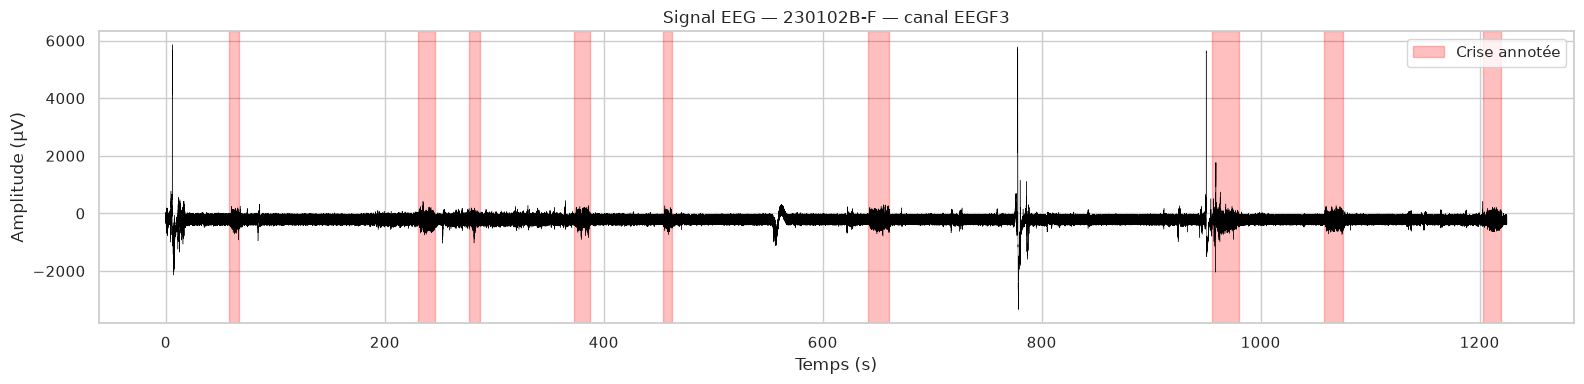

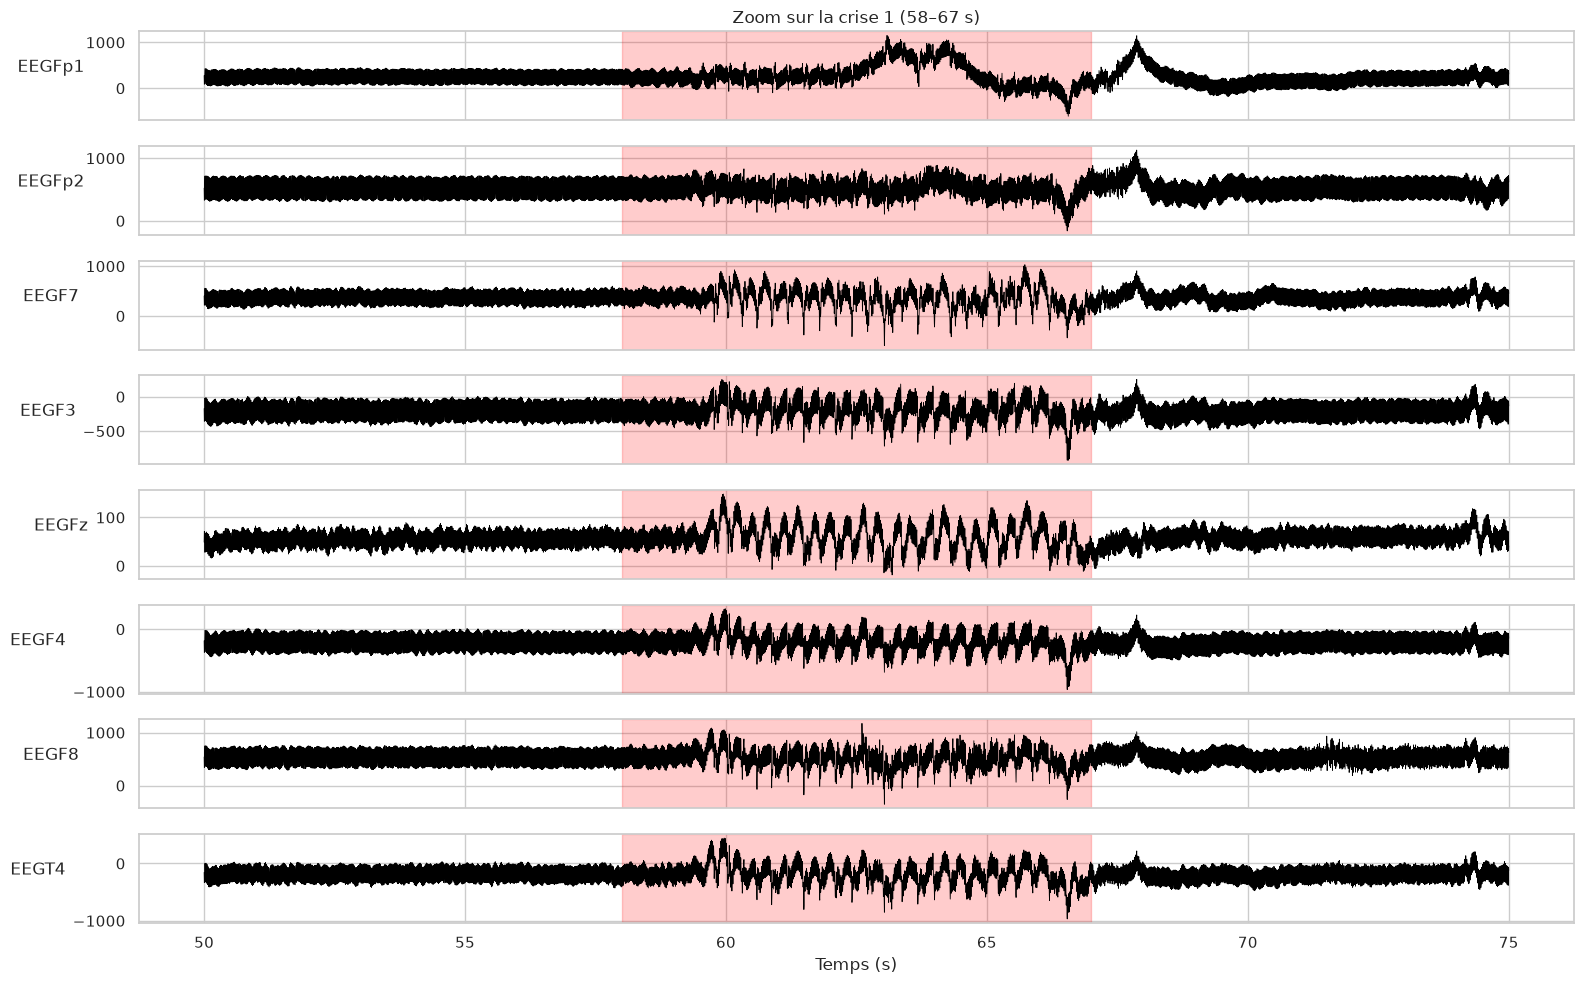

In [7]:
# Question 2 : signal en fonction du temps, crises annotées en rouge
def shade(ax, intervals, color="red", alpha=0.25, label=None):
    for i, (s, e) in enumerate(intervals):
        ax.axvspan(s, e, color=color, alpha=alpha, label=label if i == 0 else None)

CH_PLOT = "EEGF3" if "EEGF3" in EEG_CHANNELS else EEG_CHANNELS[0]
sz_demo = seizure_table(REC_DEMO)
ivals = list(zip(sz_demo["Début (s)"], sz_demo["Fin (s)"]))

fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(eeg["Time"], eeg[CH_PLOT], lw=0.3, color="black")
shade(ax, ivals, label="Crise annotée")
ax.set(title=f"Signal EEG — {REC_DEMO} — canal {CH_PLOT}", xlabel="Temps (s)", ylabel="Amplitude (µV)")
ax.legend(loc="upper right"); plt.tight_layout(); plt.show()

# Zoom sur la première crise, plusieurs canaux
s0, e0 = ivals[0]
win = (eeg["Time"] >= s0 - 8) & (eeg["Time"] <= e0 + 8)
chans = EEG_CHANNELS[:8]
fig, axes = plt.subplots(len(chans), 1, figsize=(16, 10), sharex=True)
for ax, ch in zip(axes, chans):
    ax.plot(eeg.loc[win, "Time"], eeg.loc[win, ch], lw=0.6, color="black")
    ax.axvspan(s0, e0, color="red", alpha=0.2)
    ax.set_ylabel(ch, rotation=0, labelpad=25)
axes[0].set_title(f"Zoom sur la crise 1 ({s0:.0f}–{e0:.0f} s)")
axes[-1].set_xlabel("Temps (s)"); plt.tight_layout(); plt.show()

**Observation :** pendant les crises, l'amplitude augmente fortement et le signal devient **rythmique et synchrone sur tous les canaux** : des complexes **pointe-onde** réguliers autour de **3 Hz**, typiques des absences. En dehors des crises, le signal est plus irrégulier et de plus faible amplitude.

## Partie II — Exploitation des annotations

### Question 3 — Début, fin et nombre de crises

In [8]:
sz_demo = seizure_table(REC_DEMO)
print(f"{REC_DEMO} : {len(sz_demo)} crises")
sz_demo

230102B-F : 9 crises


,Crise,Début (s),Fin (s),Durée (s)
0,1,58.0,67.0,9.0
1,2,230.0,246.0,16.0
2,3,277.0,287.0,10.0
3,4,373.0,387.0,14.0
4,5,454.0,462.0,8.0
5,6,641.0,661.0,20.0
6,7,956.0,980.0,24.0
7,8,1058.0,1075.0,17.0
8,9,1203.0,1220.0,17.0


In [9]:
# Même tableau pour tous les enregistrements annotés
print("Nombre total de crises retenues :", len(SEIZURES))
SEIZURES.groupby("ID").agg(Nb_crises=("Crise", "count"),
                           Durée_tot_s=("Durée (s)", "sum")).sort_values("Nb_crises", ascending=False)

Nombre total de crises retenues : 82


,Nb_crises,Durée_tot_s
ID,,
210504B-C,11,127.0
210914B-A,11,176.0
230102B-F,9,135.0
211027B-C,8,123.0
230105B-H,7,38.0
230718A-A,7,67.0
211104B-D,5,40.0
230406B-A,4,44.0
230224B-B,3,46.0


### Question 4 — Statistiques sur les crises

--- 230102B-F ---


,Valeur
Nb crises,9.00
Durée moyenne (s),15.00
Durée min (s),8.00
Durée max (s),24.00
Écart-type durée (s),5.32
Intervalle moyen (s),128.38


--- Tous les enregistrements ---


,Nb crises,Durée moyenne (s),Durée min (s),Durée max (s),Écart-type durée (s),Intervalle moyen (s)
ID,,,,,,
190304A-E,1.0,7.00,7.0,7.0,NaN,NaN
191113A-D,2.0,9.00,5.0,13.0,5.66,161.00
210406A-F,1.0,8.00,8.0,8.0,NaN,NaN
210427B-C,1.0,18.00,18.0,18.0,NaN,NaN
210504B-C,11.0,11.55,2.0,60.0,16.72,160.10
210914B-A,11.0,16.00,4.0,49.0,15.71,84.80
210928B-B,2.0,27.50,25.0,30.0,3.54,108.00
211027B-C,8.0,15.38,8.0,47.0,13.17,130.29
211104B-D,5.0,8.00,6.0,10.0,1.41,152.75


,Global
Nb crises,82.00
Durée moyenne (s),13.32
Durée min (s),2.00
Durée max (s),60.00
Intervalle moyen (s),220.39


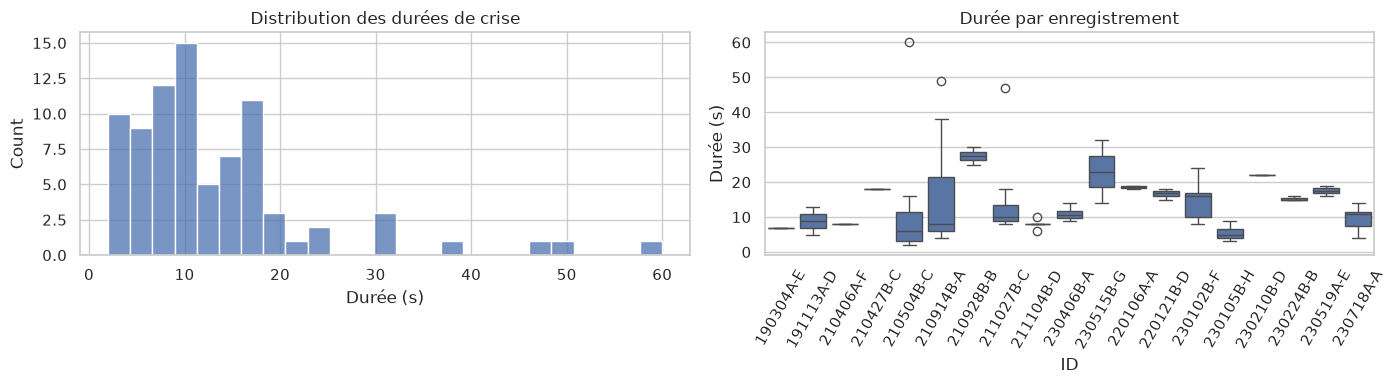

In [10]:
def seizure_stats(t):
    t = t.sort_values("Début (s)")
    gaps = (t["Début (s)"].values[1:] - t["Fin (s)"].values[:-1]) if len(t) > 1 else np.array([])
    return pd.Series({"Nb crises": len(t),
                      "Durée moyenne (s)": t["Durée (s)"].mean(),
                      "Durée min (s)": t["Durée (s)"].min(),
                      "Durée max (s)": t["Durée (s)"].max(),
                      "Écart-type durée (s)": t["Durée (s)"].std(),
                      "Intervalle moyen (s)": gaps.mean() if gaps.size else np.nan})

print(f"--- {REC_DEMO} ---")
display(seizure_stats(sz_demo).round(2).to_frame("Valeur"))

print("--- Tous les enregistrements ---")
per_rec = SEIZURES.groupby("ID").apply(seizure_stats).round(2)
display(per_rec)
glob_stats = pd.Series({"Nb crises": len(SEIZURES), "Durée moyenne (s)": SEIZURES["Durée (s)"].mean(),
                        "Durée min (s)": SEIZURES["Durée (s)"].min(), "Durée max (s)": SEIZURES["Durée (s)"].max(),
                        "Intervalle moyen (s)": per_rec["Intervalle moyen (s)"].mean()})
display(glob_stats.round(2).to_frame("Global"))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(SEIZURES["Durée (s)"], bins=25, ax=ax[0]).set(title="Distribution des durées de crise", xlabel="Durée (s)")
sns.boxplot(data=SEIZURES, x="ID", y="Durée (s)", ax=ax[1]).set(title="Durée par enregistrement")
ax[1].tick_params(axis="x", rotation=60); plt.tight_layout(); plt.show()

**Les crises ont-elles toutes une durée similaire ?** Non : les durées varient de quelques secondes à près d'une minute, avec une forte variabilité **entre** patients et aussi **chez un même patient**. La majorité des crises durent entre 5 et 20 s.

## Partie III — Construction de la variable cible

### Question 5 — Colonne `Class`

In [11]:
def add_class(df, rec):
    t = df["Time"].values
    cls = np.zeros(len(df), dtype=np.int8)
    for s, e in SEIZURES.loc[SEIZURES["ID"] == rec, ["Début (s)", "Fin (s)"]].values:
        cls[(t >= s) & (t <= e)] = 1
    df["Class"] = cls
    return df

eeg = add_class(eeg, REC_DEMO)
eeg["Class"].value_counts()

Class
0    279031
1     34569
Name: count, dtype: int64

### Question 6 — Visualisation des deux classes et déséquilibre

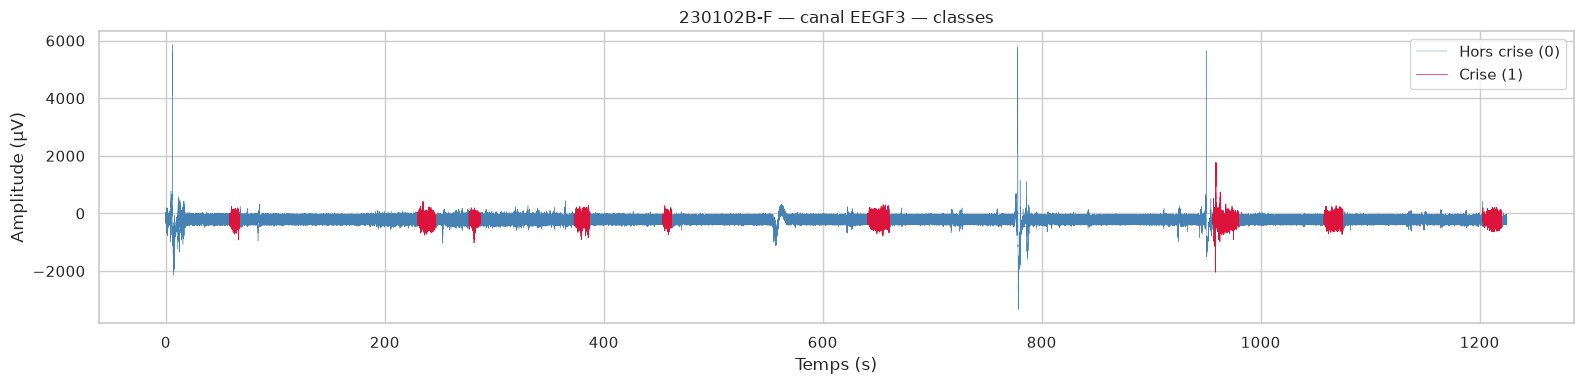

230102B-F : classe 0 = 88.98 %  |  classe 1 = 11.02 %
Global (19 enregistrements annotés) : crises = 3.76 % du temps enregistré


In [12]:
fig, ax = plt.subplots(figsize=(16, 4))
sig = eeg[CH_PLOT].values
ax.plot(eeg["Time"], np.where(eeg["Class"] == 0, sig, np.nan), lw=0.3, color="steelblue", label="Hors crise (0)")
ax.plot(eeg["Time"], np.where(eeg["Class"] == 1, sig, np.nan), lw=0.5, color="crimson", label="Crise (1)")
ax.set(title=f"{REC_DEMO} — canal {CH_PLOT} — classes", xlabel="Temps (s)", ylabel="Amplitude (µV)")
ax.legend(loc="upper right"); plt.tight_layout(); plt.show()

pct = eeg["Class"].value_counts(normalize=True).mul(100).round(2)
print(f"{REC_DEMO} : classe 0 = {pct.get(0, 0)} %  |  classe 1 = {pct.get(1, 0)} %")

# Déséquilibre global sur tous les enregistrements annotés
annotated = summary[summary["Enregistrement"].isin(SEIZURES["ID"])]
sz_time = SEIZURES[SEIZURES["ID"].isin(annotated["Enregistrement"])]["Durée (s)"].sum()
print(f"Global ({len(annotated)} enregistrements annotés) : crises = {100 * sz_time / annotated['Durée (s)'].sum():.2f} % du temps enregistré")

**Le déséquilibre est-il important ?** Oui : les crises ne représentent que quelques pourcents des échantillons. Un modèle naïf qui prédit toujours « pas de crise » aurait une très bonne accuracy sans rien détecter. On en tient compte avec `class_weight="balanced"`, une séparation **stratifiée** et des métriques adaptées (recall, F1).

## Partie IV — Segmentation du signal

### Question 7

- Prétraitement : filtre passe-bande **0,5–40 Hz** (Butterworth ordre 4, sans déphasage) pour retirer la dérive de la ligne de base et le bruit haute fréquence.
- Fenêtres de **2 s** (512 échantillons à 256 Hz) avec **50 % de recouvrement** (pas de 1 s).
- Une fenêtre est de classe 1 si **au moins 50 %** de ses échantillons sont en crise.

In [13]:
WIN_S, OVERLAP = 2.0, 0.5
BANDS = {"Delta": (0.5, 4), "Theta": (4, 8), "Alpha": (8, 13), "Beta": (13, 30)}

def bandpass(x, fs, lo=0.5, hi=40, order=4):
    sos = butter(order, [lo, hi], btype="band", fs=fs, output="sos")
    return sosfiltfilt(sos, x, axis=0)

def segment(df, fs, win_s=WIN_S, overlap=OVERLAP):
    # Retourne les indices de début de fenêtre, la taille, et la classe de chaque fenêtre
    n_win_samp = int(round(win_s * fs))
    step = int(round(n_win_samp * (1 - overlap)))
    n = len(df)
    starts = np.arange(0, n - n_win_samp + 1, step)
    cum = np.concatenate([[0], np.cumsum(df["Class"].values)])
    frac = (cum[starts + n_win_samp] - cum[starts]) / n_win_samp
    return starts, n_win_samp, (frac >= 0.5).astype(int), frac

starts, n_win_samp, win_class, win_frac = segment(eeg, FS)
print(f"Taille de fenêtre : {n_win_samp} échantillons ({WIN_S} s), pas : {starts[1]-starts[0]} échantillons")
print(f"Nombre de fenêtres : {len(starts)}  |  classe 0 : {(win_class == 0).sum()}  |  classe 1 : {(win_class == 1).sum()}")

Taille de fenêtre : 512 échantillons (2.0 s), pas : 256 échantillons
Nombre de fenêtres : 1224  |  classe 0 : 1080  |  classe 1 : 144


## Partie V et VI — Extraction des caractéristiques (temporelles + fréquentielles)

Pour chaque fenêtre et chaque canal EEG, on calcule les caractéristiques, puis on fait la **moyenne sur les 19 canaux** (une crise d'absence est généralisée, elle touche tous les canaux).

- **Temporelles** : moyenne, écart-type, variance, min, max, amplitude, RMS, énergie.
- **Fréquentielles (FFT)** : puissance Delta, Theta, Alpha, Beta, puissances **relatives**, **fréquence dominante** (≈ 3 Hz pendant une absence).

In [14]:
from numpy.lib.stride_tricks import sliding_window_view

def extract_features(df, fs, channels, rec):
    starts, n_win_samp, win_class, win_frac = segment(df, fs)
    step = starts[1] - starts[0]
    X = df[channels].values.astype(np.float64)
    X = bandpass(X - np.median(X, axis=0), fs)                        # (n_samples, n_ch), offset retiré puis filtré
    hann = np.hanning(n_win_samp)
    freqs = np.fft.rfftfreq(n_win_samp, 1 / fs)
    df_hz = freqs[1] - freqs[0]
    band_idx = {b: (freqs >= lo) & (freqs < hi) for b, (lo, hi) in BANDS.items()}
    total_idx = (freqs >= 0.5) & (freqs < 30)

    acc = {}
    for j in range(X.shape[1]):                                        # canal par canal (mémoire)
        w = sliding_window_view(X[:, j], n_win_samp)[::step][:len(starts)]   # (n_win, n_win_samp)
        feats = {
            "Mean": w.mean(1), "Std": w.std(1), "Variance": w.var(1),
            "Min": w.min(1), "Max": w.max(1),
        }
        feats["Amplitude"] = feats["Max"] - feats["Min"]
        feats["RMS"] = np.sqrt((w ** 2).mean(1))
        feats["Energy"] = (w ** 2).sum(1)
        psd = np.abs(np.fft.rfft((w - w.mean(1, keepdims=True)) * hann, axis=1)) ** 2 / (fs * (hann ** 2).sum())
        total = psd[:, total_idx].sum(1) * df_hz
        for b, idx in band_idx.items():
            feats[f"P_{b}"] = psd[:, idx].sum(1) * df_hz
            feats[f"Rel_{b}"] = feats[f"P_{b}"] / (total + 1e-12)
        feats["Peak_Freq"] = freqs[total_idx][psd[:, total_idx].argmax(1)]
        for k, v in feats.items():
            acc.setdefault(k, []).append(v)

    out = pd.DataFrame({k: np.mean(v, axis=0) for k, v in acc.items()})
    out.insert(0, "t_end", (starts + n_win_samp) / fs)
    out.insert(0, "t_start", starts / fs)
    out.insert(0, "Window", np.arange(1, len(starts) + 1))
    out.insert(0, "Recording", rec)
    out["Seizure_frac"] = win_frac
    out["Class"] = win_class
    return out

feat_demo = extract_features(eeg, FS, EEG_CHANNELS, REC_DEMO)
feat_demo.head()

,Recording,Window,t_start,t_end,Mean,Std,Variance,Min,Max,Amplitude,RMS,Energy,P_Delta,Rel_Delta,P_Theta,Rel_Theta,P_Alpha,Rel_Alpha,P_Beta,Rel_Beta,Peak_Freq,Seizure_frac,Class
0,230102B-F,1,0.0,2.0,-19.330766,304.852786,5.099776e+05,-707.341197,612.208078,1319.549275,305.716970,2.614001e+08,290549.502784,0.755626,79396.332528,0.176964,34771.521582,0.048474,14471.666858,0.018935,1.605263,0.0,0
1,230102B-F,2,1.0,3.0,23.555887,181.270176,1.031783e+05,-429.363507,510.120459,939.483966,183.791465,5.609847e+07,19441.431227,0.920660,527.480474,0.065443,158.880030,0.010098,49.811416,0.003799,2.394737,0.0,0
2,230102B-F,3,2.0,4.0,-24.315319,117.328750,7.021868e+04,-375.153043,273.091508,648.244551,120.052000,3.832408e+07,7600.814578,0.735216,1110.854542,0.214794,305.040486,0.034883,264.530644,0.015108,0.526316,0.0,0
3,230102B-F,4,3.0,5.0,36.959583,369.839757,3.776084e+05,-888.346527,1047.673755,1936.020281,372.470268,1.940393e+08,151429.381130,0.906604,25590.409745,0.081592,6621.171318,0.009634,3609.633931,0.002169,1.210526,0.0,0
4,230102B-F,5,4.0,6.0,113.424688,1276.370026,1.703159e+06,-1242.702463,4649.229443,5891.931907,1281.420841,8.787574e+08,221136.721413,0.953381,13805.805377,0.031892,4501.431573,0.010960,1669.828175,0.003766,0.526316,0.0,0


### Question 8 — Construction du dataset complet (tous les enregistrements annotés)

In [15]:
FEATURES_CSV = OUT_DIR / "features_windows.csv"

frames = []
for f in DATA_FILES:
    rec = recording_id(f)
    if rec not in set(SEIZURES["ID"]):
        continue
    d, fs = load_eeg(f)
    chans = [c for c in d.columns if c.startswith("EEG")]
    d = add_class(d, rec)
    frames.append(extract_features(d, fs, chans, rec))
    print(f"{rec}: {len(frames[-1])} fenêtres, {frames[-1]['Class'].sum()} en crise")
    del d

dataset = pd.concat(frames, ignore_index=True)
dataset.to_csv(FEATURES_CSV, index=False)

print("\nNombre total de fenêtres :", len(dataset))
print("Fenêtres classe 0       :", (dataset["Class"] == 0).sum())
print("Fenêtres classe 1       :", (dataset["Class"] == 1).sum(),
      f"({100 * dataset['Class'].mean():.2f} %)")
print("Dataset sauvegardé dans :", FEATURES_CSV)
dataset.head()

190304A-E: 1574 fenêtres, 8 en crise


191113A-D: 1809 fenêtres, 20 en crise


210406A-F: 1453 fenêtres, 9 en crise


210427B-C: 1245 fenêtres, 19 en crise


210504B-C: 3120 fenêtres, 138 en crise


210914B-A: 1204 fenêtres, 187 en crise


... (11 outputs left out)

230519A-E: 1215 fenêtres, 37 en crise


230718A-A: 1205 fenêtres, 74 en crise



Nombre total de fenêtres : 28994
Fenêtres classe 0       : 27820
Fenêtres classe 1       : 1174 (4.05 %)
Dataset sauvegardé dans : resultats_local/features_windows.csv


,Recording,Window,t_start,t_end,Mean,Std,Variance,Min,Max,Amplitude,RMS,Energy,P_Delta,Rel_Delta,P_Theta,Rel_Theta,P_Alpha,Rel_Alpha,P_Beta,Rel_Beta,Peak_Freq,Seizure_frac,Class
0,190304A-E,1,0.0,2.0,-0.505455,14.947595,280.270954,-71.374776,47.366508,118.741284,14.962571,143964.587507,77.520121,0.503160,16.238060,0.188821,9.412402,0.172234,8.224109,0.135785,1.763158,0.0,0
1,190304A-E,2,1.0,3.0,-0.000431,20.628366,476.422142,-71.759858,57.754914,129.514772,20.639551,244239.875035,54.022989,0.213564,35.746348,0.179087,81.394365,0.412561,38.901728,0.194787,7.263158,0.0,0
2,190304A-E,3,2.0,4.0,0.378373,19.862059,427.881238,-49.581974,53.875593,103.457567,19.881903,219387.473800,38.811663,0.259766,26.816931,0.156268,69.501271,0.403426,26.954335,0.180540,5.921053,0.0,0
3,190304A-E,4,3.0,5.0,-0.138495,24.918787,677.735661,-63.126073,70.943268,134.069340,24.929745,347304.597353,32.235461,0.102494,34.126260,0.133301,270.373892,0.622148,44.284376,0.142058,8.447368,0.0,0
4,190304A-E,5,4.0,6.0,0.795787,27.722296,834.994497,-64.426203,92.004140,156.430343,27.739789,428078.310781,53.966120,0.133810,58.833536,0.147162,192.464422,0.485364,91.716037,0.233663,8.842105,0.0,0


In [16]:
# Format demandé par l'énoncé
cols_enonce = ["Window", "Mean", "Std", "Variance", "Min", "Max", "RMS", "Energy", "Class"]
dataset[dataset["Recording"] == REC_DEMO][cols_enonce].head(10)

,Window,Mean,Std,Variance,Min,Max,RMS,Energy,Class
16722,1,-19.330766,304.852786,5.099776e+05,-707.341197,612.208078,305.716970,2.614001e+08,0
16723,2,23.555887,181.270176,1.031783e+05,-429.363507,510.120459,183.791465,5.609847e+07,0
16724,3,-24.315319,117.328750,7.021868e+04,-375.153043,273.091508,120.052000,3.832408e+07,0
16725,4,36.959583,369.839757,3.776084e+05,-888.346527,1047.673755,372.470268,1.940393e+08,0
16726,5,113.424688,1276.370026,1.703159e+06,-1242.702463,4649.229443,1281.420841,8.787574e+08,0
16727,6,-100.348919,1497.234811,2.293095e+06,-1689.719829,4997.183695,1500.997586,1.179649e+09,0
16728,7,-70.495928,1001.994736,1.412548e+06,-1761.242429,4847.901303,1005.280395,7.261151e+08,0
16729,8,65.377511,476.021205,1.181267e+06,-1294.177079,1154.182644,485.209264,6.071772e+08,0
16730,9,-19.813518,347.991563,9.868423e+05,-1296.839422,553.467619,349.876749,5.055377e+08,0
16731,10,2.217163,271.181528,5.185242e+05,-1066.392779,390.706007,272.291476,2.666605e+08,0


### Question 9 — Domaine temporel vs domaine fréquentiel

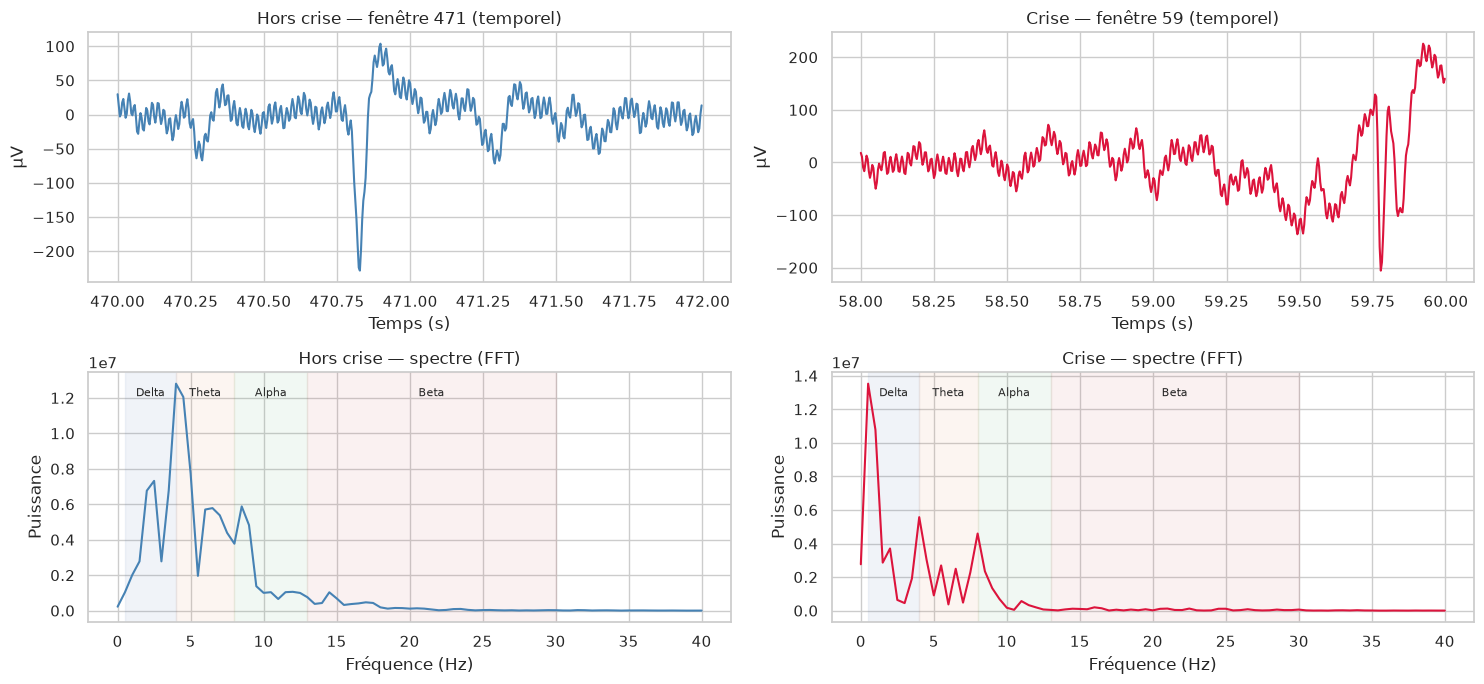

In [17]:
d_demo = feat_demo
i_sz = int(d_demo.loc[d_demo["Seizure_frac"] == 1, "Window"].iloc[0]) - 1 if (d_demo["Seizure_frac"] == 1).any() else int(d_demo["Class"].idxmax())
i_ok = int(d_demo.loc[d_demo["Class"] == 0, "Window"].iloc[len(d_demo) // 3]) - 1

x_raw = eeg[[CH_PLOT]].values.astype(float)
x_f = bandpass(x_raw - np.median(x_raw), FS)[:, 0]
fig, axes = plt.subplots(2, 2, figsize=(15, 7))
for col, (i, name, color) in enumerate([(i_ok, "Hors crise", "steelblue"), (i_sz, "Crise", "crimson")]):
    s = starts[i]
    seg = x_f[s:s + n_win_samp]
    t = np.arange(n_win_samp) / FS + s / FS
    axes[0, col].plot(t, seg, color=color)
    axes[0, col].set(title=f"{name} — fenêtre {i+1} (temporel)", xlabel="Temps (s)", ylabel="µV")
    spec = np.abs(np.fft.rfft(seg * np.hanning(n_win_samp))) ** 2
    fr = np.fft.rfftfreq(n_win_samp, 1 / FS)
    m = fr <= 40
    axes[1, col].plot(fr[m], spec[m], color=color)
    for b, (lo, hi) in BANDS.items():
        axes[1, col].axvspan(lo, hi, alpha=0.08, color=f"C{list(BANDS).index(b)}")
        axes[1, col].text((lo + hi) / 2, axes[1, col].get_ylim()[1] * 0.9 if spec[m].max() else 0, b, ha="center", fontsize=8)
    axes[1, col].set(title=f"{name} — spectre (FFT)", xlabel="Fréquence (Hz)", ylabel="Puissance")
plt.tight_layout(); plt.show()

Pendant une crise, le spectre présente un **pic net autour de 3 Hz** (bande Delta/Theta) avec une puissance bien supérieure à celle d'une fenêtre normale.

## Partie VII — Analyse exploratoire des caractéristiques

### Question 10 — Comparaison des deux classes

In [18]:
FEATURES = [c for c in dataset.columns if c not in ("Recording", "Window", "t_start", "t_end", "Seizure_frac", "Class")]

cmp = dataset.groupby("Class")[FEATURES].mean().T
cmp.columns = ["Classe 0 (moyenne)", "Classe 1 (moyenne)"]
cmp["Rapport 1/0"] = cmp.iloc[:, 1] / cmp.iloc[:, 0].replace(0, np.nan)
cmp.round(3)

,Classe 0 (moyenne),Classe 1 (moyenne),Rapport 1/0
Mean,-0.001,-3.200000e-02,60.829
Std,36.991,1.281540e+02,3.464
Variance,10540.015,2.712935e+04,2.574
Min,-91.693,-3.129950e+02,3.414
Max,92.527,2.817480e+02,3.045
Amplitude,184.220,5.947430e+02,3.228
RMS,37.185,1.283900e+02,3.453
Energy,5451727.890,1.393951e+07,2.557
P_Delta,4746.702,1.092732e+04,2.302
Rel_Delta,0.639,6.930000e-01,1.085


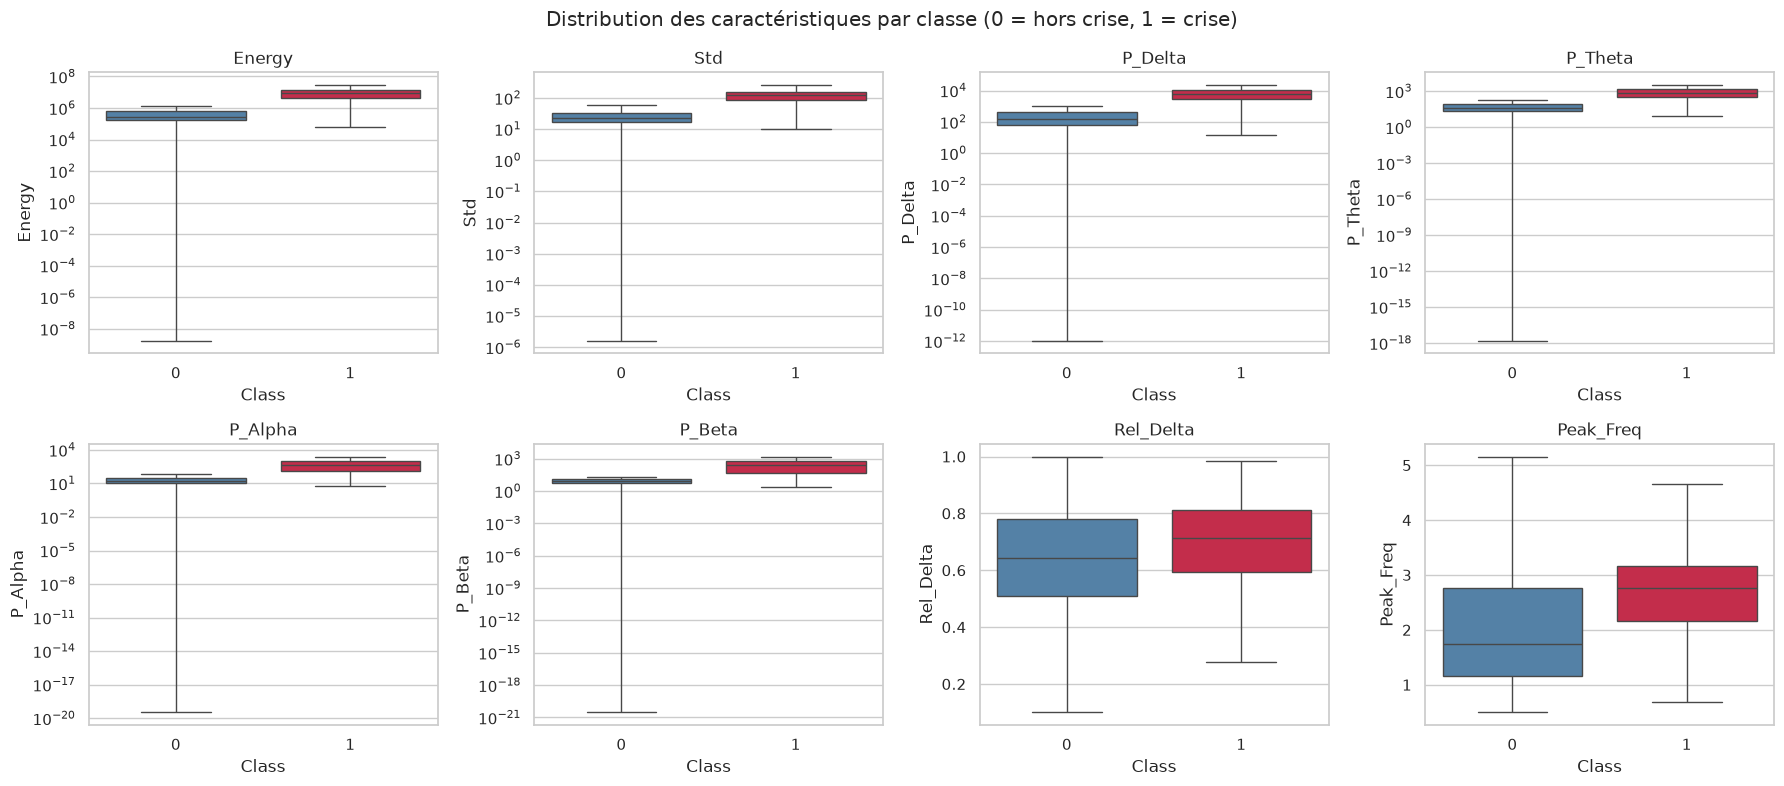

In [19]:
show = ["Energy", "Std", "P_Delta", "P_Theta", "P_Alpha", "P_Beta", "Rel_Delta", "Peak_Freq"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, f in zip(axes.ravel(), show):
    sns.boxplot(data=dataset, x="Class", y=f, ax=ax, showfliers=False, palette=["steelblue", "crimson"])
    if dataset[f].min() > 0 and f not in ("Peak_Freq",) and not f.startswith("Rel_"):
        ax.set_yscale("log")
    ax.set_title(f)
plt.suptitle("Distribution des caractéristiques par classe (0 = hors crise, 1 = crise)")
plt.tight_layout(); plt.show()

### Question 11 — Matrice de corrélation

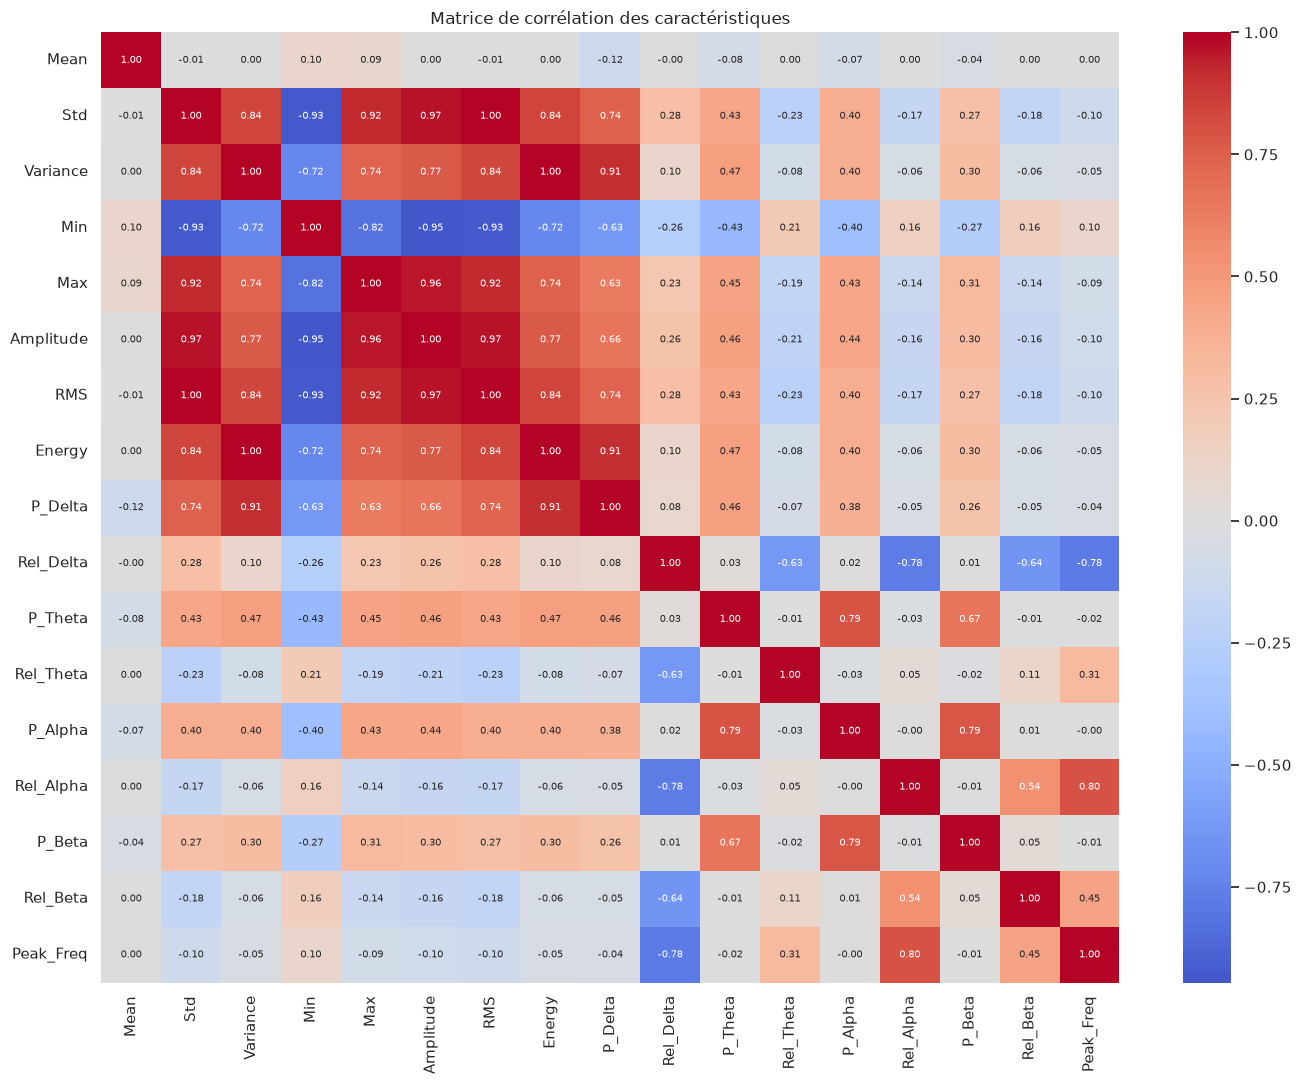

Paires les plus corrélées (|r| > 0.9) :


,Feature 1,Feature 2,corr
41,Variance,Energy,0.999965
23,Std,RMS,0.999965
91,Amplitude,RMS,0.968854
22,Std,Amplitude,0.968827
73,Max,Amplitude,0.960051
56,Min,Amplitude,-0.946424
57,Min,RMS,-0.928636
20,Std,Min,-0.928606
74,Max,RMS,0.920020
21,Std,Max,0.919998


In [20]:
corr = dataset[FEATURES].corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Matrice de corrélation des caractéristiques"); plt.tight_layout(); plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, bool), k=1)).stack()
             .rename("corr").reset_index().rename(columns={"level_0": "Feature 1", "level_1": "Feature 2"}))
print("Paires les plus corrélées (|r| > 0.9) :")
pairs[pairs["corr"].abs() > 0.9].sort_values("corr", key=abs, ascending=False)

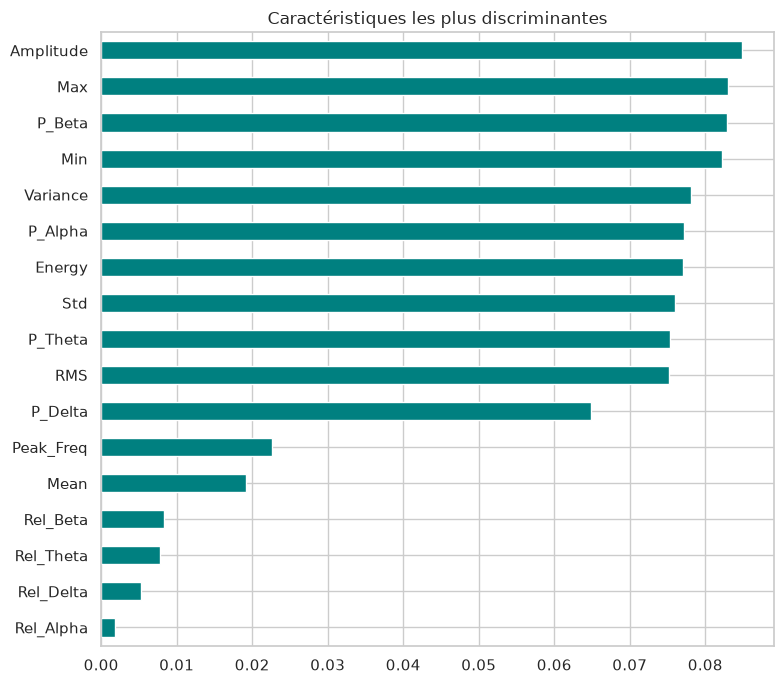

,Info. mutuelle,|d de Cohen|
Amplitude,0.085,1.146
Max,0.083,0.955
P_Beta,0.083,0.309
Min,0.082,1.244
Variance,0.078,0.149
P_Alpha,0.077,0.421
Energy,0.077,0.148
Std,0.076,1.160
P_Theta,0.075,0.169
RMS,0.075,1.157


In [21]:
# Pouvoir discriminant : information mutuelle + taille d'effet (d de Cohen)
from sklearn.feature_selection import mutual_info_classif

y_all = dataset["Class"].values
mi = mutual_info_classif(dataset[FEATURES], y_all, random_state=0)
g0, g1 = dataset[y_all == 0][FEATURES], dataset[y_all == 1][FEATURES]
cohen_d = (g1.mean() - g0.mean()) / np.sqrt((g0.var() + g1.var()) / 2)
disc = pd.DataFrame({"Info. mutuelle": mi, "|d de Cohen|": cohen_d.abs()}, index=FEATURES).sort_values("Info. mutuelle", ascending=False)

disc["Info. mutuelle"].plot.barh(figsize=(8, 7), color="teal").invert_yaxis()
plt.title("Caractéristiques les plus discriminantes"); plt.tight_layout(); plt.show()
disc.round(3)

**Réponses :**
1. **Fortement corrélées** : Std, Variance, RMS, Énergie et Amplitude (elles mesurent toutes la « taille » du signal), ainsi que Min/Max entre elles et les puissances de bandes avec l'énergie.
2. **Redondance** : oui. Variance = Std², Énergie ∝ RMS², Amplitude = Max − Min. Garder une seule de ces variables apporterait presque la même information.
3. **Les plus discriminantes** : voir le classement ci-dessus (typiquement l'énergie/la puissance Delta-Theta et la fréquence dominante). La moyenne de la fenêtre est peu discriminante (le signal filtré est centré).

## Partie VIII — Construction des modèles

Séparation **80 % / 20 % stratifiée**. Chaque modèle est un `Pipeline` (standardisation + classifieur) pour éviter toute fuite d'information du jeu de test. Les classes déséquilibrées sont compensées par `class_weight`.

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

X = dataset[FEATURES].values
y = dataset["Class"].values
idx = np.arange(len(dataset))
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, idx, test_size=0.2, stratify=y, random_state=42)
print(f"Train : {len(y_train)} fenêtres ({100*y_train.mean():.2f} % crise)")
print(f"Test  : {len(y_test)} fenêtres ({100*y_test.mean():.2f} % crise)")

Train : 23195 fenêtres (4.05 % crise)
Test  : 5799 fenêtres (4.05 % crise)


### Question 12 — Entraînement des modèles

In [23]:
MODELS = {
    "Decision Tree": make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=10, min_samples_leaf=5,
                                                                            class_weight="balanced", random_state=42)),
    "Random Forest": make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                                                            class_weight="balanced_subsample",
                                                                            n_jobs=-1, random_state=42)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7, weights="distance")),
    "SVM": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale", class_weight="balanced")),
}

fitted, preds = {}, {}
for name, model in MODELS.items():
    model.fit(X_train, y_train)
    fitted[name] = model
    preds[name] = model.predict(X_test)
    print(f"{name} entraîné")

Decision Tree entraîné


Random Forest entraîné
KNN entraîné


SVM entraîné


## Partie IX — Évaluation des modèles

In [24]:
def scores(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1-score": f1_score(y_true, y_pred, zero_division=0)}

results = pd.DataFrame({name: scores(y_test, p) for name, p in preds.items()}).T
results.index.name = "Modèle"
results.round(4)

,Accuracy,Precision,Recall,F1-score
Modèle,,,,
Decision Tree,0.9460,0.4156,0.8170,0.5509
Random Forest,0.9829,0.8301,0.7277,0.7755
KNN,0.9788,0.7917,0.6468,0.7119
SVM,0.9507,0.4449,0.8766,0.5903


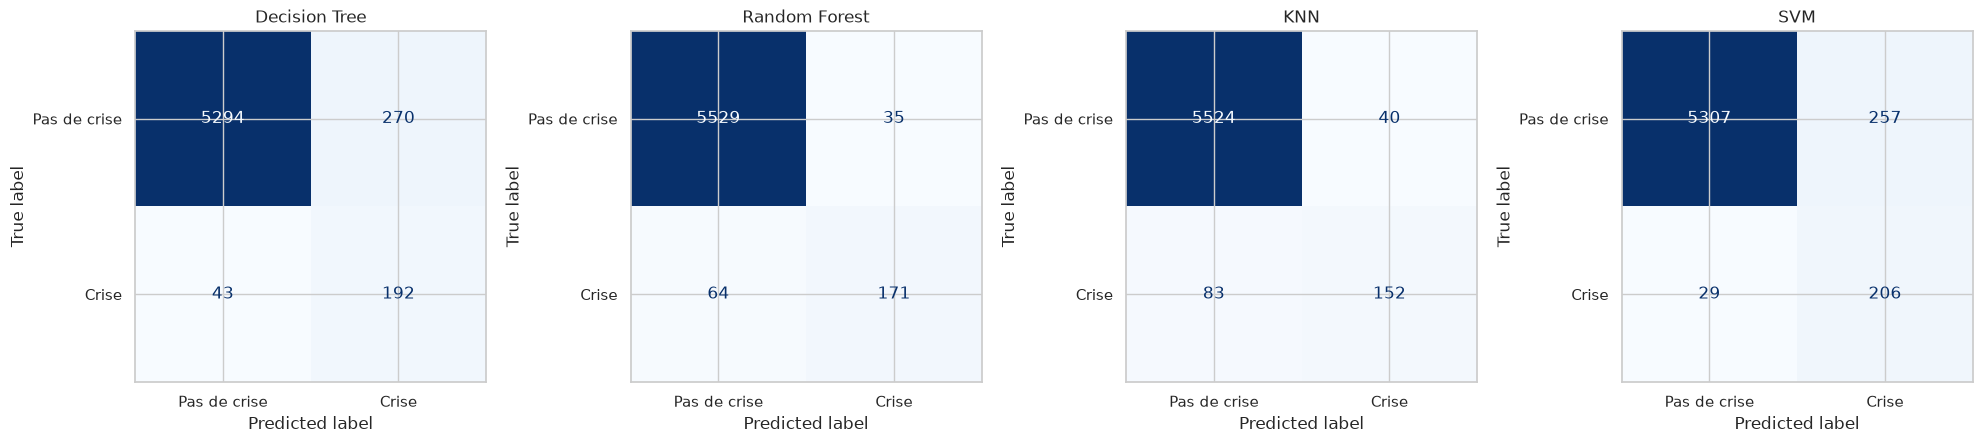

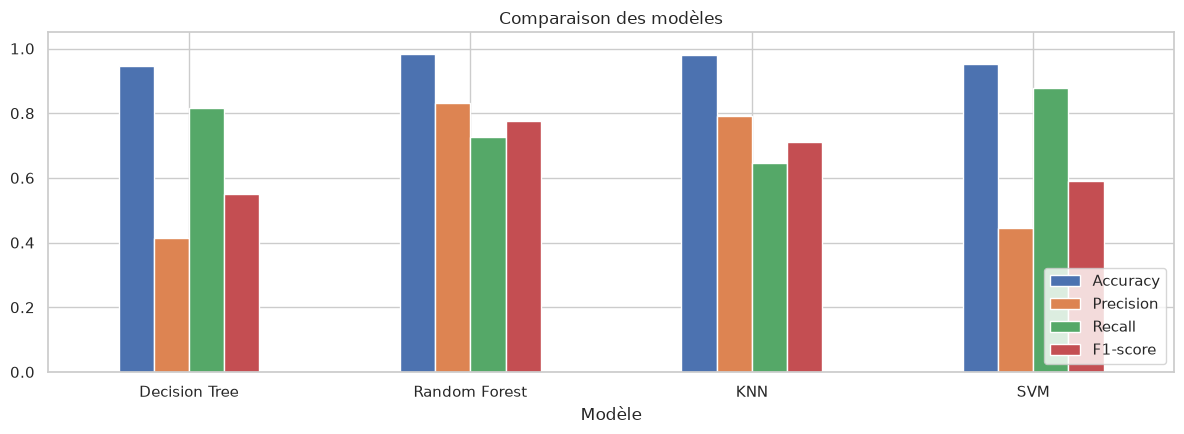

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=["Pas de crise", "Crise"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name)
plt.tight_layout(); plt.show()

results.plot.bar(figsize=(12, 4.5), rot=0, ylim=(0, 1.05))
plt.title("Comparaison des modèles"); plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

## Question 13 — Quelle métrique privilégier ?

Démonstration avec un modèle « naïf » qui prédit **toujours** « pas de crise » :

In [26]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pd.DataFrame({"Toujours 'pas de crise'": scores(y_test, dummy.predict(X_test))}).T.round(4)

,Accuracy,Precision,Recall,F1-score
Toujours 'pas de crise',0.9595,0.0,0.0,0.0


Ce modèle obtient une **accuracy très élevée** alors qu'il ne détecte **aucune crise** (recall = 0). L'accuracy est dominée par la classe majoritaire et ne reflète pas la capacité à détecter les crises.

- **Recall (sensibilité)** : proportion des crises réellement détectées. En médical, **rater une crise (faux négatif) est l'erreur la plus grave** → c'est la métrique prioritaire.
- **Precision** : proportion des alarmes qui sont de vraies crises. Importante pour éviter trop de fausses alarmes.
- **F1-score** : compromis entre les deux, adapté aux classes déséquilibrées → c'est le critère retenu pour choisir le meilleur modèle, en vérifiant que le recall reste élevé.

In [27]:
BEST = results["F1-score"].idxmax()
print("Meilleur modèle (F1) :", BEST)
print(classification_report(y_test, preds[BEST], target_names=["Pas de crise", "Crise"], digits=3))

Meilleur modèle (F1) : Random Forest
              precision    recall  f1-score   support

Pas de crise      0.989     0.994     0.991      5564
       Crise      0.830     0.728     0.776       235

    accuracy                          0.983      5799
   macro avg      0.909     0.861     0.883      5799
weighted avg      0.982     0.983     0.982      5799



### Évaluation complémentaire : validation par enregistrement

Avec un découpage aléatoire, deux fenêtres voisines (qui se chevauchent à 50 %) peuvent se retrouver l'une en train, l'autre en test, ce qui rend les scores **optimistes**. Une évaluation plus réaliste consiste à tester sur des **enregistrements jamais vus** (`GroupKFold`).

In [28]:
from sklearn.model_selection import GroupKFold

groups = dataset["Recording"].values
n_splits = min(5, len(np.unique(groups)))
if n_splits >= 2:
    rows = []
    for name in [BEST]:
        y_pred_cv = np.zeros_like(y)
        for tr, te in GroupKFold(n_splits=n_splits).split(X, y, groups):
            m = clone(MODELS[name]).fit(X[tr], y[tr])
            y_pred_cv[te] = m.predict(X[te])
        rows.append(pd.Series(scores(y, y_pred_cv), name=f"{name} (par enregistrement)"))
    display(pd.concat([results.loc[[BEST]], pd.DataFrame(rows)]).round(4))
else:
    print("Un seul enregistrement : validation par enregistrement impossible.")

,Accuracy,Precision,Recall,F1-score
Random Forest,0.9829,0.8301,0.7277,0.7755
Random Forest (par enregistrement),0.9771,0.7431,0.6652,0.7020


## Partie X — Détection temporelle des crises

### Question 14

On prend un enregistrement de démonstration. Pour éviter toute fuite, le meilleur modèle est **ré-entraîné sur tous les autres enregistrements**, puis appliqué à toutes les fenêtres de celui-ci.

Post-traitement : lissage des prédictions (filtre médian sur 3 fenêtres), puis fusion des fenêtres consécutives positives en intervalles.

In [29]:
MIN_EVENT_S = 2.0   # on ignore les détections plus courtes
MERGE_GAP_S = 1.0   # on fusionne deux détections séparées de moins de 1 s

def windows_to_intervals(t_start, t_end, pred, min_len=MIN_EVENT_S, gap=MERGE_GAP_S):
    events, cur = [], None
    for s, e, p in zip(t_start, t_end, pred):
        if p:
            cur = [s, e] if cur is None else [cur[0], e]
        elif cur is not None:
            events.append(cur); cur = None
    if cur is not None:
        events.append(cur)
    merged = []
    for ev in events:
        if merged and ev[0] - merged[-1][1] <= gap:
            merged[-1][1] = max(merged[-1][1], ev[1])
        else:
            merged.append(ev)
    return [(s, e) for s, e in merged if e - s >= min_len]


def detect(rec, model_name=BEST, smooth=3):
    d_rec = dataset[dataset["Recording"] == rec].sort_values("t_start")
    others = dataset[dataset["Recording"] != rec]
    if others["Class"].nunique() == 2:
        model = clone(MODELS[model_name]).fit(others[FEATURES].values, others["Class"].values)
    else:  # un seul enregistrement disponible : on réutilise le modèle de la partie IX
        model = fitted[model_name]
    raw = model.predict(d_rec[FEATURES].values)
    sm = medfilt(raw, smooth).astype(int) if smooth > 1 else raw
    ev = windows_to_intervals(d_rec["t_start"].values, d_rec["t_end"].values, sm)
    return d_rec, raw, sm, ev


def match_events(true_iv, pred_iv):
    rows, used = [], set()
    for k, (ts, te) in enumerate(true_iv, 1):
        hit = [j for j, (ps, pe) in enumerate(pred_iv) if ps < te and pe > ts]
        if hit:
            used.update(hit)
            ps, pe = pred_iv[hit[0]][0], pred_iv[hit[-1]][1]
            rows.append({"Crise réelle": k, "Début réel": ts, "Fin réelle": te, "Début détecté": ps,
                         "Fin détectée": pe, "Retard début (s)": round(ps - ts, 1), "Écart fin (s)": round(pe - te, 1),
                         "Résultat": "Détectée"})
        else:
            rows.append({"Crise réelle": k, "Début réel": ts, "Fin réelle": te, "Résultat": "Manquée"})
    for j, (ps, pe) in enumerate(pred_iv):
        if j not in used:
            rows.append({"Début détecté": ps, "Fin détectée": pe, "Résultat": "Fausse alarme"})
    return pd.DataFrame(rows)


d_rec, raw_pred, sm_pred, events = detect(REC_DEMO)
true_iv = list(zip(sz_demo["Début (s)"], sz_demo["Fin (s)"]))
for k, (s, e) in enumerate(events, 1):
    print(f"Crise détectée {k} : {s:.1f} s → {e:.1f} s")
match = match_events(true_iv, events)
match

Crise détectée 1 : 15.0 s → 18.0 s
Crise détectée 2 : 58.0 s → 68.0 s
Crise détectée 3 : 230.0 s → 247.0 s
Crise détectée 4 : 275.0 s → 284.0 s
Crise détectée 5 : 338.0 s → 342.0 s
Crise détectée 6 : 373.0 s → 387.0 s
Crise détectée 7 : 454.0 s → 463.0 s
Crise détectée 8 : 642.0 s → 661.0 s
Crise détectée 9 : 964.0 s → 975.0 s
Crise détectée 10 : 1058.0 s → 1077.0 s
Crise détectée 11 : 1206.0 s → 1220.0 s


,Crise réelle,Début réel,Fin réelle,Début détecté,Fin détectée,Retard début (s),Écart fin (s),Résultat
0,1.0,58.0,67.0,58.0,68.0,0.0,1.0,Détectée
1,2.0,230.0,246.0,230.0,247.0,0.0,1.0,Détectée
2,3.0,277.0,287.0,275.0,284.0,-2.0,-3.0,Détectée
3,4.0,373.0,387.0,373.0,387.0,0.0,0.0,Détectée
4,5.0,454.0,462.0,454.0,463.0,0.0,1.0,Détectée
5,6.0,641.0,661.0,642.0,661.0,1.0,0.0,Détectée
6,7.0,956.0,980.0,964.0,975.0,8.0,-5.0,Détectée
7,8.0,1058.0,1075.0,1058.0,1077.0,0.0,2.0,Détectée
8,9.0,1203.0,1220.0,1206.0,1220.0,3.0,0.0,Détectée
9,NaN,NaN,NaN,15.0,18.0,NaN,NaN,Fausse alarme


Crises détectées : 9/9 (sensibilité événementielle = 100%)
Fausses alarmes  : 2 (5.9 par heure)


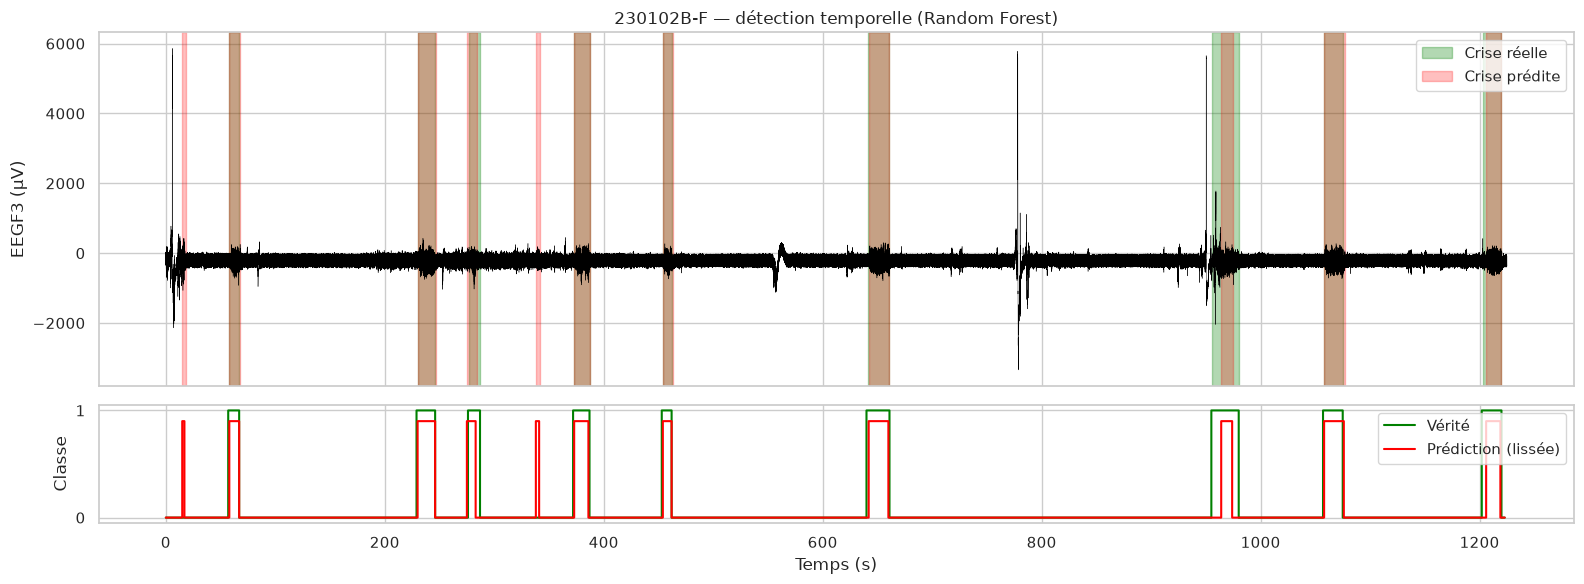

In [30]:
n_true, n_det = len(true_iv), (match["Résultat"] == "Détectée").sum()
n_fa = (match["Résultat"] == "Fausse alarme").sum()
dur_h = eeg["Time"].iloc[-1] / 3600
print(f"Crises détectées : {n_det}/{n_true} (sensibilité événementielle = {n_det / max(n_true, 1):.0%})")
print(f"Fausses alarmes  : {n_fa} ({n_fa / dur_h:.1f} par heure)")

fig, axes = plt.subplots(2, 1, figsize=(16, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
axes[0].plot(eeg["Time"], eeg[CH_PLOT], lw=0.3, color="black")
shade(axes[0], true_iv, color="green", alpha=0.3, label="Crise réelle")
shade(axes[0], events, color="red", alpha=0.25, label="Crise prédite")
axes[0].set(title=f"{REC_DEMO} — détection temporelle ({BEST})", ylabel=f"{CH_PLOT} (µV)")
axes[0].legend(loc="upper right")
axes[1].step(d_rec["t_start"], d_rec["Class"], where="post", color="green", label="Vérité")
axes[1].step(d_rec["t_start"], sm_pred * 0.9, where="post", color="red", label="Prédiction (lissée)")
axes[1].set(xlabel="Temps (s)", yticks=[0, 1], ylabel="Classe"); axes[1].legend(loc="upper right")
plt.tight_layout(); plt.show()

In [31]:
# Détection sur tous les enregistrements (chacun prédit par un modèle qui ne l'a jamais vu)
all_rows = []
for rec in dataset["Recording"].unique():
    _, _, _, ev = detect(rec)
    t = seizure_table(rec)
    m = match_events(list(zip(t["Début (s)"], t["Fin (s)"])), ev)
    all_rows.append({"Enregistrement": rec, "Crises réelles": len(t),
                     "Détectées": (m["Résultat"] == "Détectée").sum(),
                     "Manquées": (m["Résultat"] == "Manquée").sum(),
                     "Fausses alarmes": (m["Résultat"] == "Fausse alarme").sum()})
event_summary = pd.DataFrame(all_rows)
tot = event_summary[["Crises réelles", "Détectées", "Manquées", "Fausses alarmes"]].sum()
print(f"Sensibilité globale : {tot['Détectées'] / tot['Crises réelles']:.1%} — fausses alarmes : {tot['Fausses alarmes']}")
event_summary

Sensibilité globale : 97.6% — fausses alarmes : 25


,Enregistrement,Crises réelles,Détectées,Manquées,Fausses alarmes
0,190304A-E,1,1,0,0
1,191113A-D,2,0,2,0
2,210406A-F,1,1,0,0
3,210427B-C,1,1,0,5
4,210504B-C,11,11,0,7
5,210914B-A,11,11,0,2
6,210928B-B,2,2,0,0
7,211027B-C,8,8,0,2
8,211104B-D,5,5,0,2
9,220106A-A,2,2,0,0


## Comparaison étendue des modèles

Les quatre modèles des parties VIII et IX sont comparés ici à sept autres, plus le modèle naïf de la Question 13, soit **12 modèles** (4 + 1 + 7). Les conditions sont strictement les mêmes que plus haut : mêmes caractéristiques (`FEATURES`), même séparation 80 % / 20 % stratifiée (`random_state=42`), même fonction `scores()`.

- Chaque modèle sensible à l'échelle est dans un `Pipeline` avec `StandardScaler`.
- Le déséquilibre des classes est compensé quand le modèle le permet : `class_weight="balanced"` (régression logistique, Extra Trees, HistGradientBoosting, LightGBM) ou `scale_pos_weight` (XGBoost). `GaussianNB` et `MLPClassifier` n'ont pas d'option équivalente.
- Hyperparamètres par défaut raisonnables, sans recherche par grille, et `random_state=42` partout.

Les cellules précédentes ne sont pas modifiées : `MODELS`, `results` et `BEST` gardent leur contenu.

In [32]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

T0_ETENDU = time.perf_counter()          # pour mesurer la durée de toute la section

# Poids de la classe « crise » pour XGBoost : nombre de négatifs / nombre de positifs (calculé sur le train)
POIDS_CRISE = float((y_train == 0).sum() / (y_train == 1).sum())

NOUVEAUX = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced",
                                                                              random_state=42)),
    "Gaussian NB": make_pipeline(StandardScaler(), GaussianNB()),
    "Extra Trees": make_pipeline(StandardScaler(), ExtraTreesClassifier(n_estimators=300, min_samples_leaf=2,
                                                                        class_weight="balanced_subsample",
                                                                        n_jobs=-1, random_state=42)),
    "HistGradientBoosting": make_pipeline(StandardScaler(), HistGradientBoostingClassifier(class_weight="balanced",
                                                                                           random_state=42)),
    "XGBoost": make_pipeline(StandardScaler(), XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                                                             scale_pos_weight=POIDS_CRISE, tree_method="hist",
                                                             n_jobs=-1, random_state=42)),
    "LightGBM": make_pipeline(StandardScaler(), LGBMClassifier(n_estimators=300, learning_rate=0.1,
                                                               class_weight="balanced", n_jobs=-1,
                                                               random_state=42, verbose=-1)),
    "MLP": make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True,
                                                         max_iter=500, random_state=42)),
}

# Les 12 modèles : les 4 d'origine (copiés, non modifiés), le modèle naïf et les 7 nouveaux
MODELS_TOUS = {name: clone(m) for name, m in MODELS.items()}
MODELS_TOUS["Dummy (toujours 0)"] = DummyClassifier(strategy="most_frequent")
MODELS_TOUS.update(NOUVEAUX)
print(f"{len(MODELS_TOUS)} modèles :", ", ".join(MODELS_TOUS))
print(f"scale_pos_weight (XGBoost) = {POIDS_CRISE:.1f}")

12 modèles : Decision Tree, Random Forest, KNN, SVM, Dummy (toujours 0), Logistic Regression, Gaussian NB, Extra Trees, HistGradientBoosting, XGBoost, LightGBM, MLP
scale_pos_weight (XGBoost) = 23.7


### Séparation aléatoire 80 / 20

In [33]:
lignes, preds_tous = [], {}
for name, model in MODELS_TOUS.items():
    t0 = time.perf_counter()
    m = clone(model).fit(X_train, y_train)
    duree = time.perf_counter() - t0
    preds_tous[name] = m.predict(X_test)
    lignes.append({"Modèle": name, **scores(y_test, preds_tous[name]), "Entraînement (s)": duree})

results_tous = pd.DataFrame(lignes).set_index("Modèle")
results_tous.sort_values("F1-score", ascending=False).round({"Accuracy": 4, "Precision": 4, "Recall": 4,
                                                            "F1-score": 4, "Entraînement (s)": 2})

,Accuracy,Precision,Recall,F1-score,Entraînement (s)
Modèle,,,,,
Random Forest,0.9829,0.8301,0.7277,0.7755,2.51
Extra Trees,0.9814,0.7679,0.7745,0.7712,0.78
LightGBM,0.9800,0.7390,0.7830,0.7603,1.76
XGBoost,0.9786,0.7048,0.8128,0.7549,6.77
MLP,0.9793,0.7511,0.7319,0.7414,2.35
KNN,0.9788,0.7917,0.6468,0.7119,0.01
HistGradientBoosting,0.9612,0.5124,0.8766,0.6468,9.18
SVM,0.9507,0.4449,0.8766,0.5903,3.18
Decision Tree,0.9460,0.4156,0.8170,0.5509,0.25


### Validation par enregistrement (GroupKFold, 5 plis)

C'est le score honnête : les fenêtres d'un même enregistrement ne sont jamais à la fois dans l'apprentissage et dans le test. Même procédure que l'évaluation complémentaire de la partie IX, appliquée aux 12 modèles.

In [34]:
lignes = []
for name, model in MODELS_TOUS.items():
    t0 = time.perf_counter()
    y_cv = np.zeros_like(y)
    for tr, te in GroupKFold(n_splits=n_splits).split(X, y, groups):
        y_cv[te] = clone(model).fit(X[tr], y[tr]).predict(X[te])
    s = scores(y, y_cv)
    lignes.append({"Modèle": name, "Precision (patients)": s["Precision"], "Recall (patients)": s["Recall"],
                   "F1 (patients)": s["F1-score"]})
    print(f"{name:<22} F1 par enregistrement = {s['F1-score']:.4f}   ({time.perf_counter() - t0:.0f} s)")

results_patients = pd.DataFrame(lignes).set_index("Modèle")

# Tableau complet : séparation aléatoire + validation par enregistrement
comparaison_modeles = results_tous.join(results_patients)
comparaison_modeles["Écart F1 (aléatoire − patients)"] = comparaison_modeles["F1-score"] - comparaison_modeles["F1 (patients)"]
comparaison_modeles = comparaison_modeles.sort_values("F1 (patients)", ascending=False)
comparaison_modeles.round(4).round({"Entraînement (s)": 2})

Decision Tree          F1 par enregistrement = 0.5122   (1 s)


Random Forest          F1 par enregistrement = 0.7020   (14 s)


KNN                    F1 par enregistrement = 0.6651   (1 s)


SVM                    F1 par enregistrement = 0.5383   (18 s)
Dummy (toujours 0)     F1 par enregistrement = 0.0000   (0 s)


Logistic Regression    F1 par enregistrement = 0.4007   (0 s)
Gaussian NB            F1 par enregistrement = 0.4265   (0 s)


Extra Trees            F1 par enregistrement = 0.7288   (4 s)


HistGradientBoosting   F1 par enregistrement = 0.6336   (25 s)


XGBoost                F1 par enregistrement = 0.6992   (22 s)


LightGBM               F1 par enregistrement = 0.7006   (21 s)


MLP                    F1 par enregistrement = 0.6852   (16 s)


,Accuracy,Precision,Recall,F1-score,Entraînement (s),Precision (patients),Recall (patients),F1 (patients),Écart F1 (aléatoire − patients)
Modèle,,,,,,,,,
Extra Trees,0.9814,0.7679,0.7745,0.7712,0.78,0.7153,0.7428,0.7288,0.0424
Random Forest,0.9829,0.8301,0.7277,0.7755,2.51,0.7431,0.6652,0.7020,0.0735
LightGBM,0.9800,0.7390,0.7830,0.7603,1.76,0.6714,0.7325,0.7006,0.0597
XGBoost,0.9786,0.7048,0.8128,0.7549,6.77,0.6538,0.7513,0.6992,0.0558
MLP,0.9793,0.7511,0.7319,0.7414,2.35,0.7354,0.6414,0.6852,0.0562
KNN,0.9788,0.7917,0.6468,0.7119,0.01,0.7401,0.6039,0.6651,0.0468
HistGradientBoosting,0.9612,0.5124,0.8766,0.6468,9.18,0.5056,0.8484,0.6336,0.0132
SVM,0.9507,0.4449,0.8766,0.5903,3.18,0.3908,0.8646,0.5383,0.0519
Decision Tree,0.9460,0.4156,0.8170,0.5509,0.25,0.3736,0.8143,0.5122,0.0387


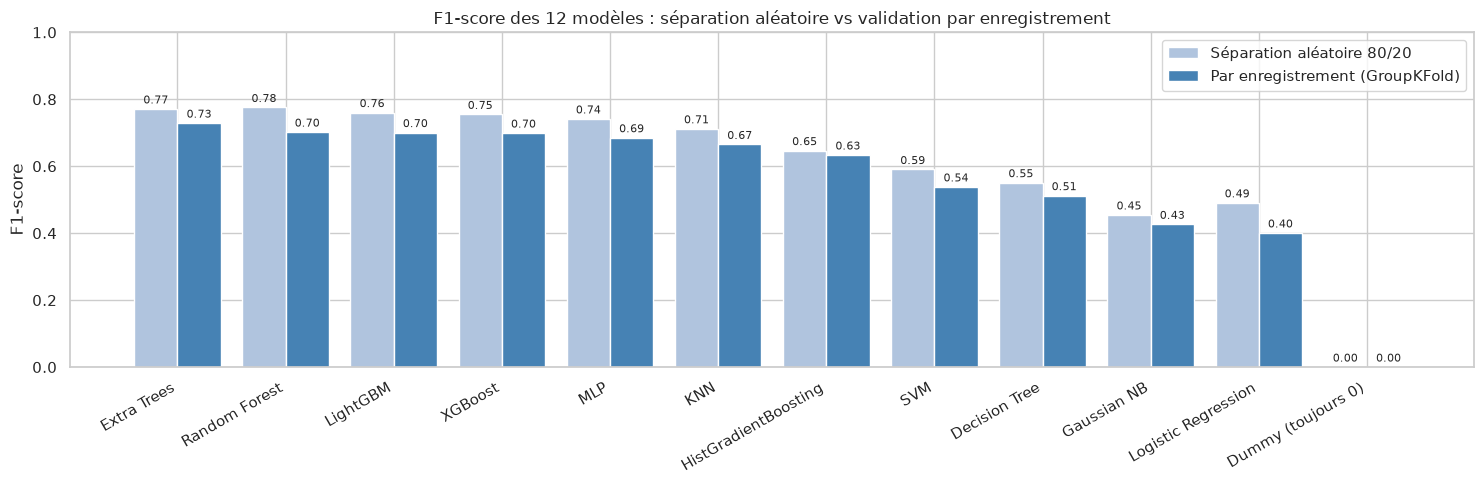

In [35]:
# Une figure : F1 sur la séparation aléatoire et F1 par enregistrement, pour tous les modèles
fig, ax = plt.subplots(figsize=(15, 5))
pos = np.arange(len(comparaison_modeles))
b1 = ax.bar(pos - 0.2, comparaison_modeles["F1-score"], 0.4, color="lightsteelblue", label="Séparation aléatoire 80/20")
b2 = ax.bar(pos + 0.2, comparaison_modeles["F1 (patients)"], 0.4, color="steelblue", label="Par enregistrement (GroupKFold)")
for barres in (b1, b2):
    ax.bar_label(barres, fmt="%.2f", fontsize=8, padding=2)
ax.set_xticks(pos)
ax.set_xticklabels(comparaison_modeles.index, rotation=30, ha="right")
ax.set(ylabel="F1-score", ylim=(0, 1), title=f"F1-score des {len(comparaison_modeles)} modèles : séparation aléatoire vs validation par enregistrement")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

### Détection par crise pour les deux meilleurs modèles

Les deux modèles qui ont le meilleur F1 par enregistrement passent la même épreuve que `detect()` : chaque enregistrement est prédit par un modèle ré-entraîné sur les 18 autres, puis lissage médian sur 3 fenêtres, fusion des détections séparées de moins de 1 s et durée minimale de 2 s.

In [36]:
def detect_modele(model, rec, smooth=3):
    # Même logique que detect(), avec un modèle passé en argument
    d_rec = dataset[dataset["Recording"] == rec].sort_values("t_start")
    others = dataset[dataset["Recording"] != rec]
    m = clone(model).fit(others[FEATURES].values, others["Class"].values)
    raw = m.predict(d_rec[FEATURES].values)
    sm = medfilt(raw, smooth).astype(int) if smooth > 1 else raw
    return windows_to_intervals(d_rec["t_start"].values, d_rec["t_end"].values, sm)


RECS = list(dataset["Recording"].unique())
DUREE_H = sum(dur[r] for r in RECS) / 3600                   # durée cumulée des enregistrements (h)
MEILLEURS = list(comparaison_modeles.index[:2])              # 2 meilleurs F1 par enregistrement
print("Modèles retenus :", " et ".join(MEILLEURS))

lignes = []
for name in MEILLEURS:
    t0 = time.perf_counter()
    n_reel = n_det = n_miss = n_fa = 0
    for rec in RECS:
        t = seizure_table(rec)
        m = match_events(list(zip(t["Début (s)"], t["Fin (s)"])), detect_modele(MODELS_TOUS[name], rec))
        n_reel += len(t)
        n_det += int((m["Résultat"] == "Détectée").sum())
        n_miss += int((m["Résultat"] == "Manquée").sum())
        n_fa += int((m["Résultat"] == "Fausse alarme").sum())
    lignes.append({"Modèle": name, "Crises réelles": n_reel, "Crises détectées": n_det, "Crises manquées": n_miss,
                   "Sensibilité crises": n_det / max(n_reel, 1),
                   "Fausses alarmes": n_fa, "Fausses alarmes / h": n_fa / DUREE_H})
    print(f"{name} : détection sur {len(RECS)} enregistrements en {time.perf_counter() - t0:.0f} s")

detection_meilleurs = pd.DataFrame(lignes).set_index("Modèle")
print(f"Durée cumulée des enregistrements : {DUREE_H:.2f} h")
detection_meilleurs.round({"Sensibilité crises": 4, "Fausses alarmes / h": 2})

Modèles retenus : Extra Trees et Random Forest


Extra Trees : détection sur 19 enregistrements en 20 s


Random Forest : détection sur 19 enregistrements en 42 s
Durée cumulée des enregistrements : 8.06 h


,Crises réelles,Crises détectées,Crises manquées,Sensibilité crises,Fausses alarmes,Fausses alarmes / h
Modèle,,,,,,
Extra Trees,82,81,1,0.9878,41,5.09
Random Forest,82,80,2,0.9756,25,3.10


In [37]:
# Sauvegarde des nouveaux tableaux
comparaison_modeles.to_csv(OUT_DIR / "comparaison_etendue_modeles.csv")
detection_meilleurs.to_csv(OUT_DIR / "comparaison_etendue_detection.csv")
print("Tableaux sauvegardés dans", OUT_DIR)
print(f"Durée d'exécution de la section : {time.perf_counter() - T0_ETENDU:.0f} s")

Tableaux sauvegardés dans resultats_local
Durée d'exécution de la section : 214 s


### Interprétation

**Sur la séparation aléatoire, le Random Forest reste premier.** Il obtient un F1 de 0,7755, devant Extra Trees (0,7712), LightGBM (0,7603), XGBoost (0,7549) et le MLP (0,7414). Les modèles simples sont loin derrière : la régression logistique (0,4908) et le Gaussian NB (0,4545) retrouvent beaucoup de fenêtres de crise (rappel de 0,85 et 0,83) mais avec une précision de 0,34 et 0,31, donc énormément de fausses alertes. Leur accuracy (0,9284 et 0,9193) est même inférieure à celle du modèle naïf (0,9595), qui ne détecte pourtant rien (F1 = 0) : une nouvelle illustration que l'accuracy ne dit rien ici.

**Le score par enregistrement est plus bas pour tous les modèles.** Dès que les fenêtres d'un même patient ne sont plus partagées entre apprentissage et test, chaque modèle perd du F1 : de 0,013 (HistGradientBoosting) à 0,090 (régression logistique), et 0,074 pour le Random Forest (0,7755 → 0,7020). La séparation aléatoire est donc optimiste, et elle l'est inégalement : le classement change. **Extra Trees passe en tête** avec un F1 de 0,7288 (il ne perd que 0,042), devant le Random Forest (0,7020), LightGBM (0,7006) et XGBoost (0,6992), puis le MLP (0,6852) et le KNN (0,6651).

**Pourquoi Extra Trees ?** Par enregistrement, il gagne surtout en rappel (0,7428 contre 0,6652 pour le Random Forest) en cédant un peu de précision (0,7153 contre 0,7431). Ses coupures tirées au hasard le rendent moins dépendant des valeurs exactes vues à l'apprentissage, ce qui est cohérent avec sa plus faible perte sur des patients jamais vus — c'est une explication plausible, pas une preuve. Le boosting (XGBoost, LightGBM) n'apporte rien de plus que le Random Forest avec ces 17 caractéristiques, et HistGradientBoosting pondéré bascule vers le rappel (0,8484) au prix d'une précision de 0,5056.

**Au niveau crise, le gain est moins net.** Avec la même procédure que `detect()`, Extra Trees retrouve 81 crises sur 82 (98,8 %, 1 manquée) contre 80 sur 82 pour le Random Forest (97,6 %, 2 manquées). Mais il déclenche 41 fausses alarmes contre 25, soit 5,09 par heure contre 3,10 sur les 8,06 h d'enregistrement : une crise de plus pour 16 fausses alarmes de plus.

**Conclusion.** Extra Trees est le meilleur modèle selon le F1 par enregistrement (+0,027 par rapport au Random Forest) et il manque une crise de moins, mais il produit plus de fausses alarmes : il ne domine pas le Random Forest sur tous les critères. Le choix dépend de la priorité — ne manquer aucune crise, ou limiter les alertes à vérifier. Avec 19 enregistrements et 82 crises, un écart d'une seule crise reste fragile ; il faudrait davantage de patients pour trancher. Le Random Forest reste le modèle de référence du reste du notebook (`BEST` n'est pas modifié).

## Partie XI — Analyse des erreurs du meilleur modèle

In [38]:
cm = confusion_matrix(y_test, preds[BEST])
tn, fp, fn, tp = cm.ravel()
print(f"Vrais positifs  (crise détectée)          : {tp}")
print(f"Vrais négatifs  (normal reconnu)          : {tn}")
print(f"Faux positifs   (fausse alarme)           : {fp}")
print(f"Faux négatifs   (crise manquée)           : {fn}")

err = dataset.iloc[idx_test].copy()
err["Pred"] = preds[BEST]
err["Type"] = np.select([(err.Class == 1) & (err.Pred == 1), (err.Class == 0) & (err.Pred == 0),
                         (err.Class == 0) & (err.Pred == 1)], ["VP", "VN", "FP"], "FN")

# Les erreurs sont-elles aux frontières des crises ? (fenêtres partiellement en crise)
err["Bordure"] = (err["Seizure_frac"] > 0) & (err["Seizure_frac"] < 1)
display(err.groupby("Type")["Bordure"].mean().mul(100).round(1).to_frame("% fenêtres en bordure de crise"))
display(err.groupby("Recording")["Type"].value_counts().unstack(fill_value=0))

Vrais positifs  (crise détectée)          : 171
Vrais négatifs  (normal reconnu)          : 5529
Faux positifs   (fausse alarme)           : 35
Faux négatifs   (crise manquée)           : 64


,% fenêtres en bordure de crise
Type,
FN,42.2
FP,2.9
VN,0.2
VP,5.8


Type,FN,FP,VN,VP
Recording,,,,
190304A-E,0,0,306,0
191113A-D,2,0,353,2
210406A-F,1,0,283,1
210427B-C,1,9,249,3
210504B-C,13,5,551,14
210914B-A,15,2,181,18
210928B-B,4,0,270,12
211027B-C,4,7,238,28
211104B-D,3,1,224,5


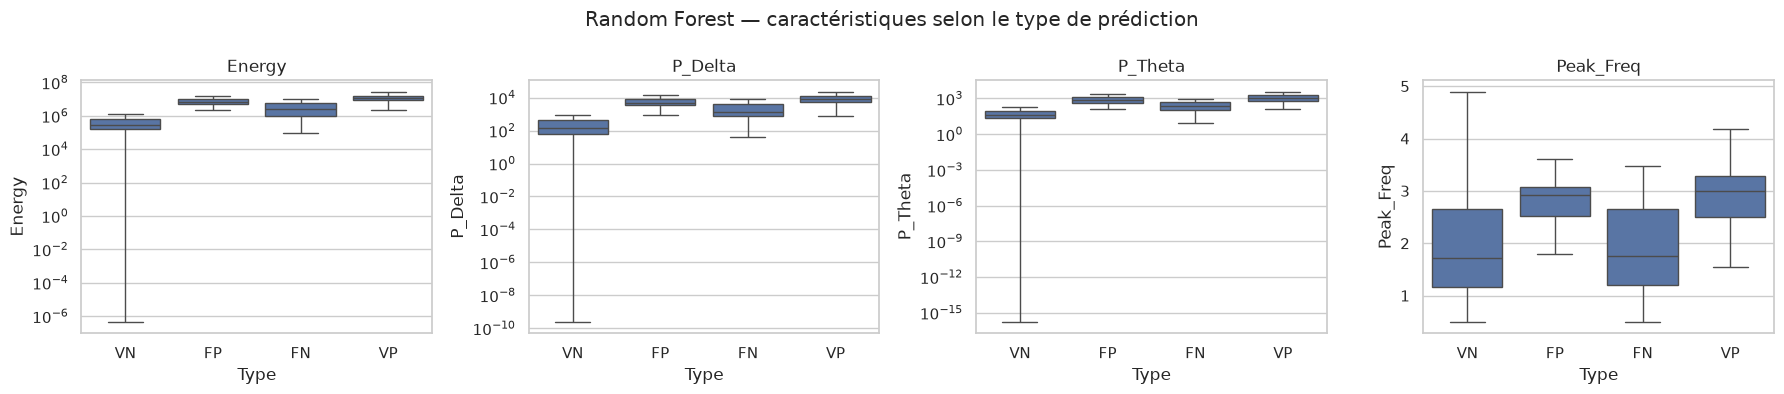

In [39]:
# Comparaison des caractéristiques par type de prédiction
key = ["Energy", "P_Delta", "P_Theta", "Peak_Freq"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
order = ["VN", "FP", "FN", "VP"]
for ax, f in zip(axes, key):
    sns.boxplot(data=err, x="Type", y=f, order=[o for o in order if o in err.Type.unique()], ax=ax, showfliers=False)
    if f != "Peak_Freq":
        ax.set_yscale("log")
    ax.set_title(f)
plt.suptitle(f"{BEST} — caractéristiques selon le type de prédiction"); plt.tight_layout(); plt.show()

**Interprétation :**
- Les **faux négatifs** sont surtout des fenêtres **en bordure** de crise (début/fin) ou des crises de faible amplitude, que le modèle confond avec l'activité normale.
- Les **faux positifs** correspondent souvent à des artefacts (mouvements, clignements des yeux → forte énergie basse fréquence) qui ressemblent à une crise en énergie et en puissance Delta.
- Les **vrais positifs** ont une énergie et une puissance Delta/Theta très élevées et une fréquence dominante proche de 3 Hz.

## Partie XII — Amélioration du système

Deux améliorations testées :
1. **Ajustement du seuil de décision** (Random Forest donne une probabilité) : choisir le seuil qui maximise le F1 sur une partie validation du train, au lieu de 0,5.
2. **Lissage temporel** des prédictions (une crise dure plusieurs secondes : une fenêtre isolée positive est souvent une erreur).

In [40]:
from sklearn.metrics import precision_recall_curve

# 1) Seuil optimal, choisi sur une validation interne (jamais sur le test)
X_tr2, X_val, y_tr2, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=1)
rf = clone(MODELS["Random Forest"]).fit(X_tr2, y_tr2)
p_val = rf.predict_proba(X_val)[:, 1]
prec, rec_, thr = precision_recall_curve(y_val, p_val)
f1s = 2 * prec[:-1] * rec_[:-1] / (prec[:-1] + rec_[:-1] + 1e-12)
best_thr = thr[f1s.argmax()]
rf_full = clone(MODELS["Random Forest"]).fit(X_train, y_train)
p_test = rf_full.predict_proba(X_test)[:, 1]

# 2) Lissage temporel : appliqué par enregistrement dans l'ordre chronologique
def smooth_by_recording(pred_series):
    out = pred_series.copy()
    for rec, g in dataset.loc[pred_series.index].groupby("Recording"):
        order = g.sort_values("t_start").index
        out.loc[order] = medfilt(pred_series.loc[order].values.astype(float), 3).astype(int)
    return out

full_pred = pd.Series(rf_full.predict(X), index=dataset.index)       # prédiction de toutes les fenêtres
smoothed = smooth_by_recording(full_pred).loc[idx_test].values

improv = pd.DataFrame({
    "RF (seuil 0.5)": scores(y_test, (p_test >= 0.5).astype(int)),
    f"RF (seuil optimisé = {best_thr:.2f})": scores(y_test, (p_test >= best_thr).astype(int)),
    "RF + lissage temporel": scores(y_test, smoothed),
}).T
improv.round(4)

,Accuracy,Precision,Recall,F1-score
RF (seuil 0.5),0.9829,0.8301,0.7277,0.7755
RF (seuil optimisé = 0.46),0.9822,0.8084,0.7362,0.7706
RF + lissage temporel,0.9902,0.9045,0.8468,0.8747


**Autres pistes d'amélioration :**
- Adapter la **taille des fenêtres** (1 s pour mieux localiser les débuts, 4 s pour plus de stabilité) et le recouvrement (75 %).
- **Garder les caractéristiques par canal** au lieu de la moyenne (19 × 17 variables) puis faire une **sélection de variables** (on supprime les redondantes repérées en Q11).
- Ajouter des caractéristiques : entropie spectrale, paramètres de Hjorth, line-length, rapports de bandes (Delta/Alpha), cohérence entre canaux.
- **Optimiser les hyperparamètres** (`GridSearchCV` avec `GroupKFold`).
- Traiter le déséquilibre par **sur-échantillonnage** (SMOTE) ou sous-échantillonnage.
- **Deep learning** (CNN 1D / LSTM) directement sur le signal brut multicanal.

In [41]:
# Sauvegarde des résultats et du meilleur modèle (réutilisable dans une interface)
import joblib
results.to_csv(OUT_DIR / "resultats_modeles.csv")
event_summary.to_csv(OUT_DIR / "detection_par_enregistrement.csv", index=False)
final_model = clone(MODELS[BEST]).fit(X, y)
joblib.dump({"model": final_model, "features": FEATURES, "fs_window_s": WIN_S, "overlap": OVERLAP},
            OUT_DIR / "best_model.joblib")
print("Résultats sauvegardés dans", OUT_DIR)

Résultats sauvegardés dans resultats_local


## Conclusion

La chaîne complète transforme un signal EEG brut en une liste de crises (début / fin). Les caractéristiques énergétiques et spectrales (bande Delta/Theta, fréquence dominante ≈ 3 Hz) séparent bien les crises de l'activité normale. Les modèles d'ensemble (Random Forest) donnent généralement le meilleur compromis précision / rappel. Les principales limites sont la faible taille du jeu de données (une vingtaine de patients), les erreurs en bordure de crise et les artefacts, ainsi que l'optimisme de l'évaluation aléatoire par rapport à une évaluation par patient.

## Influence de la taille des fenêtres (2 s, 5 s, 10 s)

Tout le notebook utilise des fenêtres de **2 s**. On refait ici la même chaîne avec des fenêtres de **5 s** et de **10 s** pour voir ce que ce choix change. Rien n'est modifié dans les sections précédentes : seule la longueur de la fenêtre varie.

Ce qui reste identique pour les trois tailles :
- prétraitement, **50 % de recouvrement**, règle d'étiquetage (fenêtre = crise si **≥ 50 %** de ses échantillons sont en crise) ;
- les 17 caractéristiques, moyennées sur les 19 canaux ;
- le **Random Forest** de `MODELS["Random Forest"]` (mêmes hyperparamètres) ;
- le post-traitement de `detect()` : lissage médian sur 3 fenêtres, fusion des détections séparées de moins de 1 s, durée minimale de 2 s.

Deux évaluations par taille : au niveau **fenêtre** (GroupKFold par enregistrement, 5 plis) et au niveau **crise** (chaque enregistrement est prédit par un modèle entraîné sur les 18 autres).

In [42]:
import time
T0_FENETRES = time.perf_counter()        # pour mesurer la durée de toute la section

WINDOW_SIZES = [2, 5, 10]                # tailles de fenêtre comparées (en secondes)


def extract_features_win(df, fs, channels, rec, win_s):
    # Même calcul que extract_features(), mais avec une taille de fenêtre choisie.
    # extract_features() appelle segment(df, fs) : on remplace segment, le temps de l'appel,
    # par une version qui reçoit win_s. Le code d'origine n'est donc ni copié ni modifié.
    global segment
    segment_origine = segment
    segment = lambda d, f: segment_origine(d, f, win_s=win_s, overlap=OVERLAP)
    try:
        return extract_features(df, fs, channels, rec)
    finally:
        segment = segment_origine        # on remet toujours la fonction d'origine (2 s)


def features_csv(win_s):
    # Le CSV des fenêtres de 2 s existe déjà (Question 8) : on le réutilise tel quel
    return FEATURES_CSV if win_s == WIN_S else OUT_DIR / f"features_windows_{win_s}s.csv"


# On ne lit chaque fichier .mat qu'une seule fois, pour toutes les tailles manquantes
a_calculer = [w for w in WINDOW_SIZES if not features_csv(w).exists()]
if a_calculer:
    frames_win = {w: [] for w in a_calculer}
    for f in DATA_FILES:
        rec = recording_id(f)
        if rec not in set(SEIZURES["ID"]):
            continue                     # enregistrement sans annotation
        d, fs = load_eeg(f)
        chans = [c for c in d.columns if c.startswith("EEG")]
        d = add_class(d, rec)
        for w in a_calculer:
            frames_win[w].append(extract_features_win(d, fs, chans, rec, w))
        del d
    for w in a_calculer:
        pd.concat(frames_win[w], ignore_index=True).to_csv(features_csv(w), index=False)
    del frames_win

DATASETS = {w: pd.read_csv(features_csv(w)) for w in WINDOW_SIZES}
for w, data in DATASETS.items():
    etat = "calculé" if w in a_calculer else "relu depuis le cache"
    print(f"Fenêtres de {w:>2} s : {len(data):>6} fenêtres, {data['Recording'].nunique()} enregistrements "
          f"({etat} : {features_csv(w).name})")

Fenêtres de  2 s :  28994 fenêtres, 19 enregistrements (relu depuis le cache : features_windows.csv)
Fenêtres de  5 s :  11581 fenêtres, 19 enregistrements (relu depuis le cache : features_windows_5s.csv)
Fenêtres de 10 s :   5779 fenêtres, 19 enregistrements (relu depuis le cache : features_windows_10s.csv)


### Taille du jeu de données et crises « perdues »

Avec la règle des 50 %, une crise plus courte que la moitié de la fenêtre ne peut étiqueter aucune fenêtre : elle disparaît du jeu d'apprentissage. On compte donc, pour chaque taille, combien de crises annotées gardent **au moins une fenêtre de classe 1**.

In [43]:
def crises_avec_fenetre(data):
    # Nombre de crises annotées recouvertes par au moins une fenêtre étiquetée 1
    n = 0
    for rec, g in data[data["Class"] == 1].groupby("Recording"):
        for s, e in SEIZURES.loc[SEIZURES["ID"] == rec, ["Début (s)", "Fin (s)"]].values:
            n += int(((g["t_start"] < e) & (g["t_end"] > s)).any())
    return n


RECS_ANNOTES = list(DATASETS[WINDOW_SIZES[0]]["Recording"].unique())
N_CRISES = int(SEIZURES["ID"].isin(RECS_ANNOTES).sum())      # crises annotées dans ces enregistrements

lignes = []
for w, data in DATASETS.items():
    n_ok = crises_avec_fenetre(data)
    lignes.append({"Fenêtre (s)": w, "Pas (s)": w * (1 - OVERLAP),
                   "Nb fenêtres": len(data),
                   "Fenêtres en crise": int(data["Class"].sum()),
                   "% fenêtres en crise": round(100 * data["Class"].mean(), 2),
                   "Crises avec ≥ 1 fenêtre": n_ok,
                   "Crises perdues": N_CRISES - n_ok})
stats_fenetres = pd.DataFrame(lignes).set_index("Fenêtre (s)")
print(f"Crises annotées : {N_CRISES} dans {len(RECS_ANNOTES)} enregistrements")
stats_fenetres

Crises annotées : 82 dans 19 enregistrements


,Pas (s),Nb fenêtres,Fenêtres en crise,% fenêtres en crise,Crises avec ≥ 1 fenêtre,Crises perdues
Fenêtre (s),,,,,,
2,1.0,28994,1174,4.05,82,0
5,2.5,11581,448,3.87,81,1
10,5.0,5779,227,3.93,72,10


In [44]:
# Durée des crises annotées : lesquelles sont trop courtes pour chaque taille de fenêtre ?
durees = SEIZURES.loc[SEIZURES["ID"].isin(RECS_ANNOTES), "Durée (s)"]
print(f"Durée des crises : min {durees.min():.1f} s, médiane {durees.median():.1f} s, max {durees.max():.1f} s")
for w in WINDOW_SIZES:
    print(f"  crises de moins de {w / 2:>3.1f} s (moitié d'une fenêtre de {w:>2} s) : {(durees < w / 2).sum():>2}"
          f"   |   de moins de {w:>2} s : {(durees < w).sum():>2}")

Durée des crises : min 2.0 s, médiane 11.0 s, max 60.0 s
  crises de moins de 1.0 s (moitié d'une fenêtre de  2 s) :  0   |   de moins de  2 s :  0
  crises de moins de 2.5 s (moitié d'une fenêtre de  5 s) :  1   |   de moins de  5 s : 10
  crises de moins de 5.0 s (moitié d'une fenêtre de 10 s) : 10   |   de moins de 10 s : 37


### Évaluation pour chaque taille de fenêtre

- **Niveau fenêtre** : GroupKFold par enregistrement (5 plis), comme dans l'évaluation complémentaire de la partie IX.
- **Niveau crise** : même procédure que `detect()` (modèle ré-entraîné sans l'enregistrement testé, lissage médian sur 3 fenêtres, fusion à 1 s, durée minimale 2 s), puis `match_events()`.

In [45]:
RF = MODELS["Random Forest"]             # même modèle et mêmes hyperparamètres que dans la partie VIII
SMOOTH_WIN = 3                           # lissage médian sur 3 fenêtres, comme dans detect()
DUREE_TOTALE_H = sum(dur[r] for r in RECS_ANNOTES) / 3600    # durée cumulée des enregistrements (h)


def eval_fenetres(data):
    # Scores au niveau fenêtre, validation par enregistrement (GroupKFold, 5 plis)
    Xw, yw, gw = data[FEATURES].values, data["Class"].values, data["Recording"].values
    y_cv = np.zeros_like(yw)
    for tr, te in GroupKFold(n_splits=min(5, len(np.unique(gw)))).split(Xw, yw, gw):
        y_cv[te] = clone(RF).fit(Xw[tr], yw[tr]).predict(Xw[te])
    return scores(yw, y_cv)


def detect_win(data, rec, smooth=SMOOTH_WIN):
    # Même logique que detect(), mais sur le jeu de données d'une taille de fenêtre donnée
    d_rec = data[data["Recording"] == rec].sort_values("t_start")
    others = data[data["Recording"] != rec]
    model = clone(RF).fit(others[FEATURES].values, others["Class"].values)
    raw = model.predict(d_rec[FEATURES].values)
    sm = medfilt(raw, smooth).astype(int) if smooth > 1 else raw
    return windows_to_intervals(d_rec["t_start"].values, d_rec["t_end"].values, sm)


def eval_crises(data):
    # Scores au niveau crise : chaque enregistrement est prédit par un modèle qui ne l'a jamais vu
    n_det = n_miss = n_fa = 0
    retards = []
    for rec in RECS_ANNOTES:
        t = seizure_table(rec)
        m = match_events(list(zip(t["Début (s)"], t["Fin (s)"])), detect_win(data, rec))
        ok = m[m["Résultat"] == "Détectée"]
        n_det += len(ok)
        n_miss += int((m["Résultat"] == "Manquée").sum())
        n_fa += int((m["Résultat"] == "Fausse alarme").sum())
        if len(ok):                      # aucune colonne « Début détecté » si rien n'est détecté
            retards += list((ok["Début détecté"] - ok["Début réel"]).abs())
    return {"Crises détectées": n_det, "Crises manquées": n_miss,
            "Sensibilité crises": n_det / max(n_det + n_miss, 1),
            "Fausses alarmes": n_fa, "Fausses alarmes / h": n_fa / DUREE_TOTALE_H,
            "Retard début moyen |s|": float(np.mean(retards)) if retards else np.nan}


lignes = []
for w, data in DATASETS.items():
    t0 = time.perf_counter()
    ligne = {"Fenêtre (s)": w}
    ligne.update(eval_fenetres(data))
    ligne.update(eval_crises(data))
    lignes.append(ligne)
    print(f"Fenêtres de {w:>2} s évaluées en {time.perf_counter() - t0:.0f} s")
eval_fenetres_tab = pd.DataFrame(lignes).set_index("Fenêtre (s)")

Fenêtres de  2 s évaluées en 44 s


Fenêtres de  5 s évaluées en 23 s


Fenêtres de 10 s évaluées en 23 s


### Tableau comparatif

In [46]:
comparaison = stats_fenetres[["Nb fenêtres", "% fenêtres en crise", "Crises avec ≥ 1 fenêtre"]].join(eval_fenetres_tab)
comparaison["Crises détectées"] = comparaison["Crises détectées"].astype(str) + f" / {N_CRISES}"
comparaison.index = [f"{w} s" for w in comparaison.index]
comparaison.index.name = "Fenêtre"
print(f"Durée cumulée des {len(RECS_ANNOTES)} enregistrements : {DUREE_TOTALE_H:.2f} h")
comparaison.round({"Accuracy": 4, "Precision": 4, "Recall": 4, "F1-score": 4, "Sensibilité crises": 4,
                   "Fausses alarmes / h": 2, "Retard début moyen |s|": 2})

Durée cumulée des 19 enregistrements : 8.06 h


,Nb fenêtres,% fenêtres en crise,Crises avec ≥ 1 fenêtre,Accuracy,Precision,Recall,F1-score,Crises détectées,Crises manquées,Sensibilité crises,Fausses alarmes,Fausses alarmes / h,Retard début moyen |s|
Fenêtre,,,,,,,,,,,,,
2 s,28994,4.05,82,0.9771,0.7431,0.6652,0.7020,80 / 82,2,0.9756,25,3.10,1.10
5 s,11581,3.87,81,0.9780,0.7249,0.6942,0.7092,72 / 82,10,0.8780,18,2.23,1.83
10 s,5779,3.93,72,0.9765,0.6987,0.7048,0.7018,63 / 82,19,0.7683,13,1.61,3.98


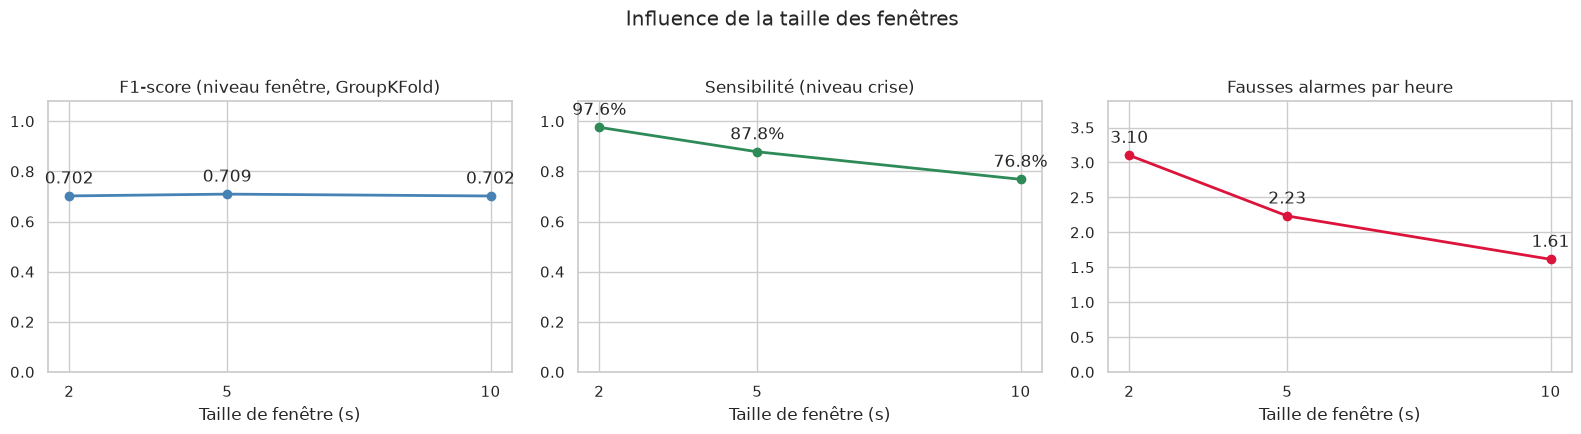

In [47]:
# Une figure : F1 (fenêtres), sensibilité (crises) et fausses alarmes par heure selon la taille de fenêtre
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
courbes = [("F1-score", "F1-score (niveau fenêtre, GroupKFold)", "steelblue", "{:.3f}"),
           ("Sensibilité crises", "Sensibilité (niveau crise)", "seagreen", "{:.1%}"),
           ("Fausses alarmes / h", "Fausses alarmes par heure", "crimson", "{:.2f}")]
for ax, (col, titre, couleur, fmt) in zip(axes, courbes):
    vals = eval_fenetres_tab[col].values
    ax.plot(WINDOW_SIZES, vals, marker="o", color=couleur, lw=2)
    for xw, v in zip(WINDOW_SIZES, vals):
        ax.annotate(fmt.format(v), (xw, v), textcoords="offset points", xytext=(0, 9), ha="center")
    ax.set(title=titre, xlabel="Taille de fenêtre (s)", xticks=WINDOW_SIZES)
for ax in axes[:2]:
    ax.set_ylim(0, 1.08)                 # même échelle 0–1 : les petits écarts ne sont pas exagérés
axes[2].set_ylim(0, 1.25 * eval_fenetres_tab["Fausses alarmes / h"].max())
plt.suptitle("Influence de la taille des fenêtres", y=1.03)
plt.tight_layout(); plt.show()

In [48]:
print(f"Durée d'exécution de la section : {time.perf_counter() - T0_FENETRES:.0f} s")

Durée d'exécution de la section : 91 s


### Interprétation

**Moins de fenêtres, et des crises courtes qui disparaissent.** En passant de 2 s à 5 s puis 10 s, le jeu passe de 28 994 à 11 581 puis 5 779 fenêtres, et les fenêtres en crise de 1 174 à 448 puis 227. La proportion de crise reste autour de 4 % (4,05 %, 3,87 %, 3,93 %) : le déséquilibre ne change pas, c'est la quantité d'exemples qui fond. Surtout, avec la règle des 50 %, une crise plus courte que la moitié de la fenêtre n'étiquette plus rien : les 82 crises gardent au moins une fenêtre à 2 s, 81 à 5 s et seulement 72 à 10 s. Dix crises annotées durent moins de 5 s (et 37 moins de 10 s, pour une médiane de 11 s) : elles sont invisibles pour un modèle à fenêtres de 10 s.

**Au niveau fenêtre, les trois tailles se valent.** Le F1 par enregistrement ne bouge presque pas : 0,702 à 2 s, 0,709 à 5 s, 0,702 à 10 s. Derrière ce score stable, l'équilibre se déplace : la précision baisse (0,743 → 0,725 → 0,699) pendant que le rappel monte (0,665 → 0,694 → 0,705). Cette métrique seule ne permet donc pas de choisir une taille, d'autant qu'elle ne « voit » pas les crises qui n'ont plus aucune fenêtre positive.

**Au niveau crise, la différence est nette.** Avec le même post-traitement, on retrouve 80 crises sur 82 à 2 s (97,6 %), 72 à 5 s (87,8 %) et 63 à 10 s (76,8 %) : 2, 10 puis 19 crises manquées. Deux effets s'additionnent : les crises courtes n'ont plus de fenêtre positive, et le lissage médian sur 3 fenêtres efface toute fenêtre positive isolée — or 3 fenêtres couvrent 4 s à 2 s, mais 20 s à 10 s. En contrepartie, les grandes fenêtres sont plus stables : les fausses alarmes passent de 25 à 18 puis 13, soit 3,10, 2,23 et 1,61 par heure sur les 8,06 h d'enregistrement. La localisation se dégrade aussi : l'écart moyen sur le début de crise passe de 1,10 s à 1,83 s puis 3,98 s, ce qui suit le pas entre deux fenêtres (1 s, 2,5 s, 5 s).

**Conclusion.** C'est bien un compromis entre précision temporelle et stabilité : allonger la fenêtre lisse le signal et réduit les fausses alarmes, mais fait perdre les crises courtes et retarde la détection. Pour des absences, souvent brèves, et dans un contexte où une crise manquée coûte plus cher qu'une fausse alarme, **la fenêtre de 2 s reste le meilleur choix** : passer à 5 s supprime 7 fausses alarmes mais fait manquer 8 crises de plus, et 10 s en fait manquer 17 de plus. Une fenêtre plus longue ne deviendrait intéressante qu'en adaptant aussi le post-traitement (lissage et durée minimale pensés en secondes plutôt qu'en nombre de fenêtres), ce qui n'a pas été testé ici.

*Les valeurs à 2 s reprennent le pipeline du notebook : même détection par crise que la partie X (80 / 82, 25 fausses alarmes). Le F1 par enregistrement peut différer de quelques dix-millièmes de celui de la partie IX selon la version de scikit-learn utilisée.*

## Analyses de recherche

Cette section va au-delà de la détection : elle regarde ce que les crises et le modèle nous apprennent. Cinq analyses, indépendantes les unes des autres :

1. **Évolution de la fréquence** pointe-onde au cours d'une crise ;
2. **Typologie des crises** par clustering (K-means) ;
3. **Explicabilité** du Random Forest (SHAP) ;
4. **Tests statistiques** entre modèles ;
5. **Courbe d'apprentissage** : combien de patients faut-il ?

Rien n'est modifié dans les sections précédentes. Les enregistrements sont traités un par un, les résultats intermédiaires sont mis en cache (`cache_recherche/`), les tableaux sont enregistrés en CSV et les figures en PNG (150 dpi) dans `figures/`. La première exécution est longue ; les suivantes relisent le cache.

In [49]:
import time
from scipy import stats
from scipy.signal import hilbert, welch

T0_RECH = time.perf_counter()            # pour mesurer la durée de toute la section

# Dossier de sortie : jamais resultats/ (résultats Colab lus par l'application web)
RECH_DIR = OUT_DIR if OUT_DIR.name != "resultats" else Path("resultats_local")
FIG_DIR = RECH_DIR / "figures"           # figures PNG, 150 dpi
CACHE_DIR = RECH_DIR / "cache_recherche" # résultats intermédiaires (supprimer ce dossier pour tout recalculer)
for d_ in (FIG_DIR, CACHE_DIR):
    d_.mkdir(parents=True, exist_ok=True)
JOURNAL = RECH_DIR / "analyses_recherche_progression.log"
FIGURES_PRODUITES = []


def progres(msg):
    # Affiche l'avancement et l'écrit aussi dans un fichier (utile quand le notebook tourne en arrière-plan)
    ligne = f"[{time.strftime('%H:%M:%S')}] {msg}"
    print(ligne, flush=True)
    with open(JOURNAL, "a", encoding="utf-8") as fh:
        fh.write(ligne + "\n")


def sauver_figure(nom):
    # Enregistre la figure courante en PNG (150 dpi) puis l'affiche
    chemin = FIG_DIR / f"{nom}.png"
    plt.savefig(chemin, dpi=150, bbox_inches="tight", facecolor="white")
    FIGURES_PRODUITES.append(chemin.name)
    plt.show()


def sauver_table(df, nom, index=True):
    df.to_csv(RECH_DIR / f"{nom}.csv", index=index)


RECS_RECH = list(dataset["Recording"].unique())               # les 19 enregistrements annotés
FICHIER_DE = {recording_id(f): f for f in DATA_FILES}         # identifiant -> fichier .mat
PATIENT_ATYPIQUE, PATIENT_ADULTE = "210914B-A", "191113A-D"   # absences atypiques ; seul patient adulte
AGE_DE = META.set_index("ID")["Age"].to_dict()

# Palette fixe, lisible par les daltoniens (une couleur = une même entité dans toute la section)
BLEU, ORANGE, VERT, ROUGE, ROSE, CIEL, GRIS = "#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#6B7280"
PALETTE = [BLEU, ORANGE, VERT, ROUGE, ROSE, CIEL]

progres(f"Analyses de recherche : {len(RECS_RECH)} enregistrements, {int(SEIZURES['ID'].isin(RECS_RECH).sum())} crises, sorties dans {RECH_DIR}/")

[21:49:18] Analyses de recherche : 19 enregistrements, 82 crises, sorties dans resultats_local/


### Préparation — prédictions « un enregistrement laissé de côté »

Plusieurs analyses ont besoin de savoir ce que le modèle prédit sur un enregistrement **qu'il n'a jamais vu**. On calcule donc une fois pour toutes, pour chaque enregistrement, les prédictions de cinq modèles entraînés sur les 18 autres (mêmes hyperparamètres que plus haut), et on les garde en cache. Pour le Random Forest, c'est exactement ce que fait `detect()`.

In [50]:
# Les cinq modèles comparés dans la partie 4 (hyperparamètres déjà définis dans le notebook)
MODELES_LORO = {"Random Forest": MODELS["Random Forest"], "Extra Trees": MODELS_TOUS["Extra Trees"],
                "LightGBM": MODELS_TOUS["LightGBM"], "XGBoost": MODELS_TOUS["XGBoost"], "KNN": MODELS["KNN"]}
LORO_CSV = CACHE_DIR / "predictions_loro.csv"

if LORO_CSV.exists():
    pred_loro = pd.read_csv(LORO_CSV)
    progres(f"Prédictions relues depuis le cache ({LORO_CSV.name})")
else:
    pred_loro = dataset[["Recording", "Window", "t_start", "t_end", "Class"]].copy()
    for name in MODELES_LORO:
        pred_loro[name] = 0
    pred_loro["Proba RF"] = np.nan                           # probabilité « crise » du Random Forest
    for i, rec in enumerate(RECS_RECH, 1):
        te = (dataset["Recording"] == rec).values           # fenêtres de l'enregistrement laissé de côté
        for name, model in MODELES_LORO.items():
            m = clone(model).fit(X[~te], y[~te])
            pred_loro.loc[te, name] = m.predict(X[te])
            if name == "Random Forest":
                pred_loro.loc[te, "Proba RF"] = m.predict_proba(X[te])[:, 1]
        progres(f"Prédictions {i}/{len(RECS_RECH)} : {rec}")
    pred_loro.to_csv(LORO_CSV, index=False)


def evenements(p_rec, col, smooth=3):
    # Même post-traitement que detect() : lissage médian, fusion à 1 s, durée minimale 2 s
    raw = p_rec[col].values
    sm = medfilt(raw, smooth).astype(int) if smooth > 1 else raw
    return windows_to_intervals(p_rec["t_start"].values, p_rec["t_end"].values, sm)


def crises_reelles(rec):
    t = seizure_table(rec)
    return list(zip(t["Début (s)"], t["Fin (s)"]))


# Résultat de la détection existante (Random Forest), crise par crise
lignes, fausses_alarmes_rf = [], []
for rec in RECS_RECH:
    p_rec = pred_loro[pred_loro["Recording"] == rec]
    m = match_events(crises_reelles(rec), evenements(p_rec, "Random Forest"))
    for _, r in m.iterrows():
        if r["Résultat"] == "Fausse alarme":
            fausses_alarmes_rf.append({"ID": rec, "Début détecté": r["Début détecté"], "Fin détectée": r["Fin détectée"]})
        else:
            lignes.append({"ID": rec, "Début (s)": r["Début réel"], "Fin (s)": r["Fin réelle"], "Résultat": r["Résultat"],
                           "Début détecté": r.get("Début détecté", np.nan),
                           "Retard début (s)": (r["Début détecté"] - r["Début réel"]) if r["Résultat"] == "Détectée" else np.nan})
detection_rf = pd.DataFrame(lignes)
fausses_alarmes_rf = pd.DataFrame(fausses_alarmes_rf)
print(f"Contrôle (Random Forest) : {(detection_rf['Résultat'] == 'Détectée').sum()} crises détectées sur {len(detection_rf)}, "
      f"{len(fausses_alarmes_rf)} fausses alarmes — identique à la partie X")

[21:49:25] Prédictions 1/19 : 190304A-E


[21:49:32] Prédictions 2/19 : 191113A-D


[21:49:41] Prédictions 3/19 : 210406A-F


[21:49:48] Prédictions 4/19 : 210427B-C


[21:49:55] Prédictions 5/19 : 210504B-C


[21:50:02] Prédictions 6/19 : 210914B-A


... (10 outputs left out)

[21:51:22] Prédictions 17/19 : 230515B-G


[21:51:30] Prédictions 18/19 : 230519A-E


[21:51:37] Prédictions 19/19 : 230718A-A


Contrôle (Random Forest) : 80 crises détectées sur 82, 25 fausses alarmes — identique à la partie X


### 1. Évolution de la fréquence au cours d'une crise

**Hypothèse clinique.** Le rythme pointe-onde d'une absence démarre souvent un peu plus vite (≈ 3,5–4 Hz) puis ralentit (≈ 2,5–3 Hz) avant la fin.

**Méthode.** Pour chaque crise annotée d'au moins 4 s, une fenêtre de 2 s glisse par pas de 0,5 s du début à la fin de la crise, sur le signal filtré (médiane retirée, 0,5–40 Hz, comme dans le reste du notebook). Dans chaque fenêtre, on calcule le spectre de chaque canal (fenêtre de Hann, FFT complétée par des zéros pour un pas de 0,1 Hz), on fait la moyenne des 19 canaux et on retient la fréquence du maximum entre 1,5 et 5 Hz. Le temps est ensuite ramené à l'avancement de la crise : **0 = la fenêtre qui couvre les 2 premières secondes, 1 = celle qui couvre les 2 dernières**.

Le même passage sur les signaux calcule aussi les descripteurs de la partie 2 (un seul chargement par enregistrement).

In [51]:
BANDE_PO = (2.5, 4.0)                    # bande du rythme pointe-onde (Hz)
FRONTAL = ["Fp1", "Fp2", "F3", "F4", "F7", "F8", "Fz"]
POSTERIEUR = ["P3", "P4", "Pz", "O1", "O2"]
TRAJ_CSV, DESC_CSV = CACHE_DIR / "crises_trajectoires_frequence.csv", CACHE_DIR / "crises_descripteurs.csv"


def freq_dominante(seg, fs, lo=1.5, hi=5.0):
    # Fréquence du maximum du spectre moyen des canaux, entre lo et hi (zéro-padding : pas de 0,1 Hz)
    nfft = int(round(fs / 0.1))
    psd = np.abs(np.fft.rfft((seg - seg.mean(0)) * np.hanning(len(seg))[:, None], n=nfft, axis=0)) ** 2
    f = np.fft.rfftfreq(nfft, 1 / fs)
    ok = (f >= lo) & (f <= hi)
    return f[ok][psd.mean(1)[ok].argmax()]


def trajectoire_frequence(Xf, fs, s, e, win=2.0, step=0.5):
    # Fenêtre glissante de 2 s (pas 0,5 s) du début à la fin de la crise
    n = int(round(win * fs))
    debuts = np.arange(s, e - win + 1e-9, step)
    freqs = [freq_dominante(Xf[int(round(d * fs)):int(round(d * fs)) + n], fs) for d in debuts]
    avancement = (debuts - s) / (e - win - s) if e - win > s else np.zeros(len(debuts))
    return debuts - s + win / 2, avancement, np.array(freqs)   # temps du centre (s), avancement 0–1, fréquence (Hz)


def puissance_bande(seg, fs, lo, hi):
    # Puissance par canal dans [lo, hi] (méthode de Welch, segments de 2 s au plus)
    f, p = welch(seg, fs=fs, nperseg=min(len(seg), int(2 * fs)), axis=0)
    ok = (f >= lo) & (f <= hi)
    return p[ok].sum(0) * (f[1] - f[0])


def plv_moyenne(Xb, i0, i1, fs):
    # Synchronie : moyenne du « phase-locking value » sur toutes les paires de canaux (signal déjà filtré 2,5–4 Hz)
    marge = int(fs)                                          # 1 s de marge contre les effets de bord de Hilbert
    a, b = max(0, i0 - marge), min(len(Xb), i1 + marge)
    z = np.exp(1j * np.angle(hilbert(Xb[a:b], axis=0)))[i0 - a:i1 - a]
    plv = np.abs(z.conj().T @ z) / len(z)                    # matrice canal × canal
    return plv[np.triu_indices_from(plv, k=1)].mean()


if TRAJ_CSV.exists() and DESC_CSV.exists():
    trajectoires, descripteurs = pd.read_csv(TRAJ_CSV), pd.read_csv(DESC_CSV)
    progres("Trajectoires de fréquence et descripteurs relus depuis le cache")
else:
    traj_rows, desc_rows = [], []
    for i, rec in enumerate(RECS_RECH, 1):                   # un enregistrement à la fois (mémoire)
        d, fs = load_eeg(FICHIER_DE[rec])
        chans = [c for c in d.columns if c.startswith("EEG")]
        d = add_class(d, rec)
        hors_crise = d["Class"].values == 0
        Xf = d[chans].values.astype(np.float64)
        Xf = bandpass(Xf - np.median(Xf, axis=0), fs)        # même prétraitement que extract_features()
        Xb = bandpass(Xf, fs, lo=BANDE_PO[0], hi=BANDE_PO[1])    # bande pointe-onde, pour la synchronie
        i_front = [k for k, c in enumerate(chans) if c.replace("EEG", "") in FRONTAL]
        i_post = [k for k, c in enumerate(chans) if c.replace("EEG", "") in POSTERIEUR]
        duree_rec = len(d) / fs
        del d
        for k, (s, e) in enumerate(crises_reelles(rec), 1):
            e = min(e, duree_rec)
            i0, i1 = int(round(s * fs)), int(round(e * fs))
            seg = Xf[i0:i1]
            t_c, av, fr = trajectoire_frequence(Xf, fs, s, e)
            for a_, b_, c_ in zip(t_c, av, fr):
                traj_rows.append({"ID": rec, "Crise": k, "t (s)": a_, "Avancement": b_, "Fréquence (Hz)": c_})
            # RMS de référence : les 10 s qui précèdent, sans compter d'éventuels échantillons d'une autre crise
            j0 = max(0, i0 - int(10 * fs))
            avant = Xf[j0:i0][hors_crise[j0:i0]]
            p_po, p_tot = puissance_bande(seg, fs, *BANDE_PO), puissance_bande(seg, fs, 0.5, 30)
            desc_rows.append({
                "ID": rec, "Crise": k, "Début (s)": s, "Fin (s)": e, "Durée (s)": e - s,
                "Fréquence moyenne (Hz)": fr.mean() if len(fr) else np.nan,
                "Fréquence début (Hz)": fr[0] if len(fr) else np.nan,       # fenêtre des 2 premières secondes
                "Fréquence fin (Hz)": fr[-1] if len(fr) else np.nan,        # fenêtre des 2 dernières secondes
                "Pente (Hz/s)": np.polyfit(t_c, fr, 1)[0] if len(fr) >= 3 else np.nan,
                "Rapport d'amplitude": np.sqrt((seg ** 2).mean()) / np.sqrt((avant ** 2).mean()) if len(avant) >= 2 * fs else np.nan,
                "Puissance relative 2,5–4 Hz": p_po.sum() / p_tot.sum(),
                "Synchronie (PLV)": plv_moyenne(Xb, i0, i1, fs),
                "Rapport frontal/postérieur": p_po[i_front].mean() / p_po[i_post].mean(),
            })
        del Xf, Xb
        progres(f"Signaux {i}/{len(RECS_RECH)} : {rec} ({len(crises_reelles(rec))} crises)")
    trajectoires, descripteurs = pd.DataFrame(traj_rows), pd.DataFrame(desc_rows)
    trajectoires.to_csv(TRAJ_CSV, index=False); descripteurs.to_csv(DESC_CSV, index=False)

print(f"{len(descripteurs)} crises décrites, {len(trajectoires)} fenêtres glissantes")

[21:51:38] Signaux 1/19 : 190304A-E (1 crises)


[21:51:39] Signaux 2/19 : 191113A-D (2 crises)


[21:51:39] Signaux 3/19 : 210406A-F (1 crises)


[21:51:40] Signaux 4/19 : 210427B-C (1 crises)


[21:51:41] Signaux 5/19 : 210504B-C (11 crises)


[21:51:42] Signaux 6/19 : 210914B-A (11 crises)


... (10 outputs left out)

[21:51:50] Signaux 17/19 : 230515B-G (2 crises)


[21:51:51] Signaux 18/19 : 230519A-E (2 crises)


[21:51:51] Signaux 19/19 : 230718A-A (7 crises)


82 crises décrites, 1938 fenêtres glissantes


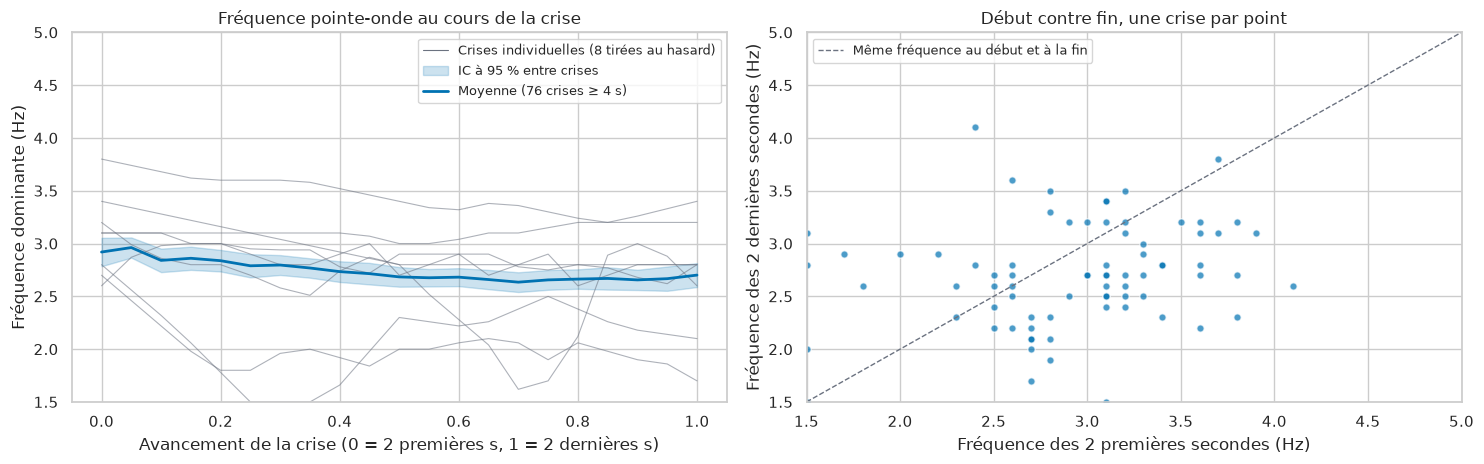

In [52]:
# Crises d'au moins 4 s : courbe moyenne sur une grille commune d'avancement (0 → 1)
crises_4s = descripteurs[descripteurs["Durée (s)"] >= 4].reset_index(drop=True)
GRILLE = np.linspace(0, 1, 21)
courbes = {}
for (rec, k), g in trajectoires.groupby(["ID", "Crise"]):
    if ((crises_4s["ID"] == rec) & (crises_4s["Crise"] == k)).any():
        courbes[(rec, k)] = np.interp(GRILLE, g["Avancement"].values, g["Fréquence (Hz)"].values)
M = np.array(list(courbes.values()))                         # (crises, points de la grille)


def moyenne_ic(mat):
    # Moyenne et intervalle de confiance à 95 % entre crises (loi de Student)
    m, sem = mat.mean(0), mat.std(0, ddof=1) / np.sqrt(len(mat))
    h = stats.t.ppf(0.975, len(mat) - 1) * sem
    return m, m - h, m + h


moy, ic_bas, ic_haut = moyenne_ic(M)
courbe_moyenne = pd.DataFrame({"Avancement": GRILLE, "Fréquence moyenne (Hz)": moy, "IC95 bas": ic_bas, "IC95 haut": ic_haut})

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
ax = axes[0]
rng_fig = np.random.default_rng(42)
for j in rng_fig.choice(len(M), size=min(8, len(M)), replace=False):       # quelques crises individuelles
    ax.plot(GRILLE, M[j], color=GRIS, lw=0.8, alpha=0.55)
ax.plot([], [], color=GRIS, lw=0.8, label="Crises individuelles (8 tirées au hasard)")
ax.fill_between(GRILLE, ic_bas, ic_haut, color=BLEU, alpha=0.2, label="IC à 95 % entre crises")
ax.plot(GRILLE, moy, color=BLEU, lw=2, label=f"Moyenne ({len(M)} crises ≥ 4 s)")
ax.set(xlabel="Avancement de la crise (0 = 2 premières s, 1 = 2 dernières s)", ylabel="Fréquence dominante (Hz)",
       title="Fréquence pointe-onde au cours de la crise", ylim=(1.5, 5))
ax.legend(loc="upper right", fontsize=9)

ax = axes[1]
ax.scatter(crises_4s["Fréquence début (Hz)"], crises_4s["Fréquence fin (Hz)"], s=28, color=BLEU, alpha=0.7, edgecolor="white")
ax.plot([1.5, 5], [1.5, 5], color=GRIS, lw=1, ls="--", label="Même fréquence au début et à la fin")
ax.set(xlabel="Fréquence des 2 premières secondes (Hz)", ylabel="Fréquence des 2 dernières secondes (Hz)",
       title="Début contre fin, une crise par point", xlim=(1.5, 5), ylim=(1.5, 5))
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout(); sauver_figure("frequence_evolution_moyenne")

In [53]:
# Tests : la pente est-elle négative ? (Wilcoxon des rangs signés, unilatéral)
pentes = crises_4s["Pente (Hz/s)"].values
diff = (crises_4s["Fréquence fin (Hz)"] - crises_4s["Fréquence début (Hz)"]).values
med_patient = crises_4s.groupby("ID")["Pente (Hz/s)"].median()   # une valeur par patient : crises d'un même patient non indépendantes

tests_frequence = pd.DataFrame([
    {"Test": "Pente < 0 (une valeur par crise)", "n": len(pentes), "Médiane": np.median(pentes),
     "p (Wilcoxon unilatéral)": stats.wilcoxon(pentes, alternative="less").pvalue},
    {"Test": "Fréquence fin − début < 0 (par crise)", "n": len(diff), "Médiane": np.median(diff),
     "p (Wilcoxon unilatéral)": stats.wilcoxon(diff, alternative="less").pvalue},
    {"Test": "Pente médiane < 0 (une valeur par patient)", "n": len(med_patient), "Médiane": med_patient.median(),
     "p (Wilcoxon unilatéral)": stats.wilcoxon(med_patient.values, alternative="less").pvalue},
]).set_index("Test")

print(f"Crises ≥ 4 s : {len(crises_4s)} sur {len(descripteurs)} ({crises_4s['ID'].nunique()} patients)")
print(f"Fréquence médiane des 2 premières secondes : {crises_4s['Fréquence début (Hz)'].median():.2f} Hz")
print(f"Fréquence médiane des 2 dernières secondes : {crises_4s['Fréquence fin (Hz)'].median():.2f} Hz")
print(f"Fréquence moyenne sur la courbe : {moy[0]:.2f} Hz au début, {moy[-1]:.2f} Hz à la fin")
print(f"Crises dont la pente est négative : {(pentes < 0).sum()} / {len(pentes)} ({100 * (pentes < 0).mean():.0f} %)")
print(f"Patients dont la pente médiane est négative : {(med_patient < 0).sum()} / {len(med_patient)}")

sauver_table(crises_4s, "frequence_par_crise", index=False)
sauver_table(courbe_moyenne, "frequence_courbe_moyenne", index=False)
sauver_table(tests_frequence, "frequence_tests")
tests_frequence.round(4)

Crises ≥ 4 s : 76 sur 82 (19 patients)
Fréquence médiane des 2 premières secondes : 3.05 Hz
Fréquence médiane des 2 dernières secondes : 2.70 Hz
Fréquence moyenne sur la courbe : 2.92 Hz au début, 2.70 Hz à la fin
Crises dont la pente est négative : 62 / 76 (82 %)
Patients dont la pente médiane est négative : 17 / 19


,n,Médiane,p (Wilcoxon unilatéral)
Test,,,
Pente < 0 (une valeur par crise),76,-0.0307,0.0000
Fréquence fin − début < 0 (par crise),76,-0.4000,0.0011
Pente médiane < 0 (une valeur par patient),19,-0.0281,0.0000


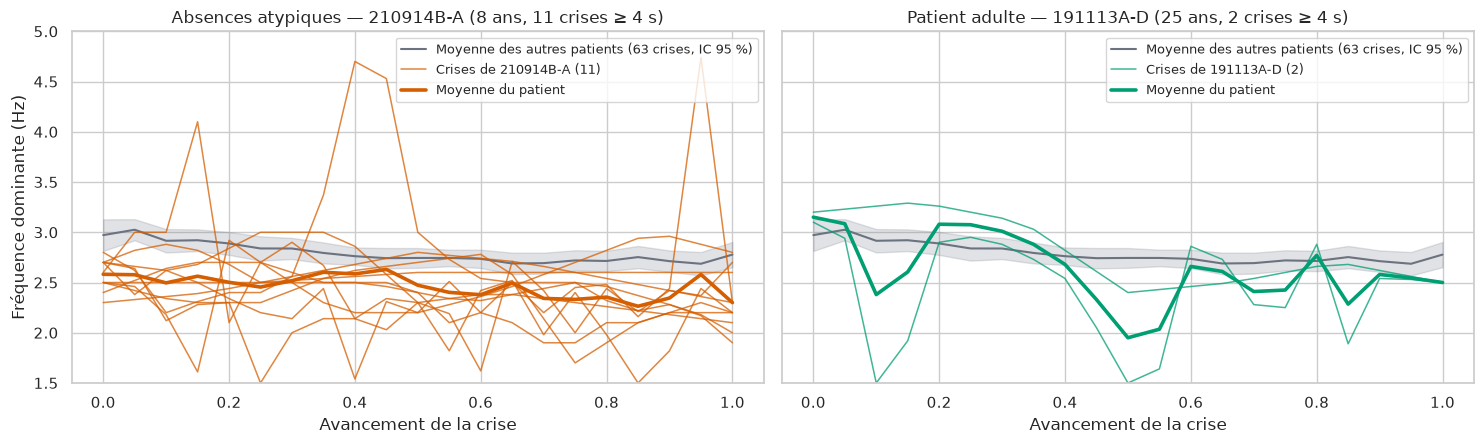

,Crises,Age,Frequence_debut_mediane,Frequence_fin_mediane,Pente_mediane,Duree_mediane
ID,,,,,,
210914B-A,11,8.0,2.60,2.2,-0.012,8.0
191113A-D,2,25.0,3.15,2.5,-0.147,9.0


In [54]:
# Patient aux absences atypiques et patient adulte, montrés à part (toutes leurs crises ≥ 4 s)
frequence_par_patient = crises_4s.groupby("ID").agg(
    Crises=("Crise", "count"), Age=("ID", lambda s_: AGE_DE.get(s_.iloc[0])),
    Frequence_debut_mediane=("Fréquence début (Hz)", "median"), Frequence_fin_mediane=("Fréquence fin (Hz)", "median"),
    Pente_mediane=("Pente (Hz/s)", "median"), Duree_mediane=("Durée (s)", "median"))
sauver_table(frequence_par_patient, "frequence_par_patient")

autres = np.array([v for (rec, k), v in courbes.items() if rec not in (PATIENT_ATYPIQUE, PATIENT_ADULTE)])
moy_a, bas_a, haut_a = moyenne_ic(autres)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
for ax, rec, titre, couleur in [(axes[0], PATIENT_ATYPIQUE, "Absences atypiques", ROUGE), (axes[1], PATIENT_ADULTE, "Patient adulte", VERT)]:
    ax.fill_between(GRILLE, bas_a, haut_a, color=GRIS, alpha=0.2)
    ax.plot(GRILLE, moy_a, color=GRIS, lw=1.5, label=f"Moyenne des autres patients ({len(autres)} crises, IC 95 %)")
    siennes = [(k, v) for (r_, k), v in courbes.items() if r_ == rec]
    for j, (k, v) in enumerate(siennes):
        ax.plot(GRILLE, v, color=couleur, lw=1.1, alpha=0.75, label=f"Crises de {rec} ({len(siennes)})" if j == 0 else None)
    if len(siennes) > 1:
        ax.plot(GRILLE, np.mean([v for _, v in siennes], axis=0), color=couleur, lw=2.6, label="Moyenne du patient")
    age = AGE_DE.get(rec)
    ax.set(title=f"{titre} — {rec} ({age:.0f} ans, {len(siennes)} crises ≥ 4 s)", xlabel="Avancement de la crise", ylim=(1.5, 5))
    ax.legend(loc="upper right", fontsize=9)
axes[0].set_ylabel("Fréquence dominante (Hz)")
plt.tight_layout(); sauver_figure("frequence_patients_atypique_adulte")
frequence_par_patient.loc[[r_ for r_ in (PATIENT_ATYPIQUE, PATIENT_ADULTE) if r_ in frequence_par_patient.index]].round(3)

#### Interprétation

**Le rythme ralentit bien, mais il part de moins haut que prévu.** Sur les 76 crises d'au moins 4 s (19 patients), la fréquence dominante médiane passe de 3,05 Hz dans les 2 premières secondes à 2,70 Hz dans les 2 dernières ; la courbe moyenne descend de 2,92 Hz à 2,70 Hz. La pente est négative pour 62 crises sur 76 (82 %), avec une médiane de −0,031 Hz/s, et le test de Wilcoxon unilatéral rejette l'absence de ralentissement (p ≈ 1 × 10⁻⁶ sur les pentes ; p = 0,001 sur la différence fin − début, dont la médiane est −0,40 Hz). Comme les crises d'un même patient ne sont pas indépendantes, le test a été refait avec une seule valeur par patient : la pente médiane est négative chez 17 patients sur 19 (p ≈ 2 × 10⁻⁵).

L'hypothèse clinique est donc confirmée dans son sens, pas dans son ampleur : le départ se fait autour de 3 Hz et non de 3,5–4 Hz (seules 13 crises sur 76 commencent à 3,5 Hz ou plus), et le ralentissement est de l'ordre de 0,2 à 0,4 Hz.

**Les deux patients particuliers.** Le patient aux absences atypiques (210914B-A, 8 ans, 11 crises) a un rythme plus lent du début à la fin (2,60 Hz puis 2,20 Hz en médiane) et presque pas de pente (−0,012 Hz/s). Le patient adulte (191113A-D, 25 ans) passe de 3,15 Hz à 2,50 Hz avec une pente marquée (−0,147 Hz/s), mais sur 2 crises seulement.

**Limites.** Une fenêtre de 2 s ne sépare réellement que des fréquences distantes d'environ 0,5 Hz : le pas de 0,1 Hz vient du zéro-padding, qui interpole le pic sans ajouter d'information. Le ralentissement mesuré est du même ordre que cette résolution ; c'est la répétition sur 76 crises qui le rend crédible, pas la mesure d'une crise isolée. Quelques fenêtres ont leur maximum sur la borne basse de 1,5 Hz (4 débuts et 2 fins), signe qu'il n'y avait pas de pic net. Les débuts et fins de crise sont annotés à la seconde près. Enfin, un seul adulte et un seul patient atypique : ce qui est dit d'eux décrit ces deux personnes, pas leur groupe.

### 2. Typologie des crises (clustering K-means)

Chaque crise est décrite par sept mesures : durée, fréquence dominante moyenne, pente de la fréquence (partie 1), **rapport d'amplitude** (RMS pendant la crise / RMS des 10 s qui précèdent), **puissance relative 2,5–4 Hz** (sur 0,5–30 Hz), **synchronie entre canaux** dans 2,5–4 Hz (moyenne du *phase-locking value* sur les 171 paires de canaux, phase obtenue par transformée de Hilbert) et **rapport frontal/postérieur** de la puissance 2,5–4 Hz (Fp1, Fp2, F3, F4, F7, F8, Fz contre P3, P4, Pz, O1, O2).

Le clustering porte sur les crises d'au moins 4 s (en dessous, la pente n'est pas mesurable). Les trois variables très asymétriques (durée, rapport d'amplitude, rapport frontal/postérieur) sont passées en logarithme, puis tout est standardisé. K-means est lancé pour k = 2 à 6 ; on retient le k qui a le meilleur score de silhouette, et une classification hiérarchique (Ward) sert de contrôle.

Crises retenues : 76 sur 82 — exclues : 6 de moins de 4 s, 0 sans référence d'amplitude mesurable


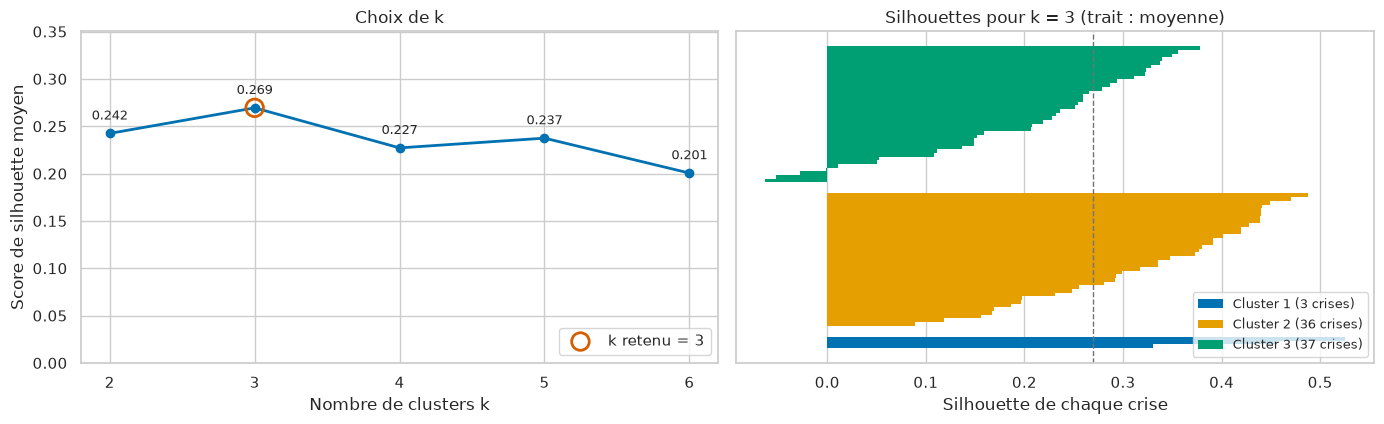

k,2,3,4,5,6
Silhouette,0.2424,0.2694,0.2272,0.2374,0.2006


In [55]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

VARS_TYPO = ["Durée (s)", "Fréquence moyenne (Hz)", "Pente (Hz/s)", "Rapport d'amplitude", "Puissance relative 2,5–4 Hz",
             "Synchronie (PLV)", "Rapport frontal/postérieur"]
VARS_LOG = ["Durée (s)", "Rapport d'amplitude", "Rapport frontal/postérieur"]     # distributions très asymétriques

typo = descripteurs[descripteurs["Durée (s)"] >= 4].dropna(subset=VARS_TYPO).reset_index(drop=True)
exclues = descripteurs.merge(typo[["ID", "Crise"]], how="left", indicator=True).query("_merge == 'left_only'")
print(f"Crises retenues : {len(typo)} sur {len(descripteurs)} — exclues : {(descripteurs['Durée (s)'] < 4).sum()} de moins de 4 s, "
      f"{len(exclues) - (descripteurs['Durée (s)'] < 4).sum()} sans référence d'amplitude mesurable")

Z = typo[VARS_TYPO].copy()
Z[VARS_LOG] = np.log10(Z[VARS_LOG])
Z = StandardScaler().fit_transform(Z)

# K-means pour k = 2 à 6, choix de k par le score de silhouette
sil, labels_k = {}, {}
for k in range(2, 7):
    labels_k[k] = KMeans(n_clusters=k, n_init=20, random_state=42).fit_predict(Z)
    sil[k] = silhouette_score(Z, labels_k[k])
K_OPT = max(sil, key=sil.get)
silhouette_tab = pd.DataFrame({"k": list(sil), "Silhouette": list(sil.values())}).set_index("k")

# Clusters renumérotés de 1 à k par durée médiane croissante (numérotation stable d'une exécution à l'autre)
ordre = typo.groupby(labels_k[K_OPT])["Durée (s)"].median().sort_values().index
typo["Cluster"] = pd.Series(labels_k[K_OPT]).map({c: j + 1 for j, c in enumerate(ordre)}).values
typo["Silhouette"] = silhouette_samples(Z, typo["Cluster"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
axes[0].plot(silhouette_tab.index, silhouette_tab["Silhouette"], marker="o", color=BLEU, lw=2)
axes[0].scatter([K_OPT], [sil[K_OPT]], s=160, facecolor="none", edgecolor=ROUGE, lw=2, label=f"k retenu = {K_OPT}", zorder=3)
for k, v in sil.items():
    axes[0].annotate(f"{v:.3f}", (k, v), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=9)
axes[0].set(xlabel="Nombre de clusters k", ylabel="Score de silhouette moyen", xticks=list(sil), title="Choix de k",
            ylim=(0, max(sil.values()) * 1.3))
axes[0].legend(loc="lower right")
bas = 0
for c in sorted(typo["Cluster"].unique()):                   # silhouette de chaque crise, cluster par cluster
    v = np.sort(typo.loc[typo["Cluster"] == c, "Silhouette"].values)
    axes[1].barh(np.arange(bas, bas + len(v)), v, height=1.0, color=PALETTE[c - 1], edgecolor="none", label=f"Cluster {c} ({len(v)} crises)")
    bas += len(v) + 3
axes[1].axvline(sil[K_OPT], color=GRIS, ls="--", lw=1)
axes[1].set(xlabel="Silhouette de chaque crise", yticks=[], title=f"Silhouettes pour k = {K_OPT} (trait : moyenne)")
axes[1].legend(loc="lower right", fontsize=9)
plt.tight_layout(); sauver_figure("typologie_silhouette")
silhouette_tab.round(4).T

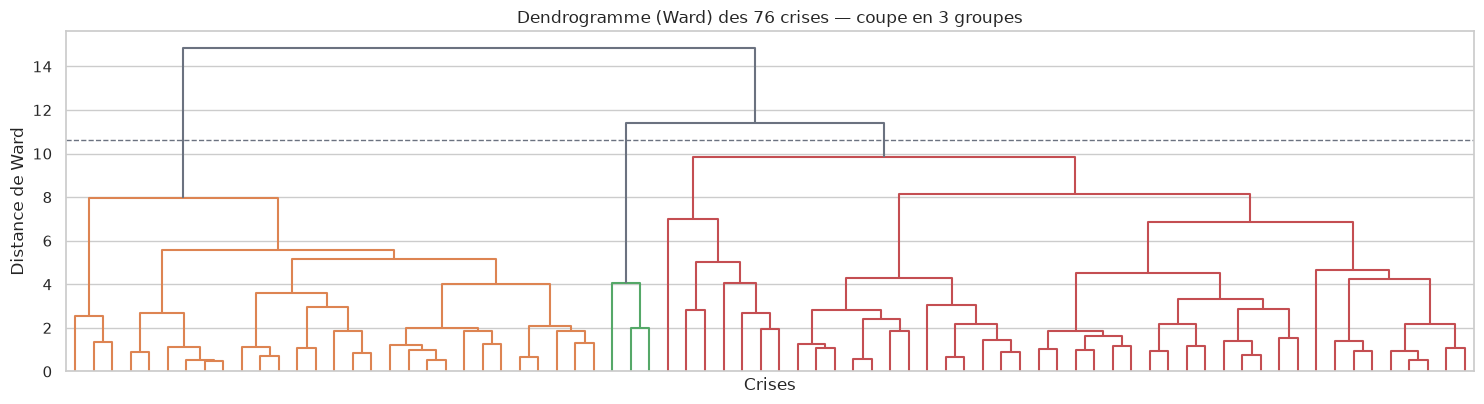

Accord K-means / Ward pour k = 3 : indice de Rand ajusté = 0.59 (1 = partitions identiques, 0 = hasard)


Groupe Ward,1,2,3
Cluster,,,
1,0,0,3
2,8,28,0
3,36,1,0


In [56]:
# Contrôle : classification hiérarchique (Ward) sur les mêmes données standardisées
lien = linkage(Z, method="ward")
labels_ward = AgglomerativeClustering(n_clusters=K_OPT, linkage="ward").fit_predict(Z)
ARI_WARD = adjusted_rand_score(typo["Cluster"], labels_ward)

fig, ax = plt.subplots(figsize=(15, 4.2))
seuil = (lien[-K_OPT, 2] + lien[-K_OPT + 1, 2]) / 2          # hauteur de coupe qui donne K_OPT groupes
dendrogram(lien, ax=ax, no_labels=True, color_threshold=seuil, above_threshold_color=GRIS)
ax.axhline(seuil, color=GRIS, ls="--", lw=1)
ax.set(title=f"Dendrogramme (Ward) des {len(typo)} crises — coupe en {K_OPT} groupes", ylabel="Distance de Ward", xlabel="Crises")
plt.tight_layout(); sauver_figure("typologie_dendrogramme")
print(f"Accord K-means / Ward pour k = {K_OPT} : indice de Rand ajusté = {ARI_WARD:.2f} (1 = partitions identiques, 0 = hasard)")
pd.crosstab(typo["Cluster"], pd.Series(labels_ward + 1, name="Groupe Ward"))

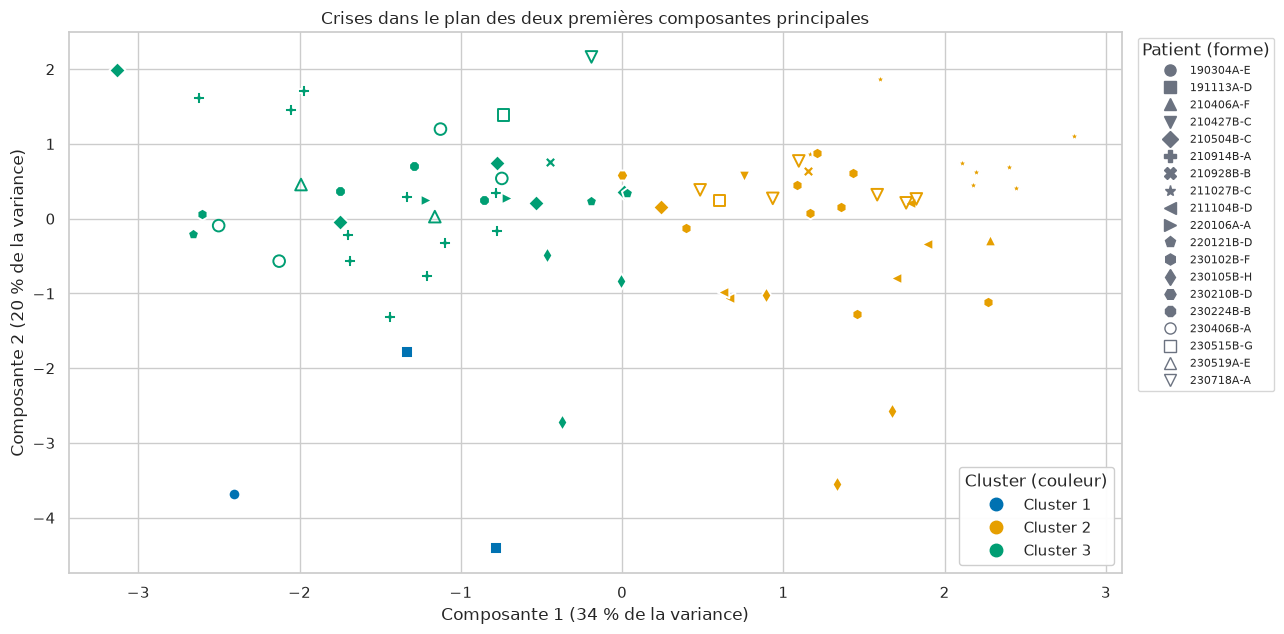

,Composante 1,Composante 2
Durée (s),-0.15,0.52
Fréquence moyenne (Hz),0.53,-0.11
Pente (Hz/s),-0.01,0.67
Rapport d'amplitude,0.12,-0.18
"Puissance relative 2,5–4 Hz",0.59,0.22
Synchronie (PLV),0.56,-0.06
Rapport frontal/postérieur,-0.16,-0.43


In [57]:
# Projection ACP en 2 dimensions : couleur = cluster, forme = patient
acp = PCA(n_components=2, random_state=42)
P2 = acp.fit_transform(Z)
MARQUEURS = ["o", "s", "^", "v", "D", "P", "X", "*", "<", ">", "p", "h", "d", "H", "8", "o", "s", "^", "v"]
patients = sorted(typo["ID"].unique())

fig, ax = plt.subplots(figsize=(13, 6.5))
for j, rec in enumerate(patients):
    sel = (typo["ID"] == rec).values
    plein = j < 15                                           # au-delà de 15 patients : mêmes formes, mais creuses
    for c in sorted(typo.loc[sel, "Cluster"].unique()):
        s2 = sel & (typo["Cluster"] == c).values
        ax.scatter(P2[s2, 0], P2[s2, 1], marker=MARQUEURS[j], s=70, lw=1.4,
                   facecolor=PALETTE[c - 1] if plein else "none", edgecolor="white" if plein else PALETTE[c - 1])
h_clusters = [plt.Line2D([], [], marker="o", ls="", color=PALETTE[c - 1], markersize=9, label=f"Cluster {c}") for c in sorted(typo["Cluster"].unique())]
h_patients = [plt.Line2D([], [], marker=MARQUEURS[j], ls="", markersize=8, markerfacecolor=GRIS if j < 15 else "none",
                         markeredgecolor=GRIS, label=rec) for j, rec in enumerate(patients)]
leg1 = ax.legend(handles=h_clusters, title="Cluster (couleur)", loc="lower right", framealpha=0.95)
ax.add_artist(leg1)
ax.legend(handles=h_patients, title="Patient (forme)", loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=8)
var = acp.explained_variance_ratio_
ax.set(xlabel=f"Composante 1 ({100 * var[0]:.0f} % de la variance)", ylabel=f"Composante 2 ({100 * var[1]:.0f} % de la variance)",
       title="Crises dans le plan des deux premières composantes principales")
plt.tight_layout(); sauver_figure("typologie_acp")

charges = pd.DataFrame(acp.components_.T, index=VARS_TYPO, columns=["Composante 1", "Composante 2"])
sauver_table(charges, "typologie_acp_charges")
charges.round(2)

In [58]:
# Centroïdes dans les unités d'origine (médiane de chaque variable par cluster)
centroides = typo.groupby("Cluster")[VARS_TYPO].median()
centroides.insert(0, "Patients", typo.groupby("Cluster")["ID"].nunique())
centroides.insert(0, "Crises", typo.groupby("Cluster").size())
centroides.loc["Toutes"] = [len(typo), typo["ID"].nunique()] + list(typo[VARS_TYPO].median())
sauver_table(centroides, "typologie_centroides")
centroides.round(3)

,Crises,Patients,Durée (s),Fréquence moyenne (Hz),Pente (Hz/s),Rapport d'amplitude,"Puissance relative 2,5–4 Hz",Synchronie (PLV),Rapport frontal/postérieur
Cluster,,,,,,,,,
1,3.0,2.0,7.0,2.645,-0.251,3.680,0.374,0.720,12.902
2,36.0,11.0,10.5,3.015,-0.033,3.412,0.637,0.819,0.232
3,37.0,12.0,14.0,2.514,-0.024,3.135,0.386,0.651,0.196
Toutes,76.0,19.0,11.0,2.783,-0.031,3.205,0.523,0.724,0.223


In [59]:
# Croisements : patient, tranche d'âge, type d'absence et résultat de la détection existante
def tranche_age(a):
    return "Âge inconnu" if pd.isna(a) else "< 10 ans" if a < 10 else "10–17 ans" if a < 18 else "≥ 18 ans"

type_de = META.set_index("ID")["TypeAbs"].to_dict()
typo["Tranche d'âge"] = typo["ID"].map(AGE_DE).map(tranche_age)
typo["Type d'absence"] = typo["ID"].map(lambda r_: "Atypique" if isinstance(type_de.get(r_), str) else "Non précisé (typique a priori)")
typo = typo.merge(detection_rf[["ID", "Début (s)", "Résultat", "Retard début (s)"]], on=["ID", "Début (s)"], how="left")

x_patient = pd.crosstab(typo["ID"], typo["Cluster"])
x_age = pd.crosstab(typo["Tranche d'âge"], typo["Cluster"])
x_type = pd.crosstab(typo["Type d'absence"], typo["Cluster"])
x_detection = typo.groupby("Cluster").agg(
    Crises=("Résultat", "size"), Détectées=("Résultat", lambda s_: (s_ == "Détectée").sum()),
    Manquées=("Résultat", lambda s_: (s_ == "Manquée").sum()),
    Retard_médian_s=("Retard début (s)", "median"), Retard_moyen_abs_s=("Retard début (s)", lambda s_: s_.abs().mean()),
    Détectées_avec_plus_de_2s_de_retard=("Retard début (s)", lambda s_: (s_ > 2).sum()))

for nom, tab in [("typologie_crises", typo), ("typologie_silhouette_par_k", silhouette_tab), ("typologie_cluster_x_patient", x_patient),
                 ("typologie_cluster_x_age", x_age), ("typologie_cluster_x_type", x_type), ("typologie_cluster_x_detection", x_detection)]:
    sauver_table(tab, nom, index=nom != "typologie_crises")

# Les crises écartées du clustering (trop courtes) : comment sont-elles détectées ?
courtes = descripteurs[descripteurs["Durée (s)"] < 4].merge(detection_rf[["ID", "Début (s)", "Résultat", "Retard début (s)"]], on=["ID", "Début (s)"])
print(f"Crises de moins de 4 s (hors clustering) : {len(courtes)}, dont {(courtes['Résultat'] == 'Détectée').sum()} détectées")
display(x_patient.T); display(x_age); display(x_type)
x_detection.round(2)

Crises de moins de 4 s (hors clustering) : 6, dont 6 détectées


ID,190304A-E,191113A-D,210406A-F,210427B-C,210504B-C,210914B-A,210928B-B,211027B-C,211104B-D,220106A-A,220121B-D,230102B-F,230105B-H,230210B-D,230224B-B,230406B-A,230515B-G,230519A-E,230718A-A
Cluster,,,,,,,,,,,,,,,,,,,
1,1,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,1,1,1,0,1,8,5,0,0,8,3,1,0,0,1,0,6
3,0,0,0,0,5,11,1,0,0,2,3,1,3,0,3,4,1,2,1


Cluster,1,2,3
Tranche d'âge,,,
10–17 ans,1,5,14
< 10 ans,0,31,23
≥ 18 ans,2,0,0


Cluster,1,2,3
Type d'absence,,,
Atypique,0,0,11
Non précisé (typique a priori),3,36,26


,Crises,Détectées,Manquées,Retard_médian_s,Retard_moyen_abs_s,Détectées_avec_plus_de_2s_de_retard
Cluster,,,,,,
1,3,1,2,0.0,0.00,0
2,36,36,0,0.0,0.53,2
3,37,37,0,0.0,1.78,9


#### Interprétation

**Pas de types nettement séparés.** Le score de silhouette est le meilleur pour k = 3 (0,269), mais il reste faible pour toutes les valeurs de k (de 0,20 à 0,27) : les 76 crises forment plutôt un continuum que des familles distinctes. La classification hiérarchique retrouve en partie la même partition (indice de Rand ajusté de 0,59). Les deux premières composantes de l'ACP portent 54 % de la variance ; la première oppose surtout fréquence, puissance relative 2,5–4 Hz et synchronie.

**Les trois groupes obtenus** (médianes) :
- **Cluster 2 — pointe-onde franche** (36 crises, 11 patients) : rythme proche de 3 Hz (3,02 Hz), puissance concentrée dans la bande 2,5–4 Hz (0,64) et canaux très synchrones (PLV 0,82) ; durée médiane 10,5 s.
- **Cluster 3 — crises plus lentes et moins organisées** (37 crises, 12 patients) : 2,51 Hz, puissance moins concentrée (0,39), synchronie plus faible (0,65), durée médiane 14 s.
- **Cluster 1 — prédominance frontale** (3 crises, 2 patients) : la puissance 2,5–4 Hz est 9 à 17 fois plus forte à l'avant qu'à l'arrière (rapport inférieur à 1,5 partout ailleurs), avec le ralentissement le plus marqué (−0,25 Hz/s).

**Les clusters suivent beaucoup les patients.** Les 11 crises du patient atypique sont toutes dans le cluster 3, les 8 crises de 211027B-C toutes dans le cluster 2 ; peu de patients sont partagés. Le cluster 1 ne contient que les deux patients les plus âgés (17 et 25 ans, dont le seul adulte). Chez les 10–17 ans, 14 crises sur 20 sont dans le cluster 3 ; chez les moins de 10 ans, la répartition est plus équilibrée (31 dans le cluster 2, 23 dans le cluster 3).

**Lien avec la détection.** Oui, le type de crise compte. Les crises franches du cluster 2 sont toutes détectées (36/36) et presque sans retard (écart moyen 0,53 s, 2 crises détectées avec plus de 2 s de retard). Celles du cluster 3 sont aussi toutes détectées (37/37) mais plus tard : écart moyen 1,78 s, 9 crises avec plus de 2 s de retard, jusqu'à 12 s. Les deux seules crises manquées par le modèle sont dans le cluster 1 (1 détectée sur 3) : ce sont les deux crises du patient adulte. Les 6 crises de moins de 4 s, écartées du clustering, sont toutes détectées.

**Limites.** Avec 3 crises chez 2 patients, le cluster 1 n'est pas un « type » établi : il peut refléter une vraie prédominance frontale chez des patients plus âgés comme une différence d'enregistrement, et rien ici ne permet de trancher. Comme les clusters recoupent les patients, on ne peut pas séparer l'effet du type de crise de celui du patient. Le rapport d'amplitude dépend des 10 s qui précèdent, qui ne sont pas toujours calmes.

### 3. Explicabilité du modèle (SHAP)

Le Random Forest a les mêmes hyperparamètres que `MODELS["Random Forest"]`.

- **Explication globale.** Le modèle est entraîné en GroupKFold (5 plis) : les fenêtres expliquées viennent toujours d'enregistrements absents de l'apprentissage. On explique un échantillon stratifié de fenêtres (même proportion de crise que dans le jeu complet), plus toutes les fenêtres prédites « crise », pour pouvoir comparer vraies détections et fausses alertes.
- **Explications locales.** Quatre cas tirés de la détection « un enregistrement laissé de côté », chacun avec l'extrait d'EEG correspondant.

Les valeurs SHAP sont exprimées en probabilité de crise : une valeur de +0,10 signifie que la caractéristique ajoute 10 points à la probabilité prédite pour cette fenêtre. Si `shap` n'est pas installé, la cellule se rabat sur l'importance par permutation et les dépendances partielles.

SHAP disponible : True 


[21:52:15] SHAP pli 1/5 : 546 fenêtres expliquées en 20 s


[21:52:38] SHAP pli 2/5 : 745 fenêtres expliquées en 22 s


[21:52:59] SHAP pli 3/5 : 465 fenêtres expliquées en 19 s


[21:53:21] SHAP pli 4/5 : 540 fenêtres expliquées en 21 s


[21:53:48] SHAP pli 5/5 : 684 fenêtres expliquées en 25 s


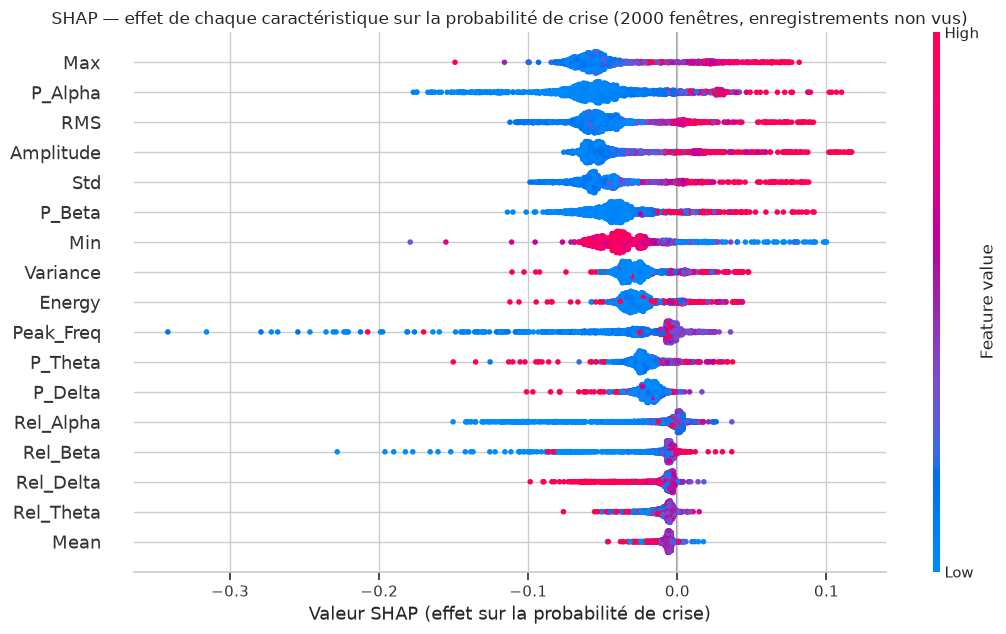

Échantillon : 2000 fenêtres dont 81 en crise


,Moyenne |SHAP|,Moyenne |SHAP| (fenêtres en crise)
Max,0.0518,0.0511
P_Alpha,0.0513,0.0331
RMS,0.0489,0.0460
Amplitude,0.0485,0.0644
Std,0.0478,0.0446
P_Beta,0.0412,0.0341
Min,0.0378,0.0447
Variance,0.0279,0.0210
Energy,0.0267,0.0195
Peak_Freq,0.0239,0.0216


In [60]:
try:
    import shap
    SHAP_OK = os.environ.get("DM_SANS_SHAP") != "1"
except ImportError:
    SHAP_OK = False
print("SHAP disponible :", SHAP_OK, "" if SHAP_OK else "→ repli sur l'importance par permutation et les dépendances partielles")

RF_REF = MODELS["Random Forest"]
N_SHAP = 2000                            # taille de l'échantillon stratifié
SHAP_NPZ = CACHE_DIR / "shap_global.npz"


def shap_crise(model, Xraw):
    # Valeurs SHAP de la classe « crise » pour un pipeline StandardScaler + RandomForest (en probabilité)
    expl = shap.TreeExplainer(model[-1])
    sv = expl.shap_values(model[:-1].transform(Xraw), check_additivity=False)
    sv = sv[1] if isinstance(sv, list) else sv[..., 1]       # selon la version de shap : liste ou tableau 3D
    return sv, float(np.ravel(expl.expected_value)[1])


if SHAP_OK:
    if SHAP_NPZ.exists():
        z_ = np.load(SHAP_NPZ)
        shap_vals, shap_base, oof_pred, idx_ech = z_["shap_vals"], z_["shap_base"], z_["oof_pred"], z_["idx_ech"]
        progres("Valeurs SHAP relues depuis le cache")
    else:
        # Échantillon stratifié : même proportion de fenêtres en crise que dans le jeu complet
        idx_ech, _ = train_test_split(np.arange(len(y)), train_size=N_SHAP, stratify=y, random_state=42)
        dans_ech = np.zeros(len(y), bool); dans_ech[idx_ech] = True
        shap_vals = np.full((len(y), len(FEATURES)), np.nan)
        shap_base = np.full(len(y), np.nan)
        oof_pred = np.zeros(len(y), int)
        for pli, (tr, te) in enumerate(GroupKFold(n_splits=n_splits).split(X, y, groups), 1):
            m = clone(RF_REF).fit(X[tr], y[tr])
            oof_pred[te] = m.predict(X[te])
            a_expliquer = te[dans_ech[te] | (oof_pred[te] == 1)]     # échantillon + toutes les fenêtres prédites « crise »
            t0 = time.perf_counter()
            shap_vals[a_expliquer], base = shap_crise(m, X[a_expliquer])
            shap_base[a_expliquer] = base
            progres(f"SHAP pli {pli}/{n_splits} : {len(a_expliquer)} fenêtres expliquées en {time.perf_counter() - t0:.0f} s")
        np.savez_compressed(SHAP_NPZ, shap_vals=shap_vals, shap_base=shap_base, oof_pred=oof_pred, idx_ech=idx_ech)

    # Importance globale : moyenne de |SHAP| sur l'échantillon stratifié
    importance_shap = pd.DataFrame({"Moyenne |SHAP|": np.abs(shap_vals[idx_ech]).mean(0),
                                    "Moyenne |SHAP| (fenêtres en crise)": np.abs(shap_vals[idx_ech][y[idx_ech] == 1]).mean(0)},
                                   index=FEATURES).sort_values("Moyenne |SHAP|", ascending=False)
    sauver_table(importance_shap, "shap_importance_globale")

    shap.summary_plot(shap_vals[idx_ech], features=pd.DataFrame(X[idx_ech], columns=FEATURES), show=False, plot_size=(11, 6.5))
    plt.title(f"SHAP — effet de chaque caractéristique sur la probabilité de crise ({len(idx_ech)} fenêtres, enregistrements non vus)")
    plt.xlabel("Valeur SHAP (effet sur la probabilité de crise)")
    plt.tight_layout(); sauver_figure("shap_global_beeswarm")
    print(f"Échantillon : {len(idx_ech)} fenêtres dont {int(y[idx_ech].sum())} en crise")
    display(importance_shap.round(4))
else:
    # Repli sans shap : importance par permutation (sur le dernier pli, enregistrements non vus) + dépendances partielles
    from sklearn.inspection import permutation_importance, PartialDependenceDisplay
    tr, te = list(GroupKFold(n_splits=n_splits).split(X, y, groups))[-1]
    m = clone(RF_REF).fit(X[tr], y[tr])
    pi = permutation_importance(m, X[te], y[te], scoring="f1", n_repeats=10, random_state=42, n_jobs=-1)
    importance_perm = pd.DataFrame({"Baisse de F1 (moyenne)": pi.importances_mean, "Écart-type": pi.importances_std},
                                   index=FEATURES).sort_values("Baisse de F1 (moyenne)", ascending=False)
    sauver_table(importance_perm, "importance_permutation")
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(importance_perm.index[::-1], importance_perm["Baisse de F1 (moyenne)"][::-1], xerr=importance_perm["Écart-type"][::-1], color=BLEU)
    ax.set(xlabel="Baisse du F1 quand la caractéristique est mélangée", title="Importance par permutation (enregistrements non vus)")
    plt.tight_layout(); sauver_figure("importance_permutation")
    top4 = [FEATURES.index(f) for f in importance_perm.index[:4]]
    fig, ax = plt.subplots(1, 4, figsize=(18, 4))
    PartialDependenceDisplay.from_estimator(m, X[te], top4, feature_names=FEATURES, ax=ax, kind="average")
    plt.tight_layout(); sauver_figure("dependances_partielles")
    display(importance_perm.round(4))

Fenêtres prédites « crise » : 781 vraies détections, 270 fausses alertes
Probabilité de base (moyenne des modèles) : 0.500


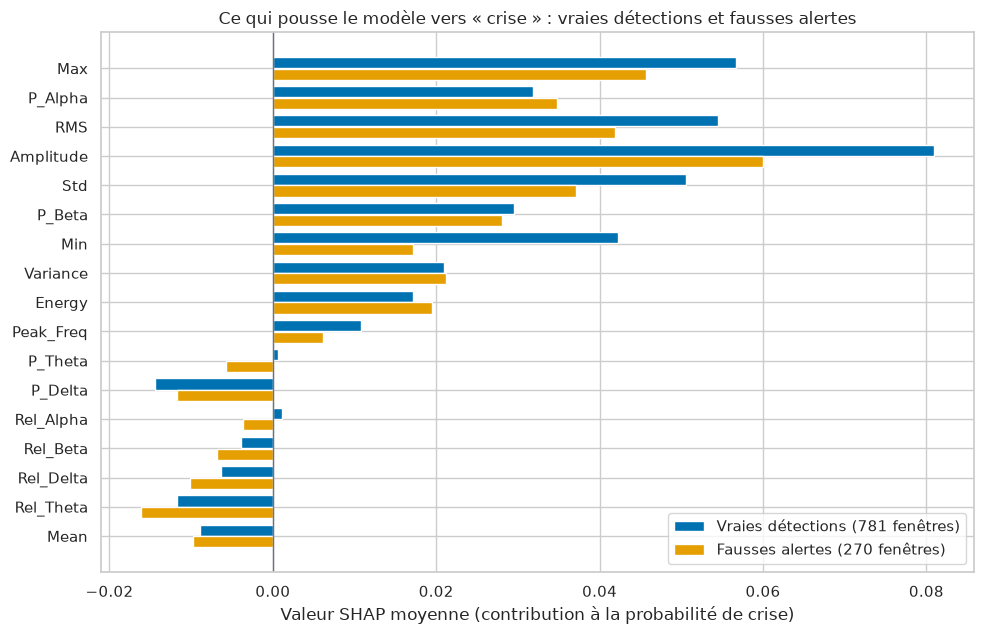

,SHAP moyen — vraies détections,SHAP moyen — fausses alertes,Valeur médiane — vraies détections,Valeur médiane — fausses alertes,Valeur médiane — fenêtres normales,Écart de SHAP (vraies − fausses)
Min,0.0423,0.0171,-3.380320e+02,-2.758947e+02,-58.9524,0.0251
Amplitude,0.0810,0.0600,6.430588e+02,5.324182e+02,117.0966,0.0210
Std,0.0506,0.0371,1.429973e+02,1.159272e+02,22.1680,0.0135
RMS,0.0545,0.0419,1.431364e+02,1.160330e+02,22.2528,0.0127
Max,0.0566,0.0457,3.101351e+02,2.549999e+02,56.8870,0.0109
P_Theta,0.0006,-0.0057,1.076398e+03,6.651041e+02,41.1028,0.0063
Rel_Alpha,0.0011,-0.0037,8.340000e-02,1.004000e-01,0.0746,0.0048
Peak_Freq,0.0108,0.0062,2.894700e+00,2.894700e+00,1.7105,0.0046
Rel_Theta,-0.0117,-0.0162,1.123000e-01,1.014000e-01,0.1791,0.0045
Rel_Delta,-0.0064,-0.0101,7.153000e-01,6.942000e-01,0.6418,0.0037


In [61]:
# Fausses alertes contre vraies détections : toutes les fenêtres prédites « crise » en validation par enregistrement
if SHAP_OK:
    vp, fp = (oof_pred == 1) & (y == 1), (oof_pred == 1) & (y == 0)
    vp_fp = pd.DataFrame({
        "SHAP moyen — vraies détections": shap_vals[vp].mean(0), "SHAP moyen — fausses alertes": shap_vals[fp].mean(0),
        "Valeur médiane — vraies détections": np.median(X[vp], axis=0), "Valeur médiane — fausses alertes": np.median(X[fp], axis=0),
        "Valeur médiane — fenêtres normales": np.median(X[(oof_pred == 0) & (y == 0)], axis=0)}, index=FEATURES)
    vp_fp["Écart de SHAP (vraies − fausses)"] = vp_fp.iloc[:, 0] - vp_fp.iloc[:, 1]
    vp_fp = vp_fp.sort_values("Écart de SHAP (vraies − fausses)", ascending=False)
    sauver_table(vp_fp, "shap_vraies_detections_vs_fausses_alertes")
    print(f"Fenêtres prédites « crise » : {vp.sum()} vraies détections, {fp.sum()} fausses alertes")
    print(f"Probabilité de base (moyenne des modèles) : {np.nanmean(shap_base):.3f}")

    ordre_f = importance_shap.index[::-1]
    pos = np.arange(len(ordre_f))
    fig, ax = plt.subplots(figsize=(10, 6.5))
    ax.barh(pos + 0.2, vp_fp.loc[ordre_f, "SHAP moyen — vraies détections"], 0.38, color=BLEU, label=f"Vraies détections ({vp.sum()} fenêtres)")
    ax.barh(pos - 0.2, vp_fp.loc[ordre_f, "SHAP moyen — fausses alertes"], 0.38, color=ORANGE, label=f"Fausses alertes ({fp.sum()} fenêtres)")
    ax.axvline(0, color=GRIS, lw=1)
    ax.set_yticks(pos); ax.set_yticklabels(ordre_f)
    ax.set(xlabel="Valeur SHAP moyenne (contribution à la probabilité de crise)",
           title="Ce qui pousse le modèle vers « crise » : vraies détections et fausses alertes")
    ax.legend(loc="lower right")
    plt.tight_layout(); sauver_figure("shap_vraies_detections_vs_fausses_alertes")
    display(vp_fp.round(4))

[21:53:49] Explication locale : Crise bien détectée (230102B-F, 62–64 s)


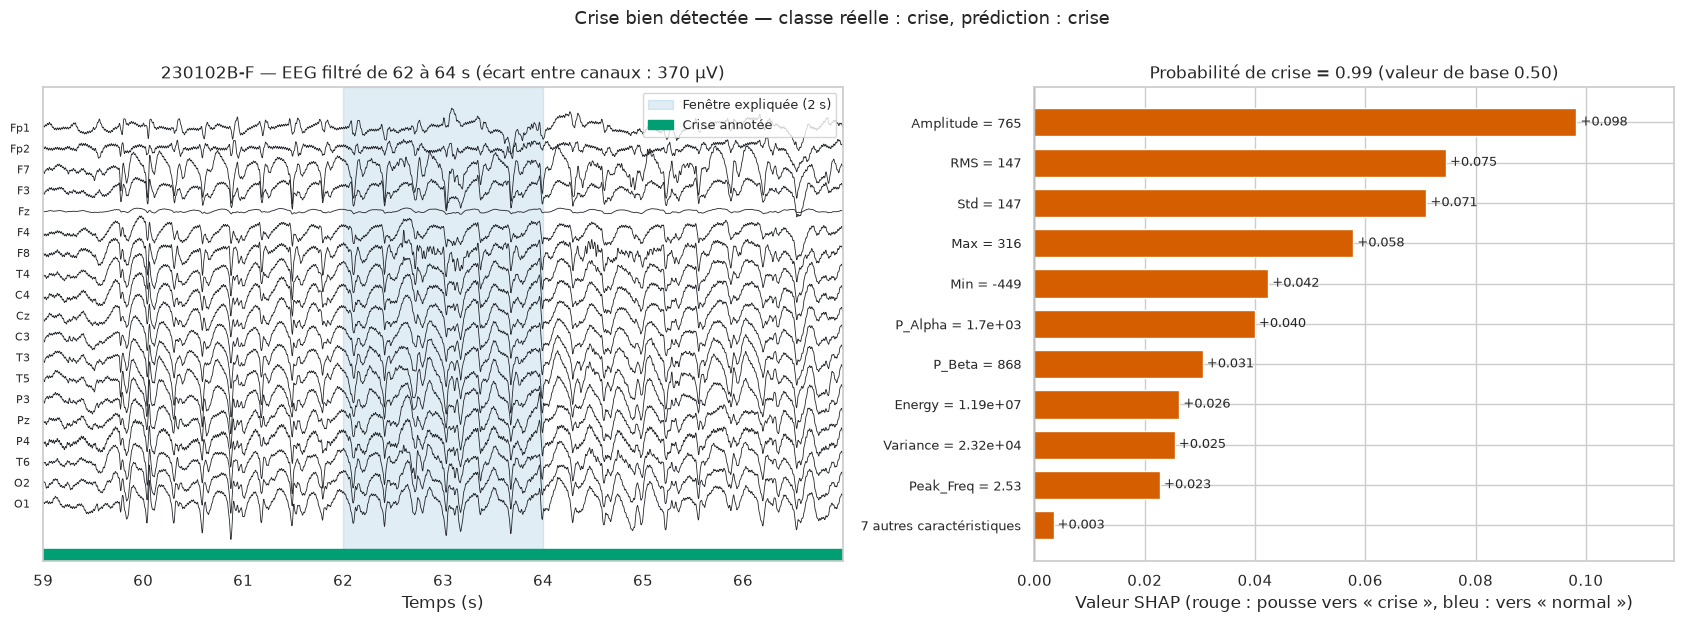

[21:53:52] Explication locale : Fausse alarme (211027B-C, 834–836 s)


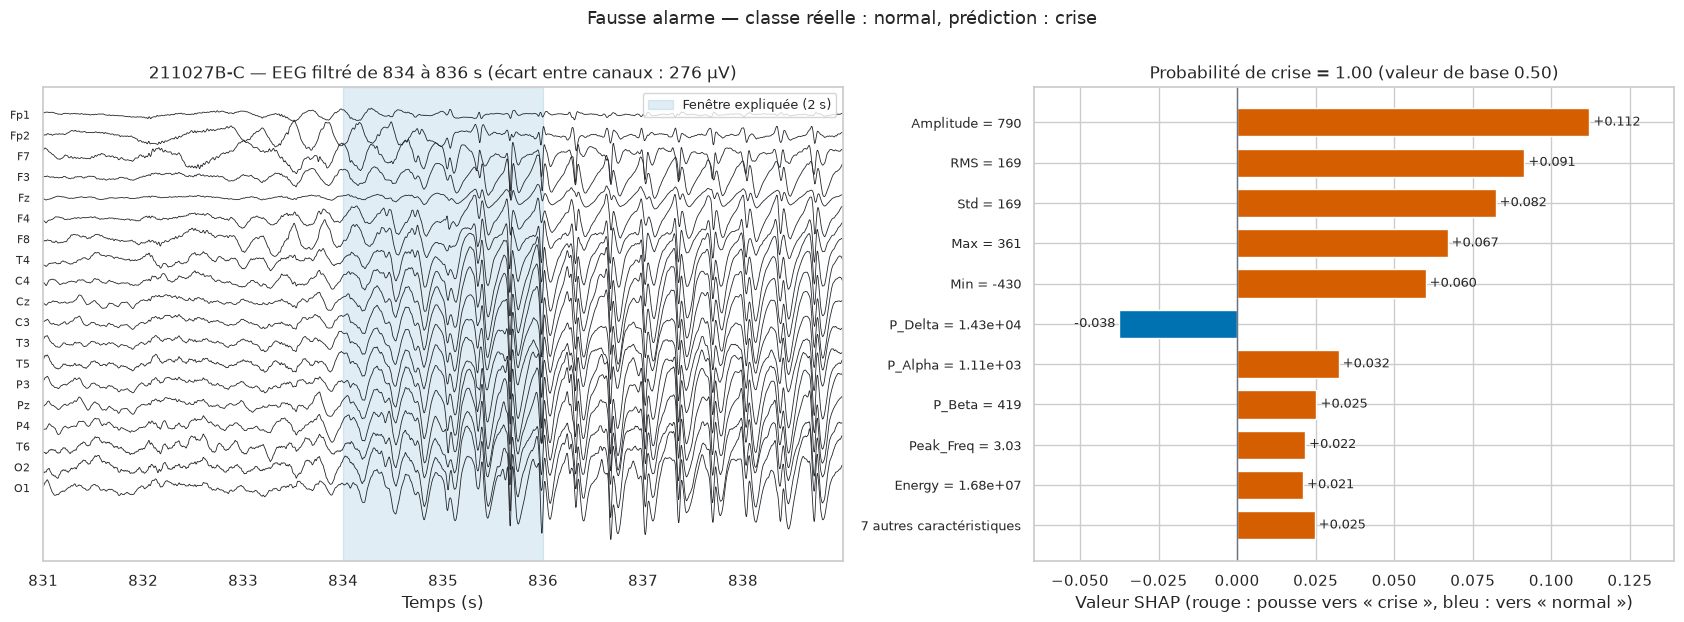

[21:53:55] Explication locale : Début de crise manqué (230515B-G, 418–420 s)


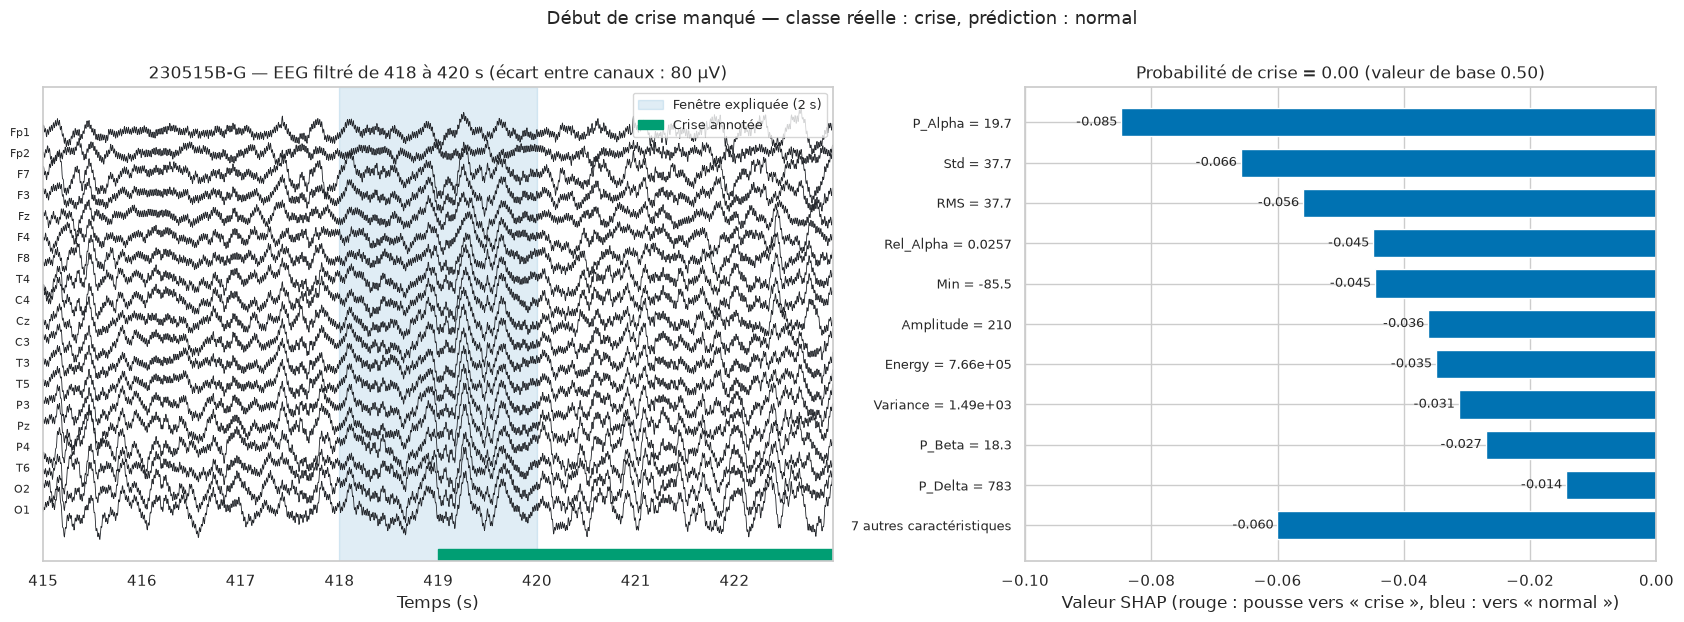

[21:53:59] Explication locale : Patient atypique (210914B-A, 358–360 s)


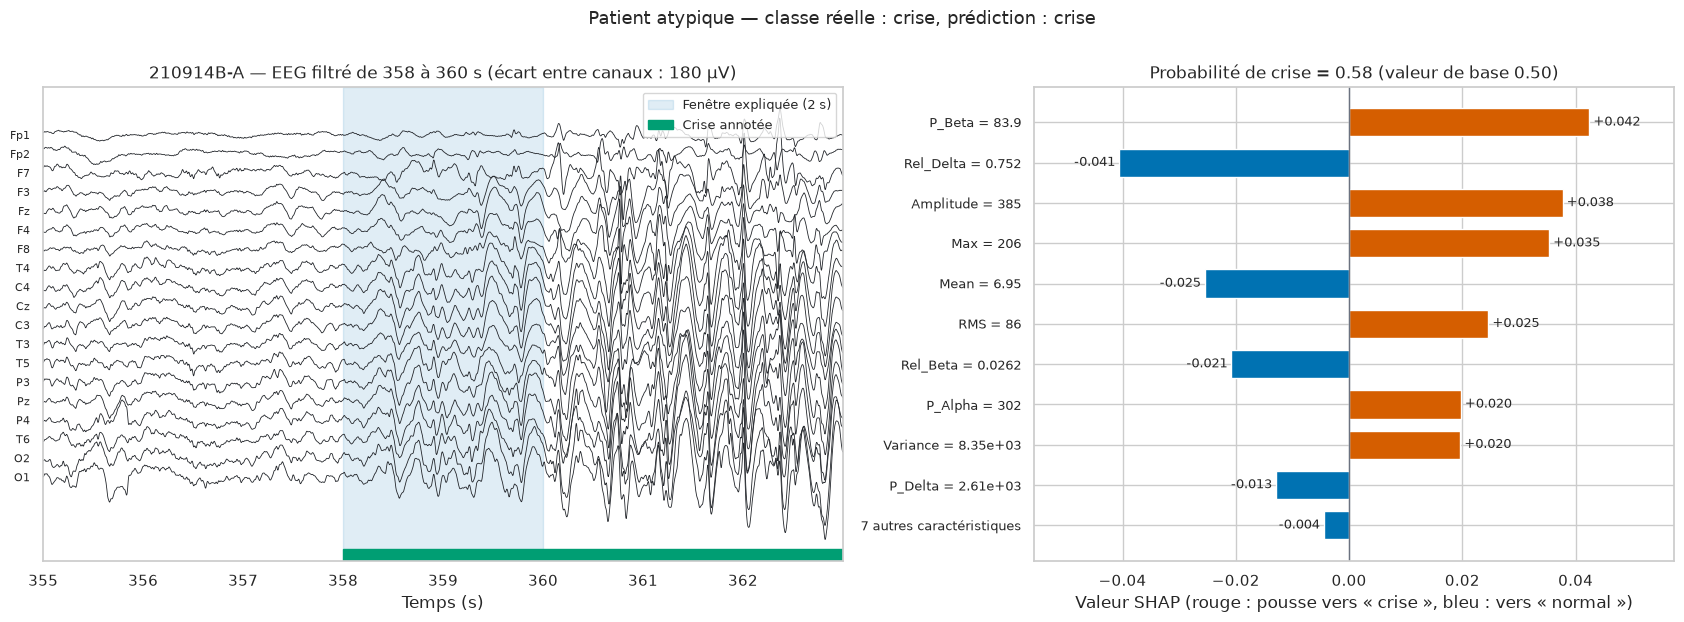

,Enregistrement,t_start,t_end,Classe réelle,Probabilité de crise,Valeur de base
Cas,,,,,,
Crise bien détectée,230102B-F,62.0,64.0,1,0.993,0.5
Fausse alarme,211027B-C,834.0,836.0,0,1.000,0.5
Début de crise manqué,230515B-G,418.0,420.0,1,0.000,0.5
Patient atypique,210914B-A,358.0,360.0,1,0.575,0.5


,Crise bien détectée,Fausse alarme,Début de crise manqué,Patient atypique
Probabilité de crise,0.993,1.000,0.000,0.575
Mean,-0.005,-0.009,-0.010,-0.025
Std,0.071,0.082,-0.066,0.008
Variance,0.025,0.016,-0.031,0.020
Min,0.042,0.060,-0.045,0.008
Max,0.058,0.067,-0.014,0.035
Amplitude,0.098,0.112,-0.036,0.038
RMS,0.075,0.091,-0.056,0.025
Energy,0.026,0.021,-0.035,0.006
P_Delta,-0.008,-0.038,-0.014,-0.013


In [62]:
# Explications locales : 4 cas tirés de la détection « un enregistrement laissé de côté » (règles de choix fixes)
def fenetres_dans(p_rec, s, e):
    return p_rec[(p_rec["t_start"] < e) & (p_rec["t_end"] > s)]


def choisir_cas():
    cas = {}
    P = pred_loro
    # 1) Crise bien détectée : dans l'enregistrement de démonstration, la fenêtre de crise la plus sûre
    g = P[(P["Recording"] == REC_DEMO) & (P["Class"] == 1) & (P["Random Forest"] == 1)]
    cas["Crise bien détectée"] = g.loc[g["Proba RF"].idxmax()]
    # 2) Fausse alarme : la fenêtre la plus sûre parmi toutes les fausses alarmes de la détection
    cand = [fenetres_dans(P[P["Recording"] == r["ID"]], r["Début détecté"], r["Fin détectée"]) for _, r in fausses_alarmes_rf.iterrows()]
    g = pd.concat(cand); g = g[(g["Class"] == 0) & (g["Random Forest"] == 1)]
    cas["Fausse alarme"] = g.loc[g["Proba RF"].idxmax()]
    # 3) Début de crise manqué : la crise détectée avec le plus grand retard, sa première fenêtre de crise non reconnue
    r = detection_rf.loc[detection_rf["Retard début (s)"].idxmax()]
    g = fenetres_dans(P[P["Recording"] == r["ID"]], r["Début (s)"], r["Fin (s)"])
    g = g[(g["Class"] == 1) & (g["Random Forest"] == 0) & (g["t_start"] < r["Début détecté"])]
    cas["Début de crise manqué"] = g.iloc[0]
    # 4) Patient aux absences atypiques : la fenêtre de crise la plus représentative (probabilité médiane)
    g = P[(P["Recording"] == PATIENT_ATYPIQUE) & (P["Class"] == 1)]
    cas["Patient atypique"] = g.loc[(g["Proba RF"] - g["Proba RF"].median()).abs().idxmin()]
    return cas


def tracer_cas(titre, w, nom_fichier):
    rec, t0, t1 = w["Recording"], w["t_start"], w["t_end"]
    # Modèle entraîné sans cet enregistrement, puis valeurs SHAP de la fenêtre
    te = (dataset["Recording"] == rec).values
    m = clone(RF_REF).fit(X[~te], y[~te])
    x_w = dataset.loc[[w.name], FEATURES].values
    sv, base = shap_crise(m, x_w)
    sv, proba = sv[0], m.predict_proba(x_w)[0, 1]
    # Extrait d'EEG : la fenêtre et 3 s de contexte de chaque côté (signal filtré comme pour le modèle)
    d, fs = load_eeg(FICHIER_DE[rec])
    chans = [c for c in d.columns if c.startswith("EEG")]
    a, b = max(0, int((t0 - 3) * fs)), min(len(d), int((t1 + 3) * fs))
    Xf = d[chans].values.astype(np.float64)
    seg = bandpass(Xf - np.median(Xf, axis=0), fs)[a:b]
    t = np.arange(a, b) / fs
    del d, Xf

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6.2), gridspec_kw={"width_ratios": [1.25, 1]})
    pas = 4 * np.median(np.abs(seg - np.median(seg, axis=0)))    # écart vertical entre canaux
    pas = max(pas, np.percentile(np.abs(seg), 99) / 2.5)
    for j, c in enumerate(chans):
        ax1.plot(t, seg[:, j] - j * pas, color="#23262B", lw=0.6)
    ax1.axvspan(t0, t1, color=BLEU, alpha=0.12, label="Fenêtre expliquée (2 s)")
    for s, e in crises_reelles(rec):
        if s < t[-1] and e > t[0]:
            ax1.axvspan(max(s, t[0]), min(e, t[-1]), ymin=0, ymax=0.025, color=VERT, label="Crise annotée")
    ax1.set_yticks(-np.arange(len(chans)) * pas); ax1.set_yticklabels([c.replace("EEG", "") for c in chans], fontsize=8)
    ax1.set(xlabel="Temps (s)", xlim=(t[0], t[-1]), title=f"{rec} — EEG filtré de {t0:.0f} à {t1:.0f} s (écart entre canaux : {pas:.0f} µV)")
    ax1.grid(False)
    h_, l_ = ax1.get_legend_handles_labels(); uniq = dict(zip(l_, h_))
    ax1.legend(uniq.values(), uniq.keys(), loc="upper right", fontsize=9)

    # Barres SHAP : les 10 caractéristiques les plus influentes, le reste regroupé
    o = np.argsort(-np.abs(sv))
    top, reste = o[:10], o[10:]
    vals = list(sv[top]) + [sv[reste].sum()]
    noms = [f"{FEATURES[j]} = {x_w[0, j]:.3g}" for j in top] + [f"{len(reste)} autres caractéristiques"]
    pos = np.arange(len(vals))[::-1]
    ax2.barh(pos, vals, color=[ROUGE if v > 0 else BLEU for v in vals], height=0.7)
    for p_, v in zip(pos, vals):
        ax2.text(v, p_, f" {v:+.3f} ", va="center", ha="left" if v > 0 else "right", fontsize=9)
    ax2.axvline(0, color=GRIS, lw=1)
    ax2.set_yticks(pos); ax2.set_yticklabels(noms, fontsize=9)
    ax2.margins(x=0.18)
    ax2.set(xlabel="Valeur SHAP (rouge : pousse vers « crise », bleu : vers « normal »)",
            title=f"Probabilité de crise = {proba:.2f} (valeur de base {base:.2f})")
    fig.suptitle(f"{titre} — classe réelle : {'crise' if w['Class'] == 1 else 'normal'}, prédiction : {'crise' if proba >= 0.5 else 'normal'}",
                 fontsize=13, y=1.0)
    plt.tight_layout(); sauver_figure(nom_fichier)
    ligne = {"Cas": titre, "Enregistrement": rec, "t_start": t0, "t_end": t1, "Classe réelle": int(w["Class"]),
             "Probabilité de crise": proba, "Valeur de base": base}
    ligne.update({f"SHAP {FEATURES[j]}": sv[j] for j in o[:5]})
    return ligne, pd.Series(sv, index=FEATURES, name=titre)


if SHAP_OK:
    NOMS_CAS = {"Crise bien détectée": "shap_cas_1_crise_detectee", "Fausse alarme": "shap_cas_2_fausse_alarme",
                "Début de crise manqué": "shap_cas_3_debut_de_crise_manque", "Patient atypique": "shap_cas_4_patient_atypique"}
    lignes, shap_cas = [], []
    for titre, w in choisir_cas().items():
        progres(f"Explication locale : {titre} ({w['Recording']}, {w['t_start']:.0f}–{w['t_end']:.0f} s)")
        l_, s_ = tracer_cas(titre, w, NOMS_CAS[titre])
        lignes.append({k: v for k, v in l_.items() if not k.startswith("SHAP ")}); shap_cas.append(s_)
    cas_locaux = pd.DataFrame(lignes).set_index("Cas")
    shap_cas = pd.DataFrame(shap_cas)
    shap_cas.insert(0, "Probabilité de crise", cas_locaux["Probabilité de crise"])
    sauver_table(cas_locaux, "shap_cas_locaux"); sauver_table(shap_cas.T, "shap_cas_locaux_valeurs")
    display(cas_locaux.round(3)); display(shap_cas.T.round(3))
else:
    print("Explications locales non disponibles sans shap.")

#### Interprétation

**Comment lire les valeurs.** La valeur de base est 0,50 et non 4 % : avec `class_weight="balanced_subsample"`, le modèle apprend comme si les deux classes étaient aussi fréquentes. Chaque caractéristique ajoute ou retire des points de probabilité à partir de 0,50.

**Ce qui décide d'une « crise » : la taille du signal.** Sur 2 000 fenêtres d'enregistrements non vus (dont 81 en crise), les caractéristiques les plus influentes sont Max (0,052), P_Alpha (0,051), RMS (0,049), Amplitude (0,049) et Std (0,048), puis P_Beta (0,041) et Min (0,038). Ces cinq premières pèsent à elles seules la moitié de l'effet total (0,248 sur 0,499). La fréquence dominante compte peu (0,024) et les puissances relatives encore moins (0,014 au plus). Le graphique en essaim montre le sens : des valeurs élevées d'amplitude et de puissance poussent vers « crise ». Autrement dit, le modèle reconnaît d'abord une fenêtre de grande amplitude sur l'ensemble des canaux, bien plus qu'un rythme à 3 Hz. Comme Std, RMS, Variance et Énergie mesurent presque la même chose (partie VII), elles se partagent le crédit : c'est le groupe « amplitude » qu'il faut lire, pas le rang exact de chacune.

**Fausses alertes et vraies détections se ressemblent.** En validation par enregistrement, 1 051 fenêtres sont prédites « crise » : 781 vraies détections et 270 fausses alertes. Les fausses alertes ont le même profil que les vraies crises, en un peu moins marqué : amplitude médiane de 532 µV contre 643 µV (117 µV pour une fenêtre normale), écart-type de 116 contre 143 (22 pour une fenêtre normale), et la même fréquence dominante médiane (2,89 Hz dans les deux cas, contre 1,71 Hz pour les fenêtres normales). Les contributions SHAP sont simplement plus faibles : +0,060 contre +0,081 pour l'amplitude, +0,017 contre +0,042 pour Min. Aucune caractéristique ne « signe » une fausse alerte : avec des mesures moyennées sur les 19 canaux, une bouffée ample et rythmée ressemble à une crise. Ce profil est aussi celui qu'on attend de fenêtres situées juste au bord d'une crise ; leur part parmi ces 270 fenêtres n'a pas été mesurée.

**Les quatre cas.**
- **Crise bien détectée** (230102B-F, 62–64 s, probabilité 0,99) : Amplitude (+0,098), RMS (+0,075) et Std (+0,071) poussent ensemble ; le tracé montre des pointes-ondes amples sur tous les canaux.
- **Fausse alarme** (211027B-C, 834–836 s, probabilité 1,00) : exactement les mêmes caractéristiques, avec des contributions encore plus fortes (Amplitude +0,112, RMS +0,091, Std +0,082). Pour le modèle, cette fenêtre est une crise ; seul le tracé permet de dire s'il s'agit d'un artefact ou d'une décharge non annotée.
- **Début de crise manqué** (230515B-G, 418–420 s, probabilité 0,00) : la crise est annotée à partir de 419 s, la fenêtre n'est donc en crise qu'à moitié et le signal n'a pas encore pris d'ampleur (écart-type 37,7, amplitude 210 µV). Toutes les caractéristiques poussent vers « normal » (P_Alpha −0,085, Std −0,066, RMS −0,056). C'est le mécanisme du retard à la détection.
- **Patient atypique** (210914B-A, 358–360 s, probabilité 0,58) : le modèle hésite. P_Beta (+0,042) et Amplitude (+0,038) poussent vers « crise », mais Rel_Delta (−0,041) et Mean (−0,025) tirent dans l'autre sens. La fenêtre a été choisie comme représentative de ses crises (probabilité médiane) : ses crises sont reconnues de justesse.

**Limites.** SHAP explique le modèle, pas la physiologie : une caractéristique influente n'est pas forcément un marqueur de crise. Quatre cas ne font pas une statistique ; ils ont été choisis par des règles fixes (indiquées dans le code) pour illustrer, pas pour prouver.

### 4. Tests statistiques entre modèles

Les cinq modèles (Random Forest, Extra Trees, LightGBM, XGBoost, KNN) sont comparés sur les prédictions « un enregistrement laissé de côté ». Pour chaque enregistrement on calcule le F1 par fenêtre, la sensibilité par crise et le nombre de fausses alarmes par heure.

- **Test de Wilcoxon des rangs signés** (bilatéral) de chaque modèle contre le Random Forest, sur les valeurs appariées par enregistrement, avec **correction de Holm** sur les quatre comparaisons de chaque métrique. Taille d'effet : médiane des différences.
- **Intervalles de confiance à 95 % par bootstrap** : 1 000 rééchantillonnages des **enregistrements** (pas des fenêtres). F1 : moyenne des F1 par enregistrement. Sensibilité et fausses alarmes par heure : valeurs cumulées (crises détectées / crises, fausses alarmes / heures), comme dans le reste du notebook.

In [63]:
# Métriques par enregistrement et par modèle
lignes = []
for rec in RECS_RECH:
    p_rec = pred_loro[pred_loro["Recording"] == rec]
    vraies = crises_reelles(rec)
    for name in MODELES_LORO:
        m = match_events(vraies, evenements(p_rec, name))
        n_det, n_fa = int((m["Résultat"] == "Détectée").sum()), int((m["Résultat"] == "Fausse alarme").sum())
        lignes.append({"Enregistrement": rec, "Modèle": name, "F1 fenêtres": f1_score(p_rec["Class"], p_rec[name], zero_division=0),
                       "Crises": len(vraies), "Détectées": n_det, "Sensibilité crises": n_det / len(vraies),
                       "Fausses alarmes": n_fa, "Heures": dur[rec] / 3600, "Fausses alarmes / h": n_fa / (dur[rec] / 3600)})
par_rec = pd.DataFrame(lignes)
sauver_table(par_rec, "tests_metriques_par_enregistrement", index=False)
METRIQUES = ["F1 fenêtres", "Sensibilité crises", "Fausses alarmes / h"]
NOMS_MODELES = list(MODELES_LORO)


def holm(p):
    # Correction de Holm : p ajustées, dans l'ordre d'origine (les valeurs manquantes restent manquantes)
    p = np.asarray(p, float); adj = np.full(len(p), np.nan)
    ok = np.where(~np.isnan(p))[0]
    courant = 0.0
    for rang, j in enumerate(ok[np.argsort(p[ok])]):
        courant = max(courant, min(1.0, (len(ok) - rang) * p[j]))
        adj[j] = courant
    return adj


# Wilcoxon apparié de chaque modèle contre le Random Forest
lignes = []
for met in METRIQUES:
    large = par_rec.pivot(index="Enregistrement", columns="Modèle", values=met)
    bloc = []
    for name in NOMS_MODELES[1:]:
        d_ = (large[name] - large["Random Forest"]).values
        p = stats.wilcoxon(d_).pvalue if np.any(d_ != 0) else np.nan      # test impossible si aucune différence
        bloc.append({"Métrique": met, "Modèle (contre Random Forest)": name, "Médiane des différences": np.median(d_),
                     "Moyenne des différences": d_.mean(), "Enregistrements où sa valeur est plus élevée": int((d_ > 0).sum()),
                     "Égalités": int((d_ == 0).sum()), "Enregistrements où sa valeur est plus basse": int((d_ < 0).sum()), "p (Wilcoxon)": p})
    for b_, pa in zip(bloc, holm([b_["p (Wilcoxon)"] for b_ in bloc])):
        b_["p ajustée (Holm)"] = pa
        b_["Significatif (5 %)"] = "oui" if pa < 0.05 else "non"
    lignes += bloc
tests_modeles = pd.DataFrame(lignes).set_index(["Métrique", "Modèle (contre Random Forest)"])
sauver_table(tests_modeles, "tests_wilcoxon_holm")
tests_modeles.round(4)

Médiane des différences  Moyenne des différences  Enregistrements où sa valeur est plus élevée  Égalités  \
Métrique            Modèle (contre Random Forest)                                                                                                             
F1 fenêtres         Extra Trees                                     0.0263                   0.0434                                            12         0   
                    LightGBM                                        0.0004                   0.0069                                            10         1   
                    XGBoost                                        -0.0007                   0.0010                                             8         1   
                    KNN                                            -0.0658                  -0.0652                                             2         2   
Sensibilité crises  Extra Trees                                     0.0000                   0.0263                                             1        18   
                    LightGBM                                        0.0000                   0.0263                                             1        18   
                    XGBoost                                         0.0000                   0.0263                                             1        18   
                    KNN                                             0.0000                  -0.0239                                             0        18   
Fausses alarmes / h Extra Trees                                     0.0000                   2.0591                                             6        13   
                    LightGBM                                        2.7864                   4.2484                                            11         7   
                    XGBoost                                         3.0691                   5.5896                                            12         6   
                    KNN                                             0.0000                   1.7433                                             6        11   

                                                   Enregistrements où sa valeur est plus basse  p (Wilcoxon)  p ajustée (Holm) Significatif (5 %)  
Métrique            Modèle (contre Random Forest)                                                                                                  
F1 fenêtres         Extra Trees                                                              7        0.0361            0.1082                non  
                    LightGBM                                                                 8        0.9479            1.0000                non  
                    XGBoost                                                                 10        0.8446            1.0000                non  
                    KNN                                                                     15        0.0019            0.0077                oui  
Sensibilité crises  Extra Trees                                                              0        0.3173            1.0000                non  
                    LightGBM                                                                 0        0.3173            1.0000                non  
                    XGBoost                                                                  0        0.3173            1.0000                non  
                    KNN                                                                      1        0.3173            1.0000                non  
Fausses alarmes / h Extra Trees                                                              0        0.0277            0.0554                non  
                    LightGBM                                                                 1        0.0037            0.0111                oui  
                    XGBoost                     

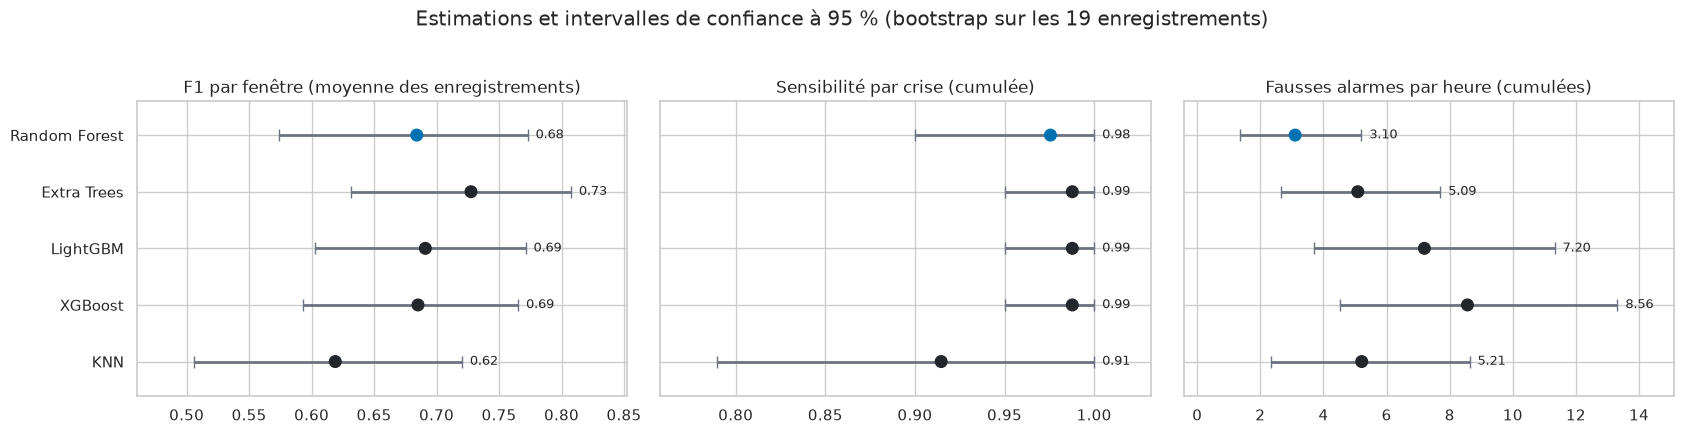

Métrique      F1 fenêtres                    Fausses alarmes / h                    Sensibilité crises                   
               Estimation IC95 bas IC95 haut          Estimation IC95 bas IC95 haut         Estimation IC95 bas IC95 haut
Modèle                                                                                                                   
Random Forest       0.684    0.574     0.773               3.102    1.358     5.200              0.976    0.900       1.0
Extra Trees         0.728    0.632     0.807               5.087    2.668     7.700              0.988    0.950       1.0
LightGBM            0.691    0.603     0.771               7.197    3.699    11.322              0.988    0.950       1.0
XGBoost             0.685    0.593     0.765               8.562    4.524    13.313              0.988    0.950       1.0
KNN                 0.619    0.506     0.720               5.211    2.343     8.628              0.915    0.789       1.0

,Différence Extra Trees − Random Forest,IC95 bas,IC95 haut
F1 fenêtres,0.043,0.012,0.078
Sensibilité crises,0.012,0.000,0.050
Fausses alarmes / h,1.985,0.694,3.485


In [64]:
# Intervalles de confiance à 95 % par bootstrap sur les enregistrements (1 000 tirages, les mêmes pour tous les modèles)
N_BOOT = 1000
rng = np.random.default_rng(42)
tirages = rng.integers(0, len(RECS_RECH), size=(N_BOOT, len(RECS_RECH)))


def resume(t):
    # t : tableau (enregistrements × colonnes) pour un modèle ; retourne les 3 métriques agrégées
    return (t[:, 0].mean(), t[:, 1].sum() / t[:, 2].sum(), t[:, 3].sum() / t[:, 4].sum())


lignes, boot = [], {}
for name in NOMS_MODELES:
    t = par_rec[par_rec["Modèle"] == name].set_index("Enregistrement").loc[RECS_RECH,
        ["F1 fenêtres", "Détectées", "Crises", "Fausses alarmes", "Heures"]].values
    boot[name] = np.array([resume(t[ix]) for ix in tirages])
    for j, met in enumerate(METRIQUES):
        bas_, haut_ = np.percentile(boot[name][:, j], [2.5, 97.5])
        lignes.append({"Modèle": name, "Métrique": met, "Estimation": resume(t)[j], "IC95 bas": bas_, "IC95 haut": haut_})
ic_modeles = pd.DataFrame(lignes)
sauver_table(ic_modeles, "tests_bootstrap_ic95", index=False)

# Différence Extra Trees − Random Forest, bootstrap apparié (mêmes enregistrements tirés pour les deux)
diff_et_rf = boot["Extra Trees"] - boot["Random Forest"]
ic_diff = pd.DataFrame({"Différence Extra Trees − Random Forest": ic_modeles[ic_modeles["Modèle"] == "Extra Trees"]["Estimation"].values
                        - ic_modeles[ic_modeles["Modèle"] == "Random Forest"]["Estimation"].values,
                        "IC95 bas": np.percentile(diff_et_rf, 2.5, axis=0), "IC95 haut": np.percentile(diff_et_rf, 97.5, axis=0)}, index=METRIQUES)
sauver_table(ic_diff, "tests_bootstrap_extra_trees_vs_random_forest")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
titres = ["F1 par fenêtre (moyenne des enregistrements)", "Sensibilité par crise (cumulée)", "Fausses alarmes par heure (cumulées)"]
for ax, met, titre in zip(axes, METRIQUES, titres):
    g = ic_modeles[ic_modeles["Métrique"] == met].set_index("Modèle").loc[NOMS_MODELES[::-1]]
    pos = np.arange(len(g))
    ax.errorbar(g["Estimation"], pos, xerr=[g["Estimation"] - g["IC95 bas"], g["IC95 haut"] - g["Estimation"]], fmt="none",
                ecolor=GRIS, elinewidth=2, capsize=4)
    ax.scatter(g["Estimation"], pos, s=70, color=[BLEU if n_ == "Random Forest" else "#23262B" for n_ in g.index], zorder=3)
    for p_, (v, h_) in enumerate(zip(g["Estimation"], g["IC95 haut"])):
        ax.text(h_, p_, f"  {v:.2f}", va="center", fontsize=9)
    ax.set_yticks(pos); ax.set_yticklabels(g.index if ax is axes[0] else [])
    ax.set(title=titre, ylim=(-0.6, len(g) - 0.4)); ax.margins(x=0.15)
plt.suptitle("Estimations et intervalles de confiance à 95 % (bootstrap sur les 19 enregistrements)", y=1.03)
plt.tight_layout(); sauver_figure("tests_modeles_ic95")
display(ic_modeles.pivot(index="Modèle", columns="Métrique", values=["Estimation", "IC95 bas", "IC95 haut"]).swaplevel(axis=1)
        .sort_index(axis=1).loc[NOMS_MODELES].round(3))
ic_diff.round(3)

#### Interprétation

**Extra Trees contre Random Forest : une tendance, pas une différence établie.**
- *F1 par fenêtre.* Extra Trees fait mieux sur 12 enregistrements et moins bien sur 7 (différence médiane +0,026 ; F1 moyen par enregistrement 0,728 contre 0,684). Le test de Wilcoxon donne p = 0,036, mais p = 0,108 après correction de Holm : **non significatif au seuil de 5 %**. Le bootstrap apparié va dans le même sens que le test brut (différence +0,043, intervalle à 95 % de +0,012 à +0,078, qui exclut zéro), sans correction pour les comparaisons multiples.
- *Fausses alarmes.* Extra Trees en produit plus sur 6 enregistrements et jamais moins : +1,99 par heure au total (intervalle de +0,69 à +3,48). Là aussi, p = 0,028 puis 0,055 après correction : à la limite, non significatif.
- *Sensibilité par crise.* Les deux modèles ne diffèrent que sur un seul enregistrement (p = 0,32) : aucune conclusion possible.

**Les autres modèles.** Le KNN a un F1 significativement plus bas que le Random Forest (p ajustée 0,008 ; 0,619 contre 0,684). LightGBM et XGBoost ont un F1 équivalent (0,691 et 0,685) mais significativement plus de fausses alarmes (p ajustées 0,011 et 0,007) : 7,20 et 8,56 par heure contre 3,10. Les intervalles de confiance sont larges pour tous : le F1 du Random Forest va de 0,574 à 0,773, sa sensibilité de 0,90 à 1,00, ses fausses alarmes de 1,36 à 5,20 par heure.

**Puissance limitée.** Avec 19 enregistrements, ces tests ne peuvent détecter que des écarts importants et réguliers, et une seule crise ou un seul enregistrement atypique suffit à déplacer un résultat. Pour la sensibilité, presque tous les enregistrements sont à égalité (18 sur 19), ce qui rend le test sans objet. Une différence « non significative » ne veut donc pas dire « modèles équivalents ».

**Conclusion.** Après correction de Holm, **la différence entre Extra Trees et Random Forest n'est significative sur aucune des trois mesures**. Les données suggèrent un compromis cohérent — un F1 un peu meilleur contre davantage de fausses alarmes — mais il faudrait plus d'enregistrements pour l'affirmer. Rien ne justifie de remplacer le Random Forest comme modèle de référence.

### 5. Courbe d'apprentissage : combien de patients faut-il ?

On répète 15 fois : 4 enregistrements annotés sont tirés au hasard comme jeu de test ; parmi les 15 restants, le Random Forest est entraîné sur n enregistrements tirés au hasard, pour n = 3, 6, 9, 12 et 15 (les n premiers d'un même ordre aléatoire, donc des ensembles emboîtés). On mesure sur les 4 enregistrements de test le F1 par fenêtre et la sensibilité par crise (même post-traitement que `detect()`), et le F1 sur les données d'entraînement pour voir l'écart entre apprentissage et test.

[21:54:09] Courbe d'apprentissage : répétition 1/15 (test : 230224B-B, 220106A-A, 230519A-E, 211027B-C)


[21:54:15] Courbe d'apprentissage : répétition 2/15 (test : 230718A-A, 211104B-D, 220106A-A, 211027B-C)


[21:54:20] Courbe d'apprentissage : répétition 3/15 (test : 220121B-D, 211027B-C, 210928B-B, 230105B-H)


[21:54:27] Courbe d'apprentissage : répétition 4/15 (test : 210928B-B, 230519A-E, 210427B-C, 230718A-A)


[21:54:33] Courbe d'apprentissage : répétition 5/15 (test : 220121B-D, 230224B-B, 210406A-F, 220106A-A)


[21:54:39] Courbe d'apprentissage : répétition 6/15 (test : 210427B-C, 210504B-C, 220106A-A, 190304A-E)


... (5 outputs left out)

[21:55:17] Courbe d'apprentissage : répétition 12/15 (test : 220106A-A, 230105B-H, 230515B-G, 230210B-D)


[21:55:23] Courbe d'apprentissage : répétition 13/15 (test : 211027B-C, 190304A-E, 230224B-B, 210504B-C)


[21:55:29] Courbe d'apprentissage : répétition 14/15 (test : 210406A-F, 230224B-B, 211027B-C, 230718A-A)


[21:55:35] Courbe d'apprentissage : répétition 15/15 (test : 190304A-E, 230515B-G, 230102B-F, 211027B-C)


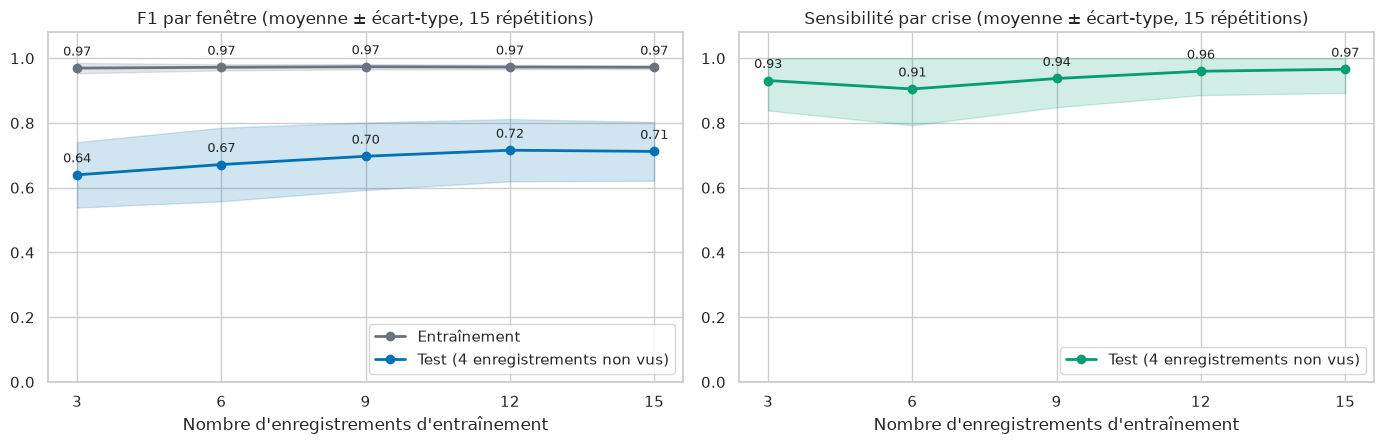

F1 test, de 12 à 15 enregistrements : -0.004 en moyenne, amélioration dans 7 répétitions sur 15
F1 test, de 3 à 15 enregistrements  : +0.072 en moyenne


F1 test        F1 entraînement        Sensibilité crises        Fausses alarmes / h        Fenêtres de crise à l'entraînement         
      mean    std            mean    std               mean    std                mean    std                               mean      std
n                                                                                                                                        
3    0.640  0.101           0.970  0.016              0.931  0.092               5.468  3.530                            203.933   98.155
6    0.672  0.114           0.972  0.009              0.905  0.112               3.545  2.446                            364.067  109.269
9    0.697  0.104           0.974  0.008              0.937  0.089               3.530  2.156                            578.000  112.575
12   0.716  0.096           0.973  0.007              0.960  0.074               3.584  2.112                            770.000   74.782
15   0.712  0.091           0.972  0.005              0.966  0.073               3.262  1.701                            940.667   64.195

In [65]:
N_REPETITIONS, N_TEST, TAILLES = 15, 4, [3, 6, 9, 12, 15]
COURBE_CSV = CACHE_DIR / "courbe_apprentissage_brut.csv"

if COURBE_CSV.exists():
    courbe = pd.read_csv(COURBE_CSV)
    progres("Courbe d'apprentissage relue depuis le cache")
else:
    rng = np.random.default_rng(42)
    rec_de = dataset["Recording"].values
    lignes = []
    for rep in range(1, N_REPETITIONS + 1):
        melange = rng.permutation(RECS_RECH)
        test, reste = list(melange[:N_TEST]), list(melange[N_TEST:])
        m_test = np.isin(rec_de, test)
        for n in TAILLES:
            m_train = np.isin(rec_de, reste[:n])
            model = clone(RF_REF).fit(X[m_train], y[m_train])
            p_test = dataset.loc[m_test, ["Recording", "t_start", "t_end", "Class"]].copy()
            p_test["pred"] = model.predict(X[m_test])
            n_det = n_tot = n_fa = 0
            for rec in test:                                 # sensibilité par crise sur les enregistrements de test
                m = match_events(crises_reelles(rec), evenements(p_test[p_test["Recording"] == rec], "pred"))
                n_det += int((m["Résultat"] == "Détectée").sum()); n_tot += len(crises_reelles(rec))
                n_fa += int((m["Résultat"] == "Fausse alarme").sum())
            lignes.append({"Répétition": rep, "n": n, "F1 test": f1_score(p_test["Class"], p_test["pred"], zero_division=0),
                           "F1 entraînement": f1_score(y[m_train], model.predict(X[m_train]), zero_division=0),
                           "Sensibilité crises": n_det / n_tot, "Crises de test": n_tot,
                           "Fausses alarmes / h": n_fa / (sum(dur[r_] for r_ in test) / 3600),
                           "Fenêtres de crise à l'entraînement": int(y[m_train].sum())})
        progres(f"Courbe d'apprentissage : répétition {rep}/{N_REPETITIONS} (test : {', '.join(test)})")
    courbe = pd.DataFrame(lignes)
    courbe.to_csv(COURBE_CSV, index=False)

courbe_resume = courbe.groupby("n")[["F1 test", "F1 entraînement", "Sensibilité crises", "Fausses alarmes / h",
                                     "Fenêtres de crise à l'entraînement"]].agg(["mean", "std"])
sauver_table(courbe, "courbe_apprentissage_repetitions", index=False)
sauver_table(courbe_resume, "courbe_apprentissage_resume")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, series, titre in [(axes[0], [("F1 entraînement", GRIS, "Entraînement"), ("F1 test", BLEU, "Test (4 enregistrements non vus)")], "F1 par fenêtre"),
                          (axes[1], [("Sensibilité crises", VERT, "Test (4 enregistrements non vus)")], "Sensibilité par crise")]:
    for col, couleur, etiquette in series:
        mo, sd = courbe_resume[(col, "mean")], courbe_resume[(col, "std")]
        ax.fill_between(TAILLES, mo - sd, np.minimum(mo + sd, 1.0), color=couleur, alpha=0.18)
        ax.plot(TAILLES, mo, marker="o", color=couleur, lw=2, label=etiquette)
        for n_, v in zip(TAILLES, mo):
            ax.annotate(f"{v:.2f}", (n_, v), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
    ax.set(xlabel="Nombre d'enregistrements d'entraînement", xticks=TAILLES, ylim=(0, 1.08), title=f"{titre} (moyenne ± écart-type, {N_REPETITIONS} répétitions)")
    ax.legend(loc="lower right")
plt.tight_layout(); sauver_figure("courbe_apprentissage")

# Gain apporté par les derniers enregistrements ajoutés (12 → 15), répétition par répétition
large = courbe.pivot(index="Répétition", columns="n", values="F1 test")
print(f"F1 test, de 12 à 15 enregistrements : {(large[15] - large[12]).mean():+.3f} en moyenne, "
      f"amélioration dans {(large[15] > large[12]).sum()} répétitions sur {N_REPETITIONS}")
print(f"F1 test, de 3 à 15 enregistrements  : {(large[15] - large[3]).mean():+.3f} en moyenne")
courbe_resume.round(3)

#### Interprétation

**Le F1 plafonne vers 12 enregistrements.** Sur les enregistrements de test, le F1 moyen passe de 0,640 avec 3 enregistrements d'entraînement à 0,672 (6), 0,697 (9), 0,716 (12) puis 0,712 (15). Le gain total est de +0,072, obtenu presque entièrement avant 12 ; de 12 à 15 enregistrements la variation moyenne est de −0,004, avec une amélioration dans 7 répétitions sur 15 seulement. L'écart-type entre répétitions (0,09 à 0,11) est plus grand que ces dernières variations : selon les 4 enregistrements tirés pour le test, le score change davantage qu'en ajoutant des patients.

**Un écart entraînement / test qui ne se referme pas.** Le F1 sur les données d'entraînement reste à 0,97 quel que soit n, soit 0,26 au-dessus du test à n = 15. Le modèle colle aux patients qu'il a vus, et ce qui manque sur un nouveau patient n'est pas comblé par quelques enregistrements du même genre : c'est la variabilité entre patients qui limite, pas la quantité de fenêtres.

**Au niveau des crises.** La sensibilité monte légèrement (0,931 à n = 3, 0,905 à 6, 0,937 à 9, 0,960 à 12, 0,966 à 15), mais avec un écart-type de 0,07 à 0,11 et seulement 9 à 23 crises par jeu de test, cette hausse n'est pas distinguable du bruit. L'effet le plus net concerne les fausses alarmes, qui baissent de 5,5 à 3,5 par heure entre 3 et 6 enregistrements, puis restent stables (3,3 à n = 15).

**Conclusion.** Avec ces 17 caractéristiques et ce Random Forest, ajouter des patients **du même profil** n'apporterait probablement plus grand-chose au F1 par fenêtre : on est sur un plateau. En revanche, la courbe ne dit rien des profils rares — un seul adulte, un seul patient atypique, et les deux seules crises manquées sont celles de l'adulte : c'est là que de nouveaux patients seraient utiles, de même que de nouvelles caractéristiques (par canal, synchronie) pour réduire l'écart avec l'entraînement.

**Limites.** Seulement 19 enregistrements : les 15 jeux de test se recouvrent, les répétitions ne sont donc pas indépendantes, et la courbe s'arrête à 15, sans indication directe sur ce qui se passerait avec 50 ou 100 patients.

In [66]:
# Bilan de la section
progres(f"Section terminée en {time.perf_counter() - T0_RECH:.0f} s")
print(f"\n{len(FIGURES_PRODUITES)} figures dans {FIG_DIR}/ :")
for f_ in FIGURES_PRODUITES:
    print("  -", f_)
print(f"\nTableaux CSV dans {RECH_DIR}/ :")
for f_ in sorted(p.name for p in RECH_DIR.glob("*.csv") if p.name.startswith(("frequence_", "typologie_", "shap_", "importance_", "tests_", "courbe_"))):
    print("  -", f_)

[21:55:36] Section terminée en 378 s



13 figures dans resultats_local/figures/ :
  - frequence_evolution_moyenne.png
  - frequence_patients_atypique_adulte.png
  - typologie_silhouette.png
  - typologie_dendrogramme.png
  - typologie_acp.png
  - shap_global_beeswarm.png
  - shap_vraies_detections_vs_fausses_alertes.png
  - shap_cas_1_crise_detectee.png
  - shap_cas_2_fausse_alarme.png
  - shap_cas_3_debut_de_crise_manque.png
  - shap_cas_4_patient_atypique.png
  - tests_modeles_ic95.png
  - courbe_apprentissage.png

Tableaux CSV dans resultats_local/ :
  - courbe_apprentissage_repetitions.csv
  - courbe_apprentissage_resume.csv
  - frequence_courbe_moyenne.csv
  - frequence_par_crise.csv
  - frequence_par_patient.csv
  - frequence_tests.csv
  - shap_cas_locaux.csv
  - shap_cas_locaux_valeurs.csv
  - shap_importance_globale.csv
  - shap_vraies_detections_vs_fausses_alertes.csv
  - tests_bootstrap_extra_trees_vs_random_forest.csv
  - tests_bootstrap_ic95.csv
  - tests_metriques_par_enregistrement.csv
  - tests_wilcoxon_holm

## Âge, syndrome et morphologie des décharges (CAE vs JAE)

**Contexte clinique.** L'épilepsie-absence de l'enfant (CAE, début vers 4–10 ans) donne typiquement des pointes-ondes généralisées régulières autour de 3 Hz. L'épilepsie-absence juvénile (JAE, début autour de la puberté) donne des décharges plus rapides (≈ 3–5,5 Hz), plus souvent fragmentées, avec des polypointes-ondes. Entre 8 et 11 ans, les deux syndromes se recouvrent.

**Notre cohorte.** 19 patients annotés, de 5 à 25 ans, dont trois de 12 ans ou plus (15, 17 et 25 ans). Le seul patient entièrement manqué par le détecteur est celui de 25 ans (191113A-D).

**Hypothèse.** Les patients plus âgés ont des décharges de morphologie différente, que le détecteur — entraîné surtout sur de jeunes enfants — capte moins bien.

**Mise en garde.** Nous n'avons **pas** le diagnostic de syndrome : l'âge au moment de l'enregistrement n'est qu'un indicateur indirect. Cette analyse est **exploratoire**.

**Méthode.** Chaque crise annotée est décrite par des mesures de morphologie, calculées sur le signal filtré (médiane retirée, 0,5–40 Hz) de deux façons : (a) la moyenne des canaux **fronto-centraux** (Fz, Cz, F3, F4, C3, C4), là où la pointe-onde est habituellement maximale — c'est le signal principal de l'analyse ; (b) la moyenne de **tous** les canaux EEG. Les comparaisons avec l'âge se font **au niveau du patient** (médiane de ses crises) pour ne pas compter plusieurs fois le même patient.

In [67]:
from scipy.signal import find_peaks

T0_SYN = time.perf_counter()             # pour mesurer la durée de la section
SYN_DIR = RECH_DIR / "syndrome"          # tableaux CSV
SYN_FIG = SYN_DIR / "figures"            # figures PNG, 150 dpi
SYN_CACHE = SYN_DIR / "cache"            # résultats intermédiaires (supprimer pour recalculer)
for d_ in (SYN_FIG, SYN_CACHE):
    d_.mkdir(parents=True, exist_ok=True)
SYN_FIGURES = []


def sauver_fig_syn(nom):
    chemin = SYN_FIG / f"{nom}.png"
    plt.savefig(chemin, dpi=150, bbox_inches="tight", facecolor="white")
    SYN_FIGURES.append(chemin.name)
    plt.show()


def sauver_csv_syn(df, nom, index=True):
    df.to_csv(SYN_DIR / f"{nom}.csv", index=index)


FRONTO_CENTRAL = ["Fz", "Cz", "F3", "F4", "C3", "C4"]
GROUPES_AGE = ["< 8 ans", "8–11 ans", "≥ 12 ans"]           # 8–11 ans : zone de recouvrement CAE / JAE
COULEUR_GROUPE = dict(zip(GROUPES_AGE, [BLEU, ORANGE, ROUGE]))


def groupe_age(a):
    return GROUPES_AGE[0] if a < 8 else GROUPES_AGE[1] if a < 12 else GROUPES_AGE[2]


# Noms des mesures de morphologie (une version « FC » fronto-centrale et une version « tous canaux »)
MESURES = {"freq": "Fréquence (Hz)", "f_debut": "Fréquence début (Hz)", "f_fin": "Fréquence fin (Hz)",
           "cv": "Irrégularité (CV de la fréquence)", "frag": "Indice de fragmentation (1 = continu)",
           "poly": "Indice polypointes (12–30 / 1,5–6 Hz)", "pics": "Pics par cycle", "amp": "Rapport d'amplitude"}
ages = pd.Series({r: AGE_DE[r] for r in RECS_RECH}).sort_values()
print("Patients par groupe d'âge :", ages.map(groupe_age).value_counts().reindex(GROUPES_AGE).to_dict())
progres(f"Section syndrome : sorties dans {SYN_DIR}/")

Patients par groupe d'âge : {'< 8 ans': 7, '8–11 ans': 9, '≥ 12 ans': 3}
[22:13:45] Section syndrome : sorties dans resultats_local/syndrome/


### 1. Morphologie de chaque crise

Mesures calculées pour chaque crise, sur chacun des deux signaux :

- **Fréquence de la décharge** : fréquence dominante entre 1,5 et 6 Hz sur toute la crise (Welch, complété par des zéros pour un pas de 0,1 Hz), et dans les 2 premières et les 2 dernières secondes.
- **Irrégularité** : coefficient de variation de la fréquence dominante mesurée dans des fenêtres de 1 s glissant par pas de 0,25 s.
- **Indice de fragmentation** : part des tranches de 0,5 s de la crise où la puissance 2–6 Hz dépasse la référence d'avant-crise (10 s avant le début, moyenne + 2 écarts-types). 1 = décharge continue, plus bas = décharge fragmentée.
- **Polypointes** : (i) rapport de la puissance 12–30 Hz à la puissance 1,5–6 Hz pendant la crise, divisé par le même rapport avant la crise ; (ii) nombre moyen de pics aigus par cycle de pointe-onde (cycles comptés sur la phase du signal filtré 1,5–6 Hz par transformée de Hilbert ; pics comptés sur le signal au-dessus de 8 Hz, avec un seuil robuste de 3 fois l'écart-type estimé par la médiane des écarts absolus sur tout l'enregistrement).
- **Rapport d'amplitude** : RMS pendant la crise / RMS des 10 s qui précèdent.

In [68]:
MORPHO_CSV = SYN_CACHE / "morphologie_par_crise.csv"


def spectre_welch(x, fs):
    # Spectre de Welch, complété par des zéros pour un pas de 0,1 Hz
    n = min(len(x), int(4 * fs))
    return welch(x, fs=fs, nperseg=n, nfft=max(int(round(fs / 0.1)), n))


def puissance(f, p, lo, hi):
    return p[(f >= lo) & (f < hi)].sum() * (f[1] - f[0])


def f_dom_fft(x, fs, lo=1.5, hi=6.0):
    # Fréquence dominante d'un court segment (fenêtre de Hann, zéro-padding : pas de 0,1 Hz)
    nfft = int(round(fs / 0.1))
    p = np.abs(np.fft.rfft((x - x.mean()) * np.hanning(len(x)), n=nfft)) ** 2
    f = np.fft.rfftfreq(nfft, 1 / fs)
    ok = (f >= lo) & (f <= hi)
    return f[ok][p[ok].argmax()]


def preparer_signal(x, fs):
    # Versions filtrées d'un signal (calculées une fois par enregistrement) + seuil robuste pour les pics aigus
    hf = bandpass(x, fs, lo=8, hi=40)                        # au-dessus de 8 Hz (le signal est déjà limité à 40 Hz)
    return {"x": x, "b26": bandpass(x, fs, lo=2, hi=6), "b156": bandpass(x, fs, lo=1.5, hi=6), "hf": hf,
            "seuil": 3 * 1.4826 * np.median(np.abs(hf - np.median(hf)))}


def morphologie(S, i0, i1, hors_crise, fs):
    # Mesures de morphologie d'une crise (échantillons i0 à i1) sur un signal préparé S
    x, n05 = S["x"], int(0.5 * fs)
    seg = x[i0:i1]
    f, p = spectre_welch(seg, fs)
    ok = (f >= 1.5) & (f <= 6)
    out = {"freq": f[ok][p[ok].argmax()], "f_debut": f_dom_fft(seg[:int(2 * fs)], fs), "f_fin": f_dom_fft(seg[-int(2 * fs):], fs)}
    # Irrégularité : fréquence dominante dans des fenêtres de 1 s (pas 0,25 s)
    fr = np.array([f_dom_fft(seg[a:a + int(fs)], fs) for a in range(0, len(seg) - int(fs) + 1, int(0.25 * fs))])
    out["cv"] = fr.std() / fr.mean() if len(fr) >= 3 else np.nan
    # Référence d'avant-crise : les 10 s qui précèdent, découpées en tranches de 0,5 s entièrement hors crise
    j0 = max(0, i0 - int(10 * fs))
    tranches = [(a, a + n05) for a in range(j0, i0 - n05 + 1, n05) if hors_crise[a:a + n05].all()]
    avant = np.concatenate([x[a:b] for a, b in tranches]) if tranches else np.array([])
    # Fragmentation : part des tranches de 0,5 s de la crise au-dessus de la référence (moyenne + 2 écarts-types)
    if len(tranches) >= 6:
        p_ref = np.array([(S["b26"][a:b] ** 2).mean() for a, b in tranches])
        p_crise = np.array([(S["b26"][a:a + n05] ** 2).mean() for a in range(i0, i1 - n05 + 1, n05)])
        out["frag"] = float((p_crise > p_ref.mean() + 2 * p_ref.std()).mean())
    else:
        out["frag"] = np.nan
    # Polypointes (i) : rapport 12–30 Hz / 1,5–6 Hz pendant la crise, rapporté au même rapport avant la crise
    if len(avant) >= 2 * fs:
        fb, pb = spectre_welch(avant, fs)
        out["poly"] = (puissance(f, p, 12, 30) / puissance(f, p, 1.5, 6)) / (puissance(fb, pb, 12, 30) / puissance(fb, pb, 1.5, 6))
        out["amp"] = np.sqrt((seg ** 2).mean()) / np.sqrt((avant ** 2).mean())
    else:
        out["poly"] = out["amp"] = np.nan
    # Polypointes (ii) : pics aigus (> 8 Hz) par cycle de pointe-onde (cycles = tours de phase du signal 1,5–6 Hz)
    marge = int(fs)
    a, b = max(0, i0 - marge), min(len(x), i1 + marge)
    phase = np.unwrap(np.angle(hilbert(S["b156"][a:b])))[i0 - a:i1 - a]
    cycles = (phase[-1] - phase[0]) / (2 * np.pi)
    pics, _ = find_peaks(S["hf"][i0:i1], height=S["seuil"], distance=max(1, int(0.03 * fs)))
    out["pics"] = len(pics) / cycles if cycles >= 1 else np.nan
    return out


if MORPHO_CSV.exists():
    morpho = pd.read_csv(MORPHO_CSV)
    progres("Morphologie des crises relue depuis le cache")
else:
    lignes = []
    for i, rec in enumerate(RECS_RECH, 1):                   # un enregistrement à la fois (mémoire)
        d, fs = load_eeg(FICHIER_DE[rec])
        chans = [c for c in d.columns if c.startswith("EEG")]
        d = add_class(d, rec)
        hors_crise = d["Class"].values == 0
        Xf = d[chans].values.astype(np.float64)
        Xf = bandpass(Xf - np.median(Xf, axis=0), fs)        # même prétraitement que le reste du notebook
        i_fc = [k for k, c in enumerate(chans) if c.replace("EEG", "") in FRONTO_CENTRAL]
        signaux = {"FC": preparer_signal(Xf[:, i_fc].mean(1), fs), "tous": preparer_signal(Xf.mean(1), fs)}
        duree_rec = len(d) / fs
        del d, Xf
        for k, (s, e) in enumerate(crises_reelles(rec), 1):
            e = min(e, duree_rec)
            ligne = {"ID": rec, "Âge": AGE_DE[rec], "Groupe d'âge": groupe_age(AGE_DE[rec]), "Crise": k,
                     "Début (s)": s, "Fin (s)": e, "Durée (s)": e - s, "Canaux fronto-centraux": len(i_fc)}
            for nom, S in signaux.items():
                m_ = morphologie(S, int(round(s * fs)), int(round(e * fs)), hors_crise, fs)
                ligne.update({f"{MESURES[c]} — {nom}": v for c, v in m_.items()})
            lignes.append(ligne)
        del signaux
        progres(f"Morphologie {i}/{len(RECS_RECH)} : {rec} ({AGE_DE[rec]:.0f} ans, {len(crises_reelles(rec))} crises)")
    morpho = pd.DataFrame(lignes)
    morpho.to_csv(MORPHO_CSV, index=False)

VARS_FC = ["Durée (s)"] + [f"{v} — FC" for v in MESURES.values()]         # signal principal : fronto-central
VARS_TOUS = [f"{v} — tous" for v in MESURES.values()]
col = lambda c, s_="FC": f"{MESURES[c]} — {s_}"             # raccourci : col("freq") -> nom de colonne

# Résultat de la détection existante (Random Forest, un enregistrement laissé de côté), crise par crise
morpho = morpho.merge(detection_rf[["ID", "Début (s)", "Résultat", "Retard début (s)"]], on=["ID", "Début (s)"], how="left")
couv = []
for _, r in morpho.iterrows():
    w = pred_loro[(pred_loro["Recording"] == r["ID"]) & (pred_loro["Class"] == 1)
                  & (pred_loro["t_start"] < r["Fin (s)"]) & (pred_loro["t_end"] > r["Début (s)"])]
    couv.append(w["Random Forest"].mean() if len(w) else np.nan)   # part des fenêtres de la crise prédites « crise »
morpho["Couverture"] = couv
morpho["Détection"] = np.where(morpho["Résultat"] == "Manquée", "Manquée",
                               np.where(morpho["Retard début (s)"] > 2, "Tardive (> 2 s)", "Bien détectée"))
sauver_csv_syn(morpho, "morphologie_par_crise", index=False)
print(f"{len(morpho)} crises, {morpho['ID'].nunique()} patients — canaux fronto-centraux disponibles : "
      f"{sorted(morpho['Canaux fronto-centraux'].unique())}")
print("Valeurs manquantes par mesure (référence d'avant-crise trop courte, crise trop brève) :")
print(morpho[VARS_FC].isna().sum()[lambda s_: s_ > 0].to_string() or "  aucune")
morpho[["ID", "Âge", "Crise", "Durée (s)"] + VARS_FC[1:] + ["Détection", "Couverture"]].round(3).head(8)

[22:13:46] Morphologie 1/19 : 190304A-E (17 ans, 1 crises)


[22:13:46] Morphologie 2/19 : 191113A-D (25 ans, 2 crises)


[22:13:47] Morphologie 3/19 : 210406A-F (8 ans, 1 crises)


[22:13:47] Morphologie 4/19 : 210427B-C (11 ans, 1 crises)


[22:13:49] Morphologie 5/19 : 210504B-C (11 ans, 11 crises)


[22:13:49] Morphologie 6/19 : 210914B-A (8 ans, 11 crises)


... (11 outputs left out)

[22:13:57] Morphologie 18/19 : 230519A-E (6 ans, 2 crises)


[22:13:57] Morphologie 19/19 : 230718A-A (7 ans, 7 crises)


82 crises, 19 patients — canaux fronto-centraux disponibles : [np.int64(6)]
Valeurs manquantes par mesure (référence d'avant-crise trop courte, crise trop brève) :
Series([], )


,ID,Âge,Crise,Durée (s),Fréquence (Hz) — FC,Fréquence début (Hz) — FC,Fréquence fin (Hz) — FC,Irrégularité (CV de la fréquence) — FC,Indice de fragmentation (1 = continu) — FC,"Indice polypointes (12–30 / 1,5–6 Hz) — FC",Pics par cycle — FC,Rapport d'amplitude — FC,Détection,Couverture
0,190304A-E,17.0,1,7.0,2.0,3.5,3.8,0.397,0.929,0.244,1.959,4.110,Bien détectée,0.500
1,191113A-D,25.0,1,13.0,2.9,3.1,2.5,0.260,0.923,0.310,1.401,4.133,Manquée,0.000
2,191113A-D,25.0,2,5.0,3.3,3.2,2.5,0.319,0.900,0.145,1.578,5.999,Manquée,0.000
3,210406A-F,8.0,1,8.0,3.2,3.6,3.1,0.066,1.000,3.577,2.587,5.224,Bien détectée,0.778
4,210427B-C,11.0,1,18.0,2.6,3.0,2.6,0.085,0.972,2.065,3.892,4.926,Bien détectée,0.895
5,210504B-C,11.0,1,16.0,2.4,2.6,2.5,0.051,1.000,2.526,4.179,5.246,Bien détectée,0.882
6,210504B-C,11.0,2,6.0,1.7,2.8,2.5,0.260,0.667,3.693,3.726,2.336,Bien détectée,0.571
7,210504B-C,11.0,3,3.0,2.0,2.3,1.5,0.256,1.000,10.894,3.792,2.743,Bien détectée,0.500


### 2. Âge et morphologie (au niveau du patient)

Chaque patient est résumé par la **médiane** de ses crises. On calcule ensuite la corrélation de Spearman entre l'âge et chaque mesure (n = 19), avec une correction de Holm sur l'ensemble des mesures et un intervalle de confiance à 95 % par bootstrap (rééchantillonnage des patients). Les trois groupes d'âge (moins de 8 ans, 8–11 ans, 12 ans et plus) sont comparés par un test de Kruskal-Wallis.

In [69]:
def table_patients(df):
    # Une ligne par patient : médiane de ses crises
    pp = df.groupby("ID")[VARS_FC + VARS_TOUS + ["Couverture"]].median()
    pp.insert(0, "Crises", df.groupby("ID").size())
    pp.insert(0, "Groupe d'âge", pp.index.map(lambda r_: groupe_age(AGE_DE[r_])))
    pp.insert(0, "Âge", pp.index.map(AGE_DE))
    pp["Part de crises bien détectées"] = df.groupby("ID")["Détection"].apply(lambda s_: (s_ == "Bien détectée").mean())
    pp["Retard moyen (s)"] = df.groupby("ID")["Retard début (s)"].mean()      # crises détectées seulement
    return pp.sort_values("Âge")


def spearman_table(pp, x, variables, n_boot=1000, seed=42):
    # Spearman entre x et chaque variable, IC à 95 % par bootstrap sur les patients, correction de Holm
    rng = np.random.default_rng(seed)
    lignes = []
    for v in variables:
        t = pp[[x, v]].dropna()
        rho, p = stats.spearmanr(t[x], t[v])
        boot = []
        for _ in range(n_boot):
            b = t.iloc[rng.integers(0, len(t), len(t))]
            if b[x].nunique() > 1 and b[v].nunique() > 1:
                boot.append(stats.spearmanr(b[x], b[v])[0])
        lignes.append({"Mesure": v, "n": len(t), "rho": rho, "IC95 bas": np.percentile(boot, 2.5),
                       "IC95 haut": np.percentile(boot, 97.5), "p": p})
    out = pd.DataFrame(lignes).set_index("Mesure")
    out["p ajustée (Holm)"] = holm(out["p"].values)
    return out


patients = table_patients(morpho)
sauver_csv_syn(patients, "morphologie_par_patient")

t0 = time.perf_counter()
spearman_age = spearman_table(patients, "Âge", VARS_FC)
spearman_age_tous = spearman_table(patients, "Âge", VARS_TOUS)
sauver_csv_syn(spearman_age, "age_spearman_fronto_central")
sauver_csv_syn(spearman_age_tous, "age_spearman_tous_canaux")
progres(f"Corrélations âge / morphologie calculées en {time.perf_counter() - t0:.0f} s")

# Kruskal-Wallis entre les trois groupes d'âge (une valeur par patient) + médianes par groupe
lignes = []
for v in VARS_FC:
    groupes = [patients.loc[patients["Groupe d'âge"] == g, v].dropna() for g in GROUPES_AGE]
    h, p = stats.kruskal(*groupes)
    lignes.append({"Mesure": v, **{f"Médiane {g}": gr.median() for g, gr in zip(GROUPES_AGE, groupes)}, "H": h, "p (Kruskal-Wallis)": p})
kruskal_age = pd.DataFrame(lignes).set_index("Mesure")
kruskal_age["p ajustée (Holm)"] = holm(kruskal_age["p (Kruskal-Wallis)"].values)
sauver_csv_syn(kruskal_age, "age_kruskal_groupes")

print("Âge et morphologie — signal fronto-central (une valeur par patient, n = 19)")
display(spearman_age.round(3))
print("Même analyse sur la moyenne de tous les canaux")
display(spearman_age_tous.round(3))
N_PAR_GROUPE = patients["Groupe d'âge"].value_counts().reindex(GROUPES_AGE).to_dict()
print("Patients par groupe d'âge :", N_PAR_GROUPE)
kruskal_age.round(3)

[22:14:06] Corrélations âge / morphologie calculées en 8 s


Âge et morphologie — signal fronto-central (une valeur par patient, n = 19)


,n,rho,IC95 bas,IC95 haut,p,p ajustée (Holm)
Mesure,,,,,,
Durée (s),19,-0.363,-0.727,0.082,0.127,0.886
Fréquence (Hz) — FC,19,-0.328,-0.765,0.202,0.170,0.924
Fréquence début (Hz) — FC,19,0.391,-0.047,0.702,0.098,0.781
Fréquence fin (Hz) — FC,19,-0.128,-0.671,0.406,0.603,1.000
Irrégularité (CV de la fréquence) — FC,19,0.340,-0.212,0.730,0.154,0.924
Indice de fragmentation (1 = continu) — FC,19,0.036,-0.416,0.478,0.884,1.000
"Indice polypointes (12–30 / 1,5–6 Hz) — FC",19,-0.455,-0.796,0.013,0.051,0.455
Pics par cycle — FC,19,-0.048,-0.584,0.516,0.846,1.000
Rapport d'amplitude — FC,19,0.089,-0.365,0.553,0.718,1.000


Même analyse sur la moyenne de tous les canaux


,n,rho,IC95 bas,IC95 haut,p,p ajustée (Holm)
Mesure,,,,,,
Fréquence (Hz) — tous,19,-0.328,-0.759,0.155,0.170,1.000
Fréquence début (Hz) — tous,19,0.272,-0.221,0.636,0.260,1.000
Fréquence fin (Hz) — tous,19,-0.116,-0.641,0.461,0.635,1.000
Irrégularité (CV de la fréquence) — tous,19,0.380,-0.081,0.766,0.108,0.759
Indice de fragmentation (1 = continu) — tous,19,-0.239,-0.649,0.256,0.325,1.000
"Indice polypointes (12–30 / 1,5–6 Hz) — tous",19,-0.415,-0.750,0.058,0.077,0.620
Pics par cycle — tous,19,-0.199,-0.624,0.411,0.413,1.000
Rapport d'amplitude — tous,19,0.019,-0.443,0.482,0.937,1.000


Patients par groupe d'âge : {'< 8 ans': 7, '8–11 ans': 9, '≥ 12 ans': 3}


,Médiane < 8 ans,Médiane 8–11 ans,Médiane ≥ 12 ans,H,p (Kruskal-Wallis),p ajustée (Holm)
Mesure,,,,,,
Durée (s),17.000,8.000,9.000,3.835,0.147,0.882
Fréquence (Hz) — FC,2.900,2.500,2.950,4.726,0.094,0.785
Fréquence début (Hz) — FC,2.850,3.000,3.500,4.801,0.091,0.785
Fréquence fin (Hz) — FC,2.800,2.500,2.850,3.294,0.193,0.882
Irrégularité (CV de la fréquence) — FC,0.167,0.142,0.290,3.779,0.151,0.882
Indice de fragmentation (1 = continu) — FC,0.945,0.917,0.929,0.205,0.903,1.000
"Indice polypointes (12–30 / 1,5–6 Hz) — FC",4.574,3.066,0.244,4.878,0.087,0.785
Pics par cycle — FC,2.826,2.826,1.959,3.770,0.152,0.882
Rapport d'amplitude — FC,3.093,3.717,4.488,0.429,0.807,1.000


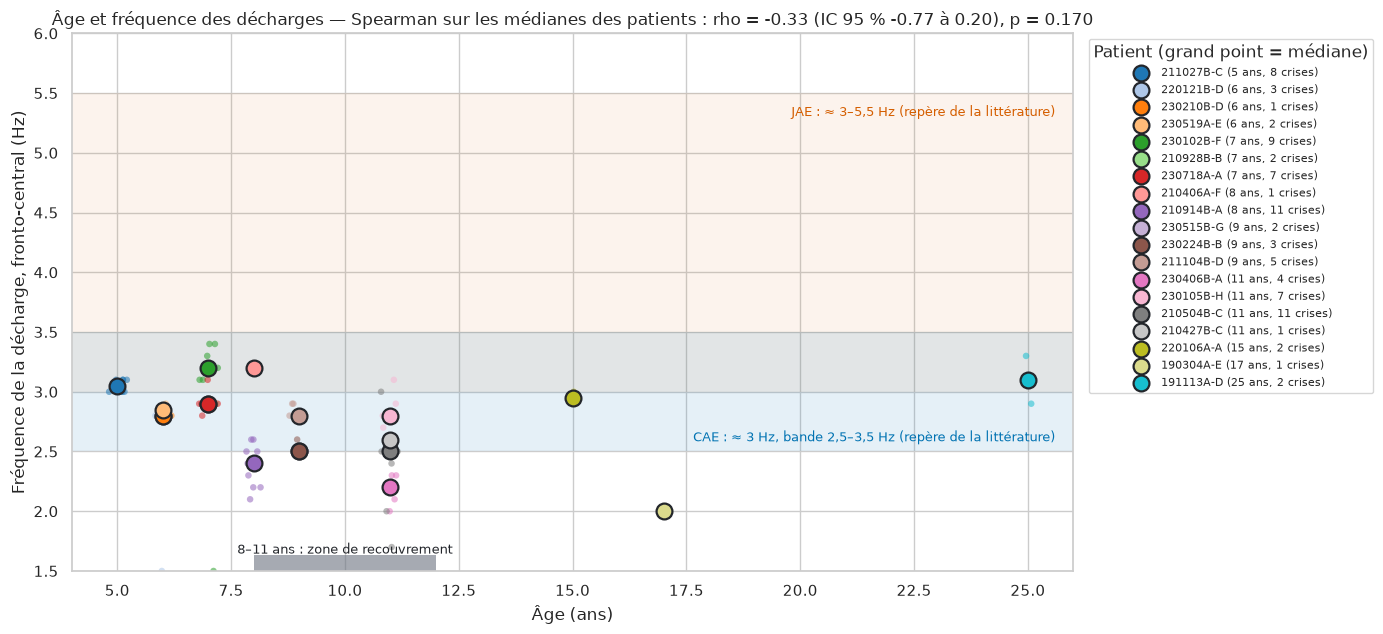

In [70]:
# Figure principale : âge et fréquence de la décharge (une crise = un petit point, médiane du patient en gras)
rng_fig = np.random.default_rng(42)
ordre_pat = list(patients.index)                             # patients triés par âge
cmap = plt.get_cmap("tab20")
COULEUR_PATIENT = {r: cmap(j % 20) for j, r in enumerate(ordre_pat)}

fig, ax = plt.subplots(figsize=(14, 6.5))
ax.axhspan(3.0, 5.5, color=ROUGE, alpha=0.07, lw=0)
ax.axhspan(2.5, 3.5, color=BLEU, alpha=0.10, lw=0)
ax.text(25.6, 5.4, "JAE : ≈ 3–5,5 Hz (repère de la littérature)", color=ROUGE, ha="right", va="top", fontsize=9)
ax.text(25.6, 2.56, "CAE : ≈ 3 Hz, bande 2,5–3,5 Hz (repère de la littérature)", color=BLEU, ha="right", va="bottom", fontsize=9)
for r in ordre_pat:
    g = morpho[morpho["ID"] == r]
    decal = rng_fig.uniform(-0.22, 0.22, len(g))             # léger décalage horizontal pour séparer les crises
    ax.scatter(g["Âge"] + decal, g[col("freq")], s=22, color=COULEUR_PATIENT[r], alpha=0.55, edgecolor="none")
    ax.scatter(AGE_DE[r], patients.loc[r, col("freq")], s=130, color=COULEUR_PATIENT[r], edgecolor="#23262B", lw=1.6,
               label=f"{r} ({AGE_DE[r]:.0f} ans, {len(g)} crises)", zorder=3)
ax.axvspan(8, 11.99, ymin=0, ymax=0.03, color=GRIS, alpha=0.6, lw=0)
ax.text(10, 1.62, "8–11 ans : zone de recouvrement", ha="center", va="bottom", fontsize=9, color="#23262B")
r_ = spearman_age.loc[col("freq")]
ax.set(xlabel="Âge (ans)", ylabel="Fréquence de la décharge, fronto-central (Hz)", ylim=(1.5, 6), xlim=(4, 26),
       title=f"Âge et fréquence des décharges — Spearman sur les médianes des patients : rho = {r_['rho']:.2f} "
             f"(IC 95 % {r_['IC95 bas']:.2f} à {r_['IC95 haut']:.2f}), p = {r_['p']:.3f}")
ax.legend(title="Patient (grand point = médiane)", loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=8)
plt.tight_layout(); sauver_fig_syn("age_frequence_des_decharges")

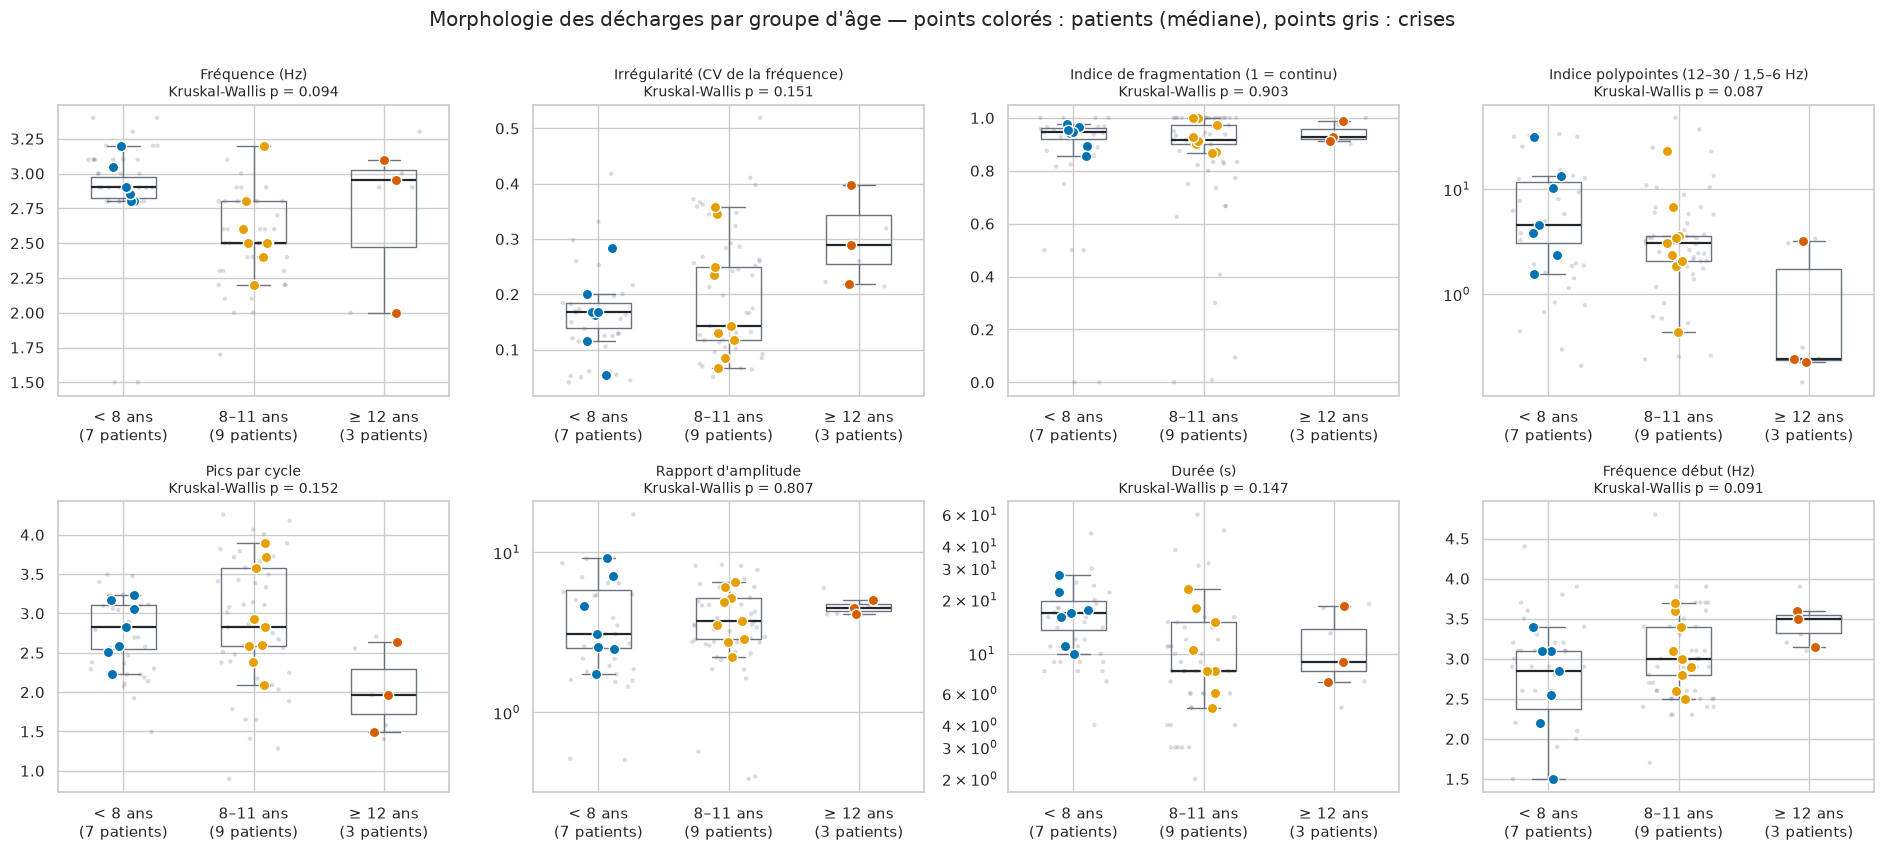

In [71]:
# Boîtes par groupe d'âge : un point par patient (médiane de ses crises), crises individuelles en arrière-plan
A_MONTRER = [col("freq"), col("cv"), col("frag"), col("poly"), col("pics"), col("amp"), "Durée (s)", col("f_debut")]
fig, axes = plt.subplots(2, 4, figsize=(19, 8.5))
for ax, v in zip(axes.ravel(), A_MONTRER):
    for j, g in enumerate(GROUPES_AGE):
        vc = morpho.loc[morpho["Groupe d'âge"] == g, v].dropna()
        vp = patients.loc[patients["Groupe d'âge"] == g, v].dropna()
        ax.scatter(j + rng_fig.uniform(-0.28, 0.28, len(vc)), vc, s=10, color=GRIS, alpha=0.25, edgecolor="none")
        ax.boxplot([vp], positions=[j], widths=0.5, showfliers=False, medianprops={"color": "#23262B", "lw": 1.6},
                   boxprops={"color": GRIS}, whiskerprops={"color": GRIS}, capprops={"color": GRIS})
        ax.scatter(j + rng_fig.uniform(-0.12, 0.12, len(vp)), vp, s=55, color=COULEUR_GROUPE[g], edgecolor="white", lw=1, zorder=3)
    if v in (col("poly"), col("amp"), "Durée (s)"):
        ax.set_yscale("log")
    ax.set_xticks(range(3)); ax.set_xticklabels([f"{g}\n({N_PAR_GROUPE[g]} patients)" for g in GROUPES_AGE])
    ax.set_title(f"{v.replace(' — FC', '')}\nKruskal-Wallis p = {kruskal_age.loc[v, 'p (Kruskal-Wallis)']:.3f}", fontsize=10)
fig.suptitle("Morphologie des décharges par groupe d'âge — points colorés : patients (médiane), points gris : crises", y=1.0)
plt.tight_layout(); sauver_fig_syn("morphologie_par_groupe_d_age")

In [72]:
# Analyses de sensibilité : sans le patient aux absences atypiques, sans le patient de 25 ans, sans les deux
SCENARIOS = {"Tous les patients": [], f"Sans {PATIENT_ATYPIQUE} (atypique)": [PATIENT_ATYPIQUE],
             f"Sans {PATIENT_ADULTE} (25 ans)": [PATIENT_ADULTE], "Sans les deux": [PATIENT_ATYPIQUE, PATIENT_ADULTE]}
blocs = []
for nom, retires in SCENARIOS.items():
    pp = patients.drop(index=retires)
    t = spearman_table(pp, "Âge", VARS_FC)
    kw = [stats.kruskal(*[pp.loc[pp["Groupe d'âge"] == g, v].dropna() for g in GROUPES_AGE]).pvalue for v in VARS_FC]
    t["p (Kruskal-Wallis)"] = kw
    t.insert(0, "Scénario", nom)
    blocs.append(t.reset_index())
    progres(f"Sensibilité : {nom} ({len(pp)} patients)")
sensibilite = pd.concat(blocs, ignore_index=True)
sauver_csv_syn(sensibilite, "age_sensibilite_scenarios", index=False)

print("rho de Spearman (âge, mesure) selon le scénario")
display(sensibilite.pivot(index="Mesure", columns="Scénario", values="rho").loc[VARS_FC, list(SCENARIOS)].round(2))
print("p (non corrigée) selon le scénario")
sensibilite.pivot(index="Mesure", columns="Scénario", values="p").loc[VARS_FC, list(SCENARIOS)].round(3)

[22:14:13] Sensibilité : Tous les patients (19 patients)


[22:14:17] Sensibilité : Sans 210914B-A (atypique) (18 patients)


[22:14:22] Sensibilité : Sans 191113A-D (25 ans) (18 patients)


[22:14:26] Sensibilité : Sans les deux (17 patients)


rho de Spearman (âge, mesure) selon le scénario


Scénario,Tous les patients,Sans 210914B-A (atypique),Sans 191113A-D (25 ans),Sans les deux
Mesure,,,,
Durée (s),-0.36,-0.37,-0.33,-0.32
Fréquence (Hz) — FC,-0.33,-0.34,-0.52,-0.54
Fréquence début (Hz) — FC,0.39,0.38,0.36,0.35
Fréquence fin (Hz) — FC,-0.13,-0.15,-0.09,-0.10
Irrégularité (CV de la fréquence) — FC,0.34,0.38,0.26,0.28
Indice de fragmentation (1 = continu) — FC,0.04,0.02,0.10,0.09
"Indice polypointes (12–30 / 1,5–6 Hz) — FC",-0.45,-0.49,-0.36,-0.39
Pics par cycle — FC,-0.05,-0.05,0.12,0.13
Rapport d'amplitude — FC,0.09,0.06,0.04,0.01


p (non corrigée) selon le scénario


Scénario,Tous les patients,Sans 210914B-A (atypique),Sans 191113A-D (25 ans),Sans les deux
Mesure,,,,
Durée (s),0.127,0.126,0.180,0.204
Fréquence (Hz) — FC,0.170,0.172,0.028,0.026
Fréquence début (Hz) — FC,0.098,0.123,0.138,0.166
Fréquence fin (Hz) — FC,0.603,0.546,0.713,0.689
Irrégularité (CV de la fréquence) — FC,0.154,0.120,0.291,0.268
Indice de fragmentation (1 = continu) — FC,0.884,0.944,0.706,0.722
"Indice polypointes (12–30 / 1,5–6 Hz) — FC",0.051,0.041,0.146,0.124
Pics par cycle — FC,0.846,0.850,0.629,0.611
Rapport d'amplitude — FC,0.718,0.827,0.869,0.977


#### Interprétation — l'âge change-t-il la morphologie ?

**Fréquence : pas de décharges plus rapides chez les plus âgés.** La fréquence médiane des décharges est de 2,90 Hz chez les moins de 8 ans, 2,50 Hz chez les 8–11 ans et 2,95 Hz chez les 12 ans et plus. La corrélation avec l'âge est faible et non significative (rho = −0,33, IC 95 % de −0,77 à 0,20, p = 0,17), tout comme la comparaison des trois groupes (Kruskal-Wallis p = 0,094). Les 19 médianes se situent entre 2,0 et 3,2 Hz : tous les patients sont dans la zone « ≈ 3 Hz » ou en dessous, aucun dans la partie rapide de la plage décrite pour la JAE. Les trois patients de 12 ans et plus sont à 2,95 Hz (15 ans), 2,0 Hz (17 ans) et 3,1 Hz (25 ans). Seul indice dans le sens attendu : leurs crises **commencent** plus vite (3,5 Hz en médiane dans les 2 premières secondes, contre 2,85 et 3,0 Hz ; rho = +0,39, p = 0,098), sans que ce soit significatif.

**Régularité : une tendance, non significative.** Le coefficient de variation de la fréquence est de 0,17 chez les moins de 8 ans, 0,14 chez les 8–11 ans et 0,29 chez les 12 ans et plus (rho = +0,34, p = 0,154).

**Fragmentation : aucune différence.** L'indice vaut 0,95, 0,92 et 0,93 dans les trois groupes (rho = 0,04, p = 0,88) : les décharges sont presque continues à tout âge.

**Polypointes : le contraire de ce qu'on attendait.** L'indice 12–30 / 1,5–6 Hz *baisse* avec l'âge : 4,57 chez les moins de 8 ans, 3,07 chez les 8–11 ans, 0,24 chez les 12 ans et plus (rho = −0,46, IC 95 % de −0,80 à 0,01, p = 0,051 ; p = 0,455 après Holm). Le nombre de pics par cycle va dans le même sens (2,83, 2,83 puis 1,96). Les décharges des trois patients les plus âgés contiennent donc moins de composantes rapides, pas davantage.

**Rien ne résiste à la correction de Holm** : toutes les p ajustées sont supérieures ou égales à 0,455, pour les corrélations comme pour les comparaisons de groupes. Les résultats sont les mêmes sur la moyenne de tous les canaux.

**Analyses de sensibilité.** Sans le patient aux absences atypiques, rien ne change (fréquence : rho = −0,34 ; polypointes : rho = −0,49, p = 0,041 non corrigée). Sans le patient de 25 ans, la corrélation entre l'âge et la fréquence se renforce dans le sens *inverse* de la JAE (rho = −0,52, p = 0,028 non corrigée : entre 5 et 17 ans, les décharges sont plutôt plus lentes quand l'âge augmente), et la tendance sur les polypointes s'affaiblit (rho = −0,36, p = 0,146). Aucune conclusion ne devient significative après correction, et le fait que les chiffres bougent en retirant un seul patient montre à quel point ils sont fragiles.

**En résumé**, ces données ne montrent pas la morphologie décrite pour la JAE (décharges plus rapides, fragmentées, avec polypointes) chez nos patients les plus âgés. Ce qui les distingue serait plutôt un début un peu plus rapide, un rythme moins régulier et moins de composantes rapides — trois tendances, aucune établie.

### 3. Lien avec les erreurs du détecteur

On reprend la détection existante (Random Forest, chaque enregistrement prédit par un modèle entraîné sur les 18 autres, mêmes prédictions que dans la section précédente). Pour chaque crise : **détectée ou manquée**, **retard** au début, et **couverture** (part des fenêtres de la crise prédites « crise », avant lissage). Une crise est dite « tardive » si elle est détectée avec plus de 2 s de retard.

In [73]:
# Détection par groupe d'âge
detection_par_groupe = morpho.groupby("Groupe d'âge").agg(
    Patients=("ID", "nunique"), Crises=("ID", "size"),
    Bien_détectées=("Détection", lambda s_: (s_ == "Bien détectée").sum()),
    Tardives=("Détection", lambda s_: (s_ == "Tardive (> 2 s)").sum()),
    Manquées=("Détection", lambda s_: (s_ == "Manquée").sum()),
    Couverture_médiane=("Couverture", "median"), Retard_moyen_s=("Retard début (s)", "mean")).reindex(GROUPES_AGE)
sauver_csv_syn(detection_par_groupe, "detection_par_groupe_d_age")

# Corrélations au niveau du patient : couverture et retard contre l'âge et la morphologie
PREDICTEURS = ["Âge"] + VARS_FC
spearman_couverture = spearman_table(patients, "Couverture", PREDICTEURS)
spearman_retard = spearman_table(patients, "Retard moyen (s)", PREDICTEURS)
sauver_csv_syn(spearman_couverture, "detection_spearman_couverture")
sauver_csv_syn(spearman_retard, "detection_spearman_retard")

# Morphologie des crises manquées ou tardives, comparée aux crises bien détectées (niveau crise)
lignes = []
bien, pas_bien = morpho[morpho["Détection"] == "Bien détectée"], morpho[morpho["Détection"] != "Bien détectée"]
for v in VARS_FC:
    u = stats.mannwhitneyu(bien[v].dropna(), pas_bien[v].dropna(), alternative="two-sided")
    lignes.append({"Mesure": v, "Médiane — bien détectées": bien[v].median(),
                   "Médiane — tardives": morpho.loc[morpho["Détection"] == "Tardive (> 2 s)", v].median(),
                   "Médiane — manquées": morpho.loc[morpho["Détection"] == "Manquée", v].median(),
                   "p (Mann-Whitney, bien détectées contre les autres)": u.pvalue})
comparaison_detection = pd.DataFrame(lignes).set_index("Mesure")
comparaison_detection["p ajustée (Holm)"] = holm(comparaison_detection.iloc[:, 3].values)
sauver_csv_syn(comparaison_detection, "detection_morphologie_bien_vs_tardives_manquees")

print(f"Crises : {len(bien)} bien détectées, {(morpho['Détection'] == 'Tardive (> 2 s)').sum()} tardives, "
      f"{(morpho['Détection'] == 'Manquée').sum()} manquées — crises tardives ou manquées chez {pas_bien['ID'].nunique()} patients")
display(detection_par_groupe.round(3))
print("Couverture médiane du patient contre l'âge et la morphologie (Spearman, n = 19)")
display(spearman_couverture.round(3))
print("Retard moyen du patient contre l'âge et la morphologie (Spearman, patients ayant au moins une crise détectée)")
display(spearman_retard.round(3))
print("Attention : le test ci-dessous compare des crises, qui ne sont pas indépendantes au sein d'un patient")
comparaison_detection.round(3)

Crises : 69 bien détectées, 11 tardives, 2 manquées — crises tardives ou manquées chez 9 patients


,Patients,Crises,Bien_détectées,Tardives,Manquées,Couverture_médiane,Retard_moyen_s
Groupe d'âge,,,,,,,
< 8 ans,7,32,28,4,0,0.846,1.000
8–11 ans,9,45,40,5,0,0.765,0.533
≥ 12 ans,3,5,1,2,2,0.250,3.333


Couverture médiane du patient contre l'âge et la morphologie (Spearman, n = 19)


,n,rho,IC95 bas,IC95 haut,p,p ajustée (Holm)
Mesure,,,,,,
Âge,19,-0.405,-0.838,0.189,0.085,0.683
Durée (s),19,0.105,-0.429,0.575,0.670,1.000
Fréquence (Hz) — FC,19,0.137,-0.346,0.602,0.576,1.000
Fréquence début (Hz) — FC,19,-0.280,-0.642,0.197,0.245,1.000
Fréquence fin (Hz) — FC,19,0.213,-0.229,0.647,0.382,1.000
Irrégularité (CV de la fréquence) — FC,19,-0.619,-0.815,-0.278,0.005,0.047
Indice de fragmentation (1 = continu) — FC,19,0.122,-0.340,0.567,0.618,1.000
"Indice polypointes (12–30 / 1,5–6 Hz) — FC",19,0.398,-0.079,0.778,0.092,0.683
Pics par cycle — FC,19,0.534,0.012,0.851,0.019,0.167


Retard moyen du patient contre l'âge et la morphologie (Spearman, patients ayant au moins une crise détectée)


,n,rho,IC95 bas,IC95 haut,p,p ajustée (Holm)
Mesure,,,,,,
Âge,18,-0.277,-0.713,0.292,0.266,1.000
Durée (s),18,0.476,0.023,0.817,0.046,0.458
Fréquence (Hz) — FC,18,0.198,-0.337,0.686,0.431,1.000
Fréquence début (Hz) — FC,18,0.161,-0.359,0.584,0.525,1.000
Fréquence fin (Hz) — FC,18,-0.174,-0.697,0.346,0.490,1.000
Irrégularité (CV de la fréquence) — FC,18,0.335,-0.101,0.751,0.175,1.000
Indice de fragmentation (1 = continu) — FC,18,-0.287,-0.721,0.290,0.248,1.000
"Indice polypointes (12–30 / 1,5–6 Hz) — FC",18,-0.071,-0.552,0.465,0.780,1.000
Pics par cycle — FC,18,-0.439,-0.786,0.064,0.069,0.617


Attention : le test ci-dessous compare des crises, qui ne sont pas indépendantes au sein d'un patient


,Médiane — bien détectées,Médiane — tardives,Médiane — manquées,"p (Mann-Whitney, bien détectées contre les autres)",p ajustée (Holm)
Mesure,,,,,
Durée (s),9.000,17.000,9.000,0.035,0.243
Fréquence (Hz) — FC,2.800,2.500,3.100,0.628,0.911
Fréquence début (Hz) — FC,2.900,3.100,3.150,0.125,0.625
Fréquence fin (Hz) — FC,2.700,2.400,2.500,0.025,0.197
Irrégularité (CV de la fréquence) — FC,0.163,0.251,0.290,0.010,0.086
Indice de fragmentation (1 = continu) — FC,0.938,0.824,0.912,0.283,0.911
"Indice polypointes (12–30 / 1,5–6 Hz) — FC",3.432,2.433,0.227,0.094,0.563
Pics par cycle — FC,2.750,2.669,1.489,0.439,0.911
Rapport d'amplitude — FC,3.220,4.350,5.066,0.228,0.911


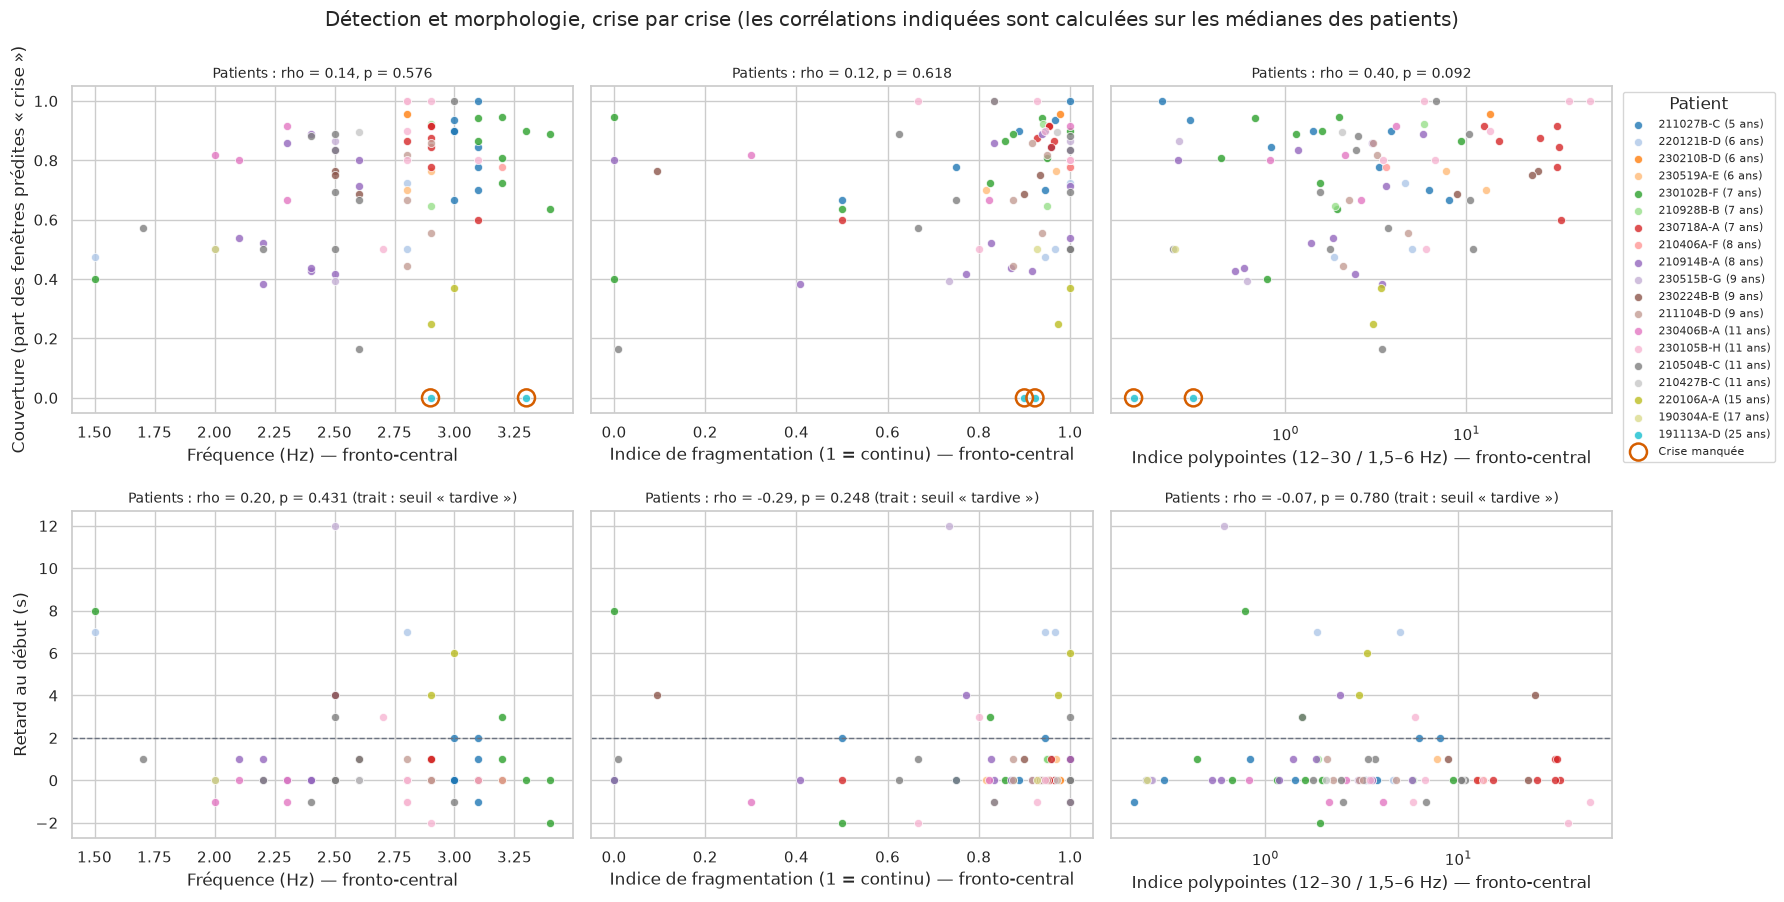

In [74]:
# Niveau crise : couverture et retard selon la fréquence, la fragmentation et les polypointes (couleur = patient)
fig, axes = plt.subplots(2, 3, figsize=(18, 9), sharey="row")
for jx, (c_, logx) in enumerate([("freq", False), ("frag", False), ("poly", True)]):
    for iy, (yv, ylab) in enumerate([("Couverture", "Couverture (part des fenêtres prédites « crise »)"), ("Retard début (s)", "Retard au début (s)")]):
        ax = axes[iy, jx]
        for r in ordre_pat:
            g = morpho[morpho["ID"] == r]
            ax.scatter(g[col(c_)], g[yv], s=34, color=COULEUR_PATIENT[r], alpha=0.8, edgecolor="white", lw=0.6,
                       label=f"{r} ({AGE_DE[r]:.0f} ans)" if (iy, jx) == (0, 2) else None)
        if iy == 0:                                          # les crises manquées sont entourées
            m_ = morpho[morpho["Détection"] == "Manquée"]
            ax.scatter(m_[col(c_)], m_[yv], s=150, facecolor="none", edgecolor=ROUGE, lw=1.8,
                       label="Crise manquée" if jx == 2 else None)
        if logx:
            ax.set_xscale("log")
        ax.set_xlabel(MESURES[c_] + " — fronto-central")
        if jx == 0:
            ax.set_ylabel(ylab)
        if iy == 0:
            t_ = spearman_couverture.loc[col(c_)]
            ax.set_title(f"Patients : rho = {t_['rho']:.2f}, p = {t_['p']:.3f}", fontsize=10)
        else:
            t_ = spearman_retard.loc[col(c_)]
            ax.axhline(2, color=GRIS, ls="--", lw=1)
            ax.set_title(f"Patients : rho = {t_['rho']:.2f}, p = {t_['p']:.3f} (trait : seuil « tardive »)", fontsize=10)
axes[0, 2].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=8, title="Patient")
fig.suptitle("Détection et morphologie, crise par crise (les corrélations indiquées sont calculées sur les médianes des patients)", y=1.0)
plt.tight_layout(); sauver_fig_syn("detection_et_morphologie")

#### Interprétation — la morphologie explique-t-elle les erreurs du détecteur ?

**Les patients de 12 ans et plus sont nettement moins bien détectés.** Sur leurs 5 crises, 1 seule est bien détectée, 2 sont tardives et 2 manquées, avec une couverture médiane de 0,25 et un retard moyen de 3,3 s. Chez les moins de 8 ans : 28 crises bien détectées sur 32, 4 tardives, aucune manquée, couverture de 0,85. Chez les 8–11 ans : 40 sur 45, 5 tardives, aucune manquée, couverture de 0,77. Au niveau du patient, la corrélation entre l'âge et la couverture est négative mais non significative (rho = −0,41, IC 95 % de −0,84 à 0,19, p = 0,085) : trois patients ne suffisent pas à l'établir.

**Ce qui est lié à la couverture : la régularité, pas la vitesse.** Parmi l'âge et les neuf mesures de morphologie, une seule corrélation reste significative après Holm : plus la fréquence d'un patient est irrégulière, moins ses crises sont couvertes (rho = −0,62, IC 95 % de −0,82 à −0,28, p = 0,005, p ajustée = 0,047). Viennent ensuite, sans passer la correction, le nombre de pics par cycle (rho = +0,53, p = 0,019) et l'indice polypointes (rho = +0,40, p = 0,092) : les décharges riches en composantes rapides sont *mieux* couvertes. La fréquence de la décharge (rho = 0,14) et la fragmentation (rho = 0,12) ne jouent pas. Pour le retard, le seul lien est la durée (rho = +0,48, p = 0,046 non corrigée) : les crises longues sont détectées plus tard.

**Crises manquées ou tardives contre crises bien détectées** (69 bien détectées, 11 tardives, 2 manquées, réparties sur 9 patients). Elles sont plus irrégulières (CV de 0,25 pour les tardives et 0,29 pour les manquées, contre 0,16 ; p = 0,010, p ajustée = 0,086) et finissent plus lentement (2,4 et 2,5 Hz contre 2,7 Hz ; p = 0,025 non corrigée). Les deux crises manquées ont très peu de composantes rapides (indice polypointes 0,23 contre 3,43 ; 1,5 pic par cycle contre 2,75), mais ce sont deux crises d'un seul patient. Leur amplitude n'est pas en cause : leur rapport d'amplitude (5,1) est supérieur à celui des crises bien détectées (3,2).

**Réponse à la question.** Non : les décharges moins bien détectées ne sont ni plus rapides, ni plus fragmentées, ni plus riches en polypointes. C'est plutôt l'inverse : elles sont moins régulières et plus pauvres en composantes rapides. Cela rejoint ce que montrait SHAP dans la section précédente : le modèle s'appuie sur l'amplitude et sur la puissance dans les bandes alpha et bêta, c'est-à-dire sur la « pointe » de la pointe-onde. Une décharge ample mais lisse, comme celles du patient de 25 ans, lui échappe.

### 4. Figures d'illustration

Quatre patients choisis par des règles fixes : le plus jeune ; dans la zone 8–11 ans, le patient non atypique qui a le plus de crises ; parmi les 15 et 17 ans, celui qui a le plus de crises ; et le patient de 25 ans. Pour chacun, on montre la crise dont la durée est la plus proche de sa durée médiane (la plus représentative) : 6 s au milieu de la crise sur six canaux (même échelle en µV pour les quatre patients), un zoom de 2 s sur le signal fronto-central et le spectre de la crise.

[22:14:38] Extrait : Le plus jeune — 211027B-C (5 ans), crise de 11 s


[22:14:40] Extrait : Zone 8–11 ans — 210504B-C (11 ans), crise de 6 s


[22:14:40] Extrait : Adolescent — 220106A-A (15 ans), crise de 19 s


[22:14:41] Extrait : Adulte — 191113A-D (25 ans), crise de 13 s


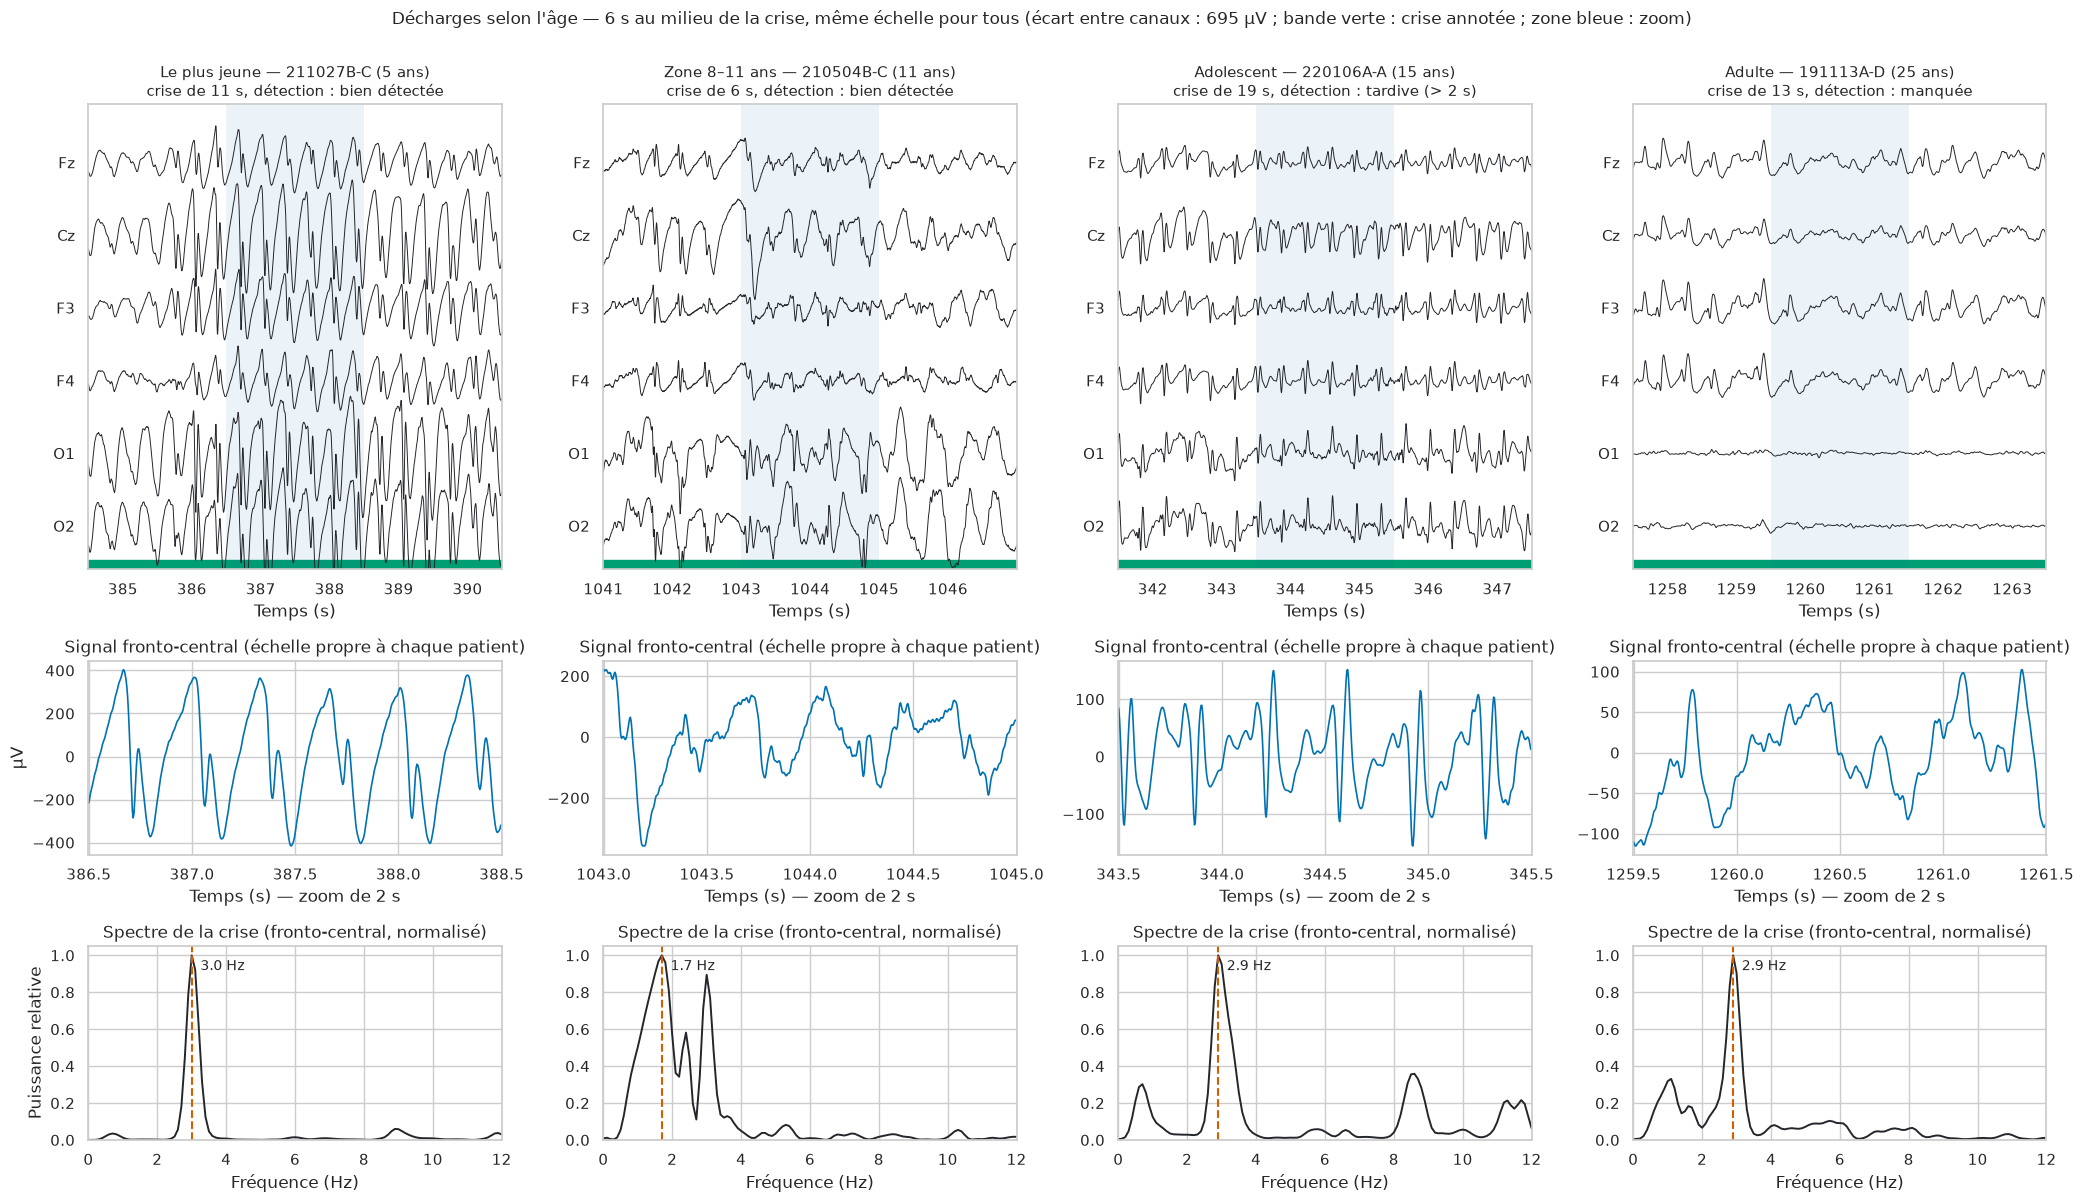

Cas,Le plus jeune,Zone 8–11 ans,Adolescent,Adulte
ID,211027B-C,210504B-C,220106A-A,191113A-D
Âge,5.0,11.0,15.0,25.0
Crise,4,2,1,1
Début (s),382.0,1041.0,335.0,1254.0
Durée (s),11.0,6.0,19.0,13.0
Fréquence (Hz) — FC,3.0,1.7,2.9,2.9
Fréquence début (Hz) — FC,3.0,2.8,3.9,3.1
Fréquence fin (Hz) — FC,3.2,2.5,2.8,2.5
Irrégularité (CV de la fréquence) — FC,0.055,0.26,0.214,0.26
Indice de fragmentation (1 = continu) — FC,0.5,0.667,0.974,0.923


In [75]:
def choisir_patients_illustration():
    pp = patients.copy()
    choix = {"Le plus jeune": pp["Âge"].idxmin()}
    z = pp[(pp["Groupe d'âge"] == "8–11 ans") & (pp.index != PATIENT_ATYPIQUE)]
    choix["Zone 8–11 ans"] = z["Crises"].idxmax()
    ado = pp[(pp["Âge"] >= 12) & (pp["Âge"] < 18)]
    choix["Adolescent"] = ado["Crises"].idxmax()
    choix["Adulte"] = PATIENT_ADULTE
    return choix


CANAUX_ILLUS = ["Fz", "Cz", "F3", "F4", "O1", "O2"]
extraits = {}
for titre, rec in choisir_patients_illustration().items():   # un enregistrement à la fois
    g = morpho[morpho["ID"] == rec].sort_values("Durée (s)", ascending=False)
    crise = g.loc[(g["Durée (s)"] - g["Durée (s)"].median()).abs().idxmin()]   # crise de durée médiane : la plus représentative
    d, fs = load_eeg(FICHIER_DE[rec])
    chans = [c for c in d.columns if c.startswith("EEG")]
    Xf = d[chans].values.astype(np.float64)
    Xf = bandpass(Xf - np.median(Xf, axis=0), fs)
    centre = (crise["Début (s)"] + crise["Fin (s)"]) / 2
    a = int(np.clip(centre - 3, 0, len(d) / fs - 6) * fs)
    idx = [chans.index("EEG" + c) for c in CANAUX_ILLUS if "EEG" + c in chans]
    i_fc = [k for k, c in enumerate(chans) if c.replace("EEG", "") in FRONTO_CENTRAL]
    fc = Xf[:, i_fc].mean(1)
    i0, i1 = int(round(crise["Début (s)"] * fs)), int(round(crise["Fin (s)"] * fs))
    f_, p_ = spectre_welch(fc[i0:i1], fs)
    extraits[titre] = {"rec": rec, "crise": crise, "fs": fs, "t": np.arange(a, a + int(6 * fs)) / fs, "seg": Xf[a:a + int(6 * fs)][:, idx],
                       "noms": [chans[k].replace("EEG", "") for k in idx], "fc": fc[a:a + int(6 * fs)], "f": f_, "p": p_}
    del d, Xf, fc
    progres(f"Extrait : {titre} — {rec} ({AGE_DE[rec]:.0f} ans), crise de {crise['Durée (s)']:.0f} s")

# Même échelle verticale pour les quatre patients (écart entre canaux commun, en µV)
pas = max(np.percentile(np.abs(e_["seg"]), 99) for e_ in extraits.values()) * 1.3
fig, axes = plt.subplots(3, 4, figsize=(21, 12), gridspec_kw={"height_ratios": [2.4, 1, 1]})
for j, (titre, e_) in enumerate(extraits.items()):
    c_, t = e_["crise"], e_["t"]
    ax = axes[0, j]
    for k, nom in enumerate(e_["noms"]):
        ax.plot(t, e_["seg"][:, k] - k * pas, color="#23262B", lw=0.7)
    ax.axvspan(max(c_["Début (s)"], t[0]), min(c_["Fin (s)"], t[-1]), ymin=0, ymax=0.02, color=VERT)
    milieu = (t[0] + t[-1]) / 2
    ax.axvspan(milieu - 1, milieu + 1, color=BLEU, alpha=0.08, lw=0)
    ax.set_yticks(-np.arange(len(e_["noms"])) * pas); ax.set_yticklabels(e_["noms"])
    ax.set_ylim(-(len(e_["noms"]) - 0.4) * pas, 0.8 * pas); ax.grid(False)
    ax.set(xlim=(t[0], t[-1]), xlabel="Temps (s)")
    ax.set_title(f"{titre} — {e_['rec']} ({AGE_DE[e_['rec']]:.0f} ans)\ncrise de {c_['Durée (s)']:.0f} s, détection : {c_['Détection'].lower()}", fontsize=11)
    ax = axes[1, j]                                          # zoom de 2 s sur le signal fronto-central
    z = (t >= milieu - 1) & (t <= milieu + 1)
    ax.plot(t[z], e_["fc"][z], color=BLEU, lw=1.2)
    ax.set(xlim=(milieu - 1, milieu + 1), xlabel="Temps (s) — zoom de 2 s", title="Signal fronto-central (échelle propre à chaque patient)")
    ax.set_xticks(np.arange(np.ceil((milieu - 1) * 2) / 2, milieu + 1.01, 0.5))
    if j == 0:
        ax.set_ylabel("µV")
    ax = axes[2, j]                                          # spectre de la crise, fréquence dominante marquée
    ok = e_["f"] <= 12
    ax.plot(e_["f"][ok], e_["p"][ok] / e_["p"][ok].max(), color="#23262B", lw=1.4)
    fd = c_[col("freq")]
    ax.axvline(fd, color=ROUGE, lw=1.5, ls="--")
    ax.text(fd + 0.25, 0.92, f"{fd:.1f} Hz", color="#23262B", fontsize=10)
    ax.set(xlim=(0, 12), ylim=(0, 1.05), xlabel="Fréquence (Hz)", title="Spectre de la crise (fronto-central, normalisé)")
    if j == 0:
        ax.set_ylabel("Puissance relative")
fig.suptitle(f"Décharges selon l'âge — 6 s au milieu de la crise, même échelle pour tous (écart entre canaux : {pas:.0f} µV ; "
             f"bande verte : crise annotée ; zone bleue : zoom)", y=1.0, fontsize=12)
plt.tight_layout(); sauver_fig_syn("extraits_eeg_selon_l_age")
illustration = pd.DataFrame([{"Cas": t_, "ID": e_["rec"], "Âge": AGE_DE[e_["rec"]], **e_["crise"][["Crise", "Début (s)", "Durée (s)"] + VARS_FC[1:] + ["Détection", "Couverture"]].to_dict()}
                             for t_, e_ in extraits.items()]).set_index("Cas")
sauver_csv_syn(illustration, "extraits_eeg_crises_montrees")
illustration.round(3).T

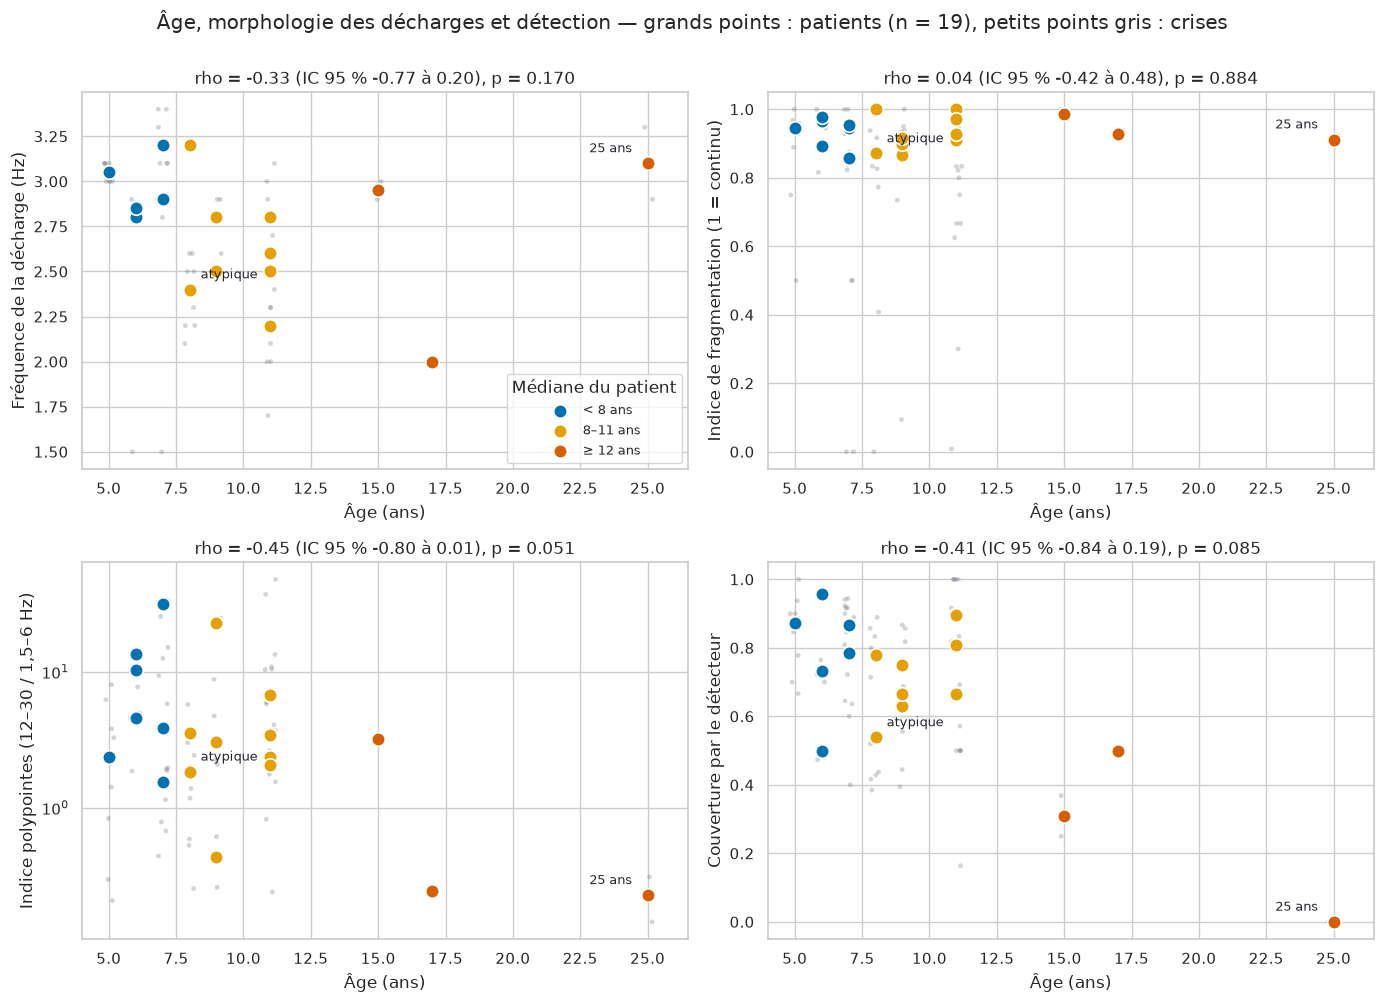

In [76]:
# Figure de synthèse pour le rapport : âge contre fréquence, fragmentation, polypointes et couverture
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
panneaux = [(col("freq"), "Fréquence de la décharge (Hz)", spearman_age, False),
            (col("frag"), "Indice de fragmentation (1 = continu)", spearman_age, False),
            (col("poly"), "Indice polypointes (12–30 / 1,5–6 Hz)", spearman_age, True),
            ("Couverture", "Couverture par le détecteur", None, False)]
rho_couv = spearman_couverture.loc["Âge"]
for ax, (v, ylab, tab, logy) in zip(axes.ravel(), panneaux):
    ax.scatter(morpho["Âge"] + rng_fig.uniform(-0.2, 0.2, len(morpho)), morpho[v], s=12, color=GRIS, alpha=0.3, edgecolor="none")
    for g in GROUPES_AGE:
        pp = patients[patients["Groupe d'âge"] == g]
        ax.scatter(pp["Âge"], pp[v], s=95, color=COULEUR_GROUPE[g], edgecolor="white", lw=1.2, label=g, zorder=3)
    for r in (PATIENT_ATYPIQUE, PATIENT_ADULTE):             # deux patients nommés directement
        ax.annotate("atypique" if r == PATIENT_ATYPIQUE else "25 ans", (AGE_DE[r], patients.loc[r, v]), textcoords="offset points",
                    xytext=(8, 8) if r == PATIENT_ATYPIQUE else (-42, 8), fontsize=9, color="#23262B")
    t_ = tab.loc[v] if tab is not None else rho_couv
    if logy:
        ax.set_yscale("log")
    ax.set(xlabel="Âge (ans)", ylabel=ylab, xlim=(4, 26.5),
           title=f"rho = {t_['rho']:.2f} (IC 95 % {t_['IC95 bas']:.2f} à {t_['IC95 haut']:.2f}), p = {t_['p']:.3f}")
axes[0, 0].legend(title="Médiane du patient", loc="best", fontsize=9)
fig.suptitle("Âge, morphologie des décharges et détection — grands points : patients (n = 19), petits points gris : crises", y=1.0)
plt.tight_layout(); sauver_fig_syn("synthese_age_morphologie_detection")

### 5. Synthèse et limites

**Ce que montrent les chiffres.**
1. **L'hypothèse de départ n'est confirmée qu'à moitié.** Les patients de 12 ans et plus sont bien les moins bien détectés (1 crise bien détectée sur 5, couverture médiane de 0,25 contre 0,77 à 0,85 chez les plus jeunes). Mais leur morphologie n'est pas celle que la littérature décrit pour la JAE : pas de décharges plus rapides (2,95 Hz en médiane, contre 2,90 et 2,50 Hz), pas plus de fragmentation (0,93 contre 0,95 et 0,92), et moins de composantes rapides au lieu de plus (indice polypointes de 0,24 contre 4,57 et 3,07).
2. **Aucun lien entre l'âge et la morphologie n'est statistiquement établi** (toutes les p ajustées ≥ 0,455, n = 19).
3. **Le détecteur est sensible à la régularité de la décharge** : c'est le seul résultat qui passe la correction de Holm (rho = −0,62 entre irrégularité et couverture, p ajustée = 0,047). Les crises manquées ou tardives sont plus irrégulières et plus « lisses », pas plus rapides.

L'explication la plus cohérente avec ces données n'est donc pas « des décharges de type JAE que le modèle ne connaît pas », mais « des décharges moins régulières et moins pointues, chez quelques patients plus âgés, alors que le modèle a appris à reconnaître l'amplitude et la pointe ». La figure des extraits d'EEG permet de le vérifier à l'œil sur quatre patients.

**Limites.**
- **Pas de diagnostic de syndrome.** L'âge au moment de l'enregistrement n'est qu'un indicateur indirect : un patient de 15 ans peut avoir une CAE ancienne, et l'âge de début des crises nous est inconnu. Rien ici ne permet de dire qu'un patient a une CAE ou une JAE.
- **Trois patients de 12 ans et plus**, avec 5 crises en tout (2, 1 et 2). Chaque chiffre de ce groupe repose sur une ou deux crises, et les analyses de sensibilité montrent que retirer un seul patient déplace les corrélations.
- **EEG de scalp à 19 canaux**, moyenné sur six canaux fronto-centraux : une différence de topographie ou de montage entre enregistrements peut se confondre avec une différence de morphologie.
- **Mesures de morphologie approximatives.** L'indice polypointes mesure la part d'activité rapide dans la décharge, pas un comptage validé de polypointes ; le seuil des pics est arbitraire ; la fréquence mesurée sur 1 s est grossière, ce qui gonfle le coefficient de variation des crises courtes.
- **Analyse exploratoire.** Une vingtaine de tests ont été faits sur 19 patients : elle sert à formuler une hypothèse, pas à la prouver. Les patients ont aussi pu recevoir des traitements différents, ce que nous ne savons pas.

**Ce que cela implique pour un détecteur.**
- Les données d'entraînement devraient couvrir les **adolescents et les adultes** : aujourd'hui 16 patients sur 19 ont 11 ans ou moins, et le modèle n'a presque jamais vu de décharge comme celles du patient de 25 ans. À défaut, des **modèles tenant compte de l'âge** (un modèle par tranche d'âge, ou l'âge comme variable d'entrée) sont une piste, à condition d'avoir assez de patients par tranche.
- Les caractéristiques actuelles (amplitude et puissances moyennées sur tous les canaux) devraient être complétées par des mesures du **rythme lui-même** — régularité, synchronie entre canaux — pour ne plus dépendre de la seule présence d'une pointe ample.
- Les performances devraient être **rapportées par tranche d'âge** : une sensibilité globale de 80 crises sur 82 masque le fait que les deux crises manquées sont celles du seul adulte.

In [77]:
# Bilan de la section
progres(f"Section syndrome terminée en {time.perf_counter() - T0_SYN:.0f} s")
print(f"\n{len(SYN_FIGURES)} figures dans {SYN_FIG}/ :")
for f_ in SYN_FIGURES:
    print("  -", f_)
print(f"\nTableaux CSV dans {SYN_DIR}/ :")
for f_ in sorted(p_.name for p_ in SYN_DIR.glob("*.csv")):
    print("  -", f_)

[22:14:44] Section syndrome terminée en 59 s



5 figures dans resultats_local/syndrome/figures/ :
  - age_frequence_des_decharges.png
  - morphologie_par_groupe_d_age.png
  - detection_et_morphologie.png
  - extraits_eeg_selon_l_age.png
  - synthese_age_morphologie_detection.png

Tableaux CSV dans resultats_local/syndrome/ :
  - age_kruskal_groupes.csv
  - age_sensibilite_scenarios.csv
  - age_spearman_fronto_central.csv
  - age_spearman_tous_canaux.csv
  - detection_morphologie_bien_vs_tardives_manquees.csv
  - detection_par_groupe_d_age.csv
  - detection_spearman_couverture.csv
  - detection_spearman_retard.csv
  - extraits_eeg_crises_montrees.csv
  - morphologie_par_crise.csv
  - morphologie_par_patient.csv


## Anticipation des crises (exploratoire)

**Au-delà de l'énoncé.** Tout le notebook fait de la *détection* : reconnaître une crise qui a commencé. Ici on pose une autre question : peut-on *annoncer* une crise quelques secondes avant son début, en ne regardant que le signal qui la précède ?

**Protocole.**
- On réutilise les fenêtres de 2 s et leurs 17 caractéristiques (aucun nouveau calcul sur le signal).
- **Crise de référence** : crise dont le début est à au moins 60 s du début de l'enregistrement et de la fin de la crise précédente (il faut un passé « calme » pour juger).
- Pour un horizon H (5 s ou 10 s), une fenêtre est **pré-critique** si elle se termine dans les H secondes qui précèdent le début annoté d'une crise de référence, et **inter-critique** si elle est à plus de 60 s de toute crise. Les autres fenêtres ne servent pas.
- Quatre modèles, tous évalués en laissant un enregistrement de côté :
  - **M0** — le détecteur existant, tel quel : sa probabilité de crise monte-t-elle avant le début annoté ?
  - **M1** — Random Forest entraîné à séparer pré-critique et inter-critique, avec les 17 caractéristiques de la fenêtre.
  - **M2** — M1, plus l'évolution de chaque caractéristique par rapport aux 30 s précédentes.
  - **M3** — M2, avec des caractéristiques ramenées à l'échelle de chaque enregistrement (médiane et écart interquartile).
- **Alarme** : deux fenêtres consécutives au-dessus d'un seuil (99ᵉ centile des scores inter-critiques des autres enregistrements). Une crise est **annoncée** si une alarme tombe dans les H secondes avant son début.
- **Comparaison au hasard** : on tire 1 000 fois des « faux débuts » au hasard dans les périodes inter-critiques (autant que de crises de référence par enregistrement) et on compte combien seraient « annoncés » par les mêmes alarmes. La valeur p est la part des tirages qui font au moins aussi bien que la réalité.

In [78]:
from sklearn.metrics import roc_auc_score

T0_ANT = time.perf_counter()
ANT_DIR = RECH_DIR / "anticipation"
ANT_DIR.mkdir(parents=True, exist_ok=True)
HORIZONS, RECUL, CONTEXTE, N_HASARD, Q_SEUIL = [5, 10], 60, 30, 1000, 0.99
MODELES_ANT = {"M0": "Le détecteur existant, tel quel", "M1": "Pré-critique contre inter-critique, 17 caractéristiques",
               "M2": "M1 + évolution sur les 30 s précédentes", "M3": "M2, à l'échelle de chaque enregistrement"}

# ---- Fenêtres : distance à la crise la plus proche, prochain début, crises de référence ----
A = dataset.sort_values(["Recording", "t_start"]).reset_index(drop=True)
A = A.merge(pred_loro[["Recording", "Window", "Proba RF"]], on=["Recording", "Window"], how="left")
A["dist"], A["debut"], A["ref"] = np.inf, np.nan, False
refs = []
for rec, g in A.groupby("Recording"):
    ts, te = g["t_start"].values, g["t_end"].values
    dist, debut, ref = np.full(len(g), np.inf), np.full(len(g), np.nan), np.zeros(len(g), bool)
    crises = crises_reelles(rec)
    for k, (s, e) in enumerate(crises, 1):
        dist = np.minimum(dist, np.where(te <= s, s - te, np.where(ts >= e, ts - e, 0.0)))
        fin_prec = max([e2 for _, e2 in crises if e2 <= s], default=-np.inf)
        est_ref = s >= RECUL and s - fin_prec >= RECUL
        avant = (te <= s) & (te > max(fin_prec, s - RECUL - 1))          # fenêtres qui précèdent cette crise
        debut[avant], ref[avant] = s, est_ref
        if est_ref:
            refs.append({"ID": rec, "Crise": k, "Début (s)": s, "Durée (s)": e - s})
    A.loc[g.index, "dist"], A.loc[g.index, "debut"], A.loc[g.index, "ref"] = dist, debut, ref
A["inter"] = (A["dist"] > RECUL) & (A["Class"] == 0)
crises_ref = pd.DataFrame(refs)

# ---- Caractéristiques : contexte (écart à la moyenne des 30 s précédentes) et échelle par enregistrement ----
ctx = A.groupby("Recording")[FEATURES].transform(lambda s_: s_ - s_.shift(1).rolling(CONTEXTE, min_periods=10).mean()).fillna(0.0)
ctx.columns = [f"d_{f}" for f in FEATURES]
F2 = pd.concat([A[FEATURES], ctx], axis=1)
med = F2.groupby(A["Recording"]).transform("median")
iqr = (F2.groupby(A["Recording"]).transform(lambda s_: s_.quantile(0.75) - s_.quantile(0.25))).replace(0, 1.0)
JEUX = {"M1": A[FEATURES].values, "M2": F2.values, "M3": ((F2 - med) / iqr).values}
recs_a, rec_arr = list(A["Recording"].unique()), A["Recording"].values
print(f"{len(crises_ref)} crises de référence sur {int(SEIZURES['ID'].isin(recs_a).sum())}, dans {crises_ref['ID'].nunique()} enregistrements ; "
      f"{int(A['inter'].sum())} fenêtres inter-critiques ({A['inter'].sum() / 3600:.2f} h)")

# ---- Scores « un enregistrement laissé de côté » (mis en cache) ----
SCORES_CSV = ANT_DIR / "cache_scores.csv"
if SCORES_CSV.exists():
    S_ant = pd.read_csv(SCORES_CSV)
    progres("Anticipation : scores relus depuis le cache")
else:
    S_ant = A[["Recording", "Window"]].copy()
    for H in HORIZONS:
        pre = (A["ref"] & (A["debut"] - A["t_end"] < H)).values       # fenêtres pré-critiques pour cet horizon
        garde = pre | A["inter"].values
        for nom, Xa in JEUX.items():
            sc = np.zeros(len(A))
            for rec in recs_a:
                te_ = rec_arr == rec
                tr_ = garde & ~te_
                sc[te_] = clone(MODELS["Random Forest"]).fit(Xa[tr_], pre[tr_].astype(int)).predict_proba(Xa[te_])[:, 1]
            S_ant[f"{nom}_{H}"] = sc
            progres(f"Anticipation : {nom}, horizon {H} s ({int(pre.sum())} fenêtres pré-critiques)")
    S_ant.to_csv(SCORES_CSV, index=False)
for H in HORIZONS:
    S_ant[f"M0_{H}"] = A["Proba RF"].values                           # le détecteur : même score quel que soit l'horizon

# ---- Évaluation : AUC, alarmes, crises annoncées, fausses annonces, comparaison au hasard ----
rng = np.random.default_rng(42)
resume, courbes, alarmes, hasard = [], [], [], []
T_REL = np.arange(-RECUL, 6)
for H in HORIZONS:
    pre = (A["ref"] & (A["debut"] - A["t_end"] < H)).values
    for nom, desc in MODELES_ANT.items():
        sc = S_ant[f"{nom}_{H}"].values
        garde = pre | A["inter"].values
        auc = roc_auc_score(pre[garde], sc[garde])
        n_ann, delais, n_fausses, nul = 0, [], 0, np.zeros(N_HASARD, int)
        for rec in recs_a:
            m_ = rec_arr == rec
            seuil = np.quantile(sc[A["inter"].values & ~m_], Q_SEUIL)      # fixé sur les autres enregistrements
            te, haut = A.loc[m_, "t_end"].values, sc[m_] >= seuil
            al = te[haut & np.r_[False, haut[:-1]]]                        # deux fenêtres consécutives au-dessus du seuil
            inter_r = A.loc[m_, "inter"].values
            # fausses annonces : alarmes en période inter-critique, regroupées (une annonce par tranche de H secondes)
            al_i, dernier = al[np.isin(al, te[inter_r])], -np.inf
            for t_ in al_i:
                if t_ - dernier > H:
                    n_fausses += 1; dernier = t_
            crs = crises_ref[crises_ref["ID"] == rec]
            for _, c in crs.iterrows():
                dans = al[(al > c["Début (s)"] - H) & (al <= c["Début (s)"])]
                if len(dans):
                    n_ann += 1; delais.append(c["Début (s)"] - dans.min())
                rel = al[(al >= c["Début (s)"] - RECUL) & (al <= c["Début (s)"] + 5)] - c["Début (s)"]
                alarmes += [{"Modèle": nom, "Horizon (s)": H, "ID": rec, "Crise": c["Crise"], "t (s)": t_} for t_ in rel]
            # hasard : faux débuts tirés dans les périodes inter-critiques de cet enregistrement
            cand = te[inter_r & (A.loc[m_, "dist"].values > RECUL + H)]
            if len(crs) and len(cand):
                touche = np.array([((al > t_ - H) & (al <= t_)).any() for t_ in cand])
                nul += touche[rng.integers(0, len(cand), size=(N_HASARD, len(crs)))].sum(1)
        p = (1 + (nul >= n_ann).sum()) / (N_HASARD + 1)
        resume.append({"Modèle": nom, "Description": desc, "Horizon (s)": H, "AUC": auc, "Crises annoncées": n_ann,
                       "Crises de référence": len(crises_ref), "Délai médian (s)": np.median(delais) if delais else np.nan,
                       "Fausses annonces / h": n_fausses / (A["inter"].sum() / 3600), "Annoncées par hasard (moyenne)": nul.mean(),
                       "p (hasard)": p})
        hasard += [{"Modèle": nom, "Horizon (s)": H, "Crises annoncées (tirage)": int(v), "Tirages": int(n)}
                   for v, n in zip(*np.unique(nul, return_counts=True))]
        # probabilité moyenne autour du début (−60 s à +5 s), une ligne par crise de référence
        M_ = np.full((len(crises_ref), len(T_REL)), np.nan)
        for i, c in crises_ref.reset_index(drop=True).iterrows():
            m_ = rec_arr == c["ID"]
            rel = np.round(A.loc[m_, "t_end"].values - c["Début (s)"]).astype(int)
            ok = (rel >= T_REL[0]) & (rel <= T_REL[-1])
            M_[i, rel[ok] - T_REL[0]] = sc[m_][ok]
        n_ok = (~np.isnan(M_)).sum(0)
        moy, sem = np.nanmean(M_, 0), np.nanstd(M_, 0, ddof=1) / np.sqrt(n_ok)
        h_ = stats.t.ppf(0.975, np.maximum(n_ok - 1, 1)) * sem
        courbes += [{"Modèle": nom, "Horizon (s)": H, "t (s)": int(t_), "Probabilité moyenne": a_, "IC95 bas": a_ - b_, "IC95 haut": a_ + b_}
                    for t_, a_, b_ in zip(T_REL, moy, h_)]

anticipation_resume = pd.DataFrame(resume)
anticipation_resume.to_csv(ANT_DIR / "resume.csv", index=False)
pd.DataFrame(courbes).to_csv(ANT_DIR / "courbe.csv", index=False)
pd.DataFrame(alarmes, columns=["Modèle", "Horizon (s)", "ID", "Crise", "t (s)"]).to_csv(ANT_DIR / "alarmes.csv", index=False)
pd.DataFrame(hasard).to_csv(ANT_DIR / "hasard.csv", index=False)
crises_ref.to_csv(ANT_DIR / "crises_reference.csv", index=False)
progres(f"Anticipation terminée en {time.perf_counter() - T0_ANT:.0f} s — tableaux dans {ANT_DIR}/")
anticipation_resume.drop(columns="Description").round({"AUC": 3, "Délai médian (s)": 1, "Fausses annonces / h": 2, "Annoncées par hasard (moyenne)": 1, "p (hasard)": 3})

66 crises de référence sur 82, dans 19 enregistrements ; 20053 fenêtres inter-critiques (5.57 h)


[04:37:35] Anticipation : M1, horizon 5 s (330 fenêtres pré-critiques)


[04:38:13] Anticipation : M2, horizon 5 s (330 fenêtres pré-critiques)


[04:38:50] Anticipation : M3, horizon 5 s (330 fenêtres pré-critiques)


[04:39:27] Anticipation : M1, horizon 10 s (660 fenêtres pré-critiques)


[04:40:07] Anticipation : M2, horizon 10 s (660 fenêtres pré-critiques)


[04:40:50] Anticipation : M3, horizon 10 s (660 fenêtres pré-critiques)


[04:40:51] Anticipation terminée en 229 s — tableaux dans resultats_local/anticipation/


,Modèle,Horizon (s),AUC,Crises annoncées,Crises de référence,Délai médian (s),Fausses annonces / h,Annoncées par hasard (moyenne),p (hasard)
0,M0,5,0.576,0,66,NaN,7.54,1.1,1.000
1,M1,5,0.647,4,66,2.5,4.13,0.7,0.004
2,M2,5,0.687,9,66,3.0,6.28,1.1,0.001
3,M3,5,0.631,1,66,1.0,5.39,0.4,0.295
4,M0,10,0.570,0,66,NaN,5.03,1.6,1.000
5,M1,10,0.685,3,66,3.0,4.67,1.6,0.205
6,M2,10,0.707,9,66,4.0,5.92,1.8,0.001
7,M3,10,0.633,3,66,1.0,4.49,0.7,0.033


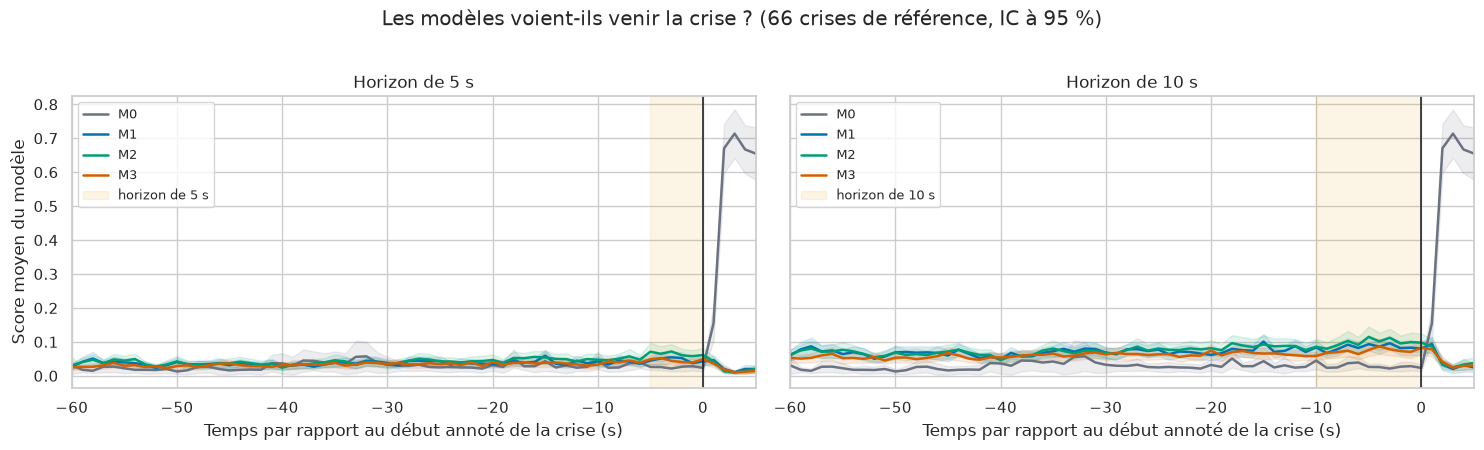

In [79]:
# Probabilité moyenne autour du début des crises de référence, pour chaque modèle et chaque horizon
cb = pd.DataFrame(courbes)
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(15, 4.4), sharey=True)
for ax, H in zip(axes, HORIZONS):
    for (nom, _), couleur in zip(MODELES_ANT.items(), [GRIS, BLEU, VERT, ROUGE]):
        g = cb[(cb["Modèle"] == nom) & (cb["Horizon (s)"] == H)]
        ax.fill_between(g["t (s)"], g["IC95 bas"], g["IC95 haut"], color=couleur, alpha=0.12)
        ax.plot(g["t (s)"], g["Probabilité moyenne"], color=couleur, lw=1.8, label=nom)
    ax.axvspan(-H, 0, color=ORANGE, alpha=0.10, label=f"horizon de {H} s")
    ax.axvline(0, color="#23262B", lw=1.2)
    ax.set(title=f"Horizon de {H} s", xlabel="Temps par rapport au début annoté de la crise (s)", xlim=(-RECUL, 5))
    ax.legend(loc="upper left", fontsize=9)
axes[0].set_ylabel("Score moyen du modèle")
plt.suptitle(f"Les modèles voient-ils venir la crise ? ({len(crises_ref)} crises de référence, IC à 95 %)", y=1.02)
plt.tight_layout()
(ANT_DIR / "figures").mkdir(exist_ok=True)
plt.savefig(ANT_DIR / "figures" / "anticipation_probabilite_avant_crise.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

#### Interprétation

**Un signal faible, mais réel.** Sur les 66 crises de référence, le meilleur modèle (M2, qui regarde l'évolution des caractéristiques sur les 30 s précédentes) en annonce 9, à l'horizon de 5 s comme à celui de 10 s, avec un délai médian de 3 à 4 s. Le hasard, avec les mêmes alarmes, en annoncerait 1,1 à 1,8 en moyenne : la différence est significative (p = 0,001, la plus petite valeur possible avec 1 000 tirages, et elle résiste à une correction pour les huit comparaisons). L'AUC entre fenêtres pré-critiques et inter-critiques va dans le même sens : 0,69 à 5 s et 0,71 à 10 s pour M2, contre 0,58 et 0,57 pour le détecteur M0.

**Mais très loin d'un outil utilisable.** 9 crises annoncées sur 66, c'est 14 % : 57 crises arrivent sans aucune alerte. Et le modèle donne environ 6 fausses annonces par heure. M1 (sans contexte) en annonce 4 à 5 s et 3 à 10 s, M3 seulement 1 et 3 : ramener les caractéristiques à l'échelle de l'enregistrement n'aide pas. Le détecteur existant (M0) n'annonce aucune crise : sa probabilité ne monte pas avant le début annoté, ce qui confirme qu'il fait bien de la détection et pas de l'anticipation.

**Prudence sur l'interprétation.** Le début des crises est annoté à la seconde près. Un délai médian de 3 à 4 s peut refléter un vrai changement du signal avant la crise, mais aussi un début réel légèrement antérieur à l'annotation. Ces données ne permettent pas de trancher. Le seuil d'alarme est fixé à partir des autres enregistrements, sur des scores obtenus par validation croisée, ce qui n'est pas une séparation parfaite. Avec 66 crises, dont un seul patient adulte et un seul patient atypique, c'est un résultat exploratoire : il justifie de poursuivre la question, pas de conclure qu'on sait annoncer une absence.

## Des crises que personne n'a annotées ? (autoencodeur, exploratoire)

**Au-delà de l'énoncé.** Tout le projet apprend à partir des crises annotées par le médecin. Ici, on pose la question inverse : un réseau qui n'a **jamais vu de crise** peut-il signaler ce qui sort de l'ordinaire, et certaines « fausses alarmes » du Random Forest seraient-elles en réalité des décharges que personne n'a annotées ?

Le principe est celui d'un **autoencodeur** : un réseau qui comprime une fenêtre d'EEG en un petit résumé (le goulot), puis la reconstruit. Entraîné uniquement sur de l'EEG normal, il apprend à bien reconstruire ce qui est normal. Une fenêtre qu'il reconstruit mal est donc inhabituelle : l'**erreur de reconstruction** devient un score d'anomalie, sans aucune étiquette de crise.

Démarche :
1. mêmes prétraitements que le projet (médiane retirée, passe-bande 0,5–40 Hz aller-retour), signal ramené à 128 Hz, fenêtres de 2 s à 50 % de recouvrement, normalisation robuste par enregistrement (médiane et écart interquartile de **ses** fenêtres normales) ;
2. fenêtres d'entraînement « normales » : à au moins 30 s de toute crise annotée, à plus de 5 s d'une saturation du journal, sans amplitude extrême. Les fenêtres de crise ne servent jamais ;
3. validation croisée par enregistrement (GroupKFold, 5 plis) : chaque enregistrement est noté par un autoencodeur qui ne l'a jamais vu ;
4. on vérifie d'abord que le score reconnaît les crises **connues**, puis on cherche des événements anormaux hors des crises annotées.

Le code de cette section est dans `etude_autoencodeur.py`, à côté du notebook ; le site (page Découverte) relit les fichiers produits dans `resultats_local/autoencodeur/`.

In [1]:
# ---- Mise en place : chemins, annotations, journaux d'examen, probabilités du Random Forest ----
import os, sys, time, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

RACINE = Path.cwd()
sys.path.insert(0, str(RACINE))
import eeg_pipeline as P, exam_journal as JOURNAL
import etude_electrodes as EL, etude_autoencodeur as AE

DATA = Path(os.environ.get("DM_DATA", RACINE / "data"))                  # lecture seule
SORTIE = Path(os.environ.get("DM_OUT", RACINE / "resultats_local"))
AE_DIR, AE_FIG = SORTIE / "autoencodeur", SORTIE / "autoencodeur" / "figures"
AE_FIG.mkdir(parents=True, exist_ok=True)
AE_CACHE = RACINE / ".cache" / "autoencodeur"
REDUIT = os.environ.get("ETUDES_REDUIT") == "1"                          # mise au point rapide uniquement
import re
fr_txt = lambda s: re.sub(r"(?<=\d)\.(?=\d)", ",", s)                       # virgule décimale dans les phrases
T0_AE = time.perf_counter()

chemins = EL.recordings(DATA)
lignes = {r: int(P._read_timetable(p)[0].numRows) for r, p in chemins.items()}
crises, meta_ae = EL.load_truth(DATA, lignes)
jeu = pd.read_csv(RACINE / "resultats" / "features_windows.csv")
IDS = sorted(set(jeu["Recording"]))
if REDUIT:
    IDS = IDS[:6]
verite = {r: [(float(a), float(b)) for a, b in P.seizure_table(crises, r)[["Début (s)", "Fin (s)"]].values] for r in IDS}
journaux = {}
for r in IDS:
    h = chemins[r].with_name(chemins[r].name.replace("_0000d.mat", "_0000h.mat"))
    journaux[r] = JOURNAL.load_journal(h) if h.exists() else []
# probabilité « crise » du Random Forest sans l'enregistrement (section « Analyses de recherche »)
rf_loro = (pd.read_csv(SORTIE / "cache_recherche" / "predictions_loro.csv")[["Recording", "t_start", "Proba RF"]]
           .rename(columns={"Proba RF": "proba_rf"}))
rf_loro = rf_loro[rf_loro["Recording"].isin(IDS)]

prep = {}
for r in IDS:
    prep[r] = AE.prepare(r, chemins[r], verite[r], journaux[r], AE_CACHE)
resume_prep = pd.DataFrame([{"Enregistrement": r, "Fenêtres": len(prep[r]["normal"]),
                             "Loin des crises": int(prep[r]["far"].sum()), "Sans saturation proche": int((prep[r]["far"] & prep[r]["nosat"]).sum()),
                             "Normales retenues": int(prep[r]["normal"].sum())} for r in IDS])
print(f"{len(IDS)} enregistrements, {resume_prep['Fenêtres'].sum()} fenêtres, dont {resume_prep['Normales retenues'].sum()} normales "
      f"utilisables pour l'entraînement ({time.perf_counter() - T0_AE:.0f} s)")
resume_prep

19 enregistrements, 28994 fenêtres, dont 22374 normales utilisables pour l'entraînement (33 s)


,Enregistrement,Fenêtres,Loin des crises,Sans saturation proche,Normales retenues
0,190304A-E,1574,1506,1506,1493
1,191113A-D,1809,1669,1669,1635
2,210406A-F,1453,1384,1384,1373
3,210427B-C,1245,1166,1154,1002
4,210504B-C,3120,2354,2342,2220
5,210914B-A,1204,590,590,577
6,210928B-B,1343,1168,1156,1143
7,211027B-C,1254,843,843,820
8,211104B-D,1209,864,858,824
9,220106A-A,1220,1061,1061,1037


### Le modèle

Un autoencodeur convolutif 1D, volontairement petit (il tourne sur un processeur ordinaire) :

- **encodeur** : quatre convolutions, dont trois de pas 2, qui ramènent la fenêtre de 19 voies × 256 échantillons à un goulot de 8 × 32 valeurs, soit environ 19 fois moins que l'entrée ;
- **décodeur** : le chemin inverse (convolutions transposées) jusqu'à 19 × 256 ;
- **perte** : erreur quadratique moyenne ; arrêt précoce sur 10 % des fenêtres normales d'entraînement tenues à part.

**Score d'anomalie d'une fenêtre** : l'erreur de reconstruction de chaque voie (moyenne sur les échantillons), puis la **médiane sur les voies**, pour qu'une seule électrode défaillante ne domine pas. L'erreur de chaque voie est conservée.

**Seuil** : pour chaque pli, le 99e centile du score sur les fenêtres normales des enregistrements d'**entraînement**. Il n'est jamais réglé sur l'enregistrement testé.

In [2]:
# ---- Validation croisée par enregistrement : 5 autoencodeurs, chacun sans les enregistrements qu'il note ----
import torch
torch.manual_seed(42)
t0 = time.perf_counter()
def _progres(pli, n, msg):
    if "époque" in msg and not msg.rstrip().endswith(("1", "5", "0")):
        return                                  # une ligne toutes les quelques époques suffit
    print(msg, flush=True)
erreurs_voies, pli_de, seuil_de, seuil_voie_de, journal_entrainement = AE.cross_validate(
    prep, IDS, n_splits=2 if REDUIT else 5, epochs=2 if REDUIT else 30, max_windows=3000 if REDUIT else 16000, seed=42, progress=_progres)
DUREE_ENTRAINEMENT = time.perf_counter() - t0
journal_entrainement.drop(columns="historique").to_csv(AE_DIR / "entrainement.csv", index=False)
print(f"Entraînement et notation de toutes les fenêtres : {DUREE_ENTRAINEMENT:.0f} s")
journal_entrainement.drop(columns="historique").round(4)

pli 1 sur 5, époque 1 : erreur d'entraînement 1.0031, de validation 0.7321


pli 1 sur 5, époque 7 : erreur d'entraînement 0.5025, de validation 0.4950


pli 1 sur 5, époque 9 : erreur d'entraînement 0.4579, de validation 0.4330


pli 1 sur 5, époque 13 : erreur d'entraînement 0.3939, de validation 0.3945


pli 1 sur 5, époque 17 : erreur d'entraînement 0.3574, de validation 0.3625


pli 1 sur 5, époque 21 : erreur d'entraînement 0.3015, de validation 0.3070


... (36 outputs left out)

pli 5 sur 5, époque 26 : erreur d'entraînement 0.2512, de validation 0.3155


pli 5 sur 5, époque 29 : erreur d'entraînement 0.2354, de validation 0.2855


Entraînement et notation de toutes les fenêtres : 178 s


,pli,enregistrements_test,fenetres_entrainement,fenetres_validation,epoques,mse_entrainement,mse_validation,seuil_99,duree_s
0,1,210427B-C 211104B-D 230210B-D 230718A-A,14400,1600,30,0.2652,0.2749,0.9425,36.3
1,2,210406A-F 211027B-C 230105B-H 230519A-E,14400,1600,30,0.2024,0.2085,0.9052,35.8
2,3,191113A-D 210928B-B 230102B-F 230515B-G,14400,1600,30,0.2463,0.2244,0.9226,35.7
3,4,190304A-E 210914B-A 220121B-D 230406B-A,14400,1600,30,0.2397,0.2464,0.9974,35.2
4,5,210504B-C 220106A-A 230224B-B,14400,1600,30,0.2369,0.2787,0.6963,35.0


In [3]:
# ---- Une ligne par fenêtre : score d'anomalie, seuil du pli, classe annotée, probabilité RF ----
fen = AE.window_table(prep, IDS, erreurs_voies, pli_de, seuil_de, jeu, rf_loro)
fen.to_csv(AE_DIR / "scores_fenetres.csv", index=False)
par_voie = pd.concat([pd.DataFrame(erreurs_voies[r], columns=EL.ELECTRODES).assign(Recording=r, Window=np.arange(1, len(erreurs_voies[r]) + 1))
                      for r in IDS], ignore_index=True)
par_voie[["Recording", "Window"] + EL.ELECTRODES].round(5).to_csv(AE_DIR / "scores_par_voie.csv", index=False)
print(f"{len(fen)} fenêtres notées ; fichiers scores_fenetres.csv et scores_par_voie.csv écrits")
fen.groupby("Class")["score"].describe().round(3)

28994 fenêtres notées ; fichiers scores_fenetres.csv et scores_par_voie.csv écrits


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,27820.0,0.268,0.718,0.002,0.090,0.133,0.228,31.124
1,1174.0,2.763,2.480,0.038,0.721,2.074,4.173,11.697


### Le score reconnaît-il les crises connues ?

Avant de chercher des crises inconnues, il faut vérifier que le score monte sur les **82 crises annotées**, alors qu'il ne les a jamais vues. Deux mesures, comparées à la probabilité du Random Forest sur les mêmes fenêtres :

- par fenêtre : aire sous la courbe ROC (AUC) et sous la courbe précision-rappel, avec un intervalle de confiance à 95 % obtenu en rééchantillonnant les enregistrements ;
- par crise : part des crises dont le score maximal dépasse le seuil du pli.

Attention à la comparaison : le Random Forest a appris sur des crises annotées (d'autres enregistrements), l'autoencodeur jamais.

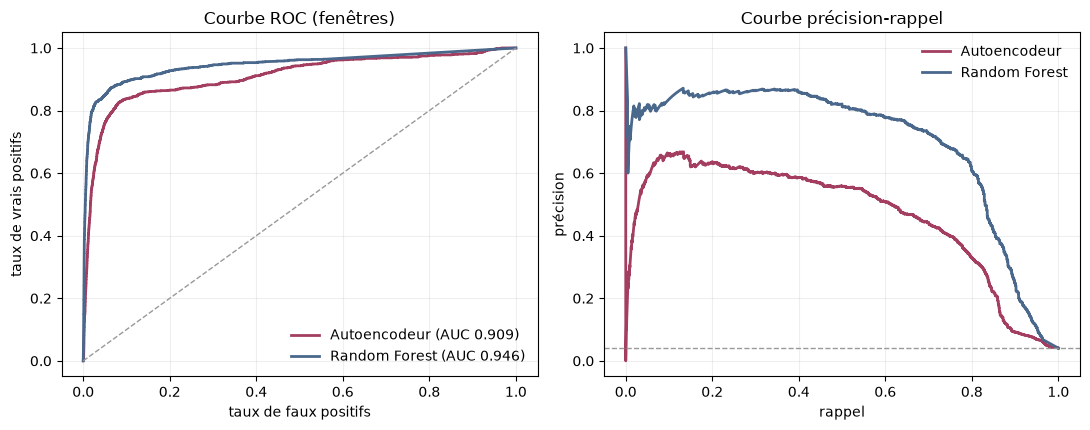

,Score,AUC ROC,IC95 bas,IC95 haut,AUC précision-rappel,Crises vues,Crises annotées
0,Autoencodeur (sans étiquette),0.909,0.847,0.977,0.465,75,82
1,Random Forest (supervisé),0.946,0.905,0.975,0.700,80,82


In [4]:
from sklearn.metrics import roc_curve, precision_recall_curve
VALID, crises_connues = AE.validate(fen, verite, n_boot=200 if REDUIT else 1000)
crises_connues.to_csv(AE_DIR / "crises_connues.csv", index=False)
tab_valid = pd.DataFrame([{"Score": "Autoencodeur (sans étiquette)" if k == "autoencodeur" else "Random Forest (supervisé)",
                           "AUC ROC": VALID[k]["auc"], "IC95 bas": VALID[k]["auc_ic95"][0], "IC95 haut": VALID[k]["auc_ic95"][1],
                           "AUC précision-rappel": VALID[k]["pr_auc"],
                           "Crises vues": VALID["evenements"][k], "Crises annotées": VALID["evenements"]["n"]}
                          for k in ("autoencodeur", "random_forest")])
tab_valid.to_csv(AE_DIR / "validation.csv", index=False)

V = fen.dropna(subset=["Class"])
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
for col, lab, c in (("score", "Autoencodeur", "#A33E61"), ("proba_rf", "Random Forest", "#4A678C")):
    fpr, tpr, _ = roc_curve(V["Class"], V[col]); ax[0].plot(fpr, tpr, color=c, lw=2, label=f"{lab} (AUC {VALID['autoencodeur' if col == 'score' else 'random_forest']['auc']:.3f})")
    pr, rc, _ = precision_recall_curve(V["Class"], V[col]); ax[1].plot(rc, pr, color=c, lw=2, label=lab)
ax[0].plot([0, 1], [0, 1], ls="--", c="#999", lw=1); ax[0].set(xlabel="taux de faux positifs", ylabel="taux de vrais positifs", title="Courbe ROC (fenêtres)")
ax[1].axhline(V["Class"].mean(), ls="--", c="#999", lw=1); ax[1].set(xlabel="rappel", ylabel="précision", title="Courbe précision-rappel")
for a in ax: a.legend(frameon=False); a.grid(alpha=0.2)
plt.tight_layout(); plt.savefig(AE_FIG / "courbes_roc.png", dpi=150); plt.show()
tab_valid.round(3)

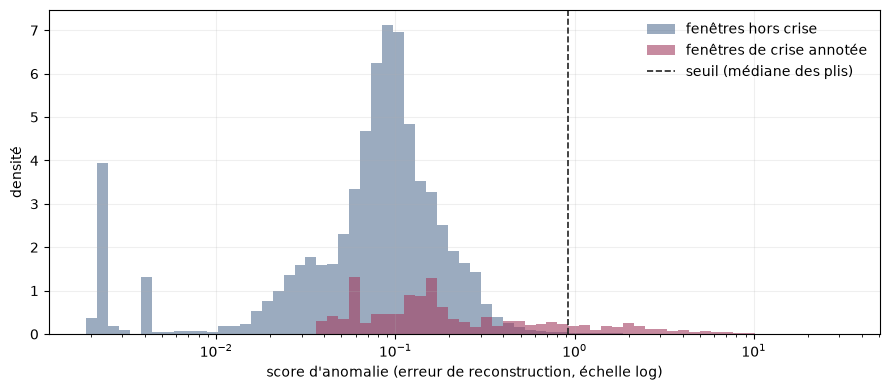

In [5]:
# ---- Répartition du score : fenêtres normales, fenêtres de crise annotée ----
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.logspace(np.log10(max(1e-3, fen["score"].min())), np.log10(fen["score"].max()), 70)
ax.hist(fen.loc[fen["Class"] == 0, "score"], bins=bins, density=True, alpha=0.55, color="#4A678C", label="fenêtres hors crise")
ax.hist(fen.loc[fen["Class"] == 1, "score"], bins=bins, density=True, alpha=0.6, color="#A33E61", label="fenêtres de crise annotée")
ax.axvline(np.median(list(seuil_de.values())), color="#222", ls="--", lw=1.2, label="seuil (médiane des plis)")
ax.set_xscale("log"); ax.set(xlabel="score d'anomalie (erreur de reconstruction, échelle log)", ylabel="densité")
ax.legend(frameon=False); ax.grid(alpha=0.2)
plt.tight_layout(); plt.savefig(AE_FIG / "distribution_scores.png", dpi=150); plt.show()

### À la recherche de décharges non annotées

Hors des crises annotées (avec une marge de 2 s), les fenêtres au-dessus du seuil sont regroupées en **événements candidats** avec les mêmes règles que `detect()` : lissage médian sur 3 fenêtres, fusion des intervalles séparés de moins de 1 s, durée minimale de 2 s.

Un candidat n'est retenu comme **« décharge possible »** que s'il ressemble aussi à une absence :
- fréquence dominante entre 2,5 et 4 Hz (moyenne des voies fronto-centrales) ;
- anomalie étendue : au moins la moitié des voies au-dessus de leur propre seuil ;
- pas de saturation ni de note « artefact » du journal à moins de 5 s.

Sinon : **« artefact probable »** (saturation ou note d'artefact proches, ou anomalie limitée à une ou deux voies) ou **« anomalie autre »**. Les candidats « décharge possible » sont classés par un score combiné : anomalie relative au seuil × part de la puissance entre 2,5 et 4 Hz.

In [6]:
candidats = AE.discover(fen, IDS, verite, erreurs_voies, seuil_voie_de, prep, journaux)
candidats.round(4).to_csv(AE_DIR / "candidats.csv", index=False)
print(f"{len(candidats)} événements candidats hors des crises annotées :")
display(candidats["etiquette"].value_counts().rename("événements").to_frame())
cols = ["rang", "Recording", "debut", "fin", "duree", "score_rel", "freq_dominante", "part_2_5_4_hz", "part_voies", "proba_rf_max", "notes_journal"]
candidats[candidats["etiquette"] == "décharge possible"].sort_values("score_combine", ascending=False)[cols].head(15).round(3)

181 événements candidats hors des crises annotées :


,événements
etiquette,
anomalie autre,97
artefact probable,66
décharge possible,18


,rang,Recording,debut,fin,duree,score_rel,freq_dominante,part_2_5_4_hz,part_voies,proba_rf_max,notes_journal
163,1,211104B-D,50.0,61.0,11.0,11.782,2.812,0.618,1.000,0.958,
164,2,230210B-D,386.0,402.0,16.0,11.387,2.875,0.527,1.000,0.991,
165,3,210504B-C,2836.0,2867.0,31.0,12.371,2.562,0.465,1.000,0.984,
166,4,210504B-C,2248.0,2277.0,29.0,11.377,2.562,0.484,1.000,0.922,
167,5,210504B-C,3000.0,3028.0,28.0,11.491,2.625,0.390,1.000,0.874,
168,6,210504B-C,5.0,10.0,5.0,8.469,2.500,0.408,1.000,0.817,
169,7,211027B-C,834.0,845.0,11.0,3.226,3.062,0.771,1.000,1.000,
170,8,211027B-C,423.0,439.0,16.0,2.841,3.125,0.786,1.000,1.000,
171,9,210427B-C,816.0,839.0,23.0,3.266,2.625,0.475,0.895,0.947,vidéo à préparer | absence | clonies palpébral...
172,10,210504B-C,1174.0,1181.0,7.0,4.012,2.562,0.358,0.895,0.363,


In [7]:
# ---- Les fausses alarmes du Random Forest : l'autoencodeur les signale-t-il aussi ? ----
fa_rf = AE.rf_false_alarms(rf_loro, verite)
recoupement = AE.cross_check(fa_rf, fen, erreurs_voies, seuil_voie_de, prep, journaux, candidats)
recoupement.round(4).to_csv(AE_DIR / "fausses_alarmes_rf.csv", index=False)
print(f"{len(fa_rf)} fausses alarmes du Random Forest ; {int(recoupement['vue_autoencodeur'].sum())} aussi signalées par l'autoencodeur, "
      f"dont {int(recoupement['discharge_possible'].sum())} qui ressemblent à une décharge (2,5–4 Hz, étendue, sans artefact noté).")
recoupement[["Recording", "debut", "fin", "vue_autoencodeur", "etiquette", "freq_dominante", "part_voies", "score_rel", "notes_journal"]].round(3)

25 fausses alarmes du Random Forest ; 22 aussi signalées par l'autoencodeur, dont 15 qui ressemblent à une décharge (2,5–4 Hz, étendue, sans artefact noté).


,Recording,debut,fin,vue_autoencodeur,etiquette,freq_dominante,part_voies,score_rel,notes_journal
0,210427B-C,277.0,290.0,True,décharge possible,2.688,0.842,2.759,absence
1,210427B-C,327.0,348.0,True,décharge possible,2.562,0.737,2.848,
2,210427B-C,418.0,422.0,False,artefact probable,1.812,0.053,0.993,
3,210427B-C,816.0,839.0,True,décharge possible,2.625,0.895,3.266,vidéo à préparer | absence | clonies palpébral...
4,210427B-C,889.0,901.0,True,décharge possible,2.750,0.684,2.447,
5,210504B-C,0.0,9.0,True,décharge possible,2.562,1.000,13.025,
6,210504B-C,1278.0,1284.0,True,anomalie autre,2.188,1.000,8.275,
7,210504B-C,1940.0,1943.0,True,décharge possible,2.562,1.000,7.107,
8,210504B-C,2250.0,2276.0,True,décharge possible,2.562,1.000,11.377,
9,210504B-C,2837.0,2865.0,True,décharge possible,2.562,1.000,12.371,


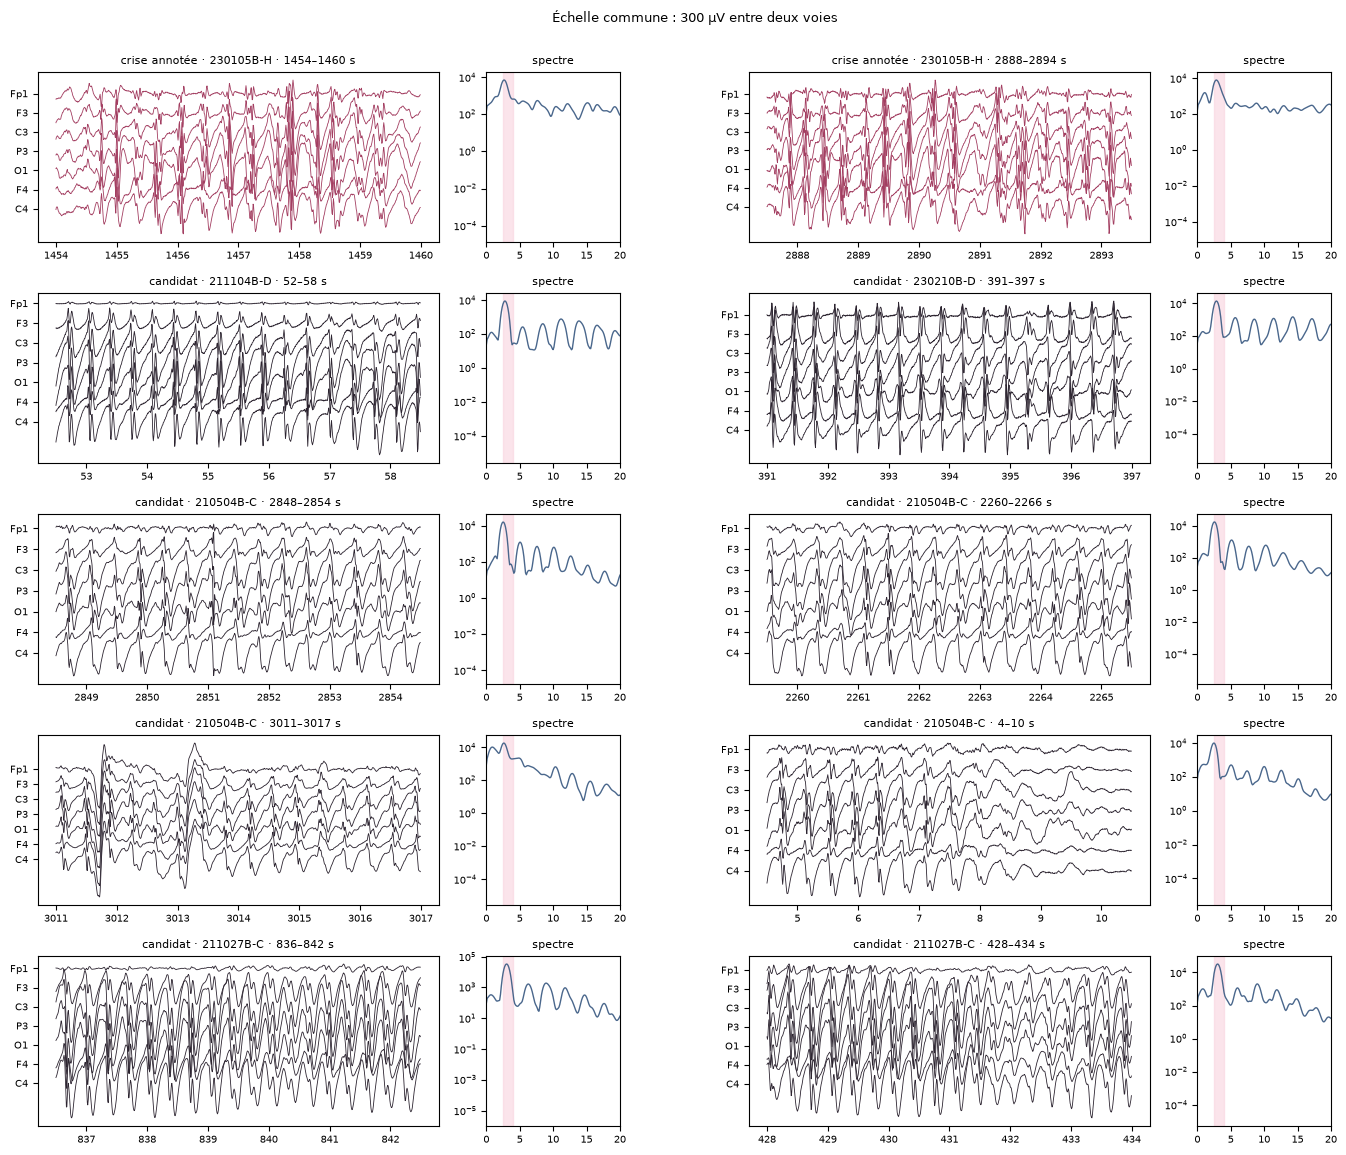

In [8]:
# ---- Galerie : les 8 meilleurs candidats « décharge possible », à côté de 2 crises connues, même échelle ----
from scipy.signal import welch
VOIES_GAL = ["Fp1", "F3", "C3", "P3", "O1", "F4", "C4"]
top = candidats[candidats["etiquette"] == "décharge possible"].sort_values("score_combine", ascending=False).head(8)
connues = crises_connues.sort_values("score_max", ascending=False).head(2)
tuiles = [("connue", r.Recording, (r.debut + r.fin) / 2) for r in connues.itertuples()] + \
         [("candidat", r.Recording, (r.debut + r.fin) / 2) for r in top.itertuples()]
n = len(tuiles)
if n:
    fig = plt.figure(figsize=(14, 2.3 * ((n + 1) // 2)))
    gs = fig.add_gridspec((n + 1) // 2, 6, width_ratios=[3, 1, 0.25, 3, 1, 0.01])
    for i, (kind, r, mid) in enumerate(tuiles):
        row, col = i // 2, (i % 2) * 3
        a0, a1 = max(0, mid - 3), mid + 3
        x = prep[r]["filtered"][int(a0 * AE.FS_AE):int(a1 * AE.FS_AE)]
        t = a0 + np.arange(len(x)) / AE.FS_AE
        ax = fig.add_subplot(gs[row, col])
        for k, e in enumerate(VOIES_GAL):
            ax.plot(t, x[:, EL.ELECTRODES.index(e)] / 300.0 - k, lw=0.6, color="#A33E61" if kind == "connue" else "#2C2430")
        ax.set_yticks(-np.arange(len(VOIES_GAL))); ax.set_yticklabels(VOIES_GAL, fontsize=7); ax.tick_params(labelsize=7)
        ax.set_title(f"{'crise annotée' if kind == 'connue' else 'candidat'} · {r} · {a0:.0f}–{a1:.0f} s", fontsize=8)
        sel = [EL.ELECTRODES.index(e) for e in AE.FRONTO_CENTRAL]
        f, p = welch(x[:, sel], fs=AE.FS_AE, nperseg=256, nfft=1024, axis=0)
        ax2 = fig.add_subplot(gs[row, col + 1]); ax2.semilogy(f, p.mean(1), color="#4A678C", lw=1)
        ax2.axvspan(2.5, 4, color="#F9D3DF", alpha=0.6); ax2.set_xlim(0, 20); ax2.tick_params(labelsize=7); ax2.set_title("spectre", fontsize=8)
    fig.suptitle("Échelle commune : 300 µV entre deux voies", fontsize=9, y=1.0)
    plt.tight_layout(); plt.savefig(AE_FIG / "galerie_candidats.png", dpi=150); plt.show()

In [9]:
# ---- Résumé chiffré, réutilisé par le site (page Découverte) ----
ae_res = {"auc": VALID["autoencodeur"]["auc"], "auc_ic95": VALID["autoencodeur"]["auc_ic95"], "pr_auc": VALID["autoencodeur"]["pr_auc"],
          "auc_rf": VALID["random_forest"]["auc"], "auc_rf_ic95": VALID["random_forest"]["auc_ic95"], "pr_auc_rf": VALID["random_forest"]["pr_auc"],
          "crises": VALID["evenements"], "faible": VALID["faible"], "n_fenetres": VALID["n_fenetres"],
          "candidats": int(len(candidats)), "etiquettes": candidats["etiquette"].value_counts().to_dict(),
          "fausses_alarmes_rf": int(len(recoupement)), "fa_vues": int(recoupement["vue_autoencodeur"].sum()),
          "fa_decharges": int(recoupement["discharge_possible"].sum()), "seuils": {r: float(v) for r, v in seuil_de.items()},
          "plis": {r: int(v) for r, v in pli_de.items()}, "duree_entrainement_s": DUREE_ENTRAINEMENT,
          "duree_totale_s": time.perf_counter() - T0_AE, "reduit": REDUIT, "enregistrements": IDS}
(AE_DIR / "resume.json").write_text(json.dumps(ae_res, ensure_ascii=False, indent=1), encoding="utf-8")
A_, R_ = VALID["autoencodeur"], VALID["random_forest"]; ev_ = VALID["evenements"]
lignes_ = [f"**Crises connues.** Sans avoir jamais vu une crise, le score d'anomalie atteint une AUC de {A_['auc']:.3f} "
           f"(IC95 {A_['auc_ic95'][0]:.3f}–{A_['auc_ic95'][1]:.3f}) sur les fenêtres annotées, contre {R_['auc']:.3f} pour le Random Forest supervisé. "
           f"Par crise, {ev_['autoencodeur']} des {ev_['n']} crises dépassent le seuil (Random Forest : {ev_['random_forest']}). "
           f"L'AUC précision-rappel, plus exigeante quand les crises sont rares, vaut {A_['pr_auc']:.3f} contre {R_['pr_auc']:.3f} : "
           + ("l'autoencodeur repère bien l'inhabituel, mais il est moins précis que le modèle supervisé, car il signale aussi tout ce qui est anormal sans être une crise."
              if A_["pr_auc"] < R_["pr_auc"] else "l'autoencodeur fait aussi bien que le modèle supervisé.")]
if VALID["faible"]:
    lignes_.append("**Score trop proche du hasard** : on ne tire aucune conclusion sur d'éventuelles crises non annotées.")
else:
    et_ = candidats["etiquette"].value_counts()
    lignes_.append(f"**Candidats.** Hors des crises annotées, {len(candidats)} événements dépassent le seuil : "
                   f"{et_.get('décharge possible', 0)} « décharges possibles », {et_.get('artefact probable', 0)} « artefacts probables » "
                   f"et {et_.get('anomalie autre', 0)} « anomalies autres ».")
    lignes_.append(f"**Fausses alarmes du Random Forest.** Sur les {len(recoupement)}, l'autoencodeur en signale aussi {int(recoupement['vue_autoencodeur'].sum())}, "
                   f"et {int(recoupement['discharge_possible'].sum())} ressemblent à une décharge (2,5–4 Hz, étendue, sans artefact noté au journal).")
display(Markdown(fr_txt("\n\n".join(lignes_))))

**Crises connues.** Sans avoir jamais vu une crise, le score d'anomalie atteint une AUC de 0,909 (IC95 0,847–0,977) sur les fenêtres annotées, contre 0,946 pour le Random Forest supervisé. Par crise, 75 des 82 crises dépassent le seuil (Random Forest : 80). L'AUC précision-rappel, plus exigeante quand les crises sont rares, vaut 0,465 contre 0,700 : l'autoencodeur repère bien l'inhabituel, mais il est moins précis que le modèle supervisé, car il signale aussi tout ce qui est anormal sans être une crise.

**Candidats.** Hors des crises annotées, 181 événements dépassent le seuil : 18 « décharges possibles », 66 « artefacts probables » et 97 « anomalies autres ».

**Fausses alarmes du Random Forest.** Sur les 25, l'autoencodeur en signale aussi 22, et 15 ressemblent à une décharge (2,5–4 Hz, étendue, sans artefact noté au journal).

**Limites.** Il n'existe aucune vérité terrain pour ces candidats : ce sont des **pistes à faire relire par un neurologue**, pas des crises démontrées. Une crise non annotée et un artefact sont tous deux « anormaux » pour l'autoencodeur ; les critères de forme (fréquence, étendue, journal) réduisent la confusion sans la supprimer. Le jeu de données est petit (19 enregistrements, un seul adulte), et le seuil du 99e centile laisse, par construction, environ 1 % des fenêtres normales au-dessus. Sur le site, la page **Découverte** permet de relire chaque candidat et d'enregistrer un avis (`resultats_local/autoencodeur/avis_medecin.csv`).

## Et si une électrode lâche ? (robustesse aux pannes de voies)

**Au-delà de l'énoncé.** En pratique, une électrode se décolle, devient bruyante, ou la référence change, surtout chez l'enfant. On mesure ici la robustesse du détecteur **tel qu'il est** : les Random Forest « sans l'enregistrement » du projet, entraînés sur des données intactes, et la panne au moment du test, ce qui est le cas réaliste.

**Astuce de calcul.** Les 17 caractéristiques du projet sont des moyennes sur les voies. On calcule une fois, pour chaque fenêtre, les 17 caractéristiques **de chaque voie** (mise en cache). Retirer une électrode revient alors à moyenner les autres ; corrompre une électrode ne demande que de recalculer sa voie. On vérifie d'abord que la moyenne des voies redonne exactement le résultat du projet.

Scénarios :
- **retrait** : chaque électrode seule (19), k électrodes tirées au hasard (k = 1, 2, 4, 6, 8, 10 ; 10 tirages chacun), une région entière ;
- **panne d'une électrode**, sur tout l'enregistrement : ligne plate, fort bruit blanc, parasite 50 Hz, décalage avec dérive lente, « pops » intermittents, déconnexion (bruit de très forte amplitude), chacune sur chaque électrode ;
- **changement de référence** : moyenne commune et Cz.

Pour chaque scénario : crises détectées sur 82, fausses alarmes par heure, retard moyen, F1 par fenêtre et **stabilité** (part des détections d'origine encore présentes, par recouvrement). Code : `etude_electrodes.py`.

In [10]:
# ---- Caractéristiques par voie (cache .cache/electrodes/, calculé une fois en parallèle) ----
from joblib import Parallel, delayed
T0_EL = time.perf_counter()
EL_DIR, EL_FIG = SORTIE / "electrodes", SORTIE / "electrodes" / "figures"
EL_FIG.mkdir(parents=True, exist_ok=True)
EL_CACHE, MODELES = RACINE / ".cache" / "electrodes", RACINE / ".cache" / "models"
ids_el = sorted(set(jeu["Recording"]))
Parallel(n_jobs=4, max_nbytes=None)(delayed(EL.build_cache)(r, chemins[r], EL_CACHE, crises) for r in ids_el)
etude = EL.Study(DATA, EL_CACHE, MODELES, RACINE / "resultats" / "features_windows.csv")
if REDUIT:
    etude.ids = etude.ids[:6]
print(f"Caractéristiques par voie prêtes pour {len(etude.ids)} enregistrements ({time.perf_counter() - T0_EL:.0f} s)")

Caractéristiques par voie prêtes pour 19 enregistrements (13 s)


In [11]:
# ---- Contrôle : la moyenne des voies, avec les modèles existants, redonne-t-elle le résultat du projet ? ----
intact = etude.evaluate([{"name": "intact"}])[0]
ref_csv = pd.read_csv(RACINE / "resultats" / "detection_par_enregistrement.csv")
ref_csv = ref_csv[ref_csv["Enregistrement"].isin(etude.ids)]
print(f"Intact : {intact['detected']}/{intact['n_true']} crises, {intact['false_alarms']} fausses alarmes ; "
      f"detection_par_enregistrement.csv : {ref_csv['Détectées'].sum()}/{ref_csv['Crises réelles'].sum()} et {ref_csv['Fausses alarmes'].sum()}")
assert (intact["detected"], intact["false_alarms"]) == (ref_csv["Détectées"].sum(), ref_csv["Fausses alarmes"].sum()), "écart avec le projet"

Intact : 80/82 crises, 25 fausses alarmes ; detection_par_enregistrement.csv : 80/82 et 25


In [12]:
# ---- Tous les scénarios (et la variante robuste, voir plus bas) ----
t0 = time.perf_counter()
SCEN = EL.study_scenarios(seed=42, reps=3 if REDUIT else 10, ks=(1, 2, 4, 6, 8, 10))
if REDUIT:
    SCEN = [s for s in SCEN if s["family"] in ("intact", "retrait_une", "retrait_k", "retrait_region", "reference", "robuste_intact") or s.get("electrode") in ("Fp1", "C3", "O2")]
def _p(k, n, m):
    if k % 5 == 0: print(m, flush=True)
res_el = etude.evaluate(SCEN, progress=_p)
DUREE_SCEN = time.perf_counter() - t0
base_ = res_el[0]
tab_el = pd.DataFrame([{**{k: s.get(k) for k in ("name", "family", "electrode", "kind", "k", "rep", "region", "ref")},
                        "robuste": bool(s.get("robust")), "retirees": " ".join(s.get("removed") or []),
                        "crises_detectees": r["detected"], "crises": r["n_true"], "sensibilite": r["sensitivity"],
                        "fausses_alarmes": r["false_alarms"], "fa_par_heure": r["fa_per_hour"], "retard_moyen_s": r["mean_delay"],
                        "f1_fenetres": r["f1"], "stabilite": r["stability"],
                        "delta_sensibilite": r["sensitivity"] - base_["sensitivity"], "delta_fa_par_heure": r["fa_per_hour"] - base_["fa_per_hour"]}
                       for s, r in zip(SCEN, res_el)])
tab_el.round(4).to_csv(EL_DIR / "scenarios.csv", index=False)
print(f"{len(SCEN)} scénarios évalués en {DUREE_SCEN:.0f} s")
tab_el[tab_el["family"].isin(["intact", "retrait_region", "reference"])][["name", "crises_detectees", "crises", "fa_par_heure", "retard_moyen_s", "f1_fenetres", "stabilite"]].round(3)

détection sur 190304A-E


détection sur 210914B-A


détection sur 220121B-D


détection sur 230406B-A


316 scénarios évalués en 101 s


,name,crises_detectees,crises,fa_par_heure,retard_moyen_s,f1_fenetres,stabilite
0,intact,80,82,3.102,0.825,0.705,1.000
80,sans la région frontale,80,82,4.095,0.962,0.691,0.982
81,sans la région centrale,79,82,3.598,0.899,0.705,0.982
82,sans la région temporale,80,82,3.474,0.738,0.710,0.991
83,sans la région pariétale,79,82,4.095,0.886,0.700,0.965
84,sans la région occipitale,80,82,3.102,0.825,0.701,0.974
199,référence moyenne,75,82,2.233,1.227,0.592,0.825
200,référence cz,76,82,2.482,1.461,0.591,0.877


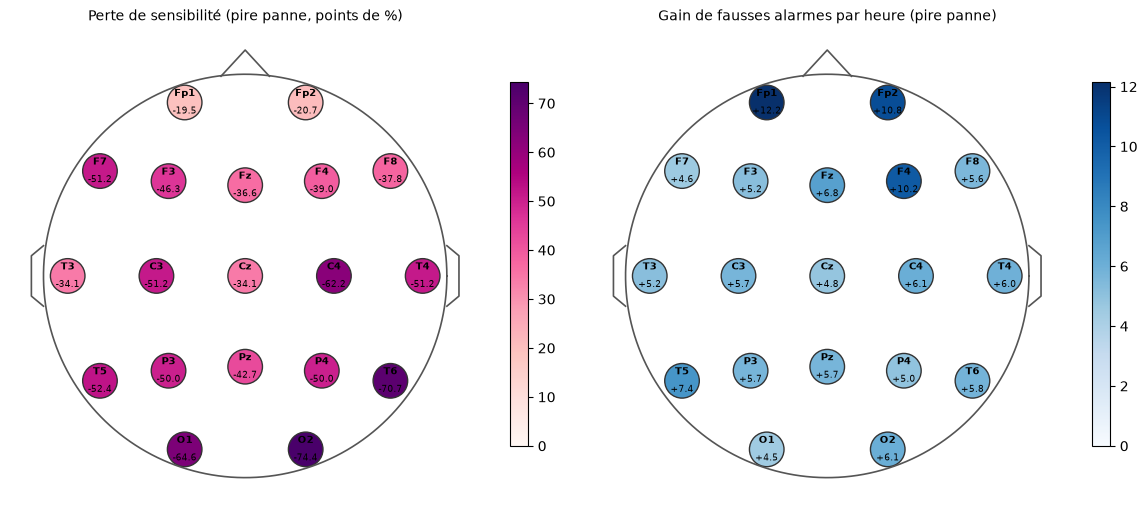

In [13]:
# ---- Carte de la tête : perte de sensibilité et gain de fausses alarmes quand une électrode tombe en panne ----
pannes = tab_el[(tab_el["family"] == "panne")]
pire = pannes.groupby("electrode").agg(perte_sens=("delta_sensibilite", "min"), gain_fa=("delta_fa_par_heure", "max")).reindex(EL.ELECTRODES)
pire.round(4).to_csv(EL_DIR / "carte_electrodes.csv")
def tete(ax, valeurs, titre, cmap, fmt):
    th = np.linspace(0, 2 * np.pi, 200)
    ax.plot(np.cos(th), np.sin(th), c="#555", lw=1.2); ax.plot([-0.12, 0, 0.12], [0.99, 1.12, 0.99], c="#555", lw=1.2)
    for s in (-1, 1): ax.plot(s * np.array([1, 1.06, 1.06, 1]), [0.15, 0.1, -0.1, -0.15], c="#555", lw=1.2)
    v = np.array([valeurs[e] for e in EL.ELECTRODES]); vmax = max(1e-9, np.abs(v).max())
    sc = ax.scatter([EL.POS[e][0] for e in EL.ELECTRODES], [EL.POS[e][1] for e in EL.ELECTRODES], c=np.abs(v), cmap=cmap, vmin=0, vmax=vmax, s=620, edgecolors="#333")
    for e, x in zip(EL.ELECTRODES, v):
        ax.text(EL.POS[e][0], EL.POS[e][1] + 0.02, e, ha="center", va="bottom", fontsize=7.5, fontweight="bold")
        ax.text(EL.POS[e][0], EL.POS[e][1] - 0.02, fmt(x), ha="center", va="top", fontsize=6.5)
    ax.set_aspect("equal"); ax.axis("off"); ax.set_title(titre, fontsize=10); plt.colorbar(sc, ax=ax, shrink=0.7)
fig, ax = plt.subplots(1, 2, figsize=(12, 5.5))
tete(ax[0], (100 * pire["perte_sens"]).to_dict(), "Perte de sensibilité (pire panne, points de %)", "RdPu", lambda x: f"{x:+.1f}")
tete(ax[1], pire["gain_fa"].to_dict(), "Gain de fausses alarmes par heure (pire panne)", "Blues", lambda x: f"{x:+.1f}")
plt.tight_layout(); plt.savefig(EL_FIG / "carte_tete.png", dpi=150); plt.show()

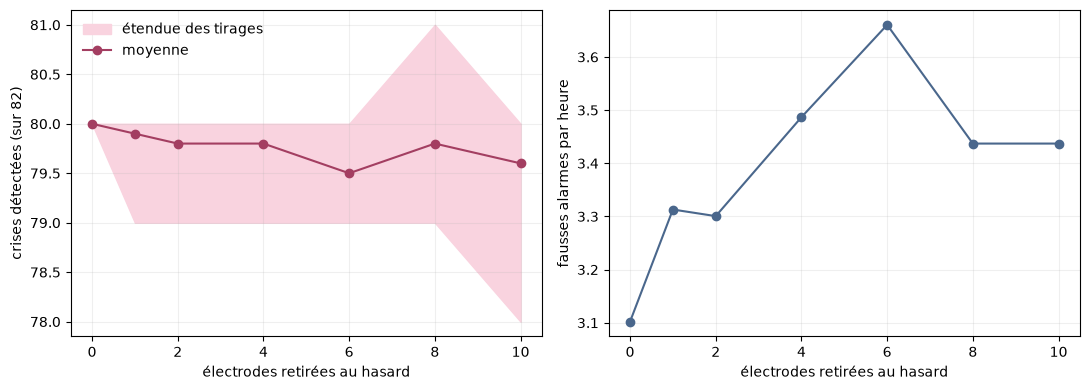

,moy,mini,maxi,fa,stab
k,,,,,
0,80.0,80.0,80.0,3.10,1.00
1,79.9,79.0,80.0,3.31,1.00
2,79.8,79.0,80.0,3.30,0.99
4,79.8,79.0,80.0,3.49,0.99
6,79.5,79.0,80.0,3.66,0.98
8,79.8,79.0,81.0,3.44,0.97
10,79.6,78.0,80.0,3.44,0.97


In [14]:
# ---- Crises détectées selon le nombre d'électrodes retirées au hasard (moyenne et étendue des tirages) ----
rk = tab_el[tab_el["family"] == "retrait_k"].groupby("k").agg(moy=("crises_detectees", "mean"), mini=("crises_detectees", "min"), maxi=("crises_detectees", "max"),
                                                            fa=("fa_par_heure", "mean"), stab=("stabilite", "mean"))
rk.loc[0] = [base_["detected"], base_["detected"], base_["detected"], base_["fa_per_hour"], 1.0]; rk = rk.sort_index(); rk.index = rk.index.astype(int)
rk.round(3).to_csv(EL_DIR / "retrait_k.csv")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].fill_between(rk.index, rk["mini"], rk["maxi"], color="#F9D3DF", label="étendue des tirages"); ax[0].plot(rk.index, rk["moy"], "o-", color="#A33E61", label="moyenne")
ax[0].set(xlabel="électrodes retirées au hasard", ylabel=f"crises détectées (sur {base_['n_true']})"); ax[0].legend(frameon=False)
ax[1].plot(rk.index, rk["fa"], "o-", color="#4A678C"); ax[1].set(xlabel="électrodes retirées au hasard", ylabel="fausses alarmes par heure")
for a in ax: a.grid(alpha=0.2)
plt.tight_layout(); plt.savefig(EL_FIG / "retrait_electrodes.png", dpi=150); plt.show()
rk.round(2)

In [15]:
# ---- Quel type de panne est le plus dangereux ? (moyenne et pire cas sur les 19 électrodes) ----
par_type = pannes.groupby("kind").agg(crises_moy=("crises_detectees", "mean"), crises_min=("crises_detectees", "min"),
                                      fa_h_moy=("fa_par_heure", "mean"), fa_h_max=("fa_par_heure", "max"), stabilite=("stabilite", "mean"))
par_type.index = [EL.CORRUPTIONS[k] for k in par_type.index]
par_type.round(3).to_csv(EL_DIR / "pannes_par_type.csv")
par_type.round(2)

,crises_moy,crises_min,fa_h_moy,fa_h_max,stabilite
fort bruit blanc,80.05,80,8.40,10.55,0.99
déconnexion simulée (bruit de très forte amplitude),41.63,19,7.25,15.26,0.47
décalage continu et lente dérive,80.00,80,3.10,3.10,1.00
ligne plate (électrode muette),79.42,79,3.37,3.60,0.97
« pops » intermittents (sauts avec décroissance),80.00,80,3.24,3.60,1.00
parasite secteur à 50 Hz,80.00,80,3.10,3.10,1.00


### Une correction possible : la médiane des voies

Une seule voie folle peut tirer la **moyenne** des 19 voies très loin ; la **médiane** y est presque insensible. Variante proposée, sans toucher au pipeline officiel : agréger les caractéristiques par la médiane des voies, et ré-entraîner le même Random Forest « sans l'enregistrement » (mêmes réglages, 19 modèles mis en cache). On rejoue ensuite exactement les mêmes pannes. C'est une **amélioration proposée**, pas le résultat principal du projet.

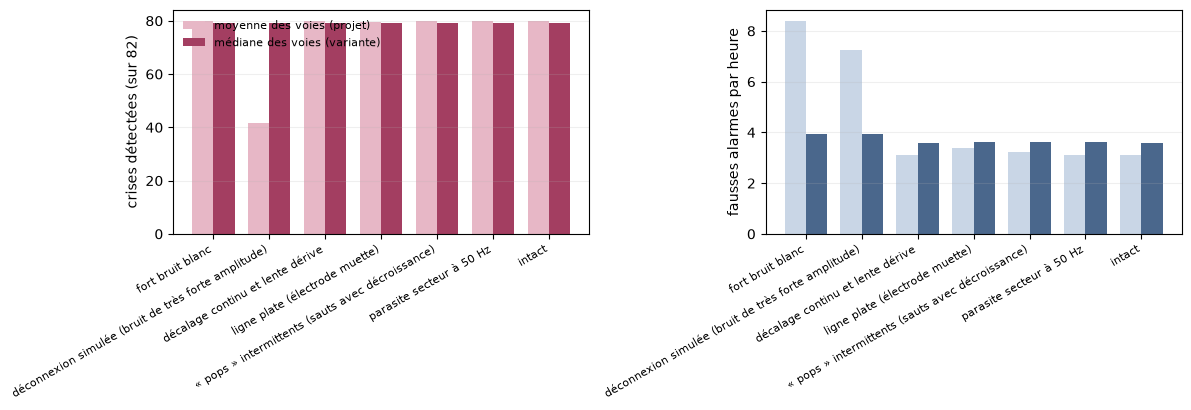

,crises (moyenne),crises (médiane),FA/h (moyenne),FA/h (médiane),stabilité (moyenne),stabilité (médiane)
fort bruit blanc,80.05,79.0,8.40,3.92,0.99,0.97
déconnexion simulée (bruit de très forte amplitude),41.63,79.0,7.25,3.95,0.47,0.97
décalage continu et lente dérive,80.00,79.0,3.10,3.60,1.00,0.97
ligne plate (électrode muette),79.42,79.0,3.37,3.62,0.97,0.97
« pops » intermittents (sauts avec décroissance),80.00,79.0,3.24,3.61,1.00,0.97
parasite secteur à 50 Hz,80.00,79.0,3.10,3.62,1.00,0.97
intact,80.00,79.0,3.10,3.60,1.00,0.97


In [16]:
rob = tab_el[tab_el["robuste"]]
avant = pannes.set_index(["kind", "electrode"]); apres = rob[rob["family"] == "robuste_panne"].set_index(["kind", "electrode"])
cmp_rob = pd.DataFrame({"crises (moyenne)": avant.groupby("kind")["crises_detectees"].mean(), "crises (médiane)": apres.groupby("kind")["crises_detectees"].mean(),
                        "FA/h (moyenne)": avant.groupby("kind")["fa_par_heure"].mean(), "FA/h (médiane)": apres.groupby("kind")["fa_par_heure"].mean(),
                        "stabilité (moyenne)": avant.groupby("kind")["stabilite"].mean(), "stabilité (médiane)": apres.groupby("kind")["stabilite"].mean()})
intact_rob = rob[rob["family"] == "robuste_intact"].iloc[0]
cmp_rob.loc["intact"] = [base_["detected"], intact_rob["crises_detectees"], base_["fa_per_hour"], intact_rob["fa_par_heure"], 1.0, intact_rob["stabilite"]]
cmp_rob.index = [EL.CORRUPTIONS.get(k, k) for k in cmp_rob.index]
cmp_rob.round(3).to_csv(EL_DIR / "variante_robuste.csv")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2)); x = np.arange(len(cmp_rob)); w = 0.38
ax[0].bar(x - w / 2, cmp_rob["crises (moyenne)"], w, color="#E7B7C6", label="moyenne des voies (projet)"); ax[0].bar(x + w / 2, cmp_rob["crises (médiane)"], w, color="#A33E61", label="médiane des voies (variante)")
ax[1].bar(x - w / 2, cmp_rob["FA/h (moyenne)"], w, color="#C9D6E6"); ax[1].bar(x + w / 2, cmp_rob["FA/h (médiane)"], w, color="#4A678C")
ax[0].set_ylabel(f"crises détectées (sur {base_['n_true']})"); ax[1].set_ylabel("fausses alarmes par heure")
for a in ax: a.set_xticks(x); a.set_xticklabels(cmp_rob.index, rotation=30, ha="right", fontsize=8); a.grid(alpha=0.2, axis="y")
ax[0].legend(frameon=False, fontsize=8); plt.tight_layout(); plt.savefig(EL_FIG / "variante_robuste.png", dpi=150); plt.show()
cmp_rob.round(2)

In [17]:
# ---- Lecture des résultats, à partir des chiffres calculés ----
une = tab_el[tab_el["family"] == "retrait_une"].set_index("electrode")
crit_ret = une["crises_detectees"].idxmin()
pire_panne = pannes.sort_values(["crises_detectees", "fa_par_heure"], ascending=[True, False]).iloc[0]
type_pire = par_type["crises_moy"].idxmin(); type_fa = par_type["fa_h_moy"].idxmax()
k_ok = [k for k in rk.index if rk.loc[k, "mini"] >= base_["detected"] - 2]
ref_ = tab_el[tab_el["family"] == "reference"].set_index("ref")
gain = (cmp_rob["crises (médiane)"] - cmp_rob["crises (moyenne)"]).drop("intact")
gain_fa = (cmp_rob["FA/h (moyenne)"] - cmp_rob["FA/h (médiane)"]).drop("intact")
el_res = {"intact": {"detected": base_["detected"], "n_true": base_["n_true"], "false_alarms": base_["false_alarms"], "fa_per_hour": base_["fa_per_hour"]},
          "electrode_retrait_critique": crit_ret, "retrait_critique_crises": int(une.loc[crit_ret, "crises_detectees"]),
          "pire_panne": {"type": pire_panne["kind"], "electrode": pire_panne["electrode"], "crises": int(pire_panne["crises_detectees"]), "fa_h": float(pire_panne["fa_par_heure"])},
          "type_le_plus_dangereux_crises": type_pire, "type_le_plus_dangereux_fa": type_fa, "k_sans_perte_notable": int(max(k_ok)),
          "robuste_intact": {"detected": int(intact_rob["crises_detectees"]), "false_alarms": int(intact_rob["fausses_alarmes"]), "fa_per_hour": float(intact_rob["fa_par_heure"])},
          "duree_scenarios_s": DUREE_SCEN, "n_scenarios": len(SCEN), "reduit": REDUIT}
(EL_DIR / "resume.json").write_text(json.dumps(el_res, ensure_ascii=False, indent=1, default=float), encoding="utf-8")
perte_retrait = base_["detected"] - int(une.loc[crit_ret, "crises_detectees"])
perte_panne = base_["detected"] - int(pire_panne["crises_detectees"])
phr = []
phr.append(f"**Retirer une électrode** {'coûte peu' if perte_retrait <= 2 else 'peut coûter cher'} : au pire ({crit_ret}), "
           f"{int(une.loc[crit_ret, 'crises_detectees'])} crises détectées au lieu de {base_['detected']}. En retirant des électrodes au hasard, "
           f"le pire tirage reste à moins de 2 crises du résultat intact jusqu'à {int(max(k_ok))} électrodes retirées "
           f"({rk.loc[max(k_ok), 'moy']:.1f} crises en moyenne)" + (" : la moyenne sur les voies protège bien d'une absence de signal." if max(k_ok) >= 4 else "."))
phr.append(f"**Une électrode corrompue** {'est bien plus dangereuse qu’une électrode absente' if perte_panne > perte_retrait + 2 else 'pèse autant qu’une électrode absente'}. "
           f"La pire panne observée est « {EL.CORRUPTIONS[pire_panne['kind']]} » sur {pire_panne['electrode']} : {int(pire_panne['crises_detectees'])} crises détectées "
           f"et {pire_panne['fa_par_heure']:.2f} fausses alarmes par heure (intact : {base_['detected']} et {base_['fa_per_hour']:.2f}). "
           f"En moyenne sur les électrodes, le type qui fait perdre le plus de crises est « {type_pire} », celui qui crée le plus de fausses alarmes « {type_fa} ».")
phr.append(f"**Référence.** Moyenne commune : {int(ref_.loc['moyenne', 'crises_detectees'])} crises et {ref_.loc['moyenne', 'fa_par_heure']:.2f} fausses alarmes par heure ; "
           f"référence Cz : {int(ref_.loc['cz', 'crises_detectees'])} et {ref_.loc['cz', 'fa_par_heure']:.2f} (référence d'origine : {base_['detected']} et {base_['fa_per_hour']:.2f}).")
aide = gain.mean() > 0.5 or gain_fa.mean() > 0.5
phr.append(f"**Variante robuste (médiane des voies).** Sans panne, elle détecte {int(intact_rob['crises_detectees'])} crises avec {intact_rob['fa_par_heure']:.2f} fausses alarmes par heure "
           f"(projet : {base_['detected']} et {base_['fa_per_hour']:.2f}). Face aux pannes, elle change en moyenne de {gain.mean():+.1f} le nombre de crises détectées par type de panne "
           f"(de {gain.min():+.1f} à {gain.max():+.1f}) et de {-gain_fa.mean():+.2f} les fausses alarmes par heure. "
           + ("Elle corrige donc une bonne part de la fragilité aux voies corrompues." if aide else "Le gain reste modeste."))
display(Markdown(fr_txt("\n\n".join(phr))))

**Retirer une électrode** coûte peu : au pire (Pz), 79 crises détectées au lieu de 80. En retirant des électrodes au hasard, le pire tirage reste à moins de 2 crises du résultat intact jusqu'à 10 électrodes retirées (79,6 crises en moyenne) : la moyenne sur les voies protège bien d'une absence de signal.

**Une électrode corrompue** est bien plus dangereuse qu’une électrode absente. La pire panne observée est « déconnexion simulée (bruit de très forte amplitude) » sur O2 : 19 crises détectées et 3,23 fausses alarmes par heure (intact : 80 et 3,10). En moyenne sur les électrodes, le type qui fait perdre le plus de crises est « déconnexion simulée (bruit de très forte amplitude) », celui qui crée le plus de fausses alarmes « fort bruit blanc ».

**Référence.** Moyenne commune : 75 crises et 2,23 fausses alarmes par heure ; référence Cz : 76 et 2,48 (référence d'origine : 80 et 3,10).

**Variante robuste (médiane des voies).** Sans panne, elle détecte 79 crises avec 3,60 fausses alarmes par heure (projet : 80 et 3,10). Face aux pannes, elle change en moyenne de +5,5 le nombre de crises détectées par type de panne (de -1,1 à +37,4) et de -1,02 les fausses alarmes par heure. Elle corrige donc une bonne part de la fragilité aux voies corrompues.

**Limites.** Les pannes sont **simulées**, avec des amplitudes choisies à la main : de vraies pannes peuvent être plus progressives ou se combiner. Une panne est appliquée au signal de la voie dans sa référence d'origine ; avec une autre référence, elle se propagerait aussi aux autres voies, ce que l'étude ne simule pas. Le montage disponible ne contient ni oreilles ni mastoïdes : seules la moyenne commune et Cz sont testées comme références. Enfin, la variante robuste est évaluée avec la même validation (un enregistrement laissé de côté), mais sur 19 enregistrements seulement.